In [1]:
# ============================================================
# Step 1. Inspect comfile_stroke safely
# ============================================================

import sys
import numpy as np
import pandas as pd
import importlib.metadata

from raman_data import raman_data

# ------------------------------------------------------------
# 0) Environment / package version
# ------------------------------------------------------------
print("=" * 70)
print("ENVIRONMENT")
print("=" * 70)

print("Python version     :", sys.version.split()[0])

try:
    print("raman-data version :", importlib.metadata.version("raman-data"))
except Exception as e:
    print("Could not detect raman-data version:", e)


# ------------------------------------------------------------
# 1) Load dataset
# ------------------------------------------------------------
dataset = raman_data("comfile_stroke")

print("\n" + "=" * 70)
print("DATASET OBJECT")
print("=" * 70)

print("Object type:")
print(type(dataset))


# ------------------------------------------------------------
# 2) Show every public attribute
# ------------------------------------------------------------
print("\n" + "=" * 70)
print("AVAILABLE PUBLIC ATTRIBUTES")
print("=" * 70)

public_attrs = [
    attr for attr in dir(dataset)
    if not attr.startswith("_")
]

for attr in public_attrs:
    print(attr)


# ------------------------------------------------------------
# 3) Basic information safely
# ------------------------------------------------------------
print("\n" + "=" * 70)
print("BASIC DATASET INFORMATION")
print("=" * 70)

safe_attributes = [
    "name",
    "task_type",
    "application_type",
    "n_spectra",
    "n_frequencies",
    "n_classes",
    "target_names",
    "min_shift",
    "max_shift",
    "metadata",
]

for attr in safe_attributes:
    if hasattr(dataset, attr):
        try:
            value = getattr(dataset, attr)
            print(f"{attr:20s}: {value}")
        except Exception as e:
            print(f"{attr:20s}: ERROR -> {e}")
    else:
        print(f"{attr:20s}: [NOT AVAILABLE]")


# ------------------------------------------------------------
# 4) Main arrays
# ------------------------------------------------------------
print("\n" + "=" * 70)
print("MAIN ARRAYS")
print("=" * 70)

X = getattr(dataset, "spectra", None)
y = getattr(dataset, "targets", None)
wavenumbers = getattr(dataset, "raman_shifts", None)

if X is not None:
    X = np.asarray(X)
    print("X shape          :", X.shape)
    print("X dtype          :", X.dtype)

else:
    print("spectra          : [NOT AVAILABLE]")


if y is not None:
    y = np.asarray(y)
    print("y shape          :", y.shape)
    print("y dtype          :", y.dtype)

    unique, counts = np.unique(y, return_counts=True)

    print("\nTarget distribution:")
    for label, count in zip(unique, counts):
        print(f"  {label}: {count}")

else:
    print("targets          : [NOT AVAILABLE]")


if wavenumbers is not None:
    wavenumbers = np.asarray(wavenumbers)
    print("\nWavenumber shape :", wavenumbers.shape)

    try:
        print(
            "Wavenumber range :",
            float(np.nanmin(wavenumbers)),
            "-",
            float(np.nanmax(wavenumbers)),
            "cm^-1"
        )
    except Exception:
        pass

else:
    print("raman_shifts     : [NOT AVAILABLE]")


# ------------------------------------------------------------
# 5) DataFrame check
# ------------------------------------------------------------
print("\n" + "=" * 70)
print("DATAFRAME CHECK")
print("=" * 70)

if hasattr(dataset, "to_dataframe"):

    try:
        df = dataset.to_dataframe()

        print("DataFrame shape :", df.shape)

        print("\nFirst 10 columns:")
        print(df.columns[:10].tolist())

        print("\nLast 10 columns:")
        print(df.columns[-10:].tolist())

        print("\nFirst 5 rows:")
        display(df.head())

        print("\nDataFrame dtypes summary:")
        print(df.dtypes.value_counts())

    except Exception as e:
        print("to_dataframe() failed:")
        print(e)

else:
    print("to_dataframe() is not available.")


# ------------------------------------------------------------
# 6) Internal fields
# ------------------------------------------------------------
print("\n" + "=" * 70)
print("INTERNAL OBJECT FIELDS")
print("=" * 70)

if hasattr(dataset, "__dict__"):

    internal_dict = dataset.__dict__

    if len(internal_dict) == 0:
        print("__dict__ exists but is empty.")

    else:

        for key, value in internal_dict.items():

            print("\nFIELD:", key)

            if isinstance(value, np.ndarray):

                print("  type :", type(value))
                print("  shape:", value.shape)
                print("  dtype:", value.dtype)

                if value.ndim == 1:
                    print("  first values:", value[:10])

            elif isinstance(value, pd.DataFrame):

                print("  type :", type(value))
                print("  shape:", value.shape)
                print("  columns:", value.columns.tolist()[:20])

            elif isinstance(value, pd.Series):

                print("  type :", type(value))
                print("  shape:", value.shape)
                print("  first values:")
                print(value.head())

            else:

                text = repr(value)

                if len(text) > 500:
                    text = text[:500] + "..."

                print("  type :", type(value))
                print("  value:", text)

else:
    print("This object does not expose __dict__.")


# ------------------------------------------------------------
# 7) Search specifically for possible grouping information
# ------------------------------------------------------------
print("\n" + "=" * 70)
print("SEARCH FOR POSSIBLE GROUP / SAMPLE INFORMATION")
print("=" * 70)

keywords = [
    "group",
    "sample",
    "patient",
    "subject",
    "file",
    "source",
    "id",
    "replicate",
    "origin"
]

found = []

for attr in dir(dataset):

    attr_lower = attr.lower()

    if any(keyword in attr_lower for keyword in keywords):
        found.append(attr)


if found:
    print("Potentially relevant attributes:")
    
    for attr in sorted(found):
        print(" ", attr)

else:
    print("No obvious group/sample-related attributes found.")


print("\n" + "=" * 70)
print("STEP 1 COMPLETE")
print("=" * 70)

print(
    "Next goal: determine whether each of the ~4,020 spectra can be mapped "
    "back to one of the 20 original source files."
)

2026-11-02 17:09:47,612 INFO raman_data:raman_data:67: Loading dataset: comfile_stroke (cache_dir=None)


ENVIRONMENT
Python version     : 3.11.15
raman-data version : 1.4.0

DATASET OBJECT
Object type:
<class 'raman_data.types.RamanDataset'>

AVAILABLE PUBLIC ATTRIBUTES
application_type
class_names
group_ids
info
max_shift
min_shift
n_classes
n_frequencies
n_raman_shifts
n_spectra
name
raman_shifts
spectra
target_names
target_range
targets
task_type
to_dataframe

BASIC DATASET INFORMATION
name                : Stroke SERS Serum
task_type           : Classification
application_type    : Medical
n_spectra           : 4020
n_frequencies       : 724
n_classes           : 2
target_names        : ['Stroke', 'Control']
min_shift           : 200.16400146484375
max_shift           : 1999.9200439453125
metadata            : [NOT AVAILABLE]

MAIN ARRAYS
X shape          : (4020, 724)
X dtype          : float32
y shape          : (4020,)
y dtype          : int32

Target distribution:
  0: 2010
  1: 2010

Wavenumber shape : (724,)
Wavenumber range : 200.16400146484375 - 1999.9200439453125 cm^-1

DATAF

,200.164001,202.985001,205.804001,208.621994,211.438995,214.255005,217.070007,219.884995,222.697998,225.509995,...,1984.550049,1986.75,1988.949951,1991.150024,1993.339966,1995.540039,1997.72998,1999.920044,_group_id,target
spectrum_id,,,,,,,,,,,,,,,,,,,,,
0,31.322001,0.123718,29.669100,57.595600,39.896999,23.521200,54.733299,47.986401,62.599300,115.864998,...,4.229800,28.213200,2.693620,30.783001,7.94577,17.742001,8.021120,-9.241150,0,0
1,7.470520,-11.351400,17.559299,54.055302,40.727901,77.339996,40.706200,60.700199,73.675003,42.861801,...,34.916801,20.111601,15.630400,-3.924770,12.18310,4.270680,8.112180,-0.078201,0,0
2,0.170044,11.107900,0.669434,11.286100,-7.894870,9.661190,33.004002,25.070601,40.722500,32.040501,...,12.289500,10.580000,14.660400,2.117900,4.30698,1.816830,0.611908,-5.247420,0,0
3,0.451050,26.798800,60.432301,32.657101,79.030998,77.893501,97.952698,62.680500,83.822899,84.936203,...,20.188900,3.950120,4.014240,15.861100,2.17383,-16.102600,5.637070,-11.414200,0,0
4,3.207820,-4.811220,1.166750,18.987200,28.820999,11.129100,47.546200,21.836300,54.525700,82.196999,...,37.069099,23.558399,0.917633,25.895500,-1.55411,2.134520,-6.269490,7.404910,0,0



DataFrame dtypes summary:
float32    724
int32        2
Name: count, dtype: int64

INTERNAL OBJECT FIELDS

FIELD: spectra
  type : <class 'numpy.ndarray'>
  shape: (4020, 724)
  dtype: float32

FIELD: targets
  type : <class 'numpy.ndarray'>
  shape: (4020,)
  dtype: int32
  first values: [0 0 0 0 0 0 0 0 0 0]

FIELD: raman_shifts
  type : <class 'numpy.ndarray'>
  shape: (724,)
  dtype: float32
  first values: [200.164 202.985 205.804 208.622 211.439 214.255 217.07  219.885 222.698
 225.51 ]

FIELD: info
  type : <class 'raman_data.types.DatasetInfo'>
  value: DatasetInfo(id='comfile_stroke', name='Stroke SERS Serum', loader=<function FigshareLoader.<lambda> at 0x00000199CC02C5E0>, metadata={'full_name': 'ComFilE: SERS serum spectra for stroke classification', 'source': 'https://figshare.com/articles/dataset/ComFilE_/28107431', 'doi': '10.6084/m9.figshare.28107431', 'paper': 'https://www.nature.com/articles/s42256-025-01027-5', 'bibtex': '@article{Xue_2025, title={Deep spectral compo

In [2]:
# ============================================================
# Step 2. Audit group structure and run the first leakage test
#
# Goal:
#   1) Confirm that _group_id represents independent samples
#   2) Compare conventional spectrum-level random CV
#      with true sample/group-aware CV
#
# IMPORTANT:
#   All preprocessing is fitted ONLY on training data
#   using a scikit-learn Pipeline.
# ============================================================

import numpy as np
import pandas as pd

from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC

from sklearn.model_selection import (
    StratifiedKFold,
    StratifiedGroupKFold
)

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score
)

# ------------------------------------------------------------
# 1. Convert dataset to DataFrame
# ------------------------------------------------------------

df = dataset.to_dataframe().copy()

print("=" * 75)
print("STEP 2A. DATA STRUCTURE")
print("=" * 75)

print("DataFrame shape:", df.shape)

print("\nLast columns:")
print(df.columns[-5:].tolist())


# ------------------------------------------------------------
# 2. Check required columns
# ------------------------------------------------------------

required_columns = ["_group_id", "target"]

missing_columns = [
    col for col in required_columns
    if col not in df.columns
]

if missing_columns:
    raise ValueError(
        f"Required columns are missing: {missing_columns}"
    )


# ------------------------------------------------------------
# 3. Separate spectra, target, and group
# ------------------------------------------------------------

spectral_columns = [
    col for col in df.columns
    if col not in ["_group_id", "target"]
]

X = df[spectral_columns].to_numpy(dtype=float)

y_original = df["target"].to_numpy()

groups = df["_group_id"].astype(str).to_numpy()


print("\nSpectral matrix X :", X.shape)
print("Target y          :", y_original.shape)
print("Group IDs         :", groups.shape)


# ------------------------------------------------------------
# 4. Encode target labels
# ------------------------------------------------------------

label_encoder = LabelEncoder()

y = label_encoder.fit_transform(y_original)

print("\nClass mapping:")

for encoded, original in enumerate(label_encoder.classes_):
    print(f"  {encoded} -> {original}")


# ------------------------------------------------------------
# 5. Basic group information
# ------------------------------------------------------------

n_spectra = len(df)
n_groups = pd.Series(groups).nunique()
n_classes = len(np.unique(y))

print("\n" + "=" * 75)
print("STEP 2B. GROUP AUDIT")
print("=" * 75)

print("Total spectra       :", n_spectra)
print("Unique groups       :", n_groups)
print("Number of classes   :", n_classes)


# ------------------------------------------------------------
# 6. Number of spectra in each group
# ------------------------------------------------------------

group_size_table = (
    df.groupby("_group_id")
    .size()
    .reset_index(name="n_spectra")
)

print("\nSpectra per group:")
display(group_size_table)


print("\nGroup-size summary:")
print(group_size_table["n_spectra"].describe())


# ------------------------------------------------------------
# 7. Check whether each group belongs to only one class
# ------------------------------------------------------------

group_target_counts = (
    df.groupby("_group_id")["target"]
    .nunique()
)

impure_groups = group_target_counts[
    group_target_counts > 1
]

print("\n" + "-" * 75)
print("GROUP LABEL PURITY")
print("-" * 75)

if len(impure_groups) == 0:
    print("PASS: Every group contains only one target class.")

else:
    print("WARNING:")
    print("Some groups contain more than one target label.")

    print(impure_groups)

    raise ValueError(
        "Group structure must be investigated before CV."
    )


# ------------------------------------------------------------
# 8. Group-level class distribution
# ------------------------------------------------------------

group_class_table = (
    df.groupby("_group_id")
    .agg(
        target=("target", "first"),
        n_spectra=("target", "size")
    )
    .reset_index()
)

print("\nGroup-level information:")
display(group_class_table)


print("\nNumber of independent groups per class:")

groups_per_class = (
    group_class_table["target"]
    .value_counts()
)

print(groups_per_class)


# ------------------------------------------------------------
# 9. Define one fixed ML model
#
# We deliberately start with ONE model.
# The purpose is NOT to find the best classifier yet.
#
# The purpose is to isolate the effect of CV strategy.
# ------------------------------------------------------------

def make_model():

    model = Pipeline(
        steps=[
            (
                "scaler",
                StandardScaler()
            ),
            (
                "svm",
                SVC(
                    kernel="rbf",
                    C=1.0,
                    gamma="scale"
                )
            )
        ]
    )

    return model


# ------------------------------------------------------------
# 10. CV evaluation function
# ------------------------------------------------------------

def run_cv(
    X,
    y,
    groups,
    cv,
    cv_name,
    use_groups=False
):

    oof_pred = np.full(
        shape=len(y),
        fill_value=-1,
        dtype=int
    )

    fold_results = []

    if use_groups:

        split_iterator = cv.split(
            X,
            y,
            groups=groups
        )

    else:

        split_iterator = cv.split(
            X,
            y
        )


    for fold, (train_idx, test_idx) in enumerate(
        split_iterator,
        start=1
    ):

        X_train = X[train_idx]
        X_test = X[test_idx]

        y_train = y[train_idx]
        y_test = y[test_idx]

        train_groups = set(groups[train_idx])
        test_groups = set(groups[test_idx])

        overlapping_groups = (
            train_groups.intersection(test_groups)
        )

        model = make_model()

        model.fit(
            X_train,
            y_train
        )

        pred = model.predict(
            X_test
        )

        oof_pred[test_idx] = pred

        fold_accuracy = accuracy_score(
            y_test,
            pred
        )

        fold_balanced_accuracy = balanced_accuracy_score(
            y_test,
            pred
        )

        fold_macro_f1 = f1_score(
            y_test,
            pred,
            average="macro"
        )


        fold_results.append(
            {
                "CV": cv_name,
                "Fold": fold,
                "Train spectra": len(train_idx),
                "Test spectra": len(test_idx),
                "Train groups": len(train_groups),
                "Test groups": len(test_groups),
                "Overlapping groups": len(overlapping_groups),
                "Accuracy": fold_accuracy,
                "Balanced accuracy": fold_balanced_accuracy,
                "Macro F1": fold_macro_f1
            }
        )


    if np.any(oof_pred == -1):

        raise RuntimeError(
            "Some observations did not receive an OOF prediction."
        )


    overall_metrics = {
        "CV": cv_name,

        "Accuracy":
            accuracy_score(
                y,
                oof_pred
            ),

        "Balanced accuracy":
            balanced_accuracy_score(
                y,
                oof_pred
            ),

        "Macro F1":
            f1_score(
                y,
                oof_pred,
                average="macro"
            )
    }


    return (
        pd.DataFrame(fold_results),
        overall_metrics,
        oof_pred
    )


# ------------------------------------------------------------
# 11. Conventional spectrum-level random CV
# ------------------------------------------------------------

random_cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

(
    random_fold_results,
    random_overall,
    random_oof
) = run_cv(
    X=X,
    y=y,
    groups=groups,
    cv=random_cv,
    cv_name="Random CV",
    use_groups=False
)


# ------------------------------------------------------------
# 12. True group-aware CV
#
# Same _group_id can NEVER occur in both
# training and test data.
# ------------------------------------------------------------

group_cv = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

(
    group_fold_results,
    group_overall,
    group_oof
) = run_cv(
    X=X,
    y=y,
    groups=groups,
    cv=group_cv,
    cv_name="Group-aware CV",
    use_groups=True
)


# ------------------------------------------------------------
# 13. Fold-level results
# ------------------------------------------------------------

all_fold_results = pd.concat(
    [
        random_fold_results,
        group_fold_results
    ],
    ignore_index=True
)

print("\n" + "=" * 75)
print("STEP 2C. FOLD-LEVEL RESULTS")
print("=" * 75)

display(
    all_fold_results.round(4)
)


# ------------------------------------------------------------
# 14. Overall spectrum-level performance
# ------------------------------------------------------------

overall_results = pd.DataFrame(
    [
        random_overall,
        group_overall
    ]
)

print("\n" + "=" * 75)
print("STEP 2D. OVERALL SPECTRUM-LEVEL PERFORMANCE")
print("=" * 75)

display(
    overall_results.round(4)
)


# ------------------------------------------------------------
# 15. Calculate optimism gap
#
# Positive value =
# Random CV reports better performance
# than true group-aware CV.
# ------------------------------------------------------------

optimism_gap = {
    "Accuracy":
        random_overall["Accuracy"]
        - group_overall["Accuracy"],

    "Balanced accuracy":
        random_overall["Balanced accuracy"]
        - group_overall["Balanced accuracy"],

    "Macro F1":
        random_overall["Macro F1"]
        - group_overall["Macro F1"]
}


optimism_gap_df = pd.DataFrame(
    {
        "Metric": optimism_gap.keys(),
        "Random minus Group": optimism_gap.values()
    }
)


print("\n" + "=" * 75)
print("STEP 2E. OPTIMISM GAP")
print("=" * 75)

display(
    optimism_gap_df.round(4)
)


# ------------------------------------------------------------
# 16. Group-level prediction
#
# For each independent sample/group,
# combine its spectrum-level predictions
# by majority vote.
# ------------------------------------------------------------

def majority_vote(values):

    values = np.asarray(values)

    counts = np.bincount(values)

    return np.argmax(counts)


def calculate_group_level_metrics(
    y_true,
    y_pred,
    groups,
    method_name
):

    temp = pd.DataFrame(
        {
            "group": groups,
            "true": y_true,
            "pred": y_pred
        }
    )


    rows = []

    for group_id, sub in temp.groupby("group"):

        true_label = sub["true"].iloc[0]

        predicted_label = majority_vote(
            sub["pred"].to_numpy()
        )

        rows.append(
            {
                "group": group_id,
                "true": true_label,
                "pred": predicted_label
            }
        )


    group_predictions = pd.DataFrame(rows)


    metrics = {
        "CV": method_name,

        "Number of groups":
            len(group_predictions),

        "Accuracy":
            accuracy_score(
                group_predictions["true"],
                group_predictions["pred"]
            ),

        "Balanced accuracy":
            balanced_accuracy_score(
                group_predictions["true"],
                group_predictions["pred"]
            ),

        "Macro F1":
            f1_score(
                group_predictions["true"],
                group_predictions["pred"],
                average="macro"
            )
    }


    return (
        group_predictions,
        metrics
    )


random_group_predictions, random_group_metrics = (
    calculate_group_level_metrics(
        y_true=y,
        y_pred=random_oof,
        groups=groups,
        method_name="Random CV"
    )
)


true_group_predictions, true_group_metrics = (
    calculate_group_level_metrics(
        y_true=y,
        y_pred=group_oof,
        groups=groups,
        method_name="Group-aware CV"
    )
)


group_level_results = pd.DataFrame(
    [
        random_group_metrics,
        true_group_metrics
    ]
)


print("\n" + "=" * 75)
print("STEP 2F. INDEPENDENT GROUP-LEVEL PERFORMANCE")
print("=" * 75)

display(
    group_level_results.round(4)
)


# ------------------------------------------------------------
# 17. Show predictions for each true independent sample
# ------------------------------------------------------------

print("\nGroup-aware CV predictions for each independent sample:")

true_group_predictions_display = (
    true_group_predictions.copy()
)

true_group_predictions_display["true"] = (
    label_encoder.inverse_transform(
        true_group_predictions_display["true"]
    )
)

true_group_predictions_display["pred"] = (
    label_encoder.inverse_transform(
        true_group_predictions_display["pred"]
    )
)

display(
    true_group_predictions_display
)


# ------------------------------------------------------------
# 18. Final simple interpretation
# ------------------------------------------------------------

random_f1 = random_overall["Macro F1"]
group_f1 = group_overall["Macro F1"]

gap = random_f1 - group_f1


print("\n" + "=" * 75)
print("STEP 2G. FIRST INTERPRETATION")
print("=" * 75)

print(
    f"Random CV Macro F1      = {random_f1:.4f}"
)

print(
    f"Group-aware Macro F1    = {group_f1:.4f}"
)

print(
    f"Optimism gap            = {gap:.4f}"
)


if gap >= 0.20:

    print(
        "\nVERY LARGE GAP:"
        "\nSpectrum-level random splitting appears to produce "
        "substantial optimistic bias."
    )

elif gap >= 0.10:

    print(
        "\nLARGE GAP:"
        "\nThere is clear evidence of optimistic bias caused "
        "by ignoring independent sample groups."
    )

elif gap >= 0.05:

    print(
        "\nMODERATE GAP:"
        "\nThe validation strategy has a meaningful effect."
    )

elif gap > 0:

    print(
        "\nSMALL GAP:"
        "\nRandom CV performs slightly better than group-aware CV."
    )

else:

    print(
        "\nNO POSITIVE GAP:"
        "\nFor this model/dataset, random CV did not outperform "
        "group-aware CV. More datasets/models should be examined."
    )

STEP 2A. DATA STRUCTURE
DataFrame shape: (4020, 726)

Last columns:
[1995.5400390625, 1997.72998046875, 1999.9200439453125, '_group_id', 'target']

Spectral matrix X : (4020, 724)
Target y          : (4020,)
Group IDs         : (4020,)

Class mapping:
  0 -> 0
  1 -> 1

STEP 2B. GROUP AUDIT
Total spectra       : 4020
Unique groups       : 20
Number of classes   : 2

Spectra per group:


,_group_id,n_spectra
0,0,201
1,1,201
2,2,201
3,3,201
4,4,201
5,5,201
6,6,201
7,7,201
8,8,201
9,9,201



Group-size summary:
count     20.0
mean     201.0
std        0.0
min      201.0
25%      201.0
50%      201.0
75%      201.0
max      201.0
Name: n_spectra, dtype: float64

---------------------------------------------------------------------------
GROUP LABEL PURITY
---------------------------------------------------------------------------
PASS: Every group contains only one target class.

Group-level information:


,_group_id,target,n_spectra
0,0,0,201
1,1,0,201
2,2,0,201
3,3,0,201
4,4,0,201
5,5,0,201
6,6,0,201
7,7,0,201
8,8,0,201
9,9,0,201



Number of independent groups per class:
target
0    10
1    10
Name: count, dtype: int64

STEP 2C. FOLD-LEVEL RESULTS


,CV,Fold,Train spectra,Test spectra,Train groups,Test groups,Overlapping groups,Accuracy,Balanced accuracy,Macro F1
0,Random CV,1,3216,804,20,20,20,0.9950,0.9950,0.9950
1,Random CV,2,3216,804,20,20,20,0.9913,0.9913,0.9913
2,Random CV,3,3216,804,20,20,20,0.9913,0.9913,0.9913
3,Random CV,4,3216,804,20,20,20,0.9863,0.9863,0.9863
4,Random CV,5,3216,804,20,20,20,0.9876,0.9876,0.9876
5,Group-aware CV,1,3216,804,16,4,0,0.9776,0.9776,0.9776
6,Group-aware CV,2,3216,804,16,4,0,0.9229,0.9229,0.9228
7,Group-aware CV,3,3216,804,16,4,0,0.7886,0.7886,0.7842
8,Group-aware CV,4,3216,804,16,4,0,0.8259,0.8259,0.8206
9,Group-aware CV,5,3216,804,16,4,0,0.7475,0.7475,0.7461


... (5 outputs left out)

,CV,Number of groups,Accuracy,Balanced accuracy,Macro F1
0,Random CV,20,1.00,1.00,1.0000
1,Group-aware CV,20,0.85,0.85,0.8496



Group-aware CV predictions for each independent sample:


,group,true,pred
0,0,0,0
1,1,0,0
2,10,1,1
3,11,1,1
4,12,1,0
5,13,1,1
6,14,1,1
7,15,1,1
8,16,1,1
9,17,1,1



STEP 2G. FIRST INTERPRETATION
Random CV Macro F1      = 0.9903
Group-aware Macro F1    = 0.8523
Optimism gap            = 0.1380

LARGE GAP:
There is clear evidence of optimistic bias caused by ignoring independent sample groups.


In [3]:
# ============================================================
# STEP 3
# Robustness test across repeated CV partitions
#
# Purpose:
#   Check whether the observed optimism gap
#   (Random CV > Group-aware CV)
#   is robust to different fold assignments.
#
# Model:
#   Same RBF-SVM as Step 2
#
# Repetitions:
#   30 different random seeds
# ============================================================

import numpy as np
import pandas as pd

from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC

from sklearn.model_selection import (
    StratifiedKFold,
    StratifiedGroupKFold
)

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score
)


# ------------------------------------------------------------
# 1. Reconstruct dataset
# ------------------------------------------------------------

df = dataset.to_dataframe().copy()

spectral_columns = [
    col for col in df.columns
    if col not in ["_group_id", "target"]
]

X = df[spectral_columns].to_numpy(dtype=float)

y_original = df["target"].to_numpy()

groups = df["_group_id"].astype(str).to_numpy()


label_encoder = LabelEncoder()

y = label_encoder.fit_transform(
    y_original
)


print("=" * 75)
print("STEP 3. REPEATED VALIDATION ROBUSTNESS TEST")
print("=" * 75)

print("X shape       :", X.shape)
print("Unique groups :", len(np.unique(groups)))
print("Classes       :", label_encoder.classes_)
print("Repetitions   :", 30)


# ------------------------------------------------------------
# 2. Model
#
# IMPORTANT:
# Scaling is performed INSIDE each training fold.
# ------------------------------------------------------------

def make_model():

    return Pipeline(
        steps=[
            (
                "scaler",
                StandardScaler()
            ),
            (
                "svm",
                SVC(
                    kernel="rbf",
                    C=1.0,
                    gamma="scale"
                )
            )
        ]
    )


# ------------------------------------------------------------
# 3. Function for one complete OOF CV run
# ------------------------------------------------------------

def evaluate_one_cv(
    X,
    y,
    groups,
    cv,
    use_groups
):

    oof_pred = np.full(
        len(y),
        -1,
        dtype=int
    )

    fold_macro_f1 = []

    fold_balanced_accuracy = []

    fold_accuracy = []

    overlap_counts = []


    if use_groups:

        splits = cv.split(
            X,
            y,
            groups
        )

    else:

        splits = cv.split(
            X,
            y
        )


    for train_idx, test_idx in splits:

        model = make_model()

        model.fit(
            X[train_idx],
            y[train_idx]
        )

        pred = model.predict(
            X[test_idx]
        )

        oof_pred[test_idx] = pred


        # ----------------------------------------
        # Fold-level metrics
        # ----------------------------------------

        fold_accuracy.append(
            accuracy_score(
                y[test_idx],
                pred
            )
        )

        fold_balanced_accuracy.append(
            balanced_accuracy_score(
                y[test_idx],
                pred
            )
        )

        fold_macro_f1.append(
            f1_score(
                y[test_idx],
                pred,
                average="macro"
            )
        )


        # ----------------------------------------
        # Group overlap audit
        # ----------------------------------------

        train_groups = set(
            groups[train_idx]
        )

        test_groups = set(
            groups[test_idx]
        )

        overlap = train_groups.intersection(
            test_groups
        )

        overlap_counts.append(
            len(overlap)
        )


    if np.any(oof_pred == -1):

        raise RuntimeError(
            "Some samples did not receive OOF predictions."
        )


    # ----------------------------------------
    # Overall OOF performance
    # ----------------------------------------

    overall_accuracy = accuracy_score(
        y,
        oof_pred
    )

    overall_balanced_accuracy = (
        balanced_accuracy_score(
            y,
            oof_pred
        )
    )

    overall_macro_f1 = f1_score(
        y,
        oof_pred,
        average="macro"
    )


    return {

        "Accuracy":
            overall_accuracy,

        "Balanced_accuracy":
            overall_balanced_accuracy,

        "Macro_F1":
            overall_macro_f1,

        "Mean_fold_F1":
            np.mean(
                fold_macro_f1
            ),

        "Min_fold_F1":
            np.min(
                fold_macro_f1
            ),

        "Max_fold_F1":
            np.max(
                fold_macro_f1
            ),

        "Mean_group_overlap":
            np.mean(
                overlap_counts
            )
    }


# ------------------------------------------------------------
# 4. Repeat 30 times
# ------------------------------------------------------------

N_REPEATS = 30

results = []


for seed in range(N_REPEATS):

    # ========================================================
    # A. Conventional spectrum-level random CV
    # ========================================================

    random_cv = StratifiedKFold(
        n_splits=5,
        shuffle=True,
        random_state=seed
    )

    random_result = evaluate_one_cv(
        X=X,
        y=y,
        groups=groups,
        cv=random_cv,
        use_groups=False
    )

    random_result["Seed"] = seed

    random_result["Validation"] = (
        "Random CV"
    )

    results.append(
        random_result
    )


    # ========================================================
    # B. True group-aware CV
    # ========================================================

    group_cv = StratifiedGroupKFold(
        n_splits=5,
        shuffle=True,
        random_state=seed
    )

    group_result = evaluate_one_cv(
        X=X,
        y=y,
        groups=groups,
        cv=group_cv,
        use_groups=True
    )

    group_result["Seed"] = seed

    group_result["Validation"] = (
        "Group-aware CV"
    )

    results.append(
        group_result
    )


    print(
        f"Seed {seed:02d} | "
        f"Random F1 = {random_result['Macro_F1']:.4f} | "
        f"Group F1 = {group_result['Macro_F1']:.4f} | "
        f"Gap = "
        f"{random_result['Macro_F1'] - group_result['Macro_F1']:.4f}"
    )


# ------------------------------------------------------------
# 5. Combine results
# ------------------------------------------------------------

results_df = pd.DataFrame(
    results
)


# ------------------------------------------------------------
# 6. Wide-format comparison
# ------------------------------------------------------------

random_results = (
    results_df[
        results_df["Validation"]
        == "Random CV"
    ]
    .sort_values("Seed")
    .reset_index(drop=True)
)


group_results = (
    results_df[
        results_df["Validation"]
        == "Group-aware CV"
    ]
    .sort_values("Seed")
    .reset_index(drop=True)
)


comparison_df = pd.DataFrame({

    "Seed":
        random_results["Seed"],

    "Random_F1":
        random_results["Macro_F1"],

    "Group_F1":
        group_results["Macro_F1"]
})


comparison_df[
    "Optimism_gap"
] = (
    comparison_df["Random_F1"]
    -
    comparison_df["Group_F1"]
)


print("\n" + "=" * 75)
print("REPEATED RESULTS")
print("=" * 75)

display(
    comparison_df.round(4)
)


# ------------------------------------------------------------
# 7. Summary statistics
# ------------------------------------------------------------

def empirical_summary(values):

    values = np.asarray(
        values,
        dtype=float
    )

    return {

        "Mean":
            np.mean(values),

        "SD":
            np.std(
                values,
                ddof=1
            ),

        "Minimum":
            np.min(values),

        "2.5th percentile":
            np.percentile(
                values,
                2.5
            ),

        "Median":
            np.median(values),

        "97.5th percentile":
            np.percentile(
                values,
                97.5
            ),

        "Maximum":
            np.max(values)
    }


summary_rows = []


for name, values in [

    (
        "Random CV Macro F1",
        comparison_df["Random_F1"]
    ),

    (
        "Group-aware CV Macro F1",
        comparison_df["Group_F1"]
    ),

    (
        "Optimism gap",
        comparison_df["Optimism_gap"]
    )
]:

    row = {
        "Measure": name
    }

    row.update(
        empirical_summary(
            values
        )
    )

    summary_rows.append(
        row
    )


summary_df = pd.DataFrame(
    summary_rows
)


print("\n" + "=" * 75)
print("SUMMARY ACROSS 30 PARTITIONS")
print("=" * 75)

display(
    summary_df.round(4)
)


# ------------------------------------------------------------
# 8. Direction consistency
#
# How often is Random CV > Group-aware CV?
# ------------------------------------------------------------

n_positive = (
    comparison_df[
        "Optimism_gap"
    ] > 0
).sum()


percentage_positive = (
    100
    * n_positive
    / N_REPEATS
)


print("\n" + "=" * 75)
print("DIRECTION CONSISTENCY")
print("=" * 75)

print(
    f"Random CV > Group-aware CV in "
    f"{n_positive}/{N_REPEATS} repetitions "
    f"({percentage_positive:.1f}%)."
)


# ------------------------------------------------------------
# 9. Group-overlap sanity check
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("GROUP OVERLAP CHECK")
print("=" * 75)

print(
    "Random CV mean overlapping groups:",
    random_results[
        "Mean_group_overlap"
    ].mean()
)

print(
    "Group-aware CV mean overlapping groups:",
    group_results[
        "Mean_group_overlap"
    ].mean()
)


# ------------------------------------------------------------
# 10. Simple interpretation
# ------------------------------------------------------------

mean_random = (
    comparison_df[
        "Random_F1"
    ].mean()
)

mean_group = (
    comparison_df[
        "Group_F1"
    ].mean()
)

mean_gap = (
    comparison_df[
        "Optimism_gap"
    ].mean()
)

min_gap = (
    comparison_df[
        "Optimism_gap"
    ].min()
)


print("\n" + "=" * 75)
print("STEP 3 INTERPRETATION")
print("=" * 75)

print(
    f"Mean Random CV Macro F1      = "
    f"{mean_random:.4f}"
)

print(
    f"Mean Group-aware Macro F1    = "
    f"{mean_group:.4f}"
)

print(
    f"Mean optimism gap            = "
    f"{mean_gap:.4f}"
)

print(
    f"Smallest observed gap        = "
    f"{min_gap:.4f}"
)


if (
    mean_gap >= 0.10
    and percentage_positive >= 90
):

    print(
        "\nSTRONG AND CONSISTENT EFFECT:"
        "\nThe optimistic performance estimate is "
        "reproduced across different CV partitions."
    )

elif (
    mean_gap >= 0.05
    and percentage_positive >= 80
):

    print(
        "\nCONSISTENT EFFECT:"
        "\nValidation strategy has a reproducible "
        "effect on estimated model performance."
    )

else:

    print(
        "\nVARIABLE EFFECT:"
        "\nThe size or direction of the gap depends "
        "substantially on the CV partition."
    )

STEP 3. REPEATED VALIDATION ROBUSTNESS TEST
X shape       : (4020, 724)
Unique groups : 20
Classes       : [0 1]
Repetitions   : 30
Seed 00 | Random F1 = 0.9898 | Group F1 = 0.8788 | Gap = 0.1110
Seed 01 | Random F1 = 0.9900 | Group F1 = 0.9104 | Gap = 0.0797
Seed 02 | Random F1 = 0.9905 | Group F1 = 0.9024 | Gap = 0.0881
Seed 03 | Random F1 = 0.9915 | Group F1 = 0.8529 | Gap = 0.1386
Seed 04 | Random F1 = 0.9898 | Group F1 = 0.8687 | Gap = 0.1211
Seed 05 | Random F1 = 0.9915 | Group F1 = 0.9042 | Gap = 0.0874
Seed 06 | Random F1 = 0.9903 | Group F1 = 0.7655 | Gap = 0.2248
Seed 07 | Random F1 = 0.9893 | Group F1 = 0.8985 | Gap = 0.0908
Seed 08 | Random F1 = 0.9908 | Group F1 = 0.8844 | Gap = 0.1064
Seed 09 | Random F1 = 0.9900 | Group F1 = 0.8778 | Gap = 0.1123
Seed 10 | Random F1 = 0.9893 | Group F1 = 0.8174 | Gap = 0.1719
Seed 11 | Random F1 = 0.9903 | Group F1 = 0.8799 | Gap = 0.1104
Seed 12 | Random F1 = 0.9898 | Group F1 = 0.8743 | Gap = 0.1155
Seed 13 | Random F1 = 0.9898 | Group

,Seed,Random_F1,Group_F1,Optimism_gap
0,0,0.9898,0.8788,0.1110
1,1,0.9900,0.9104,0.0797
2,2,0.9905,0.9024,0.0881
3,3,0.9915,0.8529,0.1386
4,4,0.9898,0.8687,0.1211
5,5,0.9915,0.9042,0.0874
6,6,0.9903,0.7655,0.2248
7,7,0.9893,0.8985,0.0908
8,8,0.9908,0.8844,0.1064
9,9,0.9900,0.8778,0.1123



SUMMARY ACROSS 30 PARTITIONS


,Measure,Mean,SD,Minimum,2.5th percentile,Median,97.5th percentile,Maximum
0,Random CV Macro F1,0.9903,0.0007,0.9891,0.9892,0.9903,0.9917,0.9920
1,Group-aware CV Macro F1,0.8647,0.0345,0.7655,0.7733,0.8733,0.9059,0.9104
2,Optimism gap,0.1256,0.0346,0.0797,0.0853,0.1172,0.2183,0.2248



DIRECTION CONSISTENCY
Random CV > Group-aware CV in 30/30 repetitions (100.0%).

GROUP OVERLAP CHECK
Random CV mean overlapping groups: 20.0
Group-aware CV mean overlapping groups: 0.0

STEP 3 INTERPRETATION
Mean Random CV Macro F1      = 0.9903
Mean Group-aware Macro F1    = 0.8647
Mean optimism gap            = 0.1256
Smallest observed gap        = 0.0797

STRONG AND CONSISTENT EFFECT:
The optimistic performance estimate is reproduced across different CV partitions.


In [4]:
# ============================================================
# STEP 4
# Multi-model robustness analysis
#
# Research questions:
#
# RQ1.
# Does replicate leakage inflate performance across
# different machine-learning algorithms?
#
# RQ2.
# Are some model families more sensitive to leakage
# than others?
#
# RQ3.
# Does the validation strategy change model ranking?
#
# Primary metric:
#   Macro F1
#
# Secondary metrics:
#   Balanced accuracy
#   Accuracy
#
# Important:
#   Hyperparameter tuning is NOT performed yet.
#   We want to isolate the effect of validation strategy.
# ============================================================


# ------------------------------------------------------------
# 0. Imports
# ------------------------------------------------------------

import numpy as np
import pandas as pd

from sklearn.preprocessing import (
    LabelEncoder,
    StandardScaler
)

from sklearn.pipeline import Pipeline

from sklearn.linear_model import LogisticRegression

from sklearn.discriminant_analysis import (
    LinearDiscriminantAnalysis
)

from sklearn.neighbors import KNeighborsClassifier

from sklearn.svm import SVC

from sklearn.ensemble import (
    RandomForestClassifier,
    ExtraTreesClassifier
)

from sklearn.model_selection import (
    StratifiedKFold,
    StratifiedGroupKFold
)

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score
)

from scipy.stats import spearmanr


# ------------------------------------------------------------
# 1. Prepare dataset
# ------------------------------------------------------------

df = dataset.to_dataframe().copy()


spectral_columns = [
    col
    for col in df.columns
    if col not in [
        "_group_id",
        "target"
    ]
]


X = df[
    spectral_columns
].to_numpy(
    dtype=float
)


y_original = df[
    "target"
].to_numpy()


groups = (
    df["_group_id"]
    .astype(str)
    .to_numpy()
)


label_encoder = LabelEncoder()

y = label_encoder.fit_transform(
    y_original
)


print("=" * 80)
print("STEP 4. MULTI-MODEL LEAKAGE ANALYSIS")
print("=" * 80)

print(
    "Number of spectra :",
    X.shape[0]
)

print(
    "Number of features:",
    X.shape[1]
)

print(
    "Number of groups  :",
    len(
        np.unique(groups)
    )
)

print(
    "Classes           :",
    label_encoder.classes_
)


# ------------------------------------------------------------
# 2. Define models
#
# We deliberately use standard/default-like settings.
#
# No hyperparameter optimization is performed here.
# ------------------------------------------------------------

def get_models():

    models = {


        # ====================================================
        # 1. Logistic Regression
        # ====================================================

        "Logistic Regression":

            Pipeline(
                steps=[

                    (
                        "scaler",
                        StandardScaler()
                    ),

                    (
                        "classifier",
                        LogisticRegression(
                            max_iter=5000,
                            random_state=42
                        )
                    )
                ]
            ),


        # ====================================================
        # 2. Shrinkage LDA
        #
        # Shrinkage helps when the number of spectral
        # variables is large and variables are correlated.
        # ====================================================

        "Shrinkage LDA":

            Pipeline(
                steps=[

                    (
                        "scaler",
                        StandardScaler()
                    ),

                    (
                        "classifier",
                        LinearDiscriminantAnalysis(
                            solver="lsqr",
                            shrinkage="auto"
                        )
                    )
                ]
            ),


        # ====================================================
        # 3. k-Nearest Neighbors
        # ====================================================

        "k-NN":

            Pipeline(
                steps=[

                    (
                        "scaler",
                        StandardScaler()
                    ),

                    (
                        "classifier",
                        KNeighborsClassifier(
                            n_neighbors=5,
                            weights="distance"
                        )
                    )
                ]
            ),


        # ====================================================
        # 4. Linear SVM
        # ====================================================

        "Linear SVM":

            Pipeline(
                steps=[

                    (
                        "scaler",
                        StandardScaler()
                    ),

                    (
                        "classifier",
                        SVC(
                            kernel="linear",
                            C=1.0
                        )
                    )
                ]
            ),


        # ====================================================
        # 5. RBF SVM
        # ====================================================

        "RBF SVM":

            Pipeline(
                steps=[

                    (
                        "scaler",
                        StandardScaler()
                    ),

                    (
                        "classifier",
                        SVC(
                            kernel="rbf",
                            C=1.0,
                            gamma="scale"
                        )
                    )
                ]
            ),


        # ====================================================
        # 6. Random Forest
        # ====================================================

        "Random Forest":

            RandomForestClassifier(
                n_estimators=300,
                random_state=42,
                n_jobs=-1
            ),


        # ====================================================
        # 7. Extra Trees
        # ====================================================

        "Extra Trees":

            ExtraTreesClassifier(
                n_estimators=300,
                random_state=42,
                n_jobs=-1
            )
    }


    return models


# ------------------------------------------------------------
# 3. Majority vote
#
# Used to convert spectrum-level predictions into
# independent sample/group-level predictions.
# ------------------------------------------------------------

def majority_vote(values):

    values = np.asarray(
        values,
        dtype=int
    )

    counts = np.bincount(
        values
    )

    return np.argmax(
        counts
    )


# ------------------------------------------------------------
# 4. Calculate group-level metric
# ------------------------------------------------------------

def calculate_group_macro_f1(
    y_true,
    y_pred,
    groups
):

    temp = pd.DataFrame(
        {
            "group": groups,
            "true": y_true,
            "pred": y_pred
        }
    )


    true_group_labels = []

    predicted_group_labels = []


    for group_id, sub in temp.groupby(
        "group"
    ):

        true_label = (
            sub["true"]
            .iloc[0]
        )

        predicted_label = majority_vote(
            sub["pred"].to_numpy()
        )


        true_group_labels.append(
            true_label
        )

        predicted_group_labels.append(
            predicted_label
        )


    return f1_score(
        true_group_labels,
        predicted_group_labels,
        average="macro"
    )


# ------------------------------------------------------------
# 5. Evaluate ONE model under ONE CV strategy
# ------------------------------------------------------------

def evaluate_model_cv(
    model,
    X,
    y,
    groups,
    cv,
    use_groups=False
):

    oof_pred = np.full(
        len(y),
        -1,
        dtype=int
    )


    overlap_counts = []


    if use_groups:

        split_iterator = cv.split(
            X,
            y,
            groups=groups
        )

    else:

        split_iterator = cv.split(
            X,
            y
        )


    for train_idx, test_idx in split_iterator:


        # ----------------------------------------------------
        # Train model
        # ----------------------------------------------------

        model.fit(
            X[train_idx],
            y[train_idx]
        )


        # ----------------------------------------------------
        # Predict test fold
        # ----------------------------------------------------

        pred = model.predict(
            X[test_idx]
        )


        oof_pred[
            test_idx
        ] = pred


        # ----------------------------------------------------
        # Check group overlap
        # ----------------------------------------------------

        train_groups = set(
            groups[
                train_idx
            ]
        )

        test_groups = set(
            groups[
                test_idx
            ]
        )


        overlap = (
            train_groups
            .intersection(
                test_groups
            )
        )


        overlap_counts.append(
            len(overlap)
        )


    # --------------------------------------------------------
    # Sanity check
    # --------------------------------------------------------

    if np.any(
        oof_pred == -1
    ):

        raise RuntimeError(
            "Incomplete OOF predictions."
        )


    # --------------------------------------------------------
    # Spectrum-level metrics
    # --------------------------------------------------------

    accuracy = accuracy_score(
        y,
        oof_pred
    )


    balanced_accuracy = (
        balanced_accuracy_score(
            y,
            oof_pred
        )
    )


    macro_f1 = f1_score(
        y,
        oof_pred,
        average="macro"
    )


    # --------------------------------------------------------
    # Group-level majority-vote F1
    # --------------------------------------------------------

    group_macro_f1 = (
        calculate_group_macro_f1(
            y_true=y,
            y_pred=oof_pred,
            groups=groups
        )
    )


    return {

        "Accuracy":
            accuracy,

        "Balanced_accuracy":
            balanced_accuracy,

        "Macro_F1":
            macro_f1,

        "Group_Macro_F1":
            group_macro_f1,

        "Mean_group_overlap":
            np.mean(
                overlap_counts
            )
    }


# ------------------------------------------------------------
# 6. Repeated analysis
# ------------------------------------------------------------

N_REPEATS = 10


all_results = []


for seed in range(
    N_REPEATS
):


    print(
        "\n" +
        "=" * 80
    )

    print(
        f"SEED {seed}"
    )

    print(
        "=" * 80
    )


    # ========================================================
    # Random CV
    # ========================================================

    random_cv = StratifiedKFold(
        n_splits=5,
        shuffle=True,
        random_state=seed
    )


    # ========================================================
    # True independent group CV
    # ========================================================

    group_cv = StratifiedGroupKFold(
        n_splits=5,
        shuffle=True,
        random_state=seed
    )


    models = get_models()


    for model_name, model in models.items():


        # ----------------------------------------------------
        # A. Random CV
        # ----------------------------------------------------

        random_result = (
            evaluate_model_cv(
                model=model,
                X=X,
                y=y,
                groups=groups,
                cv=random_cv,
                use_groups=False
            )
        )


        random_result.update(
            {
                "Seed":
                    seed,

                "Model":
                    model_name,

                "Validation":
                    "Random CV"
            }
        )


        all_results.append(
            random_result
        )


        # ----------------------------------------------------
        # Need a fresh model instance
        # ----------------------------------------------------

        fresh_model = get_models()[
            model_name
        ]


        # ----------------------------------------------------
        # B. Group-aware CV
        # ----------------------------------------------------

        group_result = (
            evaluate_model_cv(
                model=fresh_model,
                X=X,
                y=y,
                groups=groups,
                cv=group_cv,
                use_groups=True
            )
        )


        group_result.update(
            {
                "Seed":
                    seed,

                "Model":
                    model_name,

                "Validation":
                    "Group-aware CV"
            }
        )


        all_results.append(
            group_result
        )


        # ----------------------------------------------------
        # Print current result
        # ----------------------------------------------------

        gap = (
            random_result[
                "Macro_F1"
            ]
            -
            group_result[
                "Macro_F1"
            ]
        )


        print(
            f"{model_name:22s} | "
            f"Random = "
            f"{random_result['Macro_F1']:.4f} | "
            f"Group = "
            f"{group_result['Macro_F1']:.4f} | "
            f"Gap = "
            f"{gap:.4f}"
        )


# ------------------------------------------------------------
# 7. Convert results to DataFrame
# ------------------------------------------------------------

results_df = pd.DataFrame(
    all_results
)


print(
    "\n" +
    "=" * 80
)

print(
    "RAW RESULTS"
)

print(
    "=" * 80
)


display(
    results_df.head(
        20
    ).round(4)
)


# ------------------------------------------------------------
# 8. Mean performance by model and validation strategy
# ------------------------------------------------------------

summary = (

    results_df

    .groupby(
        [
            "Model",
            "Validation"
        ]
    )

    .agg(

        Mean_Macro_F1=(
            "Macro_F1",
            "mean"
        ),

        SD_Macro_F1=(
            "Macro_F1",
            "std"
        ),

        Mean_Balanced_Accuracy=(
            "Balanced_accuracy",
            "mean"
        ),

        SD_Balanced_Accuracy=(
            "Balanced_accuracy",
            "std"
        ),

        Mean_Group_Macro_F1=(
            "Group_Macro_F1",
            "mean"
        ),

        SD_Group_Macro_F1=(
            "Group_Macro_F1",
            "std"
        ),

        Mean_Group_Overlap=(
            "Mean_group_overlap",
            "mean"
        )
    )

    .reset_index()
)


print(
    "\n" +
    "=" * 80
)

print(
    "MODEL PERFORMANCE SUMMARY"
)

print(
    "=" * 80
)


display(
    summary.round(
        4
    )
)


# ------------------------------------------------------------
# 9. Create Random vs Group table
# ------------------------------------------------------------

random_summary = (

    summary[
        summary[
            "Validation"
        ] == "Random CV"
    ]

    [
        [
            "Model",
            "Mean_Macro_F1",
            "SD_Macro_F1"
        ]
    ]

    .rename(
        columns={
            "Mean_Macro_F1":
                "Random_F1",

            "SD_Macro_F1":
                "Random_SD"
        }
    )
)


group_summary = (

    summary[
        summary[
            "Validation"
        ] == "Group-aware CV"
    ]

    [
        [
            "Model",
            "Mean_Macro_F1",
            "SD_Macro_F1"
        ]
    ]

    .rename(
        columns={
            "Mean_Macro_F1":
                "Group_F1",

            "SD_Macro_F1":
                "Group_SD"
        }
    )
)


comparison = pd.merge(
    random_summary,
    group_summary,
    on="Model"
)


comparison[
    "Optimism_Gap"
] = (
    comparison[
        "Random_F1"
    ]
    -
    comparison[
        "Group_F1"
    ]
)


# ------------------------------------------------------------
# 10. Model ranking
# ------------------------------------------------------------

comparison[
    "Random_Rank"
] = (

    comparison[
        "Random_F1"
    ]

    .rank(
        ascending=False,
        method="min"
    )
)


comparison[
    "Group_Rank"
] = (

    comparison[
        "Group_F1"
    ]

    .rank(
        ascending=False,
        method="min"
    )
)


comparison[
    "Rank_Change"
] = (
    comparison[
        "Group_Rank"
    ]
    -
    comparison[
        "Random_Rank"
    ]
)


comparison = (
    comparison
    .sort_values(
        "Random_Rank"
    )
)


print(
    "\n" +
    "=" * 80
)

print(
    "RANDOM CV vs GROUP-AWARE CV"
)

print(
    "=" * 80
)


display(
    comparison.round(
        4
    )
)


# ------------------------------------------------------------
# 11. Rank correlation
#
# Spearman = 1:
# identical model ranking
#
# Spearman near 0:
# ranking changes substantially
# ------------------------------------------------------------

rank_correlation, rank_p = (
    spearmanr(
        comparison[
            "Random_F1"
        ],
        comparison[
            "Group_F1"
        ]
    )
)


print(
    "\n" +
    "=" * 80
)

print(
    "MODEL RANKING STABILITY"
)

print(
    "=" * 80
)


print(
    f"Spearman rank correlation = "
    f"{rank_correlation:.4f}"
)

print(
    f"p-value                   = "
    f"{rank_p:.6f}"
)


# ------------------------------------------------------------
# 12. Calculate model-specific optimism gaps for every seed
# ------------------------------------------------------------

random_seed_results = (

    results_df[
        results_df[
            "Validation"
        ] == "Random CV"
    ]

    [
        [
            "Seed",
            "Model",
            "Macro_F1"
        ]
    ]

    .rename(
        columns={
            "Macro_F1":
                "Random_F1"
        }
    )
)


group_seed_results = (

    results_df[
        results_df[
            "Validation"
        ] == "Group-aware CV"
    ]

    [
        [
            "Seed",
            "Model",
            "Macro_F1"
        ]
    ]

    .rename(
        columns={
            "Macro_F1":
                "Group_F1"
        }
    )
)


seed_comparison = pd.merge(

    random_seed_results,

    group_seed_results,

    on=[
        "Seed",
        "Model"
    ]
)


seed_comparison[
    "Optimism_Gap"
] = (
    seed_comparison[
        "Random_F1"
    ]
    -
    seed_comparison[
        "Group_F1"
    ]
)


# ------------------------------------------------------------
# 13. Gap consistency for each model
# ------------------------------------------------------------

gap_summary = (

    seed_comparison

    .groupby(
        "Model"
    )

    .agg(

        Mean_Gap=(
            "Optimism_Gap",
            "mean"
        ),

        SD_Gap=(
            "Optimism_Gap",
            "std"
        ),

        Min_Gap=(
            "Optimism_Gap",
            "min"
        ),

        Max_Gap=(
            "Optimism_Gap",
            "max"
        ),

        Positive_Gap_Count=(
            "Optimism_Gap",
            lambda x:
                np.sum(
                    x > 0
                )
        )
    )

    .reset_index()
)


gap_summary[
    "Positive_Gap_Percent"
] = (
    gap_summary[
        "Positive_Gap_Count"
    ]
    /
    N_REPEATS
    *
    100
)


gap_summary = (
    gap_summary
    .sort_values(
        "Mean_Gap",
        ascending=False
    )
)


print(
    "\n" +
    "=" * 80
)

print(
    "MODEL-SPECIFIC OPTIMISM GAP"
)

print(
    "=" * 80
)


display(
    gap_summary.round(
        4
    )
)


# ------------------------------------------------------------
# 14. Global summary
# ------------------------------------------------------------

overall_mean_gap = (
    seed_comparison[
        "Optimism_Gap"
    ]
    .mean()
)


positive_fraction = (
    np.mean(
        seed_comparison[
            "Optimism_Gap"
        ] > 0
    )
    *
    100
)


print(
    "\n" +
    "=" * 80
)

print(
    "STEP 4 INTERPRETATION"
)

print(
    "=" * 80
)


print(
    f"Mean optimism gap across all "
    f"models/seeds = "
    f"{overall_mean_gap:.4f}"
)


print(
    f"Random CV > Group-aware CV "
    f"in {positive_fraction:.1f}% "
    f"of model/seed comparisons."
)


largest_gap_row = (
    gap_summary.iloc[0]
)


print(
    "\nMost leakage-sensitive model:"
)

print(
    f"{largest_gap_row['Model']} "
    f"(mean gap = "
    f"{largest_gap_row['Mean_Gap']:.4f})"
)


if (
    positive_fraction >= 90
    and overall_mean_gap >= 0.05
):

    print(
        "\nSTRONG CROSS-MODEL EFFECT:"
        "\nOptimistic bias is not restricted "
        "to a single machine-learning algorithm."
    )

elif (
    positive_fraction >= 75
):

    print(
        "\nGENERAL CROSS-MODEL EFFECT:"
        "\nMost algorithms show optimistic bias, "
        "although the magnitude differs by model."
    )

else:

    print(
        "\nMODEL-DEPENDENT EFFECT:"
        "\nLeakage sensitivity differs substantially "
        "between model families."
    )

STEP 4. MULTI-MODEL LEAKAGE ANALYSIS
Number of spectra : 4020
Number of features: 724
Number of groups  : 20
Classes           : [0 1]

SEED 0
Logistic Regression    | Random = 0.9898 | Group = 0.9241 | Gap = 0.0657
Shrinkage LDA          | Random = 0.9677 | Group = 0.8908 | Gap = 0.0769
k-NN                   | Random = 0.9517 | Group = 0.7734 | Gap = 0.1783
Linear SVM             | Random = 0.9881 | Group = 0.9194 | Gap = 0.0687
RBF SVM                | Random = 0.9898 | Group = 0.8788 | Gap = 0.1110
Random Forest          | Random = 0.9711 | Group = 0.7946 | Gap = 0.1766
Extra Trees            | Random = 0.9699 | Group = 0.8170 | Gap = 0.1529

SEED 1
Logistic Regression    | Random = 0.9908 | Group = 0.9054 | Gap = 0.0854
Shrinkage LDA          | Random = 0.9662 | Group = 0.9005 | Gap = 0.0657
k-NN                   | Random = 0.9539 | Group = 0.7815 | Gap = 0.1725
Linear SVM             | Random = 0.9886 | Group = 0.9066 | Gap = 0.0819
RBF SVM                | Random = 0.9900 | Gro

,Accuracy,Balanced_accuracy,Macro_F1,Group_Macro_F1,Mean_group_overlap,Seed,Model,Validation
0,0.9898,0.9898,0.9898,1.0000,20.0,0,Logistic Regression,Random CV
1,0.9241,0.9241,0.9241,0.9000,0.0,0,Logistic Regression,Group-aware CV
2,0.9677,0.9677,0.9677,1.0000,20.0,0,Shrinkage LDA,Random CV
3,0.8908,0.8908,0.8908,0.9499,0.0,0,Shrinkage LDA,Group-aware CV
4,0.9517,0.9517,0.9517,1.0000,20.0,0,k-NN,Random CV
5,0.7754,0.7754,0.7734,0.8465,0.0,0,k-NN,Group-aware CV
6,0.9881,0.9881,0.9881,1.0000,20.0,0,Linear SVM,Random CV
7,0.9194,0.9194,0.9194,0.9000,0.0,0,Linear SVM,Group-aware CV
8,0.9898,0.9898,0.9898,1.0000,20.0,0,RBF SVM,Random CV
9,0.8789,0.8789,0.8788,0.8496,0.0,0,RBF SVM,Group-aware CV



MODEL PERFORMANCE SUMMARY


,Model,Validation,Mean_Macro_F1,SD_Macro_F1,Mean_Balanced_Accuracy,SD_Balanced_Accuracy,Mean_Group_Macro_F1,SD_Group_Macro_F1,Mean_Group_Overlap
0,Extra Trees,Group-aware CV,0.8148,0.0247,0.8160,0.0247,0.8327,0.0408,0.0
1,Extra Trees,Random CV,0.9694,0.0014,0.9694,0.0014,1.0000,0.0000,20.0
2,Linear SVM,Group-aware CV,0.9147,0.0314,0.9148,0.0313,0.9397,0.0664,0.0
3,Linear SVM,Random CV,0.9889,0.0013,0.9889,0.0013,1.0000,0.0000,20.0
4,Logistic Regression,Group-aware CV,0.9149,0.0329,0.9150,0.0327,0.9297,0.0680,0.0
5,Logistic Regression,Random CV,0.9905,0.0010,0.9905,0.0010,1.0000,0.0000,20.0
6,RBF SVM,Group-aware CV,0.8744,0.0422,0.8745,0.0421,0.8896,0.0660,0.0
7,RBF SVM,Random CV,0.9904,0.0007,0.9904,0.0007,1.0000,0.0000,20.0
8,Random Forest,Group-aware CV,0.7959,0.0293,0.7965,0.0295,0.8434,0.0438,0.0
9,Random Forest,Random CV,0.9703,0.0012,0.9703,0.0012,1.0000,0.0000,20.0



RANDOM CV vs GROUP-AWARE CV


,Model,Random_F1,Random_SD,Group_F1,Group_SD,Optimism_Gap,Random_Rank,Group_Rank,Rank_Change
2,Logistic Regression,0.9905,0.0010,0.9149,0.0329,0.0756,1.0,1.0,0.0
3,RBF SVM,0.9904,0.0007,0.8744,0.0422,0.1160,2.0,4.0,2.0
1,Linear SVM,0.9889,0.0013,0.9147,0.0314,0.0741,3.0,2.0,-1.0
4,Random Forest,0.9703,0.0012,0.7959,0.0293,0.1745,4.0,6.0,2.0
0,Extra Trees,0.9694,0.0014,0.8148,0.0247,0.1547,5.0,5.0,0.0
5,Shrinkage LDA,0.9667,0.0013,0.8928,0.0259,0.0739,6.0,3.0,-3.0
6,k-NN,0.9504,0.0019,0.7850,0.0277,0.1654,7.0,7.0,0.0



MODEL RANKING STABILITY
Spearman rank correlation = 0.6786
p-value                   = 0.093750

MODEL-SPECIFIC OPTIMISM GAP


,Model,Mean_Gap,SD_Gap,Min_Gap,Max_Gap,Positive_Gap_Count,Positive_Gap_Percent
4,Random Forest,0.1745,0.0292,0.1366,0.2425,10,100.0
6,k-NN,0.1654,0.0280,0.1331,0.2095,10,100.0
0,Extra Trees,0.1547,0.0237,0.1350,0.2116,10,100.0
3,RBF SVM,0.1160,0.0422,0.0797,0.2248,10,100.0
2,Logistic Regression,0.0756,0.0329,0.0331,0.1479,10,100.0
1,Linear SVM,0.0741,0.0314,0.0328,0.1402,10,100.0
5,Shrinkage LDA,0.0739,0.0257,0.0411,0.1263,10,100.0



STEP 4 INTERPRETATION
Mean optimism gap across all models/seeds = 0.1192
Random CV > Group-aware CV in 100.0% of model/seed comparisons.

Most leakage-sensitive model:
Random Forest (mean gap = 0.1745)

STRONG CROSS-MODEL EFFECT:
Optimistic bias is not restricted to a single machine-learning algorithm.


In [5]:
# ============================================================
# STEP 5
# Can hidden experimental units be detected from X alone?
#
# Purpose:
#
#   Determine whether spectra originating from the same
#   experimental unit are systematically more similar
#   to each other than spectra from different units.
#
# IMPORTANT:
#
#   target and _group_id are NOT used to construct
#   similarities or nearest neighbors.
#
#   They are used ONLY AFTERWARDS for evaluation.
#
# This is the first feasibility test for LatentRep.
# ============================================================


# ------------------------------------------------------------
# 0. Imports
# ------------------------------------------------------------

import numpy as np
import pandas as pd

from sklearn.preprocessing import normalize
from sklearn.metrics import roc_auc_score


# ------------------------------------------------------------
# 1. Prepare data
# ------------------------------------------------------------

df = dataset.to_dataframe().copy()


spectral_columns = [
    col
    for col in df.columns
    if col not in [
        "_group_id",
        "target"
    ]
]


X = df[
    spectral_columns
].to_numpy(
    dtype=np.float32
)


true_groups = (
    df["_group_id"]
    .astype(str)
    .to_numpy()
)


true_classes = (
    df["target"]
    .astype(str)
    .to_numpy()
)


print("=" * 80)
print("STEP 5. HIDDEN GROUP RECOVERABILITY")
print("=" * 80)

print(
    "Number of spectra :",
    X.shape[0]
)

print(
    "Number of features:",
    X.shape[1]
)

print(
    "True groups       :",
    len(
        np.unique(
            true_groups
        )
    )
)


# ------------------------------------------------------------
# 2. Spectrum-wise standardization
#
# Each spectrum is centered and scaled independently.
#
# Why?
#
# We want similarity to reflect spectral SHAPE
# rather than just absolute signal intensity.
# ------------------------------------------------------------

row_mean = np.mean(
    X,
    axis=1,
    keepdims=True
)


row_std = np.std(
    X,
    axis=1,
    keepdims=True
)


row_std[
    row_std == 0
] = 1.0


X_standardized = (
    X - row_mean
) / row_std


# ------------------------------------------------------------
# 3. L2 normalization
#
# After this step:
#
# cosine similarity =
# matrix multiplication between normalized spectra.
# ------------------------------------------------------------

X_normalized = normalize(
    X_standardized,
    norm="l2",
    axis=1
).astype(
    np.float32
)


# ------------------------------------------------------------
# 4. Cosine similarity matrix
#
# IMPORTANT:
#
# Only X is used here.
#
# Neither target nor group ID enters this calculation.
# ------------------------------------------------------------

print(
    "\nCalculating cosine similarity matrix..."
)


similarity = (
    X_normalized
    @
    X_normalized.T
)


print(
    "Similarity matrix shape:",
    similarity.shape
)


# ------------------------------------------------------------
# 5. Remove self-similarity
#
# Otherwise every spectrum would select itself
# as its nearest neighbor.
# ------------------------------------------------------------

np.fill_diagonal(
    similarity,
    -np.inf
)


# ------------------------------------------------------------
# 6. Find nearest neighbors
# ------------------------------------------------------------

K_MAX = 20


# argsort from high similarity to low similarity

nearest_indices = np.argsort(
    -similarity,
    axis=1
)[
    :,
    :K_MAX
]


print(
    "\nNearest-neighbor search complete."
)


# ------------------------------------------------------------
# 7. Nearest-neighbor group purity
#
# Example:
#
# If 8 of the nearest 10 spectra come from the same
# true experimental unit:
#
# Top-10 group purity = 0.8
#
# Again, true group IDs are used ONLY for evaluation.
# ------------------------------------------------------------

k_values = [
    1,
    3,
    5,
    10,
    20
]


purity_results = []


for k in k_values:


    neighbors = (
        nearest_indices[
            :,
            :k
        ]
    )


    same_group = (
        true_groups[
            neighbors
        ]
        ==
        true_groups[
            :,
            None
        ]
    )


    purity_per_spectrum = np.mean(
        same_group,
        axis=1
    )


    purity_results.append(
        {
            "K":
                k,

            "Mean_group_purity":
                np.mean(
                    purity_per_spectrum
                ),

            "Median_group_purity":
                np.median(
                    purity_per_spectrum
                ),

            "Minimum_group_purity":
                np.min(
                    purity_per_spectrum
                ),

            "Maximum_group_purity":
                np.max(
                    purity_per_spectrum
                )
        }
    )


purity_df = pd.DataFrame(
    purity_results
)


print(
    "\n" +
    "=" * 80
)

print(
    "NEAREST-NEIGHBOR GROUP PURITY"
)

print(
    "=" * 80
)


display(
    purity_df.round(
        4
    )
)


# ------------------------------------------------------------
# 8. Top-1 nearest-neighbor analysis
#
# For every spectrum:
#
# Is the SINGLE most similar spectrum
# from the same experimental unit?
# ------------------------------------------------------------

nearest_one = (
    nearest_indices[
        :,
        0
    ]
)


top1_same_group = (
    true_groups[
        nearest_one
    ]
    ==
    true_groups
)


top1_same_class = (
    true_classes[
        nearest_one
    ]
    ==
    true_classes
)


top1_group_accuracy = np.mean(
    top1_same_group
)


top1_class_accuracy = np.mean(
    top1_same_class
)


print(
    "\n" +
    "=" * 80
)

print(
    "TOP-1 NEAREST NEIGHBOR"
)

print(
    "=" * 80
)


print(
    f"Nearest neighbor from SAME GROUP = "
    f"{top1_group_accuracy:.4f} "
    f"({top1_group_accuracy * 100:.2f}%)"
)


print(
    f"Nearest neighbor from SAME CLASS = "
    f"{top1_class_accuracy:.4f} "
    f"({top1_class_accuracy * 100:.2f}%)"
)


# ------------------------------------------------------------
# 9. Important diagnostic:
#
# Among nearest neighbors belonging to the SAME CLASS,
# how often are they also from the SAME GROUP?
#
# This distinguishes:
#
# "spectra are close because they share disease/class"
#
# from
#
# "spectra are close because they came from the exact
# same experimental unit"
# ------------------------------------------------------------

same_class_mask = (
    top1_same_class
)


if np.sum(
    same_class_mask
) > 0:


    same_group_given_same_class = (
        np.mean(
            top1_same_group[
                same_class_mask
            ]
        )
    )


else:

    same_group_given_same_class = np.nan


print(
    "\nSame-group probability conditional on "
    "Top-1 neighbor being same class:"
)


print(
    f"{same_group_given_same_class:.4f}"
)


# ------------------------------------------------------------
# 10. Group-wise Top-1 recovery
#
# Check whether results are driven by only a few groups.
# ------------------------------------------------------------

group_recovery_rows = []


for group_id in np.unique(
    true_groups
):


    mask = (
        true_groups
        ==
        group_id
    )


    recovery = np.mean(
        top1_same_group[
            mask
        ]
    )


    group_recovery_rows.append(
        {
            "Group":
                group_id,

            "N_spectra":
                np.sum(
                    mask
                ),

            "Top1_same_group_rate":
                recovery
        }
    )


group_recovery_df = pd.DataFrame(
    group_recovery_rows
)


group_recovery_df = (
    group_recovery_df
    .sort_values(
        "Top1_same_group_rate",
        ascending=False
    )
)


print(
    "\n" +
    "=" * 80
)

print(
    "GROUP-SPECIFIC RECOVERY"
)

print(
    "=" * 80
)


display(
    group_recovery_df.round(
        4
    )
)


# ------------------------------------------------------------
# 11. Pairwise similarity analysis
#
# We now ask:
#
# Are SAME-GROUP pairs more similar than
# DIFFERENT-GROUP pairs?
#
# To keep memory/statistics manageable,
# randomly sample pair types.
# ------------------------------------------------------------

rng = np.random.default_rng(
    42
)


N_PAIR_SAMPLES = 100000


same_group_similarities = []

different_group_same_class_similarities = []

different_class_similarities = []


n = len(
    true_groups
)


# ------------------------------------------------------------
# Helper function
# ------------------------------------------------------------

def collect_random_pairs(
    condition_function,
    target_n
):


    values = []


    batch_size = 200000


    while len(
        values
    ) < target_n:


        i = rng.integers(
            0,
            n,
            size=batch_size
        )


        j = rng.integers(
            0,
            n,
            size=batch_size
        )


        not_self = (
            i != j
        )


        condition = (
            condition_function(
                i,
                j
            )
            &
            not_self
        )


        valid_i = i[
            condition
        ]


        valid_j = j[
            condition
        ]


        remaining = (
            target_n
            -
            len(
                values
            )
        )


        valid_i = valid_i[
            :remaining
        ]


        valid_j = valid_j[
            :remaining
        ]


        pair_values = similarity[
            valid_i,
            valid_j
        ]


        values.extend(
            pair_values.tolist()
        )


    return np.asarray(
        values,
        dtype=np.float32
    )


# ------------------------------------------------------------
# A. Same experimental group
# ------------------------------------------------------------

same_group_similarities = (
    collect_random_pairs(
        lambda i, j:

            true_groups[
                i
            ]
            ==
            true_groups[
                j
            ],

        N_PAIR_SAMPLES
    )
)


# ------------------------------------------------------------
# B. Different group, same class
#
# This is particularly important.
#
# It controls for the class label.
# ------------------------------------------------------------

different_group_same_class_similarities = (
    collect_random_pairs(
        lambda i, j:

            (
                true_groups[
                    i
                ]
                !=
                true_groups[
                    j
                ]
            )
            &
            (
                true_classes[
                    i
                ]
                ==
                true_classes[
                    j
                ]
            ),

        N_PAIR_SAMPLES
    )
)


# ------------------------------------------------------------
# C. Different class
# ------------------------------------------------------------

different_class_similarities = (
    collect_random_pairs(
        lambda i, j:

            true_classes[
                i
            ]
            !=
            true_classes[
                j
            ],

        N_PAIR_SAMPLES
    )
)


# ------------------------------------------------------------
# 12. Pairwise summary
# ------------------------------------------------------------

pair_summary = pd.DataFrame(
    {

        "Pair_type": [

            "Same group",

            "Different group / same class",

            "Different class"
        ],

        "Mean_similarity": [

            np.mean(
                same_group_similarities
            ),

            np.mean(
                different_group_same_class_similarities
            ),

            np.mean(
                different_class_similarities
            )
        ],

        "SD_similarity": [

            np.std(
                same_group_similarities,
                ddof=1
            ),

            np.std(
                different_group_same_class_similarities,
                ddof=1
            ),

            np.std(
                different_class_similarities,
                ddof=1
            )
        ],

        "Median_similarity": [

            np.median(
                same_group_similarities
            ),

            np.median(
                different_group_same_class_similarities
            ),

            np.median(
                different_class_similarities
            )
        ],

        "5th_percentile": [

            np.percentile(
                same_group_similarities,
                5
            ),

            np.percentile(
                different_group_same_class_similarities,
                5
            ),

            np.percentile(
                different_class_similarities,
                5
            )
        ],

        "95th_percentile": [

            np.percentile(
                same_group_similarities,
                95
            ),

            np.percentile(
                different_group_same_class_similarities,
                95
            ),

            np.percentile(
                different_class_similarities,
                95
            )
        ]
    }
)


print(
    "\n" +
    "=" * 80
)

print(
    "PAIRWISE SIMILARITY SUMMARY"
)

print(
    "=" * 80
)


display(
    pair_summary.round(
        4
    )
)


# ------------------------------------------------------------
# 13. AUC for distinguishing
#     same-group vs different-group/same-class
#
# This is a critical LatentRep feasibility metric.
#
# AUC:
#
# 0.50 = similarity cannot distinguish groups
#
# 1.00 = perfect separation
# ------------------------------------------------------------

pair_scores = np.concatenate(
    [
        same_group_similarities,
        different_group_same_class_similarities
    ]
)


pair_labels = np.concatenate(
    [
        np.ones(
            len(
                same_group_similarities
            )
        ),

        np.zeros(
            len(
                different_group_same_class_similarities
            )
        )
    ]
)


same_group_auc = roc_auc_score(
    pair_labels,
    pair_scores
)


print(
    "\n" +
    "=" * 80
)

print(
    "SAME-GROUP PAIR DETECTION"
)

print(
    "=" * 80
)


print(
    f"AUC for distinguishing:"
)


print(
    "same group"
)


print(
    "vs."
)


print(
    "different group but SAME CLASS"
)


print(
    f"\nAUC = {same_group_auc:.4f}"
)


# ------------------------------------------------------------
# 14. Random-chance baseline
#
# Approximately how likely would a random other spectrum
# be from the same group?
# ------------------------------------------------------------

group_sizes = (
    pd.Series(
        true_groups
    )
    .value_counts()
)


chance_probabilities = []


for group_id in np.unique(
    true_groups
):


    group_size = group_sizes[
        group_id
    ]


    probability = (
        group_size - 1
    ) / (
        n - 1
    )


    number_in_group = np.sum(
        true_groups
        ==
        group_id
    )


    chance_probabilities.extend(
        [
            probability
        ]
        *
        number_in_group
    )


random_chance = np.mean(
    chance_probabilities
)


print(
    "\n" +
    "=" * 80
)

print(
    "RANDOM-CHANCE BASELINE"
)

print(
    "=" * 80
)


print(
    f"Random probability that another spectrum "
    f"is from the same group = "
    f"{random_chance:.4f} "
    f"({random_chance * 100:.2f}%)"
)


print(
    f"Observed Top-1 same-group rate = "
    f"{top1_group_accuracy:.4f} "
    f"({top1_group_accuracy * 100:.2f}%)"
)


print(
    f"Enrichment over random chance = "
    f"{top1_group_accuracy / random_chance:.2f}x"
)


# ------------------------------------------------------------
# 15. Final interpretation
# ------------------------------------------------------------

print(
    "\n" +
    "=" * 80
)

print(
    "STEP 5 INTERPRETATION"
)

print(
    "=" * 80
)


print(
    f"Top-1 same-group recovery = "
    f"{top1_group_accuracy:.4f}"
)


print(
    f"Top-5 group purity        = "
    f"{purity_df.loc[purity_df['K'] == 5, 'Mean_group_purity'].iloc[0]:.4f}"
)


print(
    f"Top-10 group purity       = "
    f"{purity_df.loc[purity_df['K'] == 10, 'Mean_group_purity'].iloc[0]:.4f}"
)


print(
    f"Same-group pair AUC       = "
    f"{same_group_auc:.4f}"
)


if (
    top1_group_accuracy >= 0.80
    and
    same_group_auc >= 0.85
):


    print(
        "\nVERY STRONG LATENT GROUP SIGNAL:"
    )


    print(
        "Experimental-unit membership appears "
        "highly recoverable from X alone."
    )


    print(
        "This dataset is an excellent candidate "
        "for developing LatentRep."
    )


elif (
    top1_group_accuracy >= 0.60
    and
    same_group_auc >= 0.70
):


    print(
        "\nCLEAR LATENT GROUP SIGNAL:"
    )


    print(
        "Experimental-unit structure is present "
        "in the measurement space."
    )


    print(
        "Graph-based or local-neighborhood "
        "group inference is worth developing."
    )


elif (
    top1_group_accuracy >= 0.40
):


    print(
        "\nMODERATE LATENT GROUP SIGNAL:"
    )


    print(
        "Group information exists, but a more "
        "sophisticated representation may be required."
    )


else:


    print(
        "\nWEAK LATENT GROUP SIGNAL:"
    )


    print(
        "Raw spectral similarity alone may be "
        "insufficient to recover experimental units."
    )


    print(
        "Derivative spectra, PCA embeddings, "
        "or learned representations should be tested."
    )

STEP 5. HIDDEN GROUP RECOVERABILITY
Number of spectra : 4020
Number of features: 724
True groups       : 20

Calculating cosine similarity matrix...
Similarity matrix shape: (4020, 4020)

Nearest-neighbor search complete.

NEAREST-NEIGHBOR GROUP PURITY


,K,Mean_group_purity,Median_group_purity,Minimum_group_purity,Maximum_group_purity
0,1,0.8682,1.00,0.0,1.0
1,3,0.8523,1.00,0.0,1.0
2,5,0.8437,1.00,0.0,1.0
3,10,0.8281,1.00,0.0,1.0
4,20,0.8079,0.95,0.0,1.0



TOP-1 NEAREST NEIGHBOR
Nearest neighbor from SAME GROUP = 0.8682 (86.82%)
Nearest neighbor from SAME CLASS = 0.9724 (97.24%)

Same-group probability conditional on Top-1 neighbor being same class:
0.8928

GROUP-SPECIFIC RECOVERY


,Group,N_spectra,Top1_same_group_rate
0,0,201,1.0000
2,10,201,1.0000
12,2,201,1.0000
5,13,201,1.0000
7,15,201,0.9950
14,4,201,0.9900
4,12,201,0.9851
19,9,201,0.9851
15,5,201,0.9701
8,16,201,0.9552



PAIRWISE SIMILARITY SUMMARY


,Pair_type,Mean_similarity,SD_similarity,Median_similarity,5th_percentile,95th_percentile
0,Same group,0.8712,0.0855,0.8939,0.7076,0.9581
1,Different group / same class,0.7256,0.1720,0.7721,0.3727,0.9152
2,Different class,0.6321,0.2001,0.6747,0.2949,0.9006



SAME-GROUP PAIR DETECTION
AUC for distinguishing:
same group
vs.
different group but SAME CLASS

AUC = 0.7938

RANDOM-CHANCE BASELINE
Random probability that another spectrum is from the same group = 0.0498 (4.98%)
Observed Top-1 same-group rate = 0.8682 (86.82%)
Enrichment over random chance = 17.45x

STEP 5 INTERPRETATION
Top-1 same-group recovery = 0.8682
Top-5 group purity        = 0.8437
Top-10 group purity       = 0.8281
Same-group pair AUC       = 0.7938

CLEAR LATENT GROUP SIGNAL:
Experimental-unit structure is present in the measurement space.
Graph-based or local-neighborhood group inference is worth developing.


In [6]:
# ============================================================
# STEP 5.5
# Feature integrity / metadata leakage audit
#
# Purpose:
#
# Before developing LatentRep, verify that:
#
# 1) All X columns are genuine Raman variables.
# 2) No sample ID / file ID / metadata entered X.
# 3) The DataFrame spectral columns match the Raman shifts
#    provided by the dataset object.
# 4) Exact duplicate spectra are quantified.
#
# This is a methodological safety check.
# ============================================================


import numpy as np
import pandas as pd


# ------------------------------------------------------------
# 1. Load DataFrame
# ------------------------------------------------------------

df = dataset.to_dataframe().copy()


print("=" * 80)
print("STEP 5.5. FEATURE INTEGRITY AUDIT")
print("=" * 80)

print("DataFrame shape:")
print(df.shape)


# ------------------------------------------------------------
# 2. Print ALL non-spectral-looking columns
#
# Raman columns should normally be numerical
# wavenumber values such as:
#
# 400.2
# 402.4
# 404.6
# ...
#
# String columns may represent metadata.
# ------------------------------------------------------------

all_columns = list(
    df.columns
)


numeric_named_columns = []

non_numeric_named_columns = []


for col in all_columns:

    try:

        float(col)

        numeric_named_columns.append(
            col
        )

    except (ValueError, TypeError):

        non_numeric_named_columns.append(
            col
        )


print("\n" + "=" * 80)
print("COLUMN TYPE AUDIT")
print("=" * 80)


print(
    "Numeric/wavenumber-like column names:",
    len(
        numeric_named_columns
    )
)


print(
    "Non-numeric column names:",
    len(
        non_numeric_named_columns
    )
)


print(
    "\nNon-numeric columns:"
)

for col in non_numeric_named_columns:

    print(
        "  ",
        repr(col)
    )


# ------------------------------------------------------------
# 3. Define spectra ONLY using numeric column names
#
# This is safer than:
#
# all columns except _group_id and target
#
# because an unknown metadata column cannot accidentally
# enter X.
# ------------------------------------------------------------

spectral_columns_safe = (
    numeric_named_columns
)


X_safe = (
    df[
        spectral_columns_safe
    ]
    .to_numpy(
        dtype=np.float64
    )
)


print("\n" + "=" * 80)
print("SAFE SPECTRAL MATRIX")
print("=" * 80)


print(
    "X_safe shape:",
    X_safe.shape
)


print(
    "Number of spectral columns:",
    len(
        spectral_columns_safe
    )
)


# ------------------------------------------------------------
# 4. Compare with RamanDataset object attributes
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("DATASET OBJECT COMPARISON")
print("=" * 80)


attributes_to_check = [

    "n_frequencies",
    "n_raman_shifts",
    "n_spectra",
    "min_shift",
    "max_shift"
]


for attr in attributes_to_check:

    if hasattr(
        dataset,
        attr
    ):

        try:

            print(
                f"{attr:20s}:",
                getattr(
                    dataset,
                    attr
                )
            )

        except Exception as e:

            print(
                f"{attr:20s}: ERROR ->",
                e
            )


# ------------------------------------------------------------
# 5. Inspect Raman shift vector if available
# ------------------------------------------------------------

dataset_shifts = None


possible_shift_attributes = [

    "raman_shifts",
    "shifts",
    "frequencies"
]


for attr in possible_shift_attributes:

    if hasattr(
        dataset,
        attr
    ):

        try:

            candidate = np.asarray(
                getattr(
                    dataset,
                    attr
                ),
                dtype=float
            )

            if candidate.ndim == 1:

                dataset_shifts = candidate

                print(
                    "\nRaman shift attribute found:",
                    attr
                )

                print(
                    "Shift-vector length:",
                    len(
                        dataset_shifts
                    )
                )

                print(
                    "Shift range:",
                    np.min(
                        dataset_shifts
                    ),
                    "to",
                    np.max(
                        dataset_shifts
                    )
                )

                break

        except Exception:

            pass


# ------------------------------------------------------------
# 6. Compare DataFrame column wavenumbers
#    with dataset shift vector
# ------------------------------------------------------------

column_shifts = np.asarray(
    [
        float(
            col
        )
        for col in spectral_columns_safe
    ],
    dtype=float
)


print(
    "\nDataFrame spectral-column range:"
)

print(
    np.min(
        column_shifts
    ),
    "to",
    np.max(
        column_shifts
    )
)


if dataset_shifts is not None:

    print("\n" + "-" * 80)

    print(
        "Comparing DataFrame spectral columns "
        "with dataset Raman shifts..."
    )


    if (
        len(
            dataset_shifts
        )
        ==
        len(
            column_shifts
        )
    ):

        max_shift_difference = (
            np.max(
                np.abs(
                    dataset_shifts
                    -
                    column_shifts
                )
            )
        )


        print(
            "Lengths match: YES"
        )


        print(
            "Maximum shift difference:",
            max_shift_difference
        )


    else:

        print(
            "Lengths match: NO"
        )


        print(
            "Dataset shifts:",
            len(
                dataset_shifts
            )
        )


        print(
            "DataFrame numeric columns:",
            len(
                column_shifts
            )
        )


# ------------------------------------------------------------
# 7. Check missing / infinite values
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("NUMERICAL QUALITY")
print("=" * 80)


n_missing = np.isnan(
    X_safe
).sum()


n_infinite = np.isinf(
    X_safe
).sum()


print(
    "Missing values :",
    n_missing
)


print(
    "Infinite values:",
    n_infinite
)


# ------------------------------------------------------------
# 8. Check constant features
# ------------------------------------------------------------

feature_sd = np.std(
    X_safe,
    axis=0
)


constant_feature_mask = (
    feature_sd == 0
)


n_constant = np.sum(
    constant_feature_mask
)


print(
    "Constant spectral variables:",
    n_constant
)


if n_constant > 0:

    print(
        "Constant wavenumbers:"
    )

    print(
        column_shifts[
            constant_feature_mask
        ]
    )


# ------------------------------------------------------------
# 9. Check exact duplicate spectra
#
# Duplicates are not automatically wrong.
#
# However, we should quantify them because exact copies
# would make nearest-neighbor recovery artificially easy.
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("EXACT DUPLICATE AUDIT")
print("=" * 80)


X_df_for_duplicates = pd.DataFrame(
    X_safe
)


duplicate_mask = (
    X_df_for_duplicates
    .duplicated(
        keep=False
    )
)


n_duplicate_rows = int(
    duplicate_mask.sum()
)


print(
    "Spectra involved in exact duplicate sets:",
    n_duplicate_rows
)


print(
    "Percentage:",
    f"{100 * n_duplicate_rows / len(X_safe):.4f}%"
)


# ------------------------------------------------------------
# 10. Number of unique spectra
# ------------------------------------------------------------

n_unique_spectra = len(
    X_df_for_duplicates
    .drop_duplicates()
)


print(
    "Unique spectra:",
    n_unique_spectra,
    "/",
    len(
        X_safe
    )
)


# ------------------------------------------------------------
# 11. If duplicates exist, determine whether they cross groups
# ------------------------------------------------------------

if n_duplicate_rows > 0:

    duplicate_df = df.loc[
        duplicate_mask
    ].copy()


    duplicate_spectral_df = (
        X_df_for_duplicates.loc[
            duplicate_mask
        ]
        .copy()
    )


    # Hash each spectral row
    duplicate_hashes = (
        pd.util.hash_pandas_object(
            duplicate_spectral_df,
            index=False
        )
        .to_numpy()
    )


    duplicate_df[
        "_spectrum_hash"
    ] = duplicate_hashes


    duplicate_group_summary = (

        duplicate_df

        .groupby(
            "_spectrum_hash"
        )

        .agg(

            n_rows=(
                "_group_id",
                "size"
            ),

            n_groups=(
                "_group_id",
                "nunique"
            ),

            n_targets=(
                "target",
                "nunique"
            )
        )

        .reset_index()
    )


    cross_group_duplicate_sets = (

        duplicate_group_summary[
            duplicate_group_summary[
                "n_groups"
            ] > 1
        ]
    )


    print(
        "\nDuplicate sets crossing different groups:",
        len(
            cross_group_duplicate_sets
        )
    )


else:

    print(
        "No exact duplicate spectra detected."
    )


# ------------------------------------------------------------
# 12. Check group and target columns explicitly
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("METADATA COLUMNS")
print("=" * 80)


if "_group_id" in df.columns:

    print(
        "_group_id unique values:",
        df[
            "_group_id"
        ].nunique()
    )


if "target" in df.columns:

    print(
        "target unique values:",
        df[
            "target"
        ].nunique()
    )


# ------------------------------------------------------------
# 13. Final audit decision
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("STEP 5.5 AUDIT DECISION")
print("=" * 80)


known_metadata = {
    "_group_id",
    "target"
}


unexpected_metadata = [

    col
    for col in non_numeric_named_columns
    if col not in known_metadata
]


print(
    "Unexpected non-spectral columns:",
    unexpected_metadata
)


if (
    len(
        unexpected_metadata
    ) == 0
    and
    n_missing == 0
    and
    n_infinite == 0
):

    print(
        "\nPASS:"
    )

    print(
        "No obvious metadata leakage was detected "
        "in the spectral feature matrix."
    )


else:

    print(
        "\nREVIEW REQUIRED:"
    )

    print(
        "One or more unexpected fields or numerical "
        "issues should be investigated before proceeding."
    )


print(
    "\nFor all subsequent analyses, use X_safe "
    "constructed only from numeric wavenumber columns."
)

STEP 5.5. FEATURE INTEGRITY AUDIT
DataFrame shape:
(4020, 726)

COLUMN TYPE AUDIT
Numeric/wavenumber-like column names: 724
Non-numeric column names: 2

Non-numeric columns:
   '_group_id'
   'target'

SAFE SPECTRAL MATRIX
X_safe shape: (4020, 724)
Number of spectral columns: 724

DATASET OBJECT COMPARISON
n_frequencies       : 724
n_raman_shifts      : 724
n_spectra           : 4020
min_shift           : 200.164
max_shift           : 1999.92

Raman shift attribute found: raman_shifts
Shift-vector length: 724
Shift range: 200.16400146484375 to 1999.9200439453125

DataFrame spectral-column range:
200.16400146484375 to 1999.9200439453125

--------------------------------------------------------------------------------
Comparing DataFrame spectral columns with dataset Raman shifts...
Lengths match: YES
Maximum shift difference: 0.0

NUMERICAL QUALITY
Missing values : 0
Infinite values: 0
Constant spectral variables: 0

EXACT DUPLICATE AUDIT
Spectra involved in exact duplicate sets: 0
Perc

In [7]:
# ============================================================
# STEP 6
# LatentRep Prototype v0.1
#
# Hidden experimental-unit discovery using:
#
#   Raman X only
#       ->
#   Mutual k-nearest-neighbor graph
#       ->
#   Louvain community detection
#       ->
#   Latent experimental-unit groups
#
# IMPORTANT
# ------------------------------------------------------------
# target and _group_id are NEVER used for:
#
#   - preprocessing
#   - nearest-neighbor search
#   - graph construction
#   - community detection
#   - determining the number of communities
#
# True group IDs are opened ONLY AFTER clustering
# for evaluation.
# ============================================================


# ------------------------------------------------------------
# 0. Imports
# ------------------------------------------------------------

import numpy as np
import pandas as pd

from sklearn.preprocessing import normalize
from sklearn.neighbors import NearestNeighbors

from sklearn.metrics import (
    adjusted_rand_score,
    normalized_mutual_info_score,
    adjusted_mutual_info_score
)

import networkx as nx


# ------------------------------------------------------------
# 1. Reconstruct SAFE Raman feature matrix
#
# Use ONLY columns whose names are numerical Raman shifts.
# ------------------------------------------------------------

df = dataset.to_dataframe().copy()


spectral_columns = []

for col in df.columns:

    try:

        float(col)

        spectral_columns.append(
            col
        )

    except (ValueError, TypeError):

        pass


X = (
    df[
        spectral_columns
    ]
    .to_numpy(
        dtype=np.float32
    )
)


# ------------------------------------------------------------
# True groups are kept completely separate.
#
# They are NOT used until the evaluation section.
# ------------------------------------------------------------

true_groups = (
    df["_group_id"]
    .astype(str)
    .to_numpy()
)


print("=" * 80)
print("STEP 6. LATENTREP PROTOTYPE v0.1")
print("=" * 80)

print(
    "Spectra :",
    X.shape[0]
)

print(
    "Features:",
    X.shape[1]
)

print(
    "\nNOTE:"
)

print(
    "True group IDs are NOT supplied to the clustering algorithm."
)


# ------------------------------------------------------------
# 2. Spectrum-wise standardization
#
# This emphasizes spectral SHAPE rather than
# absolute signal magnitude.
# ------------------------------------------------------------

row_mean = np.mean(
    X,
    axis=1,
    keepdims=True
)


row_std = np.std(
    X,
    axis=1,
    keepdims=True
)


row_std[
    row_std == 0
] = 1.0


X_standardized = (
    X - row_mean
) / row_std


# ------------------------------------------------------------
# 3. L2 normalization
#
# After this transformation, cosine similarity
# corresponds closely to spectral-shape similarity.
# ------------------------------------------------------------

X_latent = normalize(
    X_standardized,
    norm="l2",
    axis=1
).astype(
    np.float32
)


print(
    "\nLatentRep input matrix:",
    X_latent.shape
)


# ------------------------------------------------------------
# 4. Candidate local-neighborhood sizes
#
# IMPORTANT:
#
# We are NOT supplying the number of true groups.
#
# k controls only how local the graph is.
# ------------------------------------------------------------

K_VALUES = [
    3,
    5,
    8,
    10,
    15,
    20,
    30
]


MAX_K = max(
    K_VALUES
)


# ------------------------------------------------------------
# 5. Find nearest neighbors using X ONLY
# ------------------------------------------------------------

print(
    "\nFinding nearest neighbors..."
)


nn_model = NearestNeighbors(
    n_neighbors=MAX_K + 1,
    metric="cosine",
    algorithm="brute",
    n_jobs=-1
)


nn_model.fit(
    X_latent
)


distances, indices = (
    nn_model.kneighbors(
        X_latent
    )
)


# ------------------------------------------------------------
# First neighbor should be the observation itself.
# Remove it.
# ------------------------------------------------------------

neighbor_indices = (
    indices[
        :,
        1:
    ]
)


neighbor_distances = (
    distances[
        :,
        1:
    ]
)


neighbor_similarities = (
    1.0
    -
    neighbor_distances
)


print(
    "Nearest-neighbor matrix:",
    neighbor_indices.shape
)


# ============================================================
# 6. Helper:
#    Build a MUTUAL kNN graph
#
# Edge i--j exists only when:
#
#    j is among i's k nearest neighbors
#
# AND
#
#    i is among j's k nearest neighbors
#
# This makes the graph much more conservative
# than ordinary kNN.
# ============================================================

def build_mutual_knn_graph(
    neighbor_indices,
    neighbor_similarities,
    k
):


    n_samples = (
        neighbor_indices.shape[0]
    )


    current_neighbors = (
        neighbor_indices[
            :,
            :k
        ]
    )


    current_similarities = (
        neighbor_similarities[
            :,
            :k
        ]
    )


    # --------------------------------------------------------
    # Convert each row to a set for fast mutual-neighbor check
    # --------------------------------------------------------

    neighbor_sets = [

        set(
            row.tolist()
        )

        for row in current_neighbors
    ]


    G = nx.Graph()


    # Add all spectra, including potential isolated nodes

    G.add_nodes_from(
        range(
            n_samples
        )
    )


    # --------------------------------------------------------
    # Add only mutual edges
    # --------------------------------------------------------

    for i in range(
        n_samples
    ):


        for position in range(
            k
        ):


            j = int(
                current_neighbors[
                    i,
                    position
                ]
            )


            # Avoid duplicate checking

            if j <= i:

                continue


            # Mutual relation?

            if i in neighbor_sets[j]:


                sim_ij = float(
                    current_similarities[
                        i,
                        position
                    ]
                )


                # ------------------------------------------------
                # Find reverse similarity.
                # ------------------------------------------------

                reverse_positions = np.where(
                    current_neighbors[
                        j
                    ]
                    ==
                    i
                )[0]


                if len(
                    reverse_positions
                ) > 0:


                    reverse_position = int(
                        reverse_positions[0]
                    )


                    sim_ji = float(
                        current_similarities[
                            j,
                            reverse_position
                        ]
                    )


                    # Symmetric edge weight

                    weight = (
                        sim_ij
                        +
                        sim_ji
                    ) / 2.0


                    G.add_edge(
                        i,
                        j,
                        weight=weight
                    )


    return G


# ============================================================
# 7. Helper:
#    Louvain community detection
#
# Number of groups is NOT specified.
# ============================================================

def detect_communities(
    G,
    seed=42
):


    # --------------------------------------------------------
    # If graph has no edges, every spectrum becomes singleton.
    # --------------------------------------------------------

    if G.number_of_edges() == 0:


        communities = [

            {node}

            for node in G.nodes()
        ]


    else:


        communities = (
            nx.community.louvain_communities(
                G,
                weight="weight",
                resolution=1.0,
                seed=seed
            )
        )


    # --------------------------------------------------------
    # Convert community sets to integer label vector.
    # --------------------------------------------------------

    predicted_labels = np.full(
        G.number_of_nodes(),
        -1,
        dtype=int
    )


    for community_id, community in enumerate(
        communities
    ):


        for node in community:


            predicted_labels[
                node
            ] = community_id


    return (
        communities,
        predicted_labels
    )


# ============================================================
# 8. Helper:
#    Pairwise clustering performance WITHOUT constructing
#    an NxN pair matrix.
#
# Precision:
#   Among pairs LatentRep grouped together,
#   how many truly belong to the same experimental unit?
#
# Recall:
#   Among all true same-unit pairs,
#   how many were recovered together?
# ============================================================

def combination_2(
    n
):


    return (
        n
        *
        (
            n - 1
        )
        /
        2
    )


def pairwise_clustering_metrics(
    true_labels,
    predicted_labels
):


    contingency = pd.crosstab(
        pd.Series(
            true_labels,
            name="true"
        ),
        pd.Series(
            predicted_labels,
            name="pred"
        )
    )


    # --------------------------------------------------------
    # True-positive pairs
    # --------------------------------------------------------

    tp = 0.0


    for value in contingency.to_numpy().ravel():


        tp += combination_2(
            value
        )


    # --------------------------------------------------------
    # All predicted same-cluster pairs
    # --------------------------------------------------------

    predicted_cluster_sizes = (
        contingency.sum(
            axis=0
        )
        .to_numpy()
    )


    predicted_pairs = sum(

        combination_2(
            value
        )

        for value in predicted_cluster_sizes
    )


    # --------------------------------------------------------
    # All true same-group pairs
    # --------------------------------------------------------

    true_group_sizes = (
        contingency.sum(
            axis=1
        )
        .to_numpy()
    )


    true_pairs = sum(

        combination_2(
            value
        )

        for value in true_group_sizes
    )


    precision = (

        tp
        /
        predicted_pairs

        if predicted_pairs > 0

        else 0.0
    )


    recall = (

        tp
        /
        true_pairs

        if true_pairs > 0

        else 0.0
    )


    pair_f1 = (

        2
        *
        precision
        *
        recall
        /
        (
            precision
            +
            recall
        )

        if (
            precision
            +
            recall
        ) > 0

        else 0.0
    )


    return (
        precision,
        recall,
        pair_f1
    )


# ============================================================
# 9. Run LatentRep across local-neighborhood scales
#
# IMPORTANT:
#
# No true labels are used inside this loop
# until the explicitly marked evaluation section.
# ============================================================

results = []


predicted_label_dict = {}


for k in K_VALUES:


    print(
        "\n" +
        "-" * 80
    )

    print(
        f"k = {k}"
    )


    # --------------------------------------------------------
    # A. Build graph from X only
    # --------------------------------------------------------

    G = build_mutual_knn_graph(
        neighbor_indices=
            neighbor_indices,

        neighbor_similarities=
            neighbor_similarities,

        k=k
    )


    # --------------------------------------------------------
    # B. Graph statistics
    # --------------------------------------------------------

    n_nodes = (
        G.number_of_nodes()
    )


    n_edges = (
        G.number_of_edges()
    )


    isolated_nodes = list(
        nx.isolates(
            G
        )
    )


    n_isolates = len(
        isolated_nodes
    )


    # --------------------------------------------------------
    # C. Community detection from graph ONLY
    # --------------------------------------------------------

    (
        communities,
        predicted_labels
    ) = detect_communities(
        G,
        seed=42
    )


    predicted_label_dict[
        k
    ] = predicted_labels


    n_communities = len(
        communities
    )


    community_sizes = np.asarray(
        [
            len(
                community
            )

            for community in communities
        ]
    )


    # --------------------------------------------------------
    # D. Modularity
    #
    # This is UNSUPERVISED:
    # no true group ID is used.
    # --------------------------------------------------------

    if (
        n_edges > 0
        and
        n_communities > 1
    ):


        modularity = (
            nx.community.modularity(
                G,
                communities,
                weight="weight"
            )
        )


    else:

        modularity = np.nan


    # ========================================================
    # EVALUATION ONLY
    #
    # NOW — and only now — open true _group_id.
    #
    # None of the following values influenced clustering.
    # ========================================================

    ari = adjusted_rand_score(
        true_groups,
        predicted_labels
    )


    nmi = normalized_mutual_info_score(
        true_groups,
        predicted_labels
    )


    ami = adjusted_mutual_info_score(
        true_groups,
        predicted_labels
    )


    (
        pair_precision,
        pair_recall,
        pair_f1
    ) = pairwise_clustering_metrics(
        true_labels=
            true_groups,

        predicted_labels=
            predicted_labels
    )


    results.append(
        {
            "K":
                k,

            "Edges":
                n_edges,

            "Isolates":
                n_isolates,

            "Communities":
                n_communities,

            "Min_community_size":
                int(
                    np.min(
                        community_sizes
                    )
                ),

            "Median_community_size":
                float(
                    np.median(
                        community_sizes
                    )
                ),

            "Max_community_size":
                int(
                    np.max(
                        community_sizes
                    )
                ),

            "Modularity":
                modularity,

            "ARI":
                ari,

            "NMI":
                nmi,

            "AMI":
                ami,

            "Pair_precision":
                pair_precision,

            "Pair_recall":
                pair_recall,

            "Pair_F1":
                pair_f1
        }
    )


    print(
        f"Edges       = {n_edges}"
    )

    print(
        f"Isolates    = {n_isolates}"
    )

    print(
        f"Communities = {n_communities}"
    )

    print(
        f"Modularity  = {modularity:.4f}"
        if not np.isnan(
            modularity
        )
        else
        "Modularity  = NA"
    )

    print(
        f"ARI          = {ari:.4f}"
    )

    print(
        f"NMI          = {nmi:.4f}"
    )


# ------------------------------------------------------------
# 10. Result table
# ------------------------------------------------------------

latentrep_results = pd.DataFrame(
    results
)


print(
    "\n" +
    "=" * 80
)

print(
    "LATENTREP v0.1 RESULTS"
)

print(
    "=" * 80
)


display(
    latentrep_results.round(
        4
    )
)


# ============================================================
# 11. Unsupervised stability across different k values
#
# This compares LatentRep solutions with EACH OTHER.
#
# It does NOT use the true group IDs.
#
# A stable solution should not change dramatically
# when k is changed slightly.
# ============================================================

stability_matrix = pd.DataFrame(
    index=K_VALUES,
    columns=K_VALUES,
    dtype=float
)


for k1 in K_VALUES:


    for k2 in K_VALUES:


        stability_matrix.loc[
            k1,
            k2
        ] = adjusted_rand_score(

            predicted_label_dict[
                k1
            ],

            predicted_label_dict[
                k2
            ]
        )


print(
    "\n" +
    "=" * 80
)

print(
    "UNSUPERVISED SOLUTION STABILITY"
)

print(
    "=" * 80
)


display(
    stability_matrix.round(
        3
    )
)


# ------------------------------------------------------------
# 12. Mean stability for each k
#
# Again: no ground truth is used.
# ------------------------------------------------------------

mean_stability = []


for k in K_VALUES:


    other_k_values = [

        other_k

        for other_k in K_VALUES

        if other_k != k
    ]


    values = [

        stability_matrix.loc[
            k,
            other_k
        ]

        for other_k in other_k_values
    ]


    mean_stability.append(
        np.mean(
            values
        )
    )


latentrep_results[
    "Mean_unsupervised_stability"
] = (
    mean_stability
)


print(
    "\n" +
    "=" * 80
)

print(
    "LATENTREP RESULTS WITH UNSUPERVISED STABILITY"
)

print(
    "=" * 80
)


display(
    latentrep_results[
        [
            "K",
            "Communities",
            "Isolates",
            "Modularity",
            "Mean_unsupervised_stability",
            "ARI",
            "NMI",
            "Pair_precision",
            "Pair_recall",
            "Pair_F1"
        ]
    ]
    .round(
        4
    )
)


# ============================================================
# 13. Diagnostic rankings
#
# IMPORTANT:
#
# We show TWO rankings separately:
#
# A) UNSUPERVISED diagnostics
#    -> valid for algorithm design
#
# B) Ground-truth evaluation
#    -> only measures how well it happened to recover
#       the known groups in this benchmark
#
# We do NOT use B to claim a universally optimal k.
# ============================================================


# ------------------------------------------------------------
# A. Best modularity
# ------------------------------------------------------------

valid_modularity = (
    latentrep_results[
        "Modularity"
    ]
    .notna()
)


if valid_modularity.any():


    best_modularity_row = (
        latentrep_results.loc[
            valid_modularity
        ]
        .sort_values(
            "Modularity",
            ascending=False
        )
        .iloc[0]
    )


    print(
        "\n" +
        "=" * 80
    )

    print(
        "UNSUPERVISED DIAGNOSTIC"
    )

    print(
        "=" * 80
    )


    print(
        f"Highest modularity: "
        f"k = {int(best_modularity_row['K'])}, "
        f"Q = {best_modularity_row['Modularity']:.4f}"
    )


# ------------------------------------------------------------
# B. Highest mean stability
# ------------------------------------------------------------

best_stability_row = (
    latentrep_results
    .sort_values(
        "Mean_unsupervised_stability",
        ascending=False
    )
    .iloc[0]
)


print(
    f"Highest mean clustering stability: "
    f"k = {int(best_stability_row['K'])}, "
    f"stability = "
    f"{best_stability_row['Mean_unsupervised_stability']:.4f}"
)


# ------------------------------------------------------------
# Ground-truth benchmark evaluation
# ------------------------------------------------------------

best_ari_row = (
    latentrep_results
    .sort_values(
        "ARI",
        ascending=False
    )
    .iloc[0]
)


best_pair_f1_row = (
    latentrep_results
    .sort_values(
        "Pair_F1",
        ascending=False
    )
    .iloc[0]
)


print(
    "\n" +
    "=" * 80
)

print(
    "GROUND-TRUTH BENCHMARK EVALUATION"
)

print(
    "=" * 80
)


print(
    f"Best observed ARI:"
)

print(
    f"  k = {int(best_ari_row['K'])}"
)

print(
    f"  communities = "
    f"{int(best_ari_row['Communities'])}"
)

print(
    f"  ARI = "
    f"{best_ari_row['ARI']:.4f}"
)

print(
    f"  NMI = "
    f"{best_ari_row['NMI']:.4f}"
)


print(
    "\nBest observed Pair F1:"
)

print(
    f"  k = {int(best_pair_f1_row['K'])}"
)

print(
    f"  Pair precision = "
    f"{best_pair_f1_row['Pair_precision']:.4f}"
)

print(
    f"  Pair recall    = "
    f"{best_pair_f1_row['Pair_recall']:.4f}"
)

print(
    f"  Pair F1        = "
    f"{best_pair_f1_row['Pair_F1']:.4f}"
)


# ------------------------------------------------------------
# 14. Simple interpretation
# ------------------------------------------------------------

best_ari = float(
    best_ari_row[
        "ARI"
    ]
)


best_nmi = float(
    best_ari_row[
        "NMI"
    ]
)


print(
    "\n" +
    "=" * 80
)

print(
    "STEP 6 INTERPRETATION"
)

print(
    "=" * 80
)


if (
    best_ari >= 0.80
    and
    best_nmi >= 0.85
):


    print(
        "VERY STRONG RECOVERY:"
    )

    print(
        "A simple metadata-blind graph method already "
        "recovers most experimental-unit structure."
    )


elif (
    best_ari >= 0.60
):


    print(
        "STRONG RECOVERY:"
    )

    print(
        "The first LatentRep prototype captures substantial "
        "experimental-unit structure."
    )


elif (
    best_ari >= 0.40
):


    print(
        "MODERATE RECOVERY:"
    )

    print(
        "The latent structure is detectable, but the graph "
        "construction should be improved."
    )


else:


    print(
        "LIMITED RECOVERY:"
    )

    print(
        "Nearest-neighbor signal exists, but community "
        "detection alone is insufficient."
    )


print(
    "\nRemember:"
)

print(
    "The algorithm was never told that the true dataset "
    "contains 20 experimental units."
)

STEP 6. LATENTREP PROTOTYPE v0.1
Spectra : 4020
Features: 724

NOTE:
True group IDs are NOT supplied to the clustering algorithm.

LatentRep input matrix: (4020, 724)

Finding nearest neighbors...
Nearest-neighbor matrix: (4020, 30)

--------------------------------------------------------------------------------
k = 3
Edges       = 339
Isolates    = 3598
Communities = 3719
Modularity  = 0.9806
ARI          = 0.0043
NMI          = 0.5358

--------------------------------------------------------------------------------
k = 5
Edges       = 744
Isolates    = 3335
Communities = 3458
Modularity  = 0.9686
ARI          = 0.0182
NMI          = 0.5433

--------------------------------------------------------------------------------
k = 8
Edges       = 1552
Isolates    = 3023
Communities = 3139
Modularity  = 0.9536
ARI          = 0.0559
NMI          = 0.5556

--------------------------------------------------------------------------------
k = 10
Edges       = 2178
Isolates    = 2834
Communities 

,K,Edges,Isolates,Communities,Min_community_size,Median_community_size,Max_community_size,Modularity,ARI,NMI,AMI,Pair_precision,Pair_recall,Pair_F1
0,3,339,3598,3719,1,1.0,21,0.9806,0.0043,0.5358,0.0470,0.8954,0.0023,0.0045
1,5,744,3335,3458,1,1.0,32,0.9686,0.0182,0.5433,0.1029,0.8454,0.0098,0.0193
2,8,1552,3023,3139,1,1.0,56,0.9536,0.0559,0.5556,0.1751,0.8312,0.0307,0.0592
3,10,2178,2834,2957,1,1.0,85,0.9485,0.0844,0.5639,0.2138,0.8100,0.0473,0.0894
4,15,4086,2471,2590,1,1.0,116,0.9426,0.1536,0.5820,0.2917,0.7801,0.0906,0.1624
5,20,6404,2216,2308,1,1.0,141,0.9384,0.2187,0.6002,0.3555,0.7823,0.1349,0.2302
6,30,11918,1792,1866,1,1.0,173,0.9317,0.3255,0.6317,0.4504,0.7661,0.2188,0.3404



UNSUPERVISED SOLUTION STABILITY


,3,5,8,10,15,20,30
3,1.000,0.361,0.129,0.083,0.043,0.029,0.017
5,0.361,1.000,0.475,0.329,0.180,0.124,0.076
8,0.129,0.475,1.000,0.754,0.475,0.345,0.221
10,0.083,0.329,0.754,1.000,0.668,0.501,0.333
15,0.043,0.180,0.475,0.668,1.000,0.782,0.558
20,0.029,0.124,0.345,0.501,0.782,1.000,0.743
30,0.017,0.076,0.221,0.333,0.558,0.743,1.000



LATENTREP RESULTS WITH UNSUPERVISED STABILITY


,K,Communities,Isolates,Modularity,Mean_unsupervised_stability,ARI,NMI,Pair_precision,Pair_recall,Pair_F1
0,3,3719,3598,0.9806,0.1103,0.0043,0.5358,0.8954,0.0023,0.0045
1,5,3458,3335,0.9686,0.2576,0.0182,0.5433,0.8454,0.0098,0.0193
2,8,3139,3023,0.9536,0.3997,0.0559,0.5556,0.8312,0.0307,0.0592
3,10,2957,2834,0.9485,0.4447,0.0844,0.5639,0.8100,0.0473,0.0894
4,15,2590,2471,0.9426,0.4509,0.1536,0.5820,0.7801,0.0906,0.1624
5,20,2308,2216,0.9384,0.4206,0.2187,0.6002,0.7823,0.1349,0.2302
6,30,1866,1792,0.9317,0.3248,0.3255,0.6317,0.7661,0.2188,0.3404



UNSUPERVISED DIAGNOSTIC
Highest modularity: k = 3, Q = 0.9806
Highest mean clustering stability: k = 15, stability = 0.4509

GROUND-TRUTH BENCHMARK EVALUATION
Best observed ARI:
  k = 30
  communities = 1866
  ARI = 0.3255
  NMI = 0.6317

Best observed Pair F1:
  k = 30
  Pair precision = 0.7661
  Pair recall    = 0.2188
  Pair F1        = 0.3404

STEP 6 INTERPRETATION
LIMITED RECOVERY:
Nearest-neighbor signal exists, but community detection alone is insufficient.

Remember:
The algorithm was never told that the true dataset contains 20 experimental units.


In [8]:
# ============================================================
# STEP 7
# LatentRep Prototype v0.2
#
# Improvements over v0.1:
#
#   1. Symmetric kNN graph instead of strict mutual kNN
#   2. Shared-nearest-neighbor information
#   3. Combined spectral + neighborhood similarity
#   4. Multiple Louvain resolution scales
#   5. Unsupervised stability analysis
#
# IMPORTANT:
#
# _group_id and target are NEVER used to build the graph,
# choose neighbors, determine community number, or run Louvain.
#
# Ground truth is opened ONLY AFTER clustering for evaluation.
# ============================================================


# ------------------------------------------------------------
# 0. Imports
# ------------------------------------------------------------

import numpy as np
import pandas as pd
import networkx as nx

from sklearn.preprocessing import normalize
from sklearn.neighbors import NearestNeighbors

from sklearn.metrics import (
    adjusted_rand_score,
    normalized_mutual_info_score,
    adjusted_mutual_info_score
)


# ------------------------------------------------------------
# 1. Construct SAFE spectral matrix
# ------------------------------------------------------------

df = dataset.to_dataframe().copy()


spectral_columns = []

for col in df.columns:

    try:
        float(col)
        spectral_columns.append(col)

    except (ValueError, TypeError):
        pass


X = (
    df[spectral_columns]
    .to_numpy(dtype=np.float32)
)


# ------------------------------------------------------------
# Ground truth:
# completely separated from algorithm construction
# ------------------------------------------------------------

true_groups = (
    df["_group_id"]
    .astype(str)
    .to_numpy()
)


print("=" * 80)
print("STEP 7. LATENTREP v0.2")
print("=" * 80)

print("Spectra :", X.shape[0])
print("Features:", X.shape[1])

print(
    "\nClustering algorithm receives ONLY the Raman feature matrix."
)


# ============================================================
# 2. Spectrum-wise standardization
# ============================================================

row_mean = np.mean(
    X,
    axis=1,
    keepdims=True
)


row_std = np.std(
    X,
    axis=1,
    keepdims=True
)


row_std[
    row_std == 0
] = 1.0


X_standardized = (
    X - row_mean
) / row_std


# ------------------------------------------------------------
# L2 normalization
# ------------------------------------------------------------

X_latent = normalize(
    X_standardized,
    norm="l2",
    axis=1
).astype(np.float32)


# ============================================================
# 3. Nearest neighbors
#
# Maximum neighborhood searched once.
# ============================================================

K_VALUES = [
    10,
    20,
    30,
    50,
    75
]


MAX_K = max(K_VALUES)


print("\nFinding nearest neighbors...")


nn = NearestNeighbors(
    n_neighbors=MAX_K + 1,
    metric="cosine",
    algorithm="brute",
    n_jobs=-1
)


nn.fit(X_latent)


distances, indices = nn.kneighbors(
    X_latent
)


# Remove self

neighbor_indices = indices[:, 1:]

neighbor_distances = distances[:, 1:]

neighbor_similarities = (
    1.0 - neighbor_distances
)


print(
    "Neighbor matrix:",
    neighbor_indices.shape
)


# ============================================================
# 4. Pairwise clustering metrics
# ============================================================

def comb2(n):

    return (
        n * (n - 1) / 2
    )


def pairwise_metrics(
    true_labels,
    predicted_labels
):

    table = pd.crosstab(
        pd.Series(
            true_labels,
            name="true"
        ),
        pd.Series(
            predicted_labels,
            name="pred"
        )
    )


    tp = sum(

        comb2(value)

        for value in
        table.to_numpy().ravel()
    )


    pred_sizes = (
        table.sum(axis=0)
        .to_numpy()
    )


    true_sizes = (
        table.sum(axis=1)
        .to_numpy()
    )


    predicted_pairs = sum(
        comb2(v)
        for v in pred_sizes
    )


    true_pairs = sum(
        comb2(v)
        for v in true_sizes
    )


    precision = (
        tp / predicted_pairs
        if predicted_pairs > 0
        else 0.0
    )


    recall = (
        tp / true_pairs
        if true_pairs > 0
        else 0.0
    )


    f1 = (
        2 * precision * recall
        / (precision + recall)

        if precision + recall > 0

        else 0.0
    )


    return precision, recall, f1


# ============================================================
# 5. Build symmetric + shared-neighbor graph
#
# Edge exists when:
#
#   i considers j a neighbor
#       OR
#   j considers i a neighbor
#
# Unlike v0.1, reciprocity is NOT required.
#
# Edge weight combines:
#
#   spectral similarity
#       +
#   shared-neighbor similarity
# ============================================================

def build_latentrep_v02_graph(
    neighbor_indices,
    neighbor_similarities,
    k,
    alpha=0.60
):

    n = neighbor_indices.shape[0]


    knn_idx = (
        neighbor_indices[
            :,
            :k
        ]
    )


    knn_sim = (
        neighbor_similarities[
            :,
            :k
        ]
    )


    # --------------------------------------------------------
    # Neighbor sets
    # --------------------------------------------------------

    neighbor_sets = [

        set(row.tolist())

        for row in knn_idx
    ]


    # --------------------------------------------------------
    # Quick similarity lookup
    # --------------------------------------------------------

    similarity_lookup = []


    for i in range(n):

        lookup = {

            int(j): float(sim)

            for j, sim in zip(
                knn_idx[i],
                knn_sim[i]
            )
        }

        similarity_lookup.append(
            lookup
        )


    # --------------------------------------------------------
    # Candidate edges = union of directed kNN edges
    # --------------------------------------------------------

    candidate_edges = set()


    for i in range(n):

        for j in knn_idx[i]:

            j = int(j)

            if i < j:
                candidate_edges.add((i, j))

            else:
                candidate_edges.add((j, i))


    # --------------------------------------------------------
    # Build graph
    # --------------------------------------------------------

    G = nx.Graph()

    G.add_nodes_from(
        range(n)
    )


    for i, j in candidate_edges:


        # ----------------------------------------------------
        # Direct spectral similarity
        #
        # Edge may exist in only one direction,
        # so use whichever similarity is available.
        # ----------------------------------------------------

        sims = []


        if j in similarity_lookup[i]:

            sims.append(
                similarity_lookup[i][j]
            )


        if i in similarity_lookup[j]:

            sims.append(
                similarity_lookup[j][i]
            )


        if len(sims) == 0:

            continue


        spectral_similarity = float(
            np.mean(sims)
        )


        # ----------------------------------------------------
        # Shared nearest neighbors
        #
        # Jaccard:
        #
        # |Ni intersect Nj|
        # -----------------
        # |Ni union Nj|
        # ----------------------------------------------------

        intersection = len(
            neighbor_sets[i]
            .intersection(
                neighbor_sets[j]
            )
        )


        union = len(
            neighbor_sets[i]
            .union(
                neighbor_sets[j]
            )
        )


        shared_similarity = (
            intersection / union
            if union > 0
            else 0.0
        )


        # ----------------------------------------------------
        # Combined weight
        #
        # alpha = contribution of spectral similarity
        #
        # 1-alpha = neighborhood similarity
        # ----------------------------------------------------

        weight = (
            alpha
            * spectral_similarity
            +
            (1.0 - alpha)
            * shared_similarity
        )


        G.add_edge(
            i,
            j,
            weight=float(weight),

            spectral_similarity=
                spectral_similarity,

            shared_similarity=
                shared_similarity
        )


    return G


# ============================================================
# 6. Community detection
# ============================================================

def run_louvain(
    G,
    resolution,
    seed=42
):

    communities = (
        nx.community.louvain_communities(
            G,
            weight="weight",
            resolution=resolution,
            seed=seed
        )
    )


    labels = np.full(
        G.number_of_nodes(),
        -1,
        dtype=int
    )


    for cluster_id, community in enumerate(
        communities
    ):

        for node in community:

            labels[node] = cluster_id


    return communities, labels


# ============================================================
# 7. Candidate resolutions
#
# NOTE:
# True number of groups is NOT used.
# ============================================================

RESOLUTIONS = [
    0.05,
    0.10,
    0.20,
    0.40,
    0.60,
    0.80,
    1.00
]


# ============================================================
# 8. Run all UNSUPERVISED solutions
# ============================================================

results = []

solution_labels = {}


for k in K_VALUES:


    print(
        "\n" +
        "=" * 80
    )

    print(
        f"Building graph: k = {k}"
    )

    print(
        "=" * 80
    )


    G = build_latentrep_v02_graph(
        neighbor_indices=
            neighbor_indices,

        neighbor_similarities=
            neighbor_similarities,

        k=k,

        alpha=0.60
    )


    n_edges = (
        G.number_of_edges()
    )


    n_components = (
        nx.number_connected_components(
            G
        )
    )


    n_isolates = (
        nx.number_of_isolates(
            G
        )
    )


    largest_component = max(

        len(component)

        for component in
        nx.connected_components(G)
    )


    print(
        f"Edges              : {n_edges}"
    )

    print(
        f"Connected components: {n_components}"
    )

    print(
        f"Isolated nodes     : {n_isolates}"
    )

    print(
        f"Largest component  : {largest_component}"
    )


    for resolution in RESOLUTIONS:


        communities, labels = (
            run_louvain(
                G=G,
                resolution=resolution,
                seed=42
            )
        )


        solution_labels[
            (k, resolution)
        ] = labels


        n_communities = len(
            communities
        )


        community_sizes = np.asarray(
            [
                len(c)
                for c in communities
            ]
        )


        # ----------------------------------------------------
        # Modularity:
        # UNSUPERVISED diagnostic
        # ----------------------------------------------------

        modularity = (
            nx.community.modularity(
                G,
                communities,
                weight="weight"
            )
        )


        # ====================================================
        # GROUND-TRUTH EVALUATION ONLY
        #
        # true_groups were not used above.
        # ====================================================

        ari = adjusted_rand_score(
            true_groups,
            labels
        )


        nmi = normalized_mutual_info_score(
            true_groups,
            labels
        )


        ami = adjusted_mutual_info_score(
            true_groups,
            labels
        )


        pair_precision, pair_recall, pair_f1 = (
            pairwise_metrics(
                true_labels=
                    true_groups,

                predicted_labels=
                    labels
            )
        )


        results.append(
            {

                "K":
                    k,

                "Resolution":
                    resolution,

                "Edges":
                    n_edges,

                "Connected_components":
                    n_components,

                "Isolates":
                    n_isolates,

                "Largest_component":
                    largest_component,

                "Communities":
                    n_communities,

                "Min_size":
                    int(
                        community_sizes.min()
                    ),

                "Median_size":
                    float(
                        np.median(
                            community_sizes
                        )
                    ),

                "Max_size":
                    int(
                        community_sizes.max()
                    ),

                "Modularity":
                    modularity,

                "ARI":
                    ari,

                "NMI":
                    nmi,

                "AMI":
                    ami,

                "Pair_precision":
                    pair_precision,

                "Pair_recall":
                    pair_recall,

                "Pair_F1":
                    pair_f1
            }
        )


        print(
            f"k={k:2d} | "
            f"res={resolution:4.2f} | "
            f"C={n_communities:4d} | "
            f"ARI={ari:.4f} | "
            f"Pair P={pair_precision:.4f} | "
            f"Pair R={pair_recall:.4f} | "
            f"Pair F1={pair_f1:.4f}"
        )


# ============================================================
# 9. Results table
# ============================================================

results_v02 = pd.DataFrame(
    results
)


print(
    "\n" +
    "=" * 80
)

print(
    "LATENTREP v0.2 RESULTS"
)

print(
    "=" * 80
)


display(
    results_v02[
        [
            "K",
            "Resolution",
            "Connected_components",
            "Isolates",
            "Communities",
            "Median_size",
            "Modularity",
            "ARI",
            "NMI",
            "Pair_precision",
            "Pair_recall",
            "Pair_F1"
        ]
    ]
    .round(4)
)


# ============================================================
# 10. Unsupervised local stability
#
# Compare nearby resolution solutions for the SAME k.
#
# This does not use true groups.
# ============================================================

stability_rows = []


for k in K_VALUES:


    for i, resolution in enumerate(
        RESOLUTIONS
    ):


        current_labels = (
            solution_labels[
                (k, resolution)
            ]
        )


        neighbor_scores = []


        # Previous resolution

        if i > 0:

            previous_resolution = (
                RESOLUTIONS[
                    i - 1
                ]
            )


            previous_labels = (
                solution_labels[
                    (
                        k,
                        previous_resolution
                    )
                ]
            )


            neighbor_scores.append(
                adjusted_rand_score(
                    current_labels,
                    previous_labels
                )
            )


        # Next resolution

        if i < len(
            RESOLUTIONS
        ) - 1:

            next_resolution = (
                RESOLUTIONS[
                    i + 1
                ]
            )


            next_labels = (
                solution_labels[
                    (
                        k,
                        next_resolution
                    )
                ]
            )


            neighbor_scores.append(
                adjusted_rand_score(
                    current_labels,
                    next_labels
                )
            )


        mean_local_stability = (
            np.mean(
                neighbor_scores
            )
        )


        stability_rows.append(
            {
                "K":
                    k,

                "Resolution":
                    resolution,

                "Local_stability":
                    mean_local_stability
            }
        )


stability_df = pd.DataFrame(
    stability_rows
)


results_v02 = pd.merge(
    results_v02,
    stability_df,
    on=[
        "K",
        "Resolution"
    ],
    how="left"
)


# ============================================================
# 11. Fragmentation diagnostic
#
# This is UNSUPERVISED.
#
# We do NOT know true group count.
#
# We simply penalize:
#
#   - excessive singleton communities
#   - extremely tiny median clusters
#
# without targeting "20".
# ============================================================

def singleton_fraction_from_labels(
    labels
):

    _, counts = np.unique(
        labels,
        return_counts=True
    )


    return np.mean(
        counts == 1
    )


singleton_fractions = []


for _, row in results_v02.iterrows():


    labels = solution_labels[
        (
            int(
                row["K"]
            ),
            float(
                row["Resolution"]
            )
        )
    ]


    singleton_fractions.append(
        singleton_fraction_from_labels(
            labels
        )
    )


results_v02[
    "Singleton_fraction"
] = singleton_fractions


# ============================================================
# 12. Show most important table
# ============================================================

print(
    "\n" +
    "=" * 80
)

print(
    "LATENTREP v0.2 WITH UNSUPERVISED DIAGNOSTICS"
)

print(
    "=" * 80
)


display(
    results_v02[
        [
            "K",
            "Resolution",
            "Communities",
            "Median_size",
            "Singleton_fraction",
            "Modularity",
            "Local_stability",
            "ARI",
            "NMI",
            "Pair_precision",
            "Pair_recall",
            "Pair_F1"
        ]
    ]
    .sort_values(
        [
            "K",
            "Resolution"
        ]
    )
    .round(4)
)


# ============================================================
# 13. Ground-truth benchmark summary
#
# Evaluation ONLY.
# Not valid for selecting final unsupervised parameters.
# ============================================================

best_ari_row = (

    results_v02

    .sort_values(
        "ARI",
        ascending=False
    )

    .iloc[0]
)


best_pair_f1_row = (

    results_v02

    .sort_values(
        "Pair_F1",
        ascending=False
    )

    .iloc[0]
)


print(
    "\n" +
    "=" * 80
)

print(
    "GROUND-TRUTH BENCHMARK: LATENTREP v0.2"
)

print(
    "=" * 80
)


print("\nBest ARI solution:")

print(
    f"K              = "
    f"{int(best_ari_row['K'])}"
)

print(
    f"Resolution     = "
    f"{best_ari_row['Resolution']:.2f}"
)

print(
    f"Communities    = "
    f"{int(best_ari_row['Communities'])}"
)

print(
    f"Median size    = "
    f"{best_ari_row['Median_size']:.1f}"
)

print(
    f"ARI            = "
    f"{best_ari_row['ARI']:.4f}"
)

print(
    f"NMI            = "
    f"{best_ari_row['NMI']:.4f}"
)

print(
    f"Pair precision = "
    f"{best_ari_row['Pair_precision']:.4f}"
)

print(
    f"Pair recall    = "
    f"{best_ari_row['Pair_recall']:.4f}"
)

print(
    f"Pair F1        = "
    f"{best_ari_row['Pair_F1']:.4f}"
)


print(
    "\nBest Pair-F1 solution:"
)

print(
    f"K              = "
    f"{int(best_pair_f1_row['K'])}"
)

print(
    f"Resolution     = "
    f"{best_pair_f1_row['Resolution']:.2f}"
)

print(
    f"Communities    = "
    f"{int(best_pair_f1_row['Communities'])}"
)

print(
    f"ARI            = "
    f"{best_pair_f1_row['ARI']:.4f}"
)

print(
    f"Pair precision = "
    f"{best_pair_f1_row['Pair_precision']:.4f}"
)

print(
    f"Pair recall    = "
    f"{best_pair_f1_row['Pair_recall']:.4f}"
)

print(
    f"Pair F1        = "
    f"{best_pair_f1_row['Pair_F1']:.4f}"
)


# ============================================================
# 14. Compare v0.1 vs v0.2 benchmark maxima
# ============================================================

print(
    "\n" +
    "=" * 80
)

print(
    "v0.1 vs v0.2"
)

print(
    "=" * 80
)


print(
    "v0.1 best ARI     = 0.3255"
)

print(
    f"v0.2 best ARI     = "
    f"{best_ari_row['ARI']:.4f}"
)


print(
    "v0.1 best Pair F1 = 0.3404"
)

print(
    f"v0.2 best Pair F1 = "
    f"{best_pair_f1_row['Pair_F1']:.4f}"
)


# ============================================================
# 15. Interpretation
# ============================================================

best_ari_v02 = float(
    best_ari_row[
        "ARI"
    ]
)


best_pair_v02 = float(
    best_pair_f1_row[
        "Pair_F1"
    ]
)


print(
    "\n" +
    "=" * 80
)

print(
    "STEP 7 INTERPRETATION"
)

print(
    "=" * 80
)


if (
    best_ari_v02 >= 0.70
    and
    best_pair_v02 >= 0.70
):

    print(
        "MAJOR IMPROVEMENT:"
    )

    print(
        "Symmetric/shared-neighbor graph construction "
        "recovers strong experimental-unit structure."
    )


elif (
    best_ari_v02 >= 0.50
    or
    best_pair_v02 >= 0.55
):

    print(
        "CLEAR IMPROVEMENT:"
    )

    print(
        "Over-fragmentation has been substantially reduced."
    )

    print(
        "LatentRep is becoming a viable group-inference method."
    )


elif (
    best_ari_v02 >
    0.3255
):

    print(
        "PARTIAL IMPROVEMENT:"
    )

    print(
        "Graph connectivity improved, but additional "
        "representation or graph refinement is needed."
    )


else:

    print(
        "NO MATERIAL IMPROVEMENT:"
    )

    print(
        "The bottleneck is likely the representation "
        "rather than only graph connectivity."
    )

STEP 7. LATENTREP v0.2
Spectra : 4020
Features: 724

Clustering algorithm receives ONLY the Raman feature matrix.

Finding nearest neighbors...
Neighbor matrix: (4020, 75)

Building graph: k = 10
Edges              : 38022
Connected components: 2
Isolated nodes     : 0
Largest component  : 3819
k=10 | res=0.05 | C=   9 | ARI=0.4583 | Pair P=0.3352 | Pair R=0.9715 | Pair F1=0.4984
k=10 | res=0.10 | C=  10 | ARI=0.4937 | Pair P=0.3649 | Pair R=0.9700 | Pair F1=0.5303
k=10 | res=0.20 | C=  11 | ARI=0.5107 | Pair P=0.3795 | Pair R=0.9714 | Pair F1=0.5457
k=10 | res=0.40 | C=  12 | ARI=0.6025 | Pair P=0.4693 | Pair R=0.9534 | Pair F1=0.6290
k=10 | res=0.60 | C=  12 | ARI=0.6055 | Pair P=0.4726 | Pair R=0.9526 | Pair F1=0.6318
k=10 | res=0.80 | C=  14 | ARI=0.6311 | Pair P=0.5004 | Pair R=0.9483 | Pair F1=0.6551
k=10 | res=1.00 | C=  16 | ARI=0.6951 | Pair P=0.5787 | Pair R=0.9314 | Pair F1=0.7138

Building graph: k = 20
Edges              : 73996
Connected components: 2
Isolated nodes     :

,K,Resolution,Connected_components,Isolates,Communities,Median_size,Modularity,ARI,NMI,Pair_precision,Pair_recall,Pair_F1
0,10,0.05,2,0,9,399.0,0.8502,0.4583,0.7862,0.3352,0.9715,0.4984
1,10,0.10,2,0,10,394.5,0.8618,0.4937,0.8093,0.3649,0.9700,0.5303
2,10,0.20,2,0,11,232.0,0.8665,0.5107,0.8259,0.3795,0.9714,0.5457
3,10,0.40,2,0,12,293.0,0.8867,0.6025,0.8481,0.4693,0.9534,0.6290
4,10,0.60,2,0,12,288.5,0.8877,0.6055,0.8483,0.4726,0.9526,0.6318
5,10,0.80,2,0,14,201.5,0.8895,0.6311,0.8639,0.5004,0.9483,0.6551
6,10,1.00,2,0,16,201.0,0.8905,0.6951,0.8844,0.5787,0.9314,0.7138
7,20,0.05,2,0,8,300.0,0.7920,0.3329,0.7328,0.2404,0.9815,0.3863
8,20,0.10,2,0,10,395.5,0.8567,0.4895,0.8178,0.3597,0.9830,0.5267
9,20,0.20,2,0,10,395.5,0.8582,0.4923,0.8108,0.3633,0.9733,0.5291



LATENTREP v0.2 WITH UNSUPERVISED DIAGNOSTICS


,K,Resolution,Communities,Median_size,Singleton_fraction,Modularity,Local_stability,ARI,NMI,Pair_precision,Pair_recall,Pair_F1
0,10,0.05,9,399.0,0.0,0.8502,0.9494,0.4583,0.7862,0.3352,0.9715,0.4984
1,10,0.10,10,394.5,0.0,0.8618,0.9594,0.4937,0.8093,0.3649,0.9700,0.5303
2,10,0.20,11,232.0,0.0,0.8665,0.9105,0.5107,0.8259,0.3795,0.9714,0.5457
3,10,0.40,12,293.0,0.0,0.8867,0.9179,0.6025,0.8481,0.4693,0.9534,0.6290
4,10,0.60,12,288.5,0.0,0.8877,0.9751,0.6055,0.8483,0.4726,0.9526,0.6318
5,10,0.80,14,201.5,0.0,0.8895,0.9343,0.6311,0.8639,0.5004,0.9483,0.6551
6,10,1.00,16,201.0,0.0,0.8905,0.9028,0.6951,0.8844,0.5787,0.9314,0.7138
7,20,0.05,8,300.0,0.0,0.7920,0.7317,0.3329,0.7328,0.2404,0.9815,0.3863
8,20,0.10,10,395.5,0.0,0.8567,0.8522,0.4895,0.8178,0.3597,0.9830,0.5267
9,20,0.20,10,395.5,0.0,0.8582,0.9023,0.4923,0.8108,0.3633,0.9733,0.5291



GROUND-TRUTH BENCHMARK: LATENTREP v0.2

Best ARI solution:
K              = 10
Resolution     = 1.00
Communities    = 16
Median size    = 201.0
ARI            = 0.6951
NMI            = 0.8844
Pair precision = 0.5787
Pair recall    = 0.9314
Pair F1        = 0.7138

Best Pair-F1 solution:
K              = 10
Resolution     = 1.00
Communities    = 16
ARI            = 0.6951
Pair precision = 0.5787
Pair recall    = 0.9314
Pair F1        = 0.7138

v0.1 vs v0.2
v0.1 best ARI     = 0.3255
v0.2 best ARI     = 0.6951
v0.1 best Pair F1 = 0.3404
v0.2 best Pair F1 = 0.7138

STEP 7 INTERPRETATION
CLEAR IMPROVEMENT:
Over-fragmentation has been substantially reduced.
LatentRep is becoming a viable group-inference method.


In [9]:
# ============================================================
# STEP 8
# LatentRep v0.2 - Extended Resolution Sweep
#
# Why this step?
# ------------------------------------------------------------
# The best v0.2 solution occurred at resolution = 1.00,
# which was the UPPER BOUND of the previous search.
#
# This suggests that slightly higher resolution may
# separate currently merged experimental units.
#
# IMPORTANT:
#
# - Graph construction uses Raman X only.
# - target is NEVER used.
# - _group_id is NEVER used to construct or select clusters.
# - Ground truth is opened only AFTER clustering for evaluation.
#
# The true number of groups (=20) is NOT supplied.
# ============================================================


# ------------------------------------------------------------
# 0. Imports
# ------------------------------------------------------------

import numpy as np
import pandas as pd
import networkx as nx

from sklearn.preprocessing import normalize
from sklearn.neighbors import NearestNeighbors

from sklearn.metrics import (
    adjusted_rand_score,
    normalized_mutual_info_score,
    adjusted_mutual_info_score
)


# ============================================================
# 1. Safe Raman matrix
# ============================================================

df = dataset.to_dataframe().copy()


spectral_columns = []

for col in df.columns:

    try:
        float(col)
        spectral_columns.append(col)

    except (ValueError, TypeError):
        pass


X = (
    df[spectral_columns]
    .to_numpy(dtype=np.float32)
)


# Ground truth is stored separately.
# It is NOT used until the evaluation section.

true_groups = (
    df["_group_id"]
    .astype(str)
    .to_numpy()
)


print("=" * 80)
print("STEP 8. EXTENDED RESOLUTION SWEEP")
print("=" * 80)

print("Spectra :", X.shape[0])
print("Features:", X.shape[1])

print(
    "\nAlgorithm input = Raman X only."
)


# ============================================================
# 2. Same preprocessing used in LatentRep v0.2
# ============================================================

row_mean = np.mean(
    X,
    axis=1,
    keepdims=True
)

row_std = np.std(
    X,
    axis=1,
    keepdims=True
)

row_std[
    row_std == 0
] = 1.0


X_standardized = (
    X - row_mean
) / row_std


X_latent = normalize(
    X_standardized,
    norm="l2",
    axis=1
).astype(
    np.float32
)


# ============================================================
# 3. Fixed graph parameters
#
# These are inherited from v0.2.
#
# We are NOT tuning K using ground truth here.
# ============================================================

K = 10

ALPHA = 0.60


# ============================================================
# 4. Find nearest neighbors
# ============================================================

nn = NearestNeighbors(
    n_neighbors=K + 1,
    metric="cosine",
    algorithm="brute",
    n_jobs=-1
)


nn.fit(
    X_latent
)


distances, indices = nn.kneighbors(
    X_latent
)


# Remove self

neighbor_indices = (
    indices[:, 1:]
)

neighbor_distances = (
    distances[:, 1:]
)

neighbor_similarities = (
    1.0 - neighbor_distances
)


# ============================================================
# 5. Build LatentRep v0.2 graph
# ============================================================

def build_latentrep_graph(
    neighbor_indices,
    neighbor_similarities,
    k,
    alpha=0.60
):

    n = (
        neighbor_indices.shape[0]
    )


    knn_idx = (
        neighbor_indices[
            :,
            :k
        ]
    )


    knn_sim = (
        neighbor_similarities[
            :,
            :k
        ]
    )


    # --------------------------------------------------------
    # Neighbor sets
    # --------------------------------------------------------

    neighbor_sets = [

        set(
            row.tolist()
        )

        for row in knn_idx
    ]


    # --------------------------------------------------------
    # Similarity lookup
    # --------------------------------------------------------

    similarity_lookup = []


    for i in range(n):

        lookup = {

            int(j): float(sim)

            for j, sim in zip(
                knn_idx[i],
                knn_sim[i]
            )
        }


        similarity_lookup.append(
            lookup
        )


    # --------------------------------------------------------
    # Symmetric union of kNN edges
    # --------------------------------------------------------

    candidate_edges = set()


    for i in range(n):

        for j in knn_idx[i]:

            j = int(j)

            edge = (
                min(i, j),
                max(i, j)
            )

            candidate_edges.add(
                edge
            )


    # --------------------------------------------------------
    # Construct graph
    # --------------------------------------------------------

    G = nx.Graph()

    G.add_nodes_from(
        range(n)
    )


    for i, j in candidate_edges:


        similarities = []


        if j in similarity_lookup[i]:

            similarities.append(
                similarity_lookup[i][j]
            )


        if i in similarity_lookup[j]:

            similarities.append(
                similarity_lookup[j][i]
            )


        if len(similarities) == 0:

            continue


        spectral_similarity = float(
            np.mean(
                similarities
            )
        )


        intersection = len(
            neighbor_sets[i].intersection(
                neighbor_sets[j]
            )
        )


        union = len(
            neighbor_sets[i].union(
                neighbor_sets[j]
            )
        )


        shared_similarity = (
            intersection / union

            if union > 0

            else 0.0
        )


        weight = (

            alpha
            * spectral_similarity

            +

            (1.0 - alpha)
            * shared_similarity
        )


        G.add_edge(
            i,
            j,
            weight=float(weight)
        )


    return G


G = build_latentrep_graph(
    neighbor_indices=
        neighbor_indices,

    neighbor_similarities=
        neighbor_similarities,

    k=K,

    alpha=ALPHA
)


print("\nGraph structure:")

print(
    "Nodes               :",
    G.number_of_nodes()
)

print(
    "Edges               :",
    G.number_of_edges()
)

print(
    "Connected components:",
    nx.number_connected_components(G)
)

print(
    "Isolated nodes      :",
    nx.number_of_isolates(G)
)


# ============================================================
# 6. Pairwise metrics
# ============================================================

def comb2(n):

    return (
        n * (n - 1) / 2
    )


def pairwise_metrics(
    true_labels,
    predicted_labels
):

    table = pd.crosstab(
        pd.Series(
            true_labels,
            name="true"
        ),
        pd.Series(
            predicted_labels,
            name="pred"
        )
    )


    tp = sum(

        comb2(value)

        for value in
        table.to_numpy().ravel()
    )


    predicted_cluster_sizes = (
        table.sum(axis=0)
        .to_numpy()
    )


    true_cluster_sizes = (
        table.sum(axis=1)
        .to_numpy()
    )


    predicted_pairs = sum(

        comb2(value)

        for value in
        predicted_cluster_sizes
    )


    true_pairs = sum(

        comb2(value)

        for value in
        true_cluster_sizes
    )


    precision = (

        tp / predicted_pairs

        if predicted_pairs > 0

        else 0.0
    )


    recall = (

        tp / true_pairs

        if true_pairs > 0

        else 0.0
    )


    f1 = (

        2
        * precision
        * recall
        / (
            precision
            +
            recall
        )

        if (
            precision
            +
            recall
        ) > 0

        else 0.0
    )


    return (
        precision,
        recall,
        f1
    )


# ============================================================
# 7. Extended resolution range
#
# IMPORTANT:
#
# We deliberately continue above 1.0 because the previous
# optimum occurred exactly at the upper boundary.
#
# The true group count is NOT used to define this range.
# ============================================================

RESOLUTIONS = [

    0.80,
    0.90,
    1.00,

    1.10,
    1.20,
    1.30,
    1.40,
    1.50,

    1.75,
    2.00,
    2.25,
    2.50,
    3.00
]


# ============================================================
# 8. Run all clustering solutions
# ============================================================

results = []

solutions = {}


for resolution in RESOLUTIONS:


    communities = (
        nx.community.louvain_communities(
            G,
            weight="weight",
            resolution=resolution,
            seed=42
        )
    )


    labels = np.full(
        G.number_of_nodes(),
        -1,
        dtype=int
    )


    for cluster_id, community in enumerate(
        communities
    ):

        for node in community:

            labels[node] = cluster_id


    solutions[
        resolution
    ] = labels


    # --------------------------------------------------------
    # Cluster sizes
    # --------------------------------------------------------

    community_sizes = np.asarray(
        [
            len(c)

            for c in communities
        ]
    )


    singleton_fraction = np.mean(
        community_sizes == 1
    )


    # --------------------------------------------------------
    # UNSUPERVISED:
    # modularity
    # --------------------------------------------------------

    modularity = (
        nx.community.modularity(
            G,
            communities,
            weight="weight"
        )
    )


    # ========================================================
    # GROUND-TRUTH EVALUATION ONLY
    # ========================================================

    ari = adjusted_rand_score(
        true_groups,
        labels
    )


    nmi = normalized_mutual_info_score(
        true_groups,
        labels
    )


    ami = adjusted_mutual_info_score(
        true_groups,
        labels
    )


    (
        pair_precision,
        pair_recall,
        pair_f1
    ) = pairwise_metrics(
        true_labels=
            true_groups,

        predicted_labels=
            labels
    )


    results.append(
        {

            "Resolution":
                resolution,

            "Communities":
                len(
                    communities
                ),

            "Min_size":
                int(
                    community_sizes.min()
                ),

            "Median_size":
                float(
                    np.median(
                        community_sizes
                    )
                ),

            "Mean_size":
                float(
                    np.mean(
                        community_sizes
                    )
                ),

            "Max_size":
                int(
                    community_sizes.max()
                ),

            "Singleton_fraction":
                singleton_fraction,

            "Modularity":
                modularity,

            "ARI":
                ari,

            "NMI":
                nmi,

            "AMI":
                ami,

            "Pair_precision":
                pair_precision,

            "Pair_recall":
                pair_recall,

            "Pair_F1":
                pair_f1
        }
    )


results_df = pd.DataFrame(
    results
)


# ============================================================
# 9. Unsupervised local stability
#
# Compare each solution only with nearby resolution values.
#
# Ground truth is NOT used.
# ============================================================

local_stabilities = []


for i, resolution in enumerate(
    RESOLUTIONS
):


    scores = []


    if i > 0:

        previous_resolution = (
            RESOLUTIONS[
                i - 1
            ]
        )


        scores.append(
            adjusted_rand_score(
                solutions[
                    resolution
                ],
                solutions[
                    previous_resolution
                ]
            )
        )


    if i < (
        len(RESOLUTIONS) - 1
    ):

        next_resolution = (
            RESOLUTIONS[
                i + 1
            ]
        )


        scores.append(
            adjusted_rand_score(
                solutions[
                    resolution
                ],
                solutions[
                    next_resolution
                ]
            )
        )


    local_stabilities.append(
        np.mean(
            scores
        )
    )


results_df[
    "Local_stability"
] = (
    local_stabilities
)


# ============================================================
# 10. Change in number of communities
#
# Plateau-like regions are useful unsupervised diagnostics.
# ============================================================

results_df[
    "Delta_communities"
] = (
    results_df[
        "Communities"
    ]
    .diff()
)


# ============================================================
# 11. Full table
# ============================================================

print(
    "\n" +
    "=" * 80
)

print(
    "EXTENDED RESOLUTION RESULTS"
)

print(
    "=" * 80
)


display(
    results_df[
        [
            "Resolution",
            "Communities",
            "Median_size",
            "Max_size",
            "Singleton_fraction",
            "Modularity",
            "Local_stability",
            "ARI",
            "NMI",
            "Pair_precision",
            "Pair_recall",
            "Pair_F1"
        ]
    ]
    .round(4)
)


# ============================================================
# 12. Unsupervised diagnostics ONLY
# ============================================================

print(
    "\n" +
    "=" * 80
)

print(
    "UNSUPERVISED DIAGNOSTICS"
)

print(
    "=" * 80
)


highest_stability = (
    results_df
    .sort_values(
        "Local_stability",
        ascending=False
    )
    .iloc[0]
)


highest_modularity = (
    results_df
    .sort_values(
        "Modularity",
        ascending=False
    )
    .iloc[0]
)


print(
    "Highest local stability:"
)

print(
    f"  Resolution = "
    f"{highest_stability['Resolution']:.2f}"
)

print(
    f"  Communities = "
    f"{int(highest_stability['Communities'])}"
)

print(
    f"  Stability = "
    f"{highest_stability['Local_stability']:.4f}"
)


print(
    "\nHighest modularity:"
)

print(
    f"  Resolution = "
    f"{highest_modularity['Resolution']:.2f}"
)

print(
    f"  Communities = "
    f"{int(highest_modularity['Communities'])}"
)

print(
    f"  Modularity = "
    f"{highest_modularity['Modularity']:.4f}"
)


# ============================================================
# 13. Ground-truth benchmark
#
# Evaluation ONLY.
#
# DO NOT use this section as the final unsupervised
# parameter-selection rule.
# ============================================================

best_ari_row = (
    results_df
    .sort_values(
        "ARI",
        ascending=False
    )
    .iloc[0]
)


best_pair_row = (
    results_df
    .sort_values(
        "Pair_F1",
        ascending=False
    )
    .iloc[0]
)


print(
    "\n" +
    "=" * 80
)

print(
    "GROUND-TRUTH BENCHMARK"
)

print(
    "=" * 80
)


print("\nBest ARI:")

print(
    f"  Resolution     = "
    f"{best_ari_row['Resolution']:.2f}"
)

print(
    f"  Communities    = "
    f"{int(best_ari_row['Communities'])}"
)

print(
    f"  Median size    = "
    f"{best_ari_row['Median_size']:.1f}"
)

print(
    f"  ARI            = "
    f"{best_ari_row['ARI']:.4f}"
)

print(
    f"  NMI            = "
    f"{best_ari_row['NMI']:.4f}"
)

print(
    f"  Pair precision = "
    f"{best_ari_row['Pair_precision']:.4f}"
)

print(
    f"  Pair recall    = "
    f"{best_ari_row['Pair_recall']:.4f}"
)

print(
    f"  Pair F1        = "
    f"{best_ari_row['Pair_F1']:.4f}"
)


print("\nBest Pair F1:")

print(
    f"  Resolution     = "
    f"{best_pair_row['Resolution']:.2f}"
)

print(
    f"  Communities    = "
    f"{int(best_pair_row['Communities'])}"
)

print(
    f"  ARI            = "
    f"{best_pair_row['ARI']:.4f}"
)

print(
    f"  Pair precision = "
    f"{best_pair_row['Pair_precision']:.4f}"
)

print(
    f"  Pair recall    = "
    f"{best_pair_row['Pair_recall']:.4f}"
)

print(
    f"  Pair F1        = "
    f"{best_pair_row['Pair_F1']:.4f}"
)


# ============================================================
# 14. Compare against v0.2 original solution
# ============================================================

print(
    "\n" +
    "=" * 80
)

print(
    "COMPARISON WITH ORIGINAL v0.2"
)

print(
    "=" * 80
)


print(
    "Original:"
)

print(
    "  Resolution = 1.00"
)

print(
    "  Communities = 16"
)

print(
    "  ARI = 0.6951"
)

print(
    "  Pair F1 = 0.7138"
)


print(
    "\nExtended search:"
)

print(
    f"  Best ARI = "
    f"{best_ari_row['ARI']:.4f}"
)

print(
    f"  Best Pair F1 = "
    f"{best_pair_row['Pair_F1']:.4f}"
)


# ============================================================
# 15. Final interpretation
# ============================================================

print(
    "\n" +
    "=" * 80
)

print(
    "STEP 8 INTERPRETATION"
)

print(
    "=" * 80
)


if (
    best_ari_row[
        "Resolution"
    ] > 1.0
    and
    best_ari_row[
        "ARI"
    ] > 0.6951
):


    print(
        "HIGHER RESOLUTION IMPROVES RECOVERY."
    )

    print(
        "The v0.2 search range was truncated too early."
    )

    print(
        "The major remaining error was over-merging "
        "rather than poor neighborhood representation."
    )


elif (
    best_ari_row[
        "ARI"
    ] <= 0.72
):


    print(
        "LIMITED ADDITIONAL IMPROVEMENT."
    )

    print(
        "Simple resolution adjustment is not sufficient."
    )

    print(
        "A dedicated anti-merging refinement will be "
        "needed for LatentRep v0.3."
    )


else:


    print(
        "RECOVERY IMPROVED SUBSTANTIALLY."
    )

    print(
        "The same graph representation can likely be retained."
    )

STEP 8. EXTENDED RESOLUTION SWEEP
Spectra : 4020
Features: 724

Algorithm input = Raman X only.

Graph structure:
Nodes               : 4020
Edges               : 38022
Connected components: 2
Isolated nodes      : 0

EXTENDED RESOLUTION RESULTS


,Resolution,Communities,Median_size,Max_size,Singleton_fraction,Modularity,Local_stability,ARI,NMI,Pair_precision,Pair_recall,Pair_F1
0,0.80,14,201.5,642,0.0,0.8895,0.9648,0.6311,0.8639,0.5004,0.9483,0.6551
1,0.90,15,201.0,650,0.0,0.8901,0.9515,0.6484,0.8719,0.5216,0.9401,0.6709
2,1.00,16,201.0,650,0.0,0.8905,0.9231,0.6951,0.8844,0.5787,0.9314,0.7138
3,1.10,17,201.0,417,0.0,0.8899,0.9527,0.7473,0.8863,0.6617,0.8976,0.7618
4,1.20,17,201.0,417,0.0,0.8899,0.9973,0.7483,0.8871,0.6625,0.8986,0.7627
5,1.30,17,201.0,420,0.0,0.8899,0.9969,0.7463,0.8860,0.6605,0.8971,0.7609
6,1.40,17,201.0,420,0.0,0.8898,0.9775,0.7471,0.8861,0.6615,0.8975,0.7616
7,1.50,16,201.5,420,0.0,0.8892,0.9581,0.7174,0.8758,0.6191,0.9016,0.7341
8,1.75,17,201.0,418,0.0,0.8899,0.9768,0.7475,0.8864,0.6618,0.8979,0.7620
9,2.00,17,201.0,414,0.0,0.8900,0.9780,0.7496,0.8875,0.6639,0.8996,0.7640



UNSUPERVISED DIAGNOSTICS
Highest local stability:
  Resolution = 1.20
  Communities = 17
  Stability = 0.9973

Highest modularity:
  Resolution = 1.00
  Communities = 16
  Modularity = 0.8905

GROUND-TRUTH BENCHMARK

Best ARI:
  Resolution     = 3.00
  Communities    = 19
  Median size    = 201.0
  ARI            = 0.7860
  NMI            = 0.8901
  Pair precision = 0.7391
  Pair recall    = 0.8660
  Pair F1        = 0.7975

Best Pair F1:
  Resolution     = 3.00
  Communities    = 19
  ARI            = 0.7860
  Pair precision = 0.7391
  Pair recall    = 0.8660
  Pair F1        = 0.7975

COMPARISON WITH ORIGINAL v0.2
Original:
  Resolution = 1.00
  Communities = 16
  ARI = 0.6951
  Pair F1 = 0.7138

Extended search:
  Best ARI = 0.7860
  Best Pair F1 = 0.7975

STEP 8 INTERPRETATION
HIGHER RESOLUTION IMPROVES RECOVERY.
The v0.2 search range was truncated too early.
The major remaining error was over-merging rather than poor neighborhood representation.


In [10]:
# ============================================================
# STEP 9
# LatentRep Resolution-Path and Error-Anatomy Audit
#
# Goals
# ------------------------------------------------------------
# 1. Extend the Louvain resolution range beyond 3.0.
# 2. Identify stable partition plateaus WITHOUT group labels.
# 3. Compare label-free stability with ground-truth recovery.
# 4. Diagnose merging and fragmentation AFTER clustering.
#
# IMPORTANT
# ------------------------------------------------------------
# _group_id is NEVER used in:
#
#   - spectral preprocessing
#   - graph construction
#   - community detection
#   - resolution sweep
#   - unsupervised stability calculation
#
# Ground truth is opened ONLY in the evaluation section.
# ============================================================


# ------------------------------------------------------------
# 0. Imports
# ------------------------------------------------------------

import numpy as np
import pandas as pd
import networkx as nx

from sklearn.preprocessing import normalize
from sklearn.neighbors import NearestNeighbors

from sklearn.metrics import (
    adjusted_rand_score,
    normalized_mutual_info_score,
    adjusted_mutual_info_score
)


# ============================================================
# 1. Construct safe Raman matrix
# ============================================================

df = dataset.to_dataframe().copy()


spectral_columns = []

for col in df.columns:

    try:
        float(col)
        spectral_columns.append(col)

    except (ValueError, TypeError):
        pass


X = (
    df[spectral_columns]
    .to_numpy(dtype=np.float32)
)


# ------------------------------------------------------------
# Ground truth kept completely separate
# ------------------------------------------------------------

true_groups = (
    df["_group_id"]
    .astype(str)
    .to_numpy()
)


print("=" * 80)
print("STEP 9. RESOLUTION-PATH AUDIT")
print("=" * 80)

print("Spectra :", X.shape[0])
print("Features:", X.shape[1])

print(
    "\nAlgorithm input = Raman spectral matrix only."
)


# ============================================================
# 2. Same preprocessing as LatentRep v0.2
# ============================================================

row_mean = np.mean(
    X,
    axis=1,
    keepdims=True
)


row_std = np.std(
    X,
    axis=1,
    keepdims=True
)


row_std[
    row_std == 0
] = 1.0


X_standardized = (
    X - row_mean
) / row_std


X_latent = normalize(
    X_standardized,
    norm="l2",
    axis=1
).astype(np.float32)


# ============================================================
# 3. Fixed graph construction
#
# IMPORTANT:
# We keep graph structure fixed.
# Only community granularity changes.
# ============================================================

K = 10
ALPHA = 0.60


nn = NearestNeighbors(
    n_neighbors=K + 1,
    metric="cosine",
    algorithm="brute",
    n_jobs=-1
)


nn.fit(X_latent)


distances, indices = nn.kneighbors(
    X_latent
)


neighbor_indices = (
    indices[:, 1:]
)


neighbor_similarities = (
    1.0 - distances[:, 1:]
)


# ============================================================
# 4. Build symmetric shared-neighbor graph
# ============================================================

def build_latentrep_graph(
    neighbor_indices,
    neighbor_similarities,
    alpha=0.60
):

    n = neighbor_indices.shape[0]

    k = neighbor_indices.shape[1]


    neighbor_sets = [

        set(row.tolist())

        for row in neighbor_indices
    ]


    similarity_lookup = []


    for i in range(n):

        lookup = {

            int(j): float(sim)

            for j, sim in zip(
                neighbor_indices[i],
                neighbor_similarities[i]
            )
        }

        similarity_lookup.append(
            lookup
        )


    candidate_edges = set()


    for i in range(n):

        for j in neighbor_indices[i]:

            j = int(j)

            candidate_edges.add(
                (
                    min(i, j),
                    max(i, j)
                )
            )


    G = nx.Graph()

    G.add_nodes_from(
        range(n)
    )


    for i, j in candidate_edges:


        sims = []


        if j in similarity_lookup[i]:

            sims.append(
                similarity_lookup[i][j]
            )


        if i in similarity_lookup[j]:

            sims.append(
                similarity_lookup[j][i]
            )


        if len(sims) == 0:
            continue


        spectral_similarity = float(
            np.mean(sims)
        )


        intersection = len(
            neighbor_sets[i]
            .intersection(
                neighbor_sets[j]
            )
        )


        union = len(
            neighbor_sets[i]
            .union(
                neighbor_sets[j]
            )
        )


        shared_similarity = (
            intersection / union
            if union > 0
            else 0.0
        )


        weight = (
            alpha
            * spectral_similarity

            +

            (1.0 - alpha)
            * shared_similarity
        )


        G.add_edge(
            i,
            j,
            weight=float(weight)
        )


    return G


G = build_latentrep_graph(
    neighbor_indices,
    neighbor_similarities,
    alpha=ALPHA
)


print("\nGraph information:")

print(
    "Nodes:",
    G.number_of_nodes()
)

print(
    "Edges:",
    G.number_of_edges()
)

print(
    "Connected components:",
    nx.number_connected_components(G)
)


# ============================================================
# 5. Resolution grid
#
# Fine search from 1.0 to 6.0.
#
# True group number is NOT used.
# ============================================================

RESOLUTIONS = np.round(
    np.arange(
        1.0,
        6.01,
        0.10
    ),
    2
)


print(
    "\nNumber of resolutions:",
    len(RESOLUTIONS)
)


# ============================================================
# 6. Run Louvain along entire resolution path
# ============================================================

solutions = {}

unsupervised_rows = []


for resolution in RESOLUTIONS:


    communities = (
        nx.community.louvain_communities(
            G,
            weight="weight",
            resolution=float(resolution),
            seed=42
        )
    )


    labels = np.full(
        G.number_of_nodes(),
        -1,
        dtype=int
    )


    for cluster_id, community in enumerate(
        communities
    ):

        for node in community:

            labels[node] = cluster_id


    solutions[
        float(resolution)
    ] = labels


    sizes = np.asarray(
        [
            len(c)
            for c in communities
        ]
    )


    modularity = (
        nx.community.modularity(
            G,
            communities,
            weight="weight"
        )
    )


    unsupervised_rows.append(
        {
            "Resolution":
                float(resolution),

            "Communities":
                len(communities),

            "Min_size":
                int(sizes.min()),

            "Median_size":
                float(np.median(sizes)),

            "Mean_size":
                float(np.mean(sizes)),

            "Max_size":
                int(sizes.max()),

            "Singleton_fraction":
                float(
                    np.mean(
                        sizes == 1
                    )
                ),

            "Modularity":
                modularity
        }
    )


results = pd.DataFrame(
    unsupervised_rows
)


# ============================================================
# 7. Partition persistence
#
# This is entirely UNSUPERVISED.
#
# For each resolution, compare its partition with nearby
# resolutions:
#
# +/- 0.1
# +/- 0.2
# +/- 0.3
#
# ARI here compares TWO PREDICTED partitions.
# It does NOT compare against true groups.
# ============================================================

persistence_scores = []


for resolution in RESOLUTIONS:


    nearby_scores = []


    for delta in [
        -0.30,
        -0.20,
        -0.10,
         0.10,
         0.20,
         0.30
    ]:


        other_resolution = np.round(
            resolution + delta,
            2
        )


        if float(other_resolution) not in solutions:
            continue


        score = adjusted_rand_score(

            solutions[
                float(resolution)
            ],

            solutions[
                float(other_resolution)
            ]
        )


        nearby_scores.append(
            score
        )


    persistence_scores.append(
        np.mean(
            nearby_scores
        )
    )


results[
    "Partition_persistence"
] = (
    persistence_scores
)


# ============================================================
# 8. Adjacent partition stability
# ============================================================

adjacent_stability = []


for i, resolution in enumerate(
    RESOLUTIONS
):


    scores = []


    if i > 0:

        scores.append(
            adjusted_rand_score(

                solutions[
                    float(resolution)
                ],

                solutions[
                    float(
                        RESOLUTIONS[
                            i - 1
                        ]
                    )
                ]
            )
        )


    if i < len(
        RESOLUTIONS
    ) - 1:

        scores.append(
            adjusted_rand_score(

                solutions[
                    float(resolution)
                ],

                solutions[
                    float(
                        RESOLUTIONS[
                            i + 1
                        ]
                    )
                ]
            )
        )


    adjacent_stability.append(
        np.mean(scores)
    )


results[
    "Adjacent_stability"
] = (
    adjacent_stability
)


# ============================================================
# 9. Detect community-count plateaus
#
# This uses no ground truth.
# ============================================================

plateau_id = []

current_plateau = 0

previous_count = None


for count in results[
    "Communities"
]:


    if (
        previous_count is None
        or
        count != previous_count
    ):

        current_plateau += 1


    plateau_id.append(
        current_plateau
    )


    previous_count = count


results[
    "Plateau_ID"
] = plateau_id


plateau_summary = (

    results

    .groupby(
        [
            "Plateau_ID",
            "Communities"
        ]
    )

    .agg(

        Resolution_start=(
            "Resolution",
            "min"
        ),

        Resolution_end=(
            "Resolution",
            "max"
        ),

        N_steps=(
            "Resolution",
            "size"
        ),

        Mean_persistence=(
            "Partition_persistence",
            "mean"
        ),

        Mean_adjacent_stability=(
            "Adjacent_stability",
            "mean"
        ),

        Mean_modularity=(
            "Modularity",
            "mean"
        ),

        Median_cluster_size=(
            "Median_size",
            "median"
        ),

        Max_singleton_fraction=(
            "Singleton_fraction",
            "max"
        )
    )

    .reset_index()
)


plateau_summary[
    "Resolution_width"
] = (
    plateau_summary[
        "Resolution_end"
    ]
    -
    plateau_summary[
        "Resolution_start"
    ]
)


# ============================================================
# 10. Show UNSUPERVISED result first
# ============================================================

print(
    "\n" +
    "=" * 80
)

print(
    "UNSUPERVISED RESOLUTION PATH"
)

print(
    "=" * 80
)


display(
    results[
        [
            "Resolution",
            "Communities",
            "Median_size",
            "Max_size",
            "Singleton_fraction",
            "Modularity",
            "Adjacent_stability",
            "Partition_persistence"
        ]
    ]
    .round(4)
)


print(
    "\n" +
    "=" * 80
)

print(
    "COMMUNITY-COUNT PLATEAUS"
)

print(
    "=" * 80
)


display(
    plateau_summary[
        [
            "Communities",
            "Resolution_start",
            "Resolution_end",
            "Resolution_width",
            "N_steps",
            "Mean_persistence",
            "Mean_adjacent_stability",
            "Mean_modularity",
            "Median_cluster_size",
            "Max_singleton_fraction"
        ]
    ]
    .sort_values(
        [
            "Resolution_width",
            "Mean_persistence"
        ],
        ascending=False
    )
    .round(4)
)


# ============================================================
# 11. Label-free persistence candidate
#
# IMPORTANT:
#
# This is only an exploratory selector.
# It is NOT yet declared the final LatentRep rule.
#
# No true group information is used.
# ============================================================

persistence_candidate = (

    results

    .sort_values(
        [
            "Partition_persistence",
            "Adjacent_stability"
        ],
        ascending=False
    )

    .iloc[0]
)


persistence_resolution = float(
    persistence_candidate[
        "Resolution"
    ]
)


print(
    "\n" +
    "=" * 80
)

print(
    "LABEL-FREE PERSISTENCE CANDIDATE"
)

print(
    "=" * 80
)


print(
    f"Resolution            = "
    f"{persistence_resolution:.2f}"
)

print(
    f"Communities           = "
    f"{int(persistence_candidate['Communities'])}"
)

print(
    f"Partition persistence = "
    f"{persistence_candidate['Partition_persistence']:.4f}"
)

print(
    f"Adjacent stability    = "
    f"{persistence_candidate['Adjacent_stability']:.4f}"
)

print(
    f"Modularity            = "
    f"{persistence_candidate['Modularity']:.4f}"
)


# ============================================================
# ============================================================
# GROUND-TRUTH EVALUATION STARTS HERE
# ============================================================
# ============================================================


# ============================================================
# 12. Pairwise metrics
# ============================================================

def comb2(n):

    return (
        n
        *
        (
            n - 1
        )
        /
        2
    )


def pairwise_metrics(
    true_labels,
    predicted_labels
):


    table = pd.crosstab(
        pd.Series(
            true_labels
        ),
        pd.Series(
            predicted_labels
        )
    )


    tp = sum(

        comb2(value)

        for value in
        table.to_numpy().ravel()
    )


    predicted_sizes = (
        table.sum(axis=0)
        .to_numpy()
    )


    true_sizes = (
        table.sum(axis=1)
        .to_numpy()
    )


    predicted_pairs = sum(

        comb2(value)

        for value in
        predicted_sizes
    )


    true_pairs = sum(

        comb2(value)

        for value in
        true_sizes
    )


    precision = (
        tp / predicted_pairs
        if predicted_pairs > 0
        else 0.0
    )


    recall = (
        tp / true_pairs
        if true_pairs > 0
        else 0.0
    )


    f1 = (

        2
        *
        precision
        *
        recall
        /
        (
            precision
            +
            recall
        )

        if (
            precision
            +
            recall
        ) > 0

        else 0.0
    )


    return (
        precision,
        recall,
        f1
    )


# ============================================================
# 13. Evaluate every resolution AFTER clustering
# ============================================================

ground_truth_rows = []


for resolution in RESOLUTIONS:


    labels = solutions[
        float(resolution)
    ]


    ari = adjusted_rand_score(
        true_groups,
        labels
    )


    nmi = normalized_mutual_info_score(
        true_groups,
        labels
    )


    ami = adjusted_mutual_info_score(
        true_groups,
        labels
    )


    (
        precision,
        recall,
        pair_f1
    ) = pairwise_metrics(
        true_groups,
        labels
    )


    ground_truth_rows.append(
        {

            "Resolution":
                float(resolution),

            "ARI":
                ari,

            "NMI":
                nmi,

            "AMI":
                ami,

            "Pair_precision":
                precision,

            "Pair_recall":
                recall,

            "Pair_F1":
                pair_f1
        }
    )


ground_truth_results = pd.DataFrame(
    ground_truth_rows
)


full_results = pd.merge(
    results,
    ground_truth_results,
    on="Resolution"
)


# ============================================================
# 14. Ground-truth best solution
#
# BENCHMARK ONLY.
# ============================================================

best_ari_row = (

    full_results

    .sort_values(
        "ARI",
        ascending=False
    )

    .iloc[0]
)


best_resolution = float(
    best_ari_row[
        "Resolution"
    ]
)


print(
    "\n" +
    "=" * 80
)

print(
    "GROUND-TRUTH BENCHMARK"
)

print(
    "=" * 80
)


print(
    f"Best resolution  = "
    f"{best_resolution:.2f}"
)

print(
    f"Communities      = "
    f"{int(best_ari_row['Communities'])}"
)

print(
    f"ARI              = "
    f"{best_ari_row['ARI']:.4f}"
)

print(
    f"NMI              = "
    f"{best_ari_row['NMI']:.4f}"
)

print(
    f"Pair precision   = "
    f"{best_ari_row['Pair_precision']:.4f}"
)

print(
    f"Pair recall      = "
    f"{best_ari_row['Pair_recall']:.4f}"
)

print(
    f"Pair F1          = "
    f"{best_ari_row['Pair_F1']:.4f}"
)


# ============================================================
# 15. Evaluate the LABEL-FREE persistence candidate
#
# Resolution was selected BEFORE ground truth was examined.
# ============================================================

persistence_eval = (

    full_results[
        np.isclose(
            full_results[
                "Resolution"
            ],
            persistence_resolution
        )
    ]

    .iloc[0]
)


print(
    "\n" +
    "=" * 80
)

print(
    "LABEL-FREE CANDIDATE: GROUND-TRUTH EVALUATION"
)

print(
    "=" * 80
)


print(
    f"Resolution      = "
    f"{persistence_resolution:.2f}"
)

print(
    f"Communities     = "
    f"{int(persistence_eval['Communities'])}"
)

print(
    f"ARI             = "
    f"{persistence_eval['ARI']:.4f}"
)

print(
    f"NMI             = "
    f"{persistence_eval['NMI']:.4f}"
)

print(
    f"Pair F1         = "
    f"{persistence_eval['Pair_F1']:.4f}"
)


# ============================================================
# 16. Error anatomy for oracle-best benchmark
#
# This is diagnostic ONLY.
#
# It tells us whether errors are mainly:
#
#   - merging
#   - fragmentation
#   - both
# ============================================================

best_labels = solutions[
    best_resolution
]


contingency = pd.crosstab(

    pd.Series(
        true_groups,
        name="True_group"
    ),

    pd.Series(
        best_labels,
        name="Predicted_community"
    )
)


print(
    "\n" +
    "=" * 80
)

print(
    "TRUE GROUP × PREDICTED COMMUNITY"
)

print(
    "=" * 80
)


display(
    contingency
)


# ============================================================
# 17. True-group fragmentation analysis
# ============================================================

fragmentation_rows = []


for true_group in contingency.index:


    row = contingency.loc[
        true_group
    ]


    nonzero = row[
        row > 0
    ]


    dominant_community = (
        nonzero.idxmax()
    )


    dominant_count = (
        nonzero.max()
    )


    total = (
        nonzero.sum()
    )


    fragmentation_rows.append(
        {
            "True_group":
                true_group,

            "Predicted_communities_used":
                len(nonzero),

            "Dominant_community":
                dominant_community,

            "Dominant_fraction":
                dominant_count / total
        }
    )


fragmentation_df = pd.DataFrame(
    fragmentation_rows
)


print(
    "\n" +
    "=" * 80
)

print(
    "TRUE-GROUP FRAGMENTATION"
)

print(
    "=" * 80
)


display(
    fragmentation_df
    .sort_values(
        "Dominant_fraction"
    )
    .round(4)
)


# ============================================================
# 18. Predicted-community merging analysis
# ============================================================

merging_rows = []


for predicted_cluster in contingency.columns:


    column = contingency[
        predicted_cluster
    ]


    nonzero = column[
        column > 0
    ]


    dominant_true_group = (
        nonzero.idxmax()
    )


    dominant_count = (
        nonzero.max()
    )


    total = (
        nonzero.sum()
    )


    merging_rows.append(
        {
            "Predicted_community":
                predicted_cluster,

            "Community_size":
                total,

            "True_groups_present":
                len(nonzero),

            "Dominant_true_group":
                dominant_true_group,

            "Community_purity":
                dominant_count / total
        }
    )


merging_df = pd.DataFrame(
    merging_rows
)


print(
    "\n" +
    "=" * 80
)

print(
    "PREDICTED-COMMUNITY MERGING"
)

print(
    "=" * 80
)


display(
    merging_df
    .sort_values(
        "Community_purity"
    )
    .round(4)
)


# ============================================================
# 19. Final summary
# ============================================================

print(
    "\n" +
    "=" * 80
)

print(
    "STEP 9 SUMMARY"
)

print(
    "=" * 80
)


print(
    f"Ground-truth best resolution : "
    f"{best_resolution:.2f}"
)

print(
    f"Ground-truth best ARI        : "
    f"{best_ari_row['ARI']:.4f}"
)

print(
    f"Ground-truth communities     : "
    f"{int(best_ari_row['Communities'])}"
)


print(
    "\nLabel-free persistence resolution:"
)

print(
    f"{persistence_resolution:.2f}"
)

print(
    f"Label-free communities       : "
    f"{int(persistence_eval['Communities'])}"
)

print(
    f"Label-free ARI after opening truth: "
    f"{persistence_eval['ARI']:.4f}"
)


if np.isclose(
    best_resolution,
    RESOLUTIONS[-1]
):

    print(
        "\nWARNING:"
    )

    print(
        "Best ground-truth recovery is still located at "
        "the upper boundary of the resolution search."
    )


else:

    print(
        "\nThe ground-truth optimum is now internal "
        "to the explored resolution range."
    )

STEP 9. RESOLUTION-PATH AUDIT
Spectra : 4020
Features: 724

Algorithm input = Raman spectral matrix only.

Graph information:
Nodes: 4020
Edges: 38022
Connected components: 2

Number of resolutions: 51

UNSUPERVISED RESOLUTION PATH


,Resolution,Communities,Median_size,Max_size,Singleton_fraction,Modularity,Adjacent_stability,Partition_persistence
0,1.0,16,201.0,650,0.0,0.8905,0.9080,0.9063
1,1.1,17,201.0,417,0.0,0.8899,0.9527,0.9740
2,1.2,17,201.0,417,0.0,0.8899,0.9973,0.9707
3,1.3,17,201.0,420,0.0,0.8899,0.9969,0.9754
4,1.4,17,201.0,420,0.0,0.8898,0.9775,0.9890
5,1.5,16,201.5,420,0.0,0.8892,0.9594,0.9585
6,1.6,17,201.0,419,0.0,0.8898,0.9784,0.9890
7,1.7,17,201.0,418,0.0,0.8899,0.9971,0.9903
8,1.8,17,201.0,417,0.0,0.8900,0.9987,0.9843
9,1.9,17,201.0,417,0.0,0.8900,0.9988,0.9847



COMMUNITY-COUNT PLATEAUS


,Communities,Resolution_start,Resolution_end,Resolution_width,N_steps,Mean_persistence,Mean_adjacent_stability,Mean_modularity,Median_cluster_size,Max_singleton_fraction
5,19,2.4,3.3,0.9,10,0.9861,0.9924,0.8779,201.0,0.0
9,23,4.7,5.2,0.5,6,0.9863,0.9922,0.8602,198.0,0.0
6,20,3.4,3.9,0.5,6,0.9810,0.9890,0.8670,200.0,0.0
3,17,1.6,2.0,0.4,5,0.9854,0.9905,0.8900,201.0,0.0
8,22,4.3,4.6,0.3,4,0.9836,0.9897,0.8608,198.5,0.0
1,17,1.1,1.4,0.3,4,0.9773,0.9811,0.8899,201.0,0.0
7,21,4.0,4.2,0.2,3,0.9845,0.9917,0.8632,199.0,0.0
15,27,5.8,6.0,0.2,3,0.9604,0.9761,0.8299,182.0,0.0
4,18,2.1,2.3,0.2,3,0.9710,0.9853,0.8857,201.0,0.0
10,24,5.3,5.3,0.0,1,0.9727,0.9820,0.8601,194.5,0.0



LABEL-FREE PERSISTENCE CANDIDATE
Resolution            = 2.90
Communities           = 19
Partition persistence = 0.9956
Adjacent stability    = 0.9963
Modularity            = 0.8777

GROUND-TRUTH BENCHMARK
Best resolution  = 3.30
Communities      = 19
ARI              = 0.7877
NMI              = 0.8895
Pair precision   = 0.7419
Pair recall      = 0.8657
Pair F1          = 0.7990

LABEL-FREE CANDIDATE: GROUND-TRUTH EVALUATION
Resolution      = 2.90
Communities     = 19
ARI             = 0.7852
NMI             = 0.8885
Pair F1         = 0.7967

TRUE GROUP × PREDICTED COMMUNITY


Predicted_community,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18
True_group,,,,,,,,,,,,,,,,,,,
0,201,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
1,0,0,201,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
10,0,0,0,0,0,0,0,0,197,3,0,0,0,0,0,0,0,0,1
11,0,0,0,0,0,0,0,0,1,195,0,0,0,0,0,0,0,0,5
12,0,0,0,0,0,0,0,0,0,0,197,0,0,0,0,0,1,3,0
13,0,0,0,0,0,0,0,0,0,0,0,199,0,0,0,0,0,0,2
14,0,0,0,1,0,0,0,0,0,1,0,0,188,0,9,0,0,0,2
15,0,0,0,0,0,0,0,0,0,0,0,0,0,200,0,0,0,0,1
16,0,0,0,0,0,0,0,0,2,0,0,0,3,1,193,0,0,0,2



TRUE-GROUP FRAGMENTATION


,True_group,Predicted_communities_used,Dominant_community,Dominant_fraction
11,19,6,17,0.5124
10,18,5,16,0.6020
16,6,6,10,0.6716
9,17,4,15,0.8905
18,8,3,7,0.9254
17,7,3,6,0.9303
6,14,5,12,0.9353
15,5,4,4,0.9403
8,16,5,14,0.9602
3,11,3,9,0.9701



PREDICTED-COMMUNITY MERGING


,Predicted_community,Community_size,True_groups_present,Dominant_true_group,Community_purity
18,18,45,14,6,0.2000
17,17,243,6,19,0.4239
2,2,411,3,1,0.4891
10,10,335,5,12,0.5881
15,15,254,3,17,0.7047
16,16,154,5,18,0.7857
3,3,213,3,4,0.9296
14,14,202,2,16,0.9554
6,6,192,3,7,0.9740
4,4,193,4,5,0.9793



STEP 9 SUMMARY
Ground-truth best resolution : 3.30
Ground-truth best ARI        : 0.7877
Ground-truth communities     : 19

Label-free persistence resolution:
2.90
Label-free communities       : 19
Label-free ARI after opening truth: 0.7852

The ground-truth optimum is now internal to the explored resolution range.


In [11]:
# ============================================================
# STEP 10
# Does LatentRep recover realistic ML performance estimates?
#
# Compare:
#
#   1. Random spectrum-level CV
#   2. LatentRep-inferred group CV
#   3. Oracle true-group CV
#
# Key questions:
#
# RQ1.
# Does LatentRep reduce replicate leakage?
#
# RQ2.
# Does LatentRep produce performance estimates closer
# to Oracle group-aware CV than Random CV?
#
# RQ3.
# Does LatentRep preserve realistic model ranking?
#
# IMPORTANT:
#
# LatentRep group inference:
#   - uses X only
#   - does NOT use target
#   - does NOT use true group ID
#   - does NOT know the number of true groups
#
# True group IDs are used ONLY for evaluation/audit.
# ============================================================


# ------------------------------------------------------------
# 0. Imports
# ------------------------------------------------------------

import numpy as np
import pandas as pd
import networkx as nx

from sklearn.preprocessing import (
    normalize,
    StandardScaler,
    LabelEncoder
)

from sklearn.neighbors import (
    NearestNeighbors,
    KNeighborsClassifier
)

from sklearn.pipeline import Pipeline

from sklearn.linear_model import LogisticRegression

from sklearn.discriminant_analysis import (
    LinearDiscriminantAnalysis
)

from sklearn.svm import SVC

from sklearn.ensemble import (
    RandomForestClassifier,
    ExtraTreesClassifier
)

from sklearn.model_selection import (
    StratifiedKFold,
    StratifiedGroupKFold
)

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    adjusted_rand_score
)

from sklearn.base import clone

from scipy.stats import spearmanr


# ============================================================
# 1. Prepare SAFE Raman dataset
# ============================================================

df = dataset.to_dataframe().copy()


spectral_columns = []

for col in df.columns:

    try:

        float(col)

        spectral_columns.append(
            col
        )

    except (ValueError, TypeError):

        pass


X = (
    df[spectral_columns]
    .to_numpy(
        dtype=np.float32
    )
)


y_original = (
    df["target"]
    .to_numpy()
)


true_groups = (
    df["_group_id"]
    .astype(str)
    .to_numpy()
)


label_encoder = LabelEncoder()

y = label_encoder.fit_transform(
    y_original
)


print("=" * 80)
print("STEP 10. LATENTREP VALIDATION UTILITY")
print("=" * 80)

print("Spectra          :", X.shape[0])
print("Features         :", X.shape[1])
print("True groups      :", len(np.unique(true_groups)))
print("Classes          :", label_encoder.classes_)


# ============================================================
# PART A
# REBUILD LATENTREP WITHOUT USING GROUND TRUTH
# ============================================================


# ============================================================
# 2. Spectrum-wise preprocessing for LatentRep
#
# This is used ONLY to construct the grouping structure.
# ============================================================

row_mean = np.mean(
    X,
    axis=1,
    keepdims=True
)


row_std = np.std(
    X,
    axis=1,
    keepdims=True
)


row_std[
    row_std == 0
] = 1.0


X_grouping = (
    X - row_mean
) / row_std


X_grouping = normalize(
    X_grouping,
    norm="l2",
    axis=1
).astype(
    np.float32
)


# ============================================================
# 3. LatentRep graph parameters
#
# Fixed from development analysis.
# ============================================================

K = 10
ALPHA = 0.60


nn = NearestNeighbors(
    n_neighbors=K + 1,
    metric="cosine",
    algorithm="brute",
    n_jobs=-1
)


nn.fit(
    X_grouping
)


distances, indices = (
    nn.kneighbors(
        X_grouping
    )
)


# Remove self-neighbor

neighbor_indices = (
    indices[:, 1:]
)


neighbor_similarities = (
    1.0
    -
    distances[:, 1:]
)


# ============================================================
# 4. Build symmetric shared-neighbor graph
# ============================================================

def build_latentrep_graph(
    neighbor_indices,
    neighbor_similarities,
    alpha=0.60
):

    n = (
        neighbor_indices.shape[0]
    )


    neighbor_sets = [

        set(
            row.tolist()
        )

        for row in
        neighbor_indices
    ]


    similarity_lookup = []


    for i in range(n):

        lookup = {

            int(j): float(sim)

            for j, sim in zip(
                neighbor_indices[i],
                neighbor_similarities[i]
            )
        }


        similarity_lookup.append(
            lookup
        )


    candidate_edges = set()


    for i in range(n):

        for j in neighbor_indices[i]:

            j = int(j)

            candidate_edges.add(
                (
                    min(i, j),
                    max(i, j)
                )
            )


    G = nx.Graph()

    G.add_nodes_from(
        range(n)
    )


    for i, j in candidate_edges:


        similarities = []


        if j in similarity_lookup[i]:

            similarities.append(
                similarity_lookup[i][j]
            )


        if i in similarity_lookup[j]:

            similarities.append(
                similarity_lookup[j][i]
            )


        if len(similarities) == 0:

            continue


        spectral_similarity = float(
            np.mean(
                similarities
            )
        )


        intersection = len(
            neighbor_sets[i]
            .intersection(
                neighbor_sets[j]
            )
        )


        union = len(
            neighbor_sets[i]
            .union(
                neighbor_sets[j]
            )
        )


        shared_similarity = (

            intersection / union

            if union > 0

            else 0.0
        )


        weight = (

            alpha
            * spectral_similarity

            +

            (1.0 - alpha)
            * shared_similarity
        )


        G.add_edge(
            i,
            j,
            weight=float(weight)
        )


    return G


G = build_latentrep_graph(
    neighbor_indices=
        neighbor_indices,

    neighbor_similarities=
        neighbor_similarities,

    alpha=ALPHA
)


print("\nLatentRep graph:")

print(
    "Nodes:",
    G.number_of_nodes()
)

print(
    "Edges:",
    G.number_of_edges()
)


# ============================================================
# 5. Label-free resolution selection
#
# Same rule as Step 9:
#
# Search across resolutions and select the solution
# with highest partition persistence.
#
# NO TRUE GROUP INFORMATION IS USED.
# ============================================================

RESOLUTIONS = np.round(
    np.arange(
        1.0,
        6.01,
        0.10
    ),
    2
)


solutions = {}


for resolution in RESOLUTIONS:


    communities = (
        nx.community.louvain_communities(
            G,
            weight="weight",
            resolution=float(resolution),
            seed=42
        )
    )


    labels = np.full(
        len(X),
        -1,
        dtype=int
    )


    for cluster_id, community in enumerate(
        communities
    ):

        for node in community:

            labels[node] = cluster_id


    solutions[
        float(resolution)
    ] = labels


# ------------------------------------------------------------
# Partition persistence
# ------------------------------------------------------------

persistence_rows = []


for resolution in RESOLUTIONS:


    nearby_scores = []


    for delta in [

        -0.30,
        -0.20,
        -0.10,

         0.10,
         0.20,
         0.30
    ]:


        other_resolution = np.round(
            resolution + delta,
            2
        )


        if float(
            other_resolution
        ) not in solutions:

            continue


        score = adjusted_rand_score(

            solutions[
                float(resolution)
            ],

            solutions[
                float(other_resolution)
            ]
        )


        nearby_scores.append(
            score
        )


    persistence = np.mean(
        nearby_scores
    )


    # --------------------------------------------------------
    # Adjacent stability
    # --------------------------------------------------------

    adjacent_scores = []


    for delta in [
        -0.10,
         0.10
    ]:


        other_resolution = np.round(
            resolution + delta,
            2
        )


        if float(
            other_resolution
        ) in solutions:


            adjacent_scores.append(
                adjusted_rand_score(

                    solutions[
                        float(resolution)
                    ],

                    solutions[
                        float(other_resolution)
                    ]
                )
            )


    adjacent_stability = np.mean(
        adjacent_scores
    )


    n_communities = len(
        np.unique(
            solutions[
                float(resolution)
            ]
        )
    )


    persistence_rows.append(
        {

            "Resolution":
                float(resolution),

            "Persistence":
                persistence,

            "Adjacent_stability":
                adjacent_stability,

            "Communities":
                n_communities
        }
    )


persistence_df = pd.DataFrame(
    persistence_rows
)


# ------------------------------------------------------------
# Select using label-free criteria ONLY
# ------------------------------------------------------------

selected_row = (

    persistence_df

    .sort_values(
        [
            "Persistence",
            "Adjacent_stability"
        ],
        ascending=False
    )

    .iloc[0]
)


selected_resolution = float(
    selected_row[
        "Resolution"
    ]
)


latent_groups = (
    solutions[
        selected_resolution
    ]
    .astype(str)
)


print(
    "\n" +
    "=" * 80
)

print(
    "LABEL-FREE LATENTREP GROUPING"
)

print(
    "=" * 80
)


print(
    f"Selected resolution : "
    f"{selected_resolution:.2f}"
)

print(
    f"Persistence         : "
    f"{selected_row['Persistence']:.4f}"
)

print(
    f"Latent groups       : "
    f"{len(np.unique(latent_groups))}"
)


# ============================================================
# 6. Ground-truth audit
#
# IMPORTANT:
# This happens AFTER LatentRep groups were fixed.
# ============================================================

latent_ari = adjusted_rand_score(
    true_groups,
    latent_groups
)


print(
    f"ARI after opening truth = "
    f"{latent_ari:.4f}"
)


# ============================================================
# 7. Class-purity audit of inferred groups
#
# target was NOT used to generate these groups.
# ============================================================

latent_audit_df = pd.DataFrame(
    {
        "latent_group":
            latent_groups,

        "target":
            y_original,

        "true_group":
            true_groups
    }
)


latent_group_audit = (

    latent_audit_df

    .groupby(
        "latent_group"
    )

    .agg(

        n_spectra=(
            "target",
            "size"
        ),

        n_classes=(
            "target",
            "nunique"
        ),

        n_true_groups=(
            "true_group",
            "nunique"
        )
    )

    .reset_index()
)


print(
    "\nLatent-group audit:"
)


display(
    latent_group_audit
    .sort_values(
        "n_spectra",
        ascending=False
    )
)


print(
    "Latent groups containing >1 class:",
    np.sum(
        latent_group_audit[
            "n_classes"
        ] > 1
    )
)


# ============================================================
# PART B
# MACHINE-LEARNING EVALUATION
# ============================================================


# ============================================================
# 8. Model definitions
#
# Same seven model families as Step 4.
#
# No hyperparameter tuning yet.
# ============================================================

def get_models():

    return {


        "Logistic Regression":

            Pipeline(
                [
                    (
                        "scaler",
                        StandardScaler()
                    ),

                    (
                        "classifier",
                        LogisticRegression(
                            max_iter=5000,
                            random_state=42
                        )
                    )
                ]
            ),


        "Shrinkage LDA":

            Pipeline(
                [
                    (
                        "scaler",
                        StandardScaler()
                    ),

                    (
                        "classifier",
                        LinearDiscriminantAnalysis(
                            solver="lsqr",
                            shrinkage="auto"
                        )
                    )
                ]
            ),


        "k-NN":

            Pipeline(
                [
                    (
                        "scaler",
                        StandardScaler()
                    ),

                    (
                        "classifier",
                        KNeighborsClassifier(
                            n_neighbors=5,
                            weights="distance"
                        )
                    )
                ]
            ),


        "Linear SVM":

            Pipeline(
                [
                    (
                        "scaler",
                        StandardScaler()
                    ),

                    (
                        "classifier",
                        SVC(
                            kernel="linear",
                            C=1.0
                        )
                    )
                ]
            ),


        "RBF SVM":

            Pipeline(
                [
                    (
                        "scaler",
                        StandardScaler()
                    ),

                    (
                        "classifier",
                        SVC(
                            kernel="rbf",
                            C=1.0,
                            gamma="scale"
                        )
                    )
                ]
            ),


        "Random Forest":

            RandomForestClassifier(
                n_estimators=300,
                random_state=42,
                n_jobs=-1
            ),


        "Extra Trees":

            ExtraTreesClassifier(
                n_estimators=300,
                random_state=42,
                n_jobs=-1
            )
    }


# ============================================================
# 9. Evaluate one model / CV strategy
# ============================================================

def evaluate_cv_strategy(
    model,
    X,
    y,
    split_groups,
    true_groups,
    cv,
    strategy_name
):


    oof_pred = np.full(
        len(y),
        -1,
        dtype=int
    )


    total_leaked_test_spectra = 0

    total_test_spectra = 0

    overlap_true_groups = []


    # --------------------------------------------------------
    # Generate splits
    # --------------------------------------------------------

    if split_groups is None:

        split_iterator = (
            cv.split(
                X,
                y
            )
        )


    else:

        split_iterator = (
            cv.split(
                X,
                y,
                groups=split_groups
            )
        )


    for train_idx, test_idx in split_iterator:


        fresh_model = clone(
            model
        )


        fresh_model.fit(
            X[train_idx],
            y[train_idx]
        )


        pred = fresh_model.predict(
            X[test_idx]
        )


        oof_pred[
            test_idx
        ] = pred


        # ====================================================
        # TRUE experimental-unit leakage audit
        #
        # This audit uses true_groups only AFTER the split
        # has already been defined.
        # ====================================================

        train_true_groups = set(
            true_groups[
                train_idx
            ]
        )


        test_true_groups = set(
            true_groups[
                test_idx
            ]
        )


        overlapping = (
            train_true_groups
            .intersection(
                test_true_groups
            )
        )


        overlap_true_groups.append(
            len(
                overlapping
            )
        )


        leaked_test_mask = np.array(
            [

                group_id
                in train_true_groups

                for group_id in
                true_groups[
                    test_idx
                ]
            ]
        )


        total_leaked_test_spectra += int(
            np.sum(
                leaked_test_mask
            )
        )


        total_test_spectra += len(
            test_idx
        )


    # --------------------------------------------------------
    # Sanity check
    # --------------------------------------------------------

    if np.any(
        oof_pred == -1
    ):

        raise RuntimeError(
            "Incomplete OOF prediction."
        )


    return {

        "Validation":
            strategy_name,

        "Accuracy":
            accuracy_score(
                y,
                oof_pred
            ),

        "Balanced_accuracy":
            balanced_accuracy_score(
                y,
                oof_pred
            ),

        "Macro_F1":
            f1_score(
                y,
                oof_pred,
                average="macro"
            ),

        "Mean_true_group_overlap":
            np.mean(
                overlap_true_groups
            ),

        "True_group_leakage_rate":
            (
                total_leaked_test_spectra
                /
                total_test_spectra
            )
    }


# ============================================================
# 10. Repeated three-way validation comparison
# ============================================================

N_REPEATS = 10


all_results = []


models = get_models()


for seed in range(
    N_REPEATS
):


    print(
        "\n" +
        "=" * 80
    )

    print(
        f"SEED {seed}"
    )

    print(
        "=" * 80
    )


    # --------------------------------------------------------
    # A. Random CV
    # --------------------------------------------------------

    random_cv = StratifiedKFold(
        n_splits=5,
        shuffle=True,
        random_state=seed
    )


    # --------------------------------------------------------
    # B. LatentRep group CV
    # --------------------------------------------------------

    latent_cv = StratifiedGroupKFold(
        n_splits=5,
        shuffle=True,
        random_state=seed
    )


    # --------------------------------------------------------
    # C. Oracle group CV
    # --------------------------------------------------------

    oracle_cv = StratifiedGroupKFold(
        n_splits=5,
        shuffle=True,
        random_state=seed
    )


    for model_name, model in models.items():


        # ====================================================
        # Random
        # ====================================================

        random_result = evaluate_cv_strategy(

            model=model,

            X=X,

            y=y,

            split_groups=None,

            true_groups=true_groups,

            cv=random_cv,

            strategy_name="Random CV"
        )


        # ====================================================
        # LatentRep
        # ====================================================

        latent_result = evaluate_cv_strategy(

            model=model,

            X=X,

            y=y,

            split_groups=
                latent_groups,

            true_groups=
                true_groups,

            cv=
                latent_cv,

            strategy_name=
                "LatentRep CV"
        )


        # ====================================================
        # Oracle
        # ====================================================

        oracle_result = evaluate_cv_strategy(

            model=model,

            X=X,

            y=y,

            split_groups=
                true_groups,

            true_groups=
                true_groups,

            cv=
                oracle_cv,

            strategy_name=
                "Oracle Group CV"
        )


        for result in [

            random_result,
            latent_result,
            oracle_result

        ]:


            result[
                "Seed"
            ] = seed


            result[
                "Model"
            ] = model_name


            all_results.append(
                result
            )


        print(

            f"{model_name:22s} | "

            f"Random = "
            f"{random_result['Macro_F1']:.4f} | "

            f"LatentRep = "
            f"{latent_result['Macro_F1']:.4f} | "

            f"Oracle = "
            f"{oracle_result['Macro_F1']:.4f}"
        )


# ============================================================
# 11. Collect results
# ============================================================

results_df = pd.DataFrame(
    all_results
)


# ============================================================
# 12. Mean performance by model and validation strategy
# ============================================================

summary = (

    results_df

    .groupby(
        [
            "Model",
            "Validation"
        ]
    )

    .agg(

        Mean_F1=(
            "Macro_F1",
            "mean"
        ),

        SD_F1=(
            "Macro_F1",
            "std"
        ),

        Mean_Balanced_Accuracy=(
            "Balanced_accuracy",
            "mean"
        ),

        Mean_true_group_overlap=(
            "Mean_true_group_overlap",
            "mean"
        ),

        Mean_true_group_leakage_rate=(
            "True_group_leakage_rate",
            "mean"
        )
    )

    .reset_index()
)


print(
    "\n" +
    "=" * 80
)

print(
    "THREE-WAY VALIDATION SUMMARY"
)

print(
    "=" * 80
)


display(
    summary.round(
        4
    )
)


# ============================================================
# 13. Wide-format comparison
# ============================================================

f1_wide = (

    results_df

    .pivot_table(

        index=[
            "Seed",
            "Model"
        ],

        columns=
            "Validation",

        values=
            "Macro_F1"
    )

    .reset_index()
)


f1_wide[
    "Random_error"
] = np.abs(

    f1_wide[
        "Random CV"
    ]

    -

    f1_wide[
        "Oracle Group CV"
    ]
)


f1_wide[
    "LatentRep_error"
] = np.abs(

    f1_wide[
        "LatentRep CV"
    ]

    -

    f1_wide[
        "Oracle Group CV"
    ]
)


# ------------------------------------------------------------
# Fraction of Random-CV evaluation error removed
# by LatentRep
#
# 1.0 = LatentRep completely matches Oracle
# 0.0 = no improvement over Random
# <0  = worse than Random
# ------------------------------------------------------------

f1_wide[
    "Error_reduction_fraction"
] = np.where(

    f1_wide[
        "Random_error"
    ] > 0,

    1.0
    -
    (
        f1_wide[
            "LatentRep_error"
        ]
        /
        f1_wide[
            "Random_error"
        ]
    ),

    np.nan
)


print(
    "\n" +
    "=" * 80
)

print(
    "EVALUATION ERROR RELATIVE TO ORACLE"
)

print(
    "=" * 80
)


display(
    f1_wide.round(
        4
    )
)


# ============================================================
# 14. Model-level error reduction
# ============================================================

error_summary = (

    f1_wide

    .groupby(
        "Model"
    )

    .agg(

        Random_error=(
            "Random_error",
            "mean"
        ),

        LatentRep_error=(
            "LatentRep_error",
            "mean"
        ),

        Mean_error_reduction=(
            "Error_reduction_fraction",
            "mean"
        ),

        Median_error_reduction=(
            "Error_reduction_fraction",
            "median"
        )
    )

    .reset_index()
)


error_summary[
    "Error_reduction_percent"
] = (

    error_summary[
        "Mean_error_reduction"
    ]

    *
    100
)


print(
    "\n" +
    "=" * 80
)

print(
    "MODEL-SPECIFIC ERROR REDUCTION"
)

print(
    "=" * 80
)


display(
    error_summary
    .sort_values(
        "Error_reduction_percent",
        ascending=False
    )
    .round(4)
)


# ============================================================
# 15. Global validation results
# ============================================================

global_validation = (

    results_df

    .groupby(
        "Validation"
    )

    .agg(

        Mean_F1=(
            "Macro_F1",
            "mean"
        ),

        SD_F1=(
            "Macro_F1",
            "std"
        ),

        Mean_true_group_overlap=(
            "Mean_true_group_overlap",
            "mean"
        ),

        Mean_true_group_leakage_rate=(
            "True_group_leakage_rate",
            "mean"
        )
    )

    .reset_index()
)


print(
    "\n" +
    "=" * 80
)

print(
    "GLOBAL VALIDATION SUMMARY"
)

print(
    "=" * 80
)


display(
    global_validation.round(
        4
    )
)


# ============================================================
# 16. Overall evaluation-error reduction
# ============================================================

mean_random_error = (
    f1_wide[
        "Random_error"
    ]
    .mean()
)


mean_latent_error = (
    f1_wide[
        "LatentRep_error"
    ]
    .mean()
)


overall_error_reduction = (

    1.0
    -
    (
        mean_latent_error
        /
        mean_random_error
    )
)


print(
    "\n" +
    "=" * 80
)

print(
    "OVERALL ORACLE-ERROR REDUCTION"
)

print(
    "=" * 80
)


print(
    f"Mean Random error    = "
    f"{mean_random_error:.4f}"
)


print(
    f"Mean LatentRep error = "
    f"{mean_latent_error:.4f}"
)


print(
    f"Error reduction      = "
    f"{overall_error_reduction * 100:.2f}%"
)


# ============================================================
# 17. Model-ranking comparison
#
# Average F1 across seeds.
# ============================================================

ranking_table = (

    results_df

    .groupby(
        [
            "Model",
            "Validation"
        ]
    )[
        "Macro_F1"
    ]

    .mean()

    .unstack(
        "Validation"
    )
)


for column in [

    "Random CV",
    "LatentRep CV",
    "Oracle Group CV"

]:

    ranking_table[
        column + "_Rank"
    ] = (

        ranking_table[
            column
        ]

        .rank(
            ascending=False,
            method="min"
        )
    )


print(
    "\n" +
    "=" * 80
)

print(
    "MODEL RANKING"
)

print(
    "=" * 80
)


display(
    ranking_table.round(
        4
    )
)


# ------------------------------------------------------------
# Spearman rank agreement with Oracle
# ------------------------------------------------------------

random_rank_corr, _ = spearmanr(

    ranking_table[
        "Random CV"
    ],

    ranking_table[
        "Oracle Group CV"
    ]
)


latent_rank_corr, _ = spearmanr(

    ranking_table[
        "LatentRep CV"
    ],

    ranking_table[
        "Oracle Group CV"
    ]
)


print(
    "\nRank agreement with Oracle:"
)


print(
    f"Random CV vs Oracle    = "
    f"{random_rank_corr:.4f}"
)


print(
    f"LatentRep CV vs Oracle = "
    f"{latent_rank_corr:.4f}"
)


# ============================================================
# 18. Final simple interpretation
# ============================================================

random_leakage = (

    results_df[
        results_df[
            "Validation"
        ] == "Random CV"
    ][
        "True_group_leakage_rate"
    ]
    .mean()
)


latent_leakage = (

    results_df[
        results_df[
            "Validation"
        ] == "LatentRep CV"
    ][
        "True_group_leakage_rate"
    ]
    .mean()
)


oracle_leakage = (

    results_df[
        results_df[
            "Validation"
        ] == "Oracle Group CV"
    ][
        "True_group_leakage_rate"
    ]
    .mean()
)


print(
    "\n" +
    "=" * 80
)

print(
    "STEP 10 INTERPRETATION"
)

print(
    "=" * 80
)


print(
    f"True-group leakage rate:"
)

print(
    f"  Random CV    = "
    f"{random_leakage * 100:.2f}%"
)

print(
    f"  LatentRep CV = "
    f"{latent_leakage * 100:.2f}%"
)

print(
    f"  Oracle CV    = "
    f"{oracle_leakage * 100:.2f}%"
)


print(
    "\nOracle-performance estimation error:"
)

print(
    f"  Random CV    = "
    f"{mean_random_error:.4f}"
)

print(
    f"  LatentRep CV = "
    f"{mean_latent_error:.4f}"
)


print(
    f"\nLatentRep removed "
    f"{overall_error_reduction * 100:.2f}% "
    f"of Random-CV evaluation error."
)


if (
    overall_error_reduction >= 0.75
    and
    latent_leakage < random_leakage * 0.25
):

    print(
        "\nVERY STRONG VALIDATION RECOVERY:"
    )

    print(
        "LatentRep substantially reduces true experimental-unit "
        "leakage and closely approximates Oracle group-aware "
        "performance estimates."
    )


elif (
    overall_error_reduction >= 0.50
):

    print(
        "\nSTRONG VALIDATION RECOVERY:"
    )

    print(
        "LatentRep materially improves performance estimation "
        "relative to conventional Random CV."
    )


elif (
    overall_error_reduction > 0
):

    print(
        "\nPARTIAL VALIDATION RECOVERY:"
    )

    print(
        "LatentRep improves performance estimation, "
        "but residual group fragmentation remains."
    )


else:

    print(
        "\nNO IMPROVEMENT:"
    )

    print(
        "LatentRep group recovery does not yet translate "
        "into more accurate validation performance."
    )

STEP 10. LATENTREP VALIDATION UTILITY
Spectra          : 4020
Features         : 724
True groups      : 20
Classes          : [0 1]

LatentRep graph:
Nodes: 4020
Edges: 38022

LABEL-FREE LATENTREP GROUPING
Selected resolution : 2.90
Persistence         : 0.9956
Latent groups       : 19
ARI after opening truth = 0.7852

Latent-group audit:


,latent_group,n_spectra,n_classes,n_true_groups
11,2,414,1,3
3,11,330,2,5
10,18,257,2,6
8,16,255,1,3
12,3,212,2,3
7,15,202,1,2
0,0,201,1,1
18,9,201,2,4
1,1,201,1,1
6,14,201,1,2


Latent groups containing >1 class: 7

SEED 0
Logistic Regression    | Random = 0.9900 | LatentRep = 0.9266 | Oracle = 0.9241
Shrinkage LDA          | Random = 0.9677 | LatentRep = 0.9059 | Oracle = 0.8908
k-NN                   | Random = 0.9517 | LatentRep = 0.8016 | Oracle = 0.7734
Linear SVM             | Random = 0.9881 | LatentRep = 0.9239 | Oracle = 0.9194
RBF SVM                | Random = 0.9898 | LatentRep = 0.8938 | Oracle = 0.8788
Random Forest          | Random = 0.9711 | LatentRep = 0.8241 | Oracle = 0.7946
Extra Trees            | Random = 0.9699 | LatentRep = 0.8337 | Oracle = 0.8170

SEED 1
Logistic Regression    | Random = 0.9908 | LatentRep = 0.9179 | Oracle = 0.9054
Shrinkage LDA          | Random = 0.9662 | LatentRep = 0.9027 | Oracle = 0.9005
k-NN                   | Random = 0.9539 | LatentRep = 0.7859 | Oracle = 0.7815
Linear SVM             | Random = 0.9886 | LatentRep = 0.9214 | Oracle = 0.9066
RBF SVM                | Random = 0.9900 | LatentRep = 0.8500 | Ora

,Model,Validation,Mean_F1,SD_F1,Mean_Balanced_Accuracy,Mean_true_group_overlap,Mean_true_group_leakage_rate
0,Extra Trees,LatentRep CV,0.8347,0.0225,0.8349,8.88,0.78
1,Extra Trees,Oracle Group CV,0.8148,0.0247,0.8160,0.00,0.00
2,Extra Trees,Random CV,0.9694,0.0014,0.9694,20.00,1.00
3,Linear SVM,LatentRep CV,0.9209,0.0053,0.9209,8.88,0.78
4,Linear SVM,Oracle Group CV,0.9147,0.0314,0.9148,0.00,0.00
5,Linear SVM,Random CV,0.9888,0.0013,0.9888,20.00,1.00
6,Logistic Regression,LatentRep CV,0.9217,0.0044,0.9217,8.88,0.78
7,Logistic Regression,Oracle Group CV,0.9150,0.0329,0.9150,0.00,0.00
8,Logistic Regression,Random CV,0.9905,0.0009,0.9905,20.00,1.00
9,RBF SVM,LatentRep CV,0.8876,0.0265,0.8876,8.88,0.78



EVALUATION ERROR RELATIVE TO ORACLE


Validation,Seed,Model,LatentRep CV,Oracle Group CV,Random CV,Random_error,LatentRep_error,Error_reduction_fraction
0,0,Extra Trees,0.8337,0.8170,0.9699,0.1529,0.0167,0.8909
1,0,Linear SVM,0.9239,0.9194,0.9881,0.0687,0.0045,0.9350
2,0,Logistic Regression,0.9266,0.9241,0.9900,0.0659,0.0025,0.9625
3,0,RBF SVM,0.8938,0.8788,0.9898,0.1110,0.0149,0.8654
4,0,Random Forest,0.8241,0.7946,0.9711,0.1766,0.0295,0.8330
...,...,...,...,...,...,...,...,...
65,9,Logistic Regression,0.9189,0.9236,0.9905,0.0669,0.0047,0.9293
66,9,RBF SVM,0.8500,0.8778,0.9900,0.1123,0.0278,0.7522
67,9,Random Forest,0.7872,0.7895,0.9716,0.1822,0.0022,0.9878
68,9,Shrinkage LDA,0.9034,0.8846,0.9652,0.0806,0.0188,0.7667


... (3 outputs left out)

,Validation,Mean_F1,SD_F1,Mean_true_group_overlap,Mean_true_group_leakage_rate
0,LatentRep CV,0.8711,0.0475,8.88,0.78
1,Oracle Group CV,0.8561,0.0603,0.00,0.00
2,Random CV,0.9752,0.0143,20.00,1.00



OVERALL ORACLE-ERROR REDUCTION
Mean Random error    = 0.1192
Mean LatentRep error = 0.0264
Error reduction      = 77.84%

MODEL RANKING


Validation,LatentRep CV,Oracle Group CV,Random CV,Random CV_Rank,LatentRep CV_Rank,Oracle Group CV_Rank
Model,,,,,,
Extra Trees,0.8347,0.8148,0.9694,5.0,5.0,5.0
Linear SVM,0.9209,0.9147,0.9888,3.0,2.0,2.0
Logistic Regression,0.9217,0.9150,0.9905,1.0,1.0,1.0
RBF SVM,0.8876,0.8743,0.9904,2.0,4.0,4.0
Random Forest,0.8188,0.7959,0.9703,4.0,6.0,6.0
Shrinkage LDA,0.8996,0.8928,0.9667,6.0,3.0,3.0
k-NN,0.8144,0.7850,0.9504,7.0,7.0,7.0



Rank agreement with Oracle:
Random CV vs Oracle    = 0.6786
LatentRep CV vs Oracle = 1.0000

STEP 10 INTERPRETATION
True-group leakage rate:
  Random CV    = 100.00%
  LatentRep CV = 78.00%
  Oracle CV    = 0.00%

Oracle-performance estimation error:
  Random CV    = 0.1192
  LatentRep CV = 0.0264

LatentRep removed 77.84% of Random-CV evaluation error.

STRONG VALIDATION RECOVERY:
LatentRep materially improves performance estimation relative to conventional Random CV.


In [12]:
# ============================================================
# STEP 11
# External validation dataset audit
#
# Dataset 2 candidate:
#   covid19_salvia
#
# Purpose:
#   Verify that the dataset is suitable for a STRICT
#   external validation of the already-frozen LatentRep v1.0.
#
# NO LatentRep parameter is changed here.
# NO machine-learning model is trained here.
# ============================================================

import numpy as np
import pandas as pd

from raman_data import raman_data


# ------------------------------------------------------------
# 1. Load external dataset
# ------------------------------------------------------------

DATASET_NAME = "covid19_salvia"

external_dataset = raman_data(
    DATASET_NAME
)


print("=" * 80)
print("STEP 11. EXTERNAL DATASET AUDIT")
print("=" * 80)

print(
    "Dataset ID:",
    DATASET_NAME
)

print(
    "Object type:",
    type(external_dataset)
)


# ------------------------------------------------------------
# 2. Basic dataset information
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("BASIC INFORMATION")
print("=" * 80)

safe_attrs = [
    "name",
    "task_type",
    "application_type",
    "n_spectra",
    "n_frequencies",
    "n_classes",
    "class_names",
    "min_shift",
    "max_shift"
]


for attr in safe_attrs:

    if hasattr(
        external_dataset,
        attr
    ):

        try:

            print(
                f"{attr:20s}:",
                getattr(
                    external_dataset,
                    attr
                )
            )

        except Exception as e:

            print(
                f"{attr:20s}: ERROR -> {e}"
            )


# ------------------------------------------------------------
# 3. DatasetInfo / license information
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("DATASET INFO")
print("=" * 80)


if hasattr(
    external_dataset,
    "info"
) and external_dataset.info is not None:

    info = external_dataset.info

    info_attributes = [
        "id",
        "name",
        "short_name",
        "license",
        "is_grouped",
        "task_type",
        "application_type",
        "metadata"
    ]


    for attr in info_attributes:

        if hasattr(
            info,
            attr
        ):

            try:

                value = getattr(
                    info,
                    attr
                )

                print(
                    f"{attr:20s}: {value}"
                )

            except Exception as e:

                print(
                    f"{attr:20s}: ERROR -> {e}"
                )

else:

    print(
        "DatasetInfo object not available."
    )


# ------------------------------------------------------------
# 4. Core arrays
# ------------------------------------------------------------

X = np.asarray(
    external_dataset.spectra
)

y = np.asarray(
    external_dataset.targets
)

raman_shifts = np.asarray(
    external_dataset.raman_shifts
)


print("\n" + "=" * 80)
print("ARRAY STRUCTURE")
print("=" * 80)

print(
    "X shape:",
    X.shape
)

print(
    "y shape:",
    y.shape
)

print(
    "Raman shifts:",
    raman_shifts.shape
)


# ------------------------------------------------------------
# 5. Group IDs
# ------------------------------------------------------------

groups = getattr(
    external_dataset,
    "group_ids",
    None
)


print("\n" + "=" * 80)
print("GROUP STRUCTURE")
print("=" * 80)


if groups is None:

    print(
        "FAIL: group_ids are NOT available."
    )

    print(
        "This dataset cannot yet serve as an Oracle-group "
        "external benchmark without reconstructing subject IDs."
    )

else:

    groups = np.asarray(
        groups
    ).astype(str)


    print(
        "group_ids shape:",
        groups.shape
    )

    print(
        "Unique groups:",
        len(
            np.unique(
                groups
            )
        )
    )


# ------------------------------------------------------------
# 6. Target distribution
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("CLASS DISTRIBUTION")
print("=" * 80)


unique_y, counts_y = np.unique(
    y,
    return_counts=True
)


for label, count in zip(
    unique_y,
    counts_y
):

    print(
        f"Class {label}: {count} spectra"
    )


# ------------------------------------------------------------
# 7. Continue only when group IDs exist
# ------------------------------------------------------------

if groups is not None:


    audit_df = pd.DataFrame(
        {
            "group":
                groups,

            "target":
                y
        }
    )


    # --------------------------------------------------------
    # 7A. Spectra per experimental unit
    # --------------------------------------------------------

    group_sizes = (

        audit_df

        .groupby(
            "group"
        )

        .size()

        .reset_index(
            name="n_spectra"
        )
    )


    print("\n" + "=" * 80)
    print("SPECTRA PER GROUP")
    print("=" * 80)


    print(
        group_sizes[
            "n_spectra"
        ]
        .describe()
    )


    print(
        "\nFirst 20 groups:"
    )


    display(
        group_sizes.head(
            20
        )
    )


    # --------------------------------------------------------
    # 7B. Does each subject/group belong to one class only?
    # --------------------------------------------------------

    group_target_nunique = (

        audit_df

        .groupby(
            "group"
        )[
            "target"
        ]

        .nunique()
    )


    impure_groups = (

        group_target_nunique[
            group_target_nunique > 1
        ]
    )


    print("\n" + "=" * 80)
    print("GROUP LABEL PURITY")
    print("=" * 80)


    if len(
        impure_groups
    ) == 0:

        print(
            "PASS: Every experimental unit belongs "
            "to exactly one target class."
        )

    else:

        print(
            "WARNING:"
        )

        print(
            f"{len(impure_groups)} groups contain "
            "multiple target classes."
        )

        print(
            impure_groups
        )


    # --------------------------------------------------------
    # 7C. Number of independent groups per class
    # --------------------------------------------------------

    group_class_table = (

        audit_df

        .groupby(
            "group"
        )

        .agg(
            target=(
                "target",
                "first"
            ),

            n_spectra=(
                "target",
                "size"
            )
        )

        .reset_index()
    )


    print("\n" + "=" * 80)
    print("INDEPENDENT GROUPS PER CLASS")
    print("=" * 80)


    groups_per_class = (

        group_class_table[
            "target"
        ]

        .value_counts(
            sort=False
        )
    )


    print(
        groups_per_class
    )


    print(
        "\nFull group-level table:"
    )


    display(
        group_class_table
    )


# ------------------------------------------------------------
# 8. Numerical quality audit
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("NUMERICAL QUALITY")
print("=" * 80)


if X.ndim == 2:

    print(
        "Missing values:",
        np.isnan(
            X.astype(float)
        ).sum()
    )

    print(
        "Infinite values:",
        np.isinf(
            X.astype(float)
        ).sum()
    )


    feature_sd = np.std(
        X.astype(float),
        axis=0
    )


    print(
        "Constant features:",
        np.sum(
            feature_sd == 0
        )
    )


# ------------------------------------------------------------
# 9. Exact duplicate audit
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("EXACT DUPLICATE AUDIT")
print("=" * 80)


if X.ndim == 2:

    X_duplicate_df = pd.DataFrame(
        X
    )


    duplicate_mask = (
        X_duplicate_df
        .duplicated(
            keep=False
        )
    )


    n_duplicates = int(
        duplicate_mask.sum()
    )


    print(
        "Spectra involved in duplicate sets:",
        n_duplicates
    )


    print(
        "Percentage:",
        f"{100 * n_duplicates / len(X):.4f}%"
    )


# ------------------------------------------------------------
# 10. Final external-validation suitability
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("STEP 11 DECISION")
print("=" * 80)


if groups is None:

    print(
        "NOT READY:"
    )

    print(
        "Oracle experimental-unit IDs are unavailable."
    )


elif len(
    impure_groups
) > 0:

    print(
        "REVIEW REQUIRED:"
    )

    print(
        "Group/target structure is not simple enough "
        "for immediate external validation."
    )


else:

    n_groups = len(
        np.unique(
            groups
        )
    )


    min_groups_per_class = int(
        groups_per_class.min()
    )


    print(
        "PASS:"
    )

    print(
        "This dataset has explicit experimental-unit IDs "
        "and class-consistent groups."
    )


    print(
        f"\nIndependent experimental units = "
        f"{n_groups}"
    )


    print(
        f"Smallest number of independent groups "
        f"in any class = "
        f"{min_groups_per_class}"
    )


    if (
        n_groups >= 50
        and
        min_groups_per_class >= 10
    ):

        print(
            "\nEXCELLENT EXTERNAL BENCHMARK CANDIDATE."
        )

    elif (
        n_groups >= 20
        and
        min_groups_per_class >= 5
    ):

        print(
            "\nSUITABLE EXTERNAL BENCHMARK CANDIDATE."
        )

    else:

        print(
            "\nUSABLE, BUT THE NUMBER OF INDEPENDENT "
            "UNITS IS LIMITED."
        )

2026-11-02 17:24:29,001 INFO raman_data:raman_data:67: Loading dataset: covid19_salvia (cache_dir=None)


STEP 11. EXTERNAL DATASET AUDIT
Dataset ID: covid19_salvia
Object type: <class 'raman_data.types.RamanDataset'>

BASIC INFORMATION
name                : Saliva COVID-19
task_type           : Classification
application_type    : Medical
n_spectra           : 2501
n_frequencies       : 885
n_classes           : 3
class_names         : ['COV+', 'COV-', 'CTRL']
min_shift           : 401.286
max_shift           : 1598.2219999999868

DATASET INFO
id                  : covid19_salvia
name                : Saliva COVID-19
short_name          : Saliva COVID-19
license             : Authors contacted
is_grouped          : True
task_type           : Classification
application_type    : Medical
metadata            : {'full_name': 'Saliva COVID-19 Raman Dataset', 'source': 'https://github.com/piazzam/Robust-SVM-Raman', 'description': 'Curated for non-invasive SARS-CoV-2 screening. Includes ~25 spectral replicates per subject from 101 patients (positive, negative symptomatic, and healthy controls) a

,group,n_spectra
0,0,25
1,1,25
2,10,25
3,100,25
4,11,25
5,12,25
6,13,25
7,14,25
8,15,25
9,16,25



GROUP LABEL PURITY
PASS: Every experimental unit belongs to exactly one target class.

INDEPENDENT GROUPS PER CLASS
target
0    30
2    34
1    37
Name: count, dtype: int64

Full group-level table:


,group,target,n_spectra
0,0,0,25
1,1,0,25
2,10,0,25
3,100,2,25
4,11,0,25
...,...,...,...
96,95,2,25
97,96,2,25
98,97,2,25
99,98,2,25



NUMERICAL QUALITY
Missing values: 0
Infinite values: 0
Constant features: 0

EXACT DUPLICATE AUDIT
Spectra involved in duplicate sets: 0
Percentage: 0.0000%

STEP 11 DECISION
PASS:
This dataset has explicit experimental-unit IDs and class-consistent groups.

Independent experimental units = 101
Smallest number of independent groups in any class = 30

EXCELLENT EXTERNAL BENCHMARK CANDIDATE.


In [13]:
# ============================================================
# STEP 12
# STRICT EXTERNAL VALIDATION OF FROZEN LATENTREP v1.0
#
# Dataset:
#   covid19_salvia
#
# LatentRep parameters were fixed BEFORE seeing
# the external benchmark results:
#
#   Representation:
#       spectrum-wise standardization + L2 normalization
#
#   Graph:
#       symmetric kNN
#
#   k:
#       10
#
#   Edge weight:
#       0.60 * spectral similarity
#       + 0.40 * shared-neighbor similarity
#
#   Clustering:
#       Louvain
#
#   Resolution:
#       label-free partition-persistence selection
#       over 1.0–6.0 in 0.1 increments
#
# IMPORTANT:
#   target and true group IDs are NEVER used to infer
#   LatentRep groups or select the resolution.
#
#   Ground truth is opened only AFTER latent groups are fixed.
# ============================================================


# ------------------------------------------------------------
# 0. Imports
# ------------------------------------------------------------

import numpy as np
import pandas as pd
import networkx as nx

from sklearn.preprocessing import (
    normalize,
    StandardScaler,
    LabelEncoder
)

from sklearn.neighbors import (
    NearestNeighbors,
    KNeighborsClassifier
)

from sklearn.pipeline import Pipeline

from sklearn.linear_model import LogisticRegression

from sklearn.discriminant_analysis import (
    LinearDiscriminantAnalysis
)

from sklearn.svm import SVC

from sklearn.ensemble import (
    RandomForestClassifier,
    ExtraTreesClassifier
)

from sklearn.model_selection import (
    StratifiedKFold,
    StratifiedGroupKFold
)

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    adjusted_rand_score,
    normalized_mutual_info_score,
    adjusted_mutual_info_score
)

from sklearn.base import clone

from scipy.stats import spearmanr


# ============================================================
# 1. Load EXTERNAL dataset
# ============================================================

DATASET_NAME = "covid19_salvia"

dataset_ext = raman_data(
    DATASET_NAME
)


df = (
    dataset_ext
    .to_dataframe()
    .copy()
)


# ------------------------------------------------------------
# SAFE spectral columns only
# ------------------------------------------------------------

spectral_columns = []

for col in df.columns:

    try:
        float(col)
        spectral_columns.append(col)

    except (ValueError, TypeError):
        pass


X = (
    df[spectral_columns]
    .to_numpy(
        dtype=np.float32
    )
)


y_original = (
    df["target"]
    .to_numpy()
)


true_groups = (
    df["_group_id"]
    .astype(str)
    .to_numpy()
)


label_encoder = LabelEncoder()

y = label_encoder.fit_transform(
    y_original
)


print("=" * 80)
print("STEP 12. STRICT EXTERNAL VALIDATION")
print("=" * 80)

print(
    "Dataset          :",
    DATASET_NAME
)

print(
    "Spectra          :",
    X.shape[0]
)

print(
    "Features         :",
    X.shape[1]
)

print(
    "True groups      :",
    len(
        np.unique(
            true_groups
        )
    )
)

print(
    "Classes          :",
    label_encoder.classes_
)


# ============================================================
# PART A
# FROZEN LATENTREP GROUP INFERENCE
# ============================================================


# ============================================================
# 2. FROZEN representation
#
# Spectrum-wise centering and scaling
# followed by L2 normalization.
# ============================================================

row_mean = np.mean(
    X,
    axis=1,
    keepdims=True
)


row_std = np.std(
    X,
    axis=1,
    keepdims=True
)


row_std[
    row_std == 0
] = 1.0


X_grouping = (
    X - row_mean
) / row_std


X_grouping = normalize(
    X_grouping,
    norm="l2",
    axis=1
).astype(
    np.float32
)


# ============================================================
# 3. FROZEN LatentRep parameters
# ============================================================

K = 10

ALPHA = 0.60

RESOLUTIONS = np.round(
    np.arange(
        1.0,
        6.01,
        0.10
    ),
    2
)


print("\nFrozen LatentRep parameters:")

print(
    "K           =",
    K
)

print(
    "Alpha       =",
    ALPHA
)

print(
    "Resolution  = label-free persistence selection"
)


# ============================================================
# 4. Nearest-neighbor search
#
# X ONLY
# ============================================================

nn = NearestNeighbors(
    n_neighbors=K + 1,
    metric="cosine",
    algorithm="brute",
    n_jobs=-1
)


nn.fit(
    X_grouping
)


distances, indices = (
    nn.kneighbors(
        X_grouping
    )
)


# Remove self-neighbor

neighbor_indices = (
    indices[
        :,
        1:
    ]
)


neighbor_similarities = (
    1.0
    -
    distances[
        :,
        1:
    ]
)


# ============================================================
# 5. FROZEN graph-construction function
# ============================================================

def build_latentrep_graph(
    neighbor_indices,
    neighbor_similarities,
    alpha=0.60
):

    n = (
        neighbor_indices.shape[0]
    )


    neighbor_sets = [

        set(
            row.tolist()
        )

        for row in
        neighbor_indices
    ]


    similarity_lookup = []


    for i in range(n):

        lookup = {

            int(j): float(sim)

            for j, sim in zip(
                neighbor_indices[i],
                neighbor_similarities[i]
            )
        }

        similarity_lookup.append(
            lookup
        )


    candidate_edges = set()


    for i in range(n):

        for j in neighbor_indices[i]:

            j = int(j)

            candidate_edges.add(
                (
                    min(i, j),
                    max(i, j)
                )
            )


    G = nx.Graph()

    G.add_nodes_from(
        range(n)
    )


    for i, j in candidate_edges:


        direct_sims = []


        if j in similarity_lookup[i]:

            direct_sims.append(
                similarity_lookup[i][j]
            )


        if i in similarity_lookup[j]:

            direct_sims.append(
                similarity_lookup[j][i]
            )


        if len(
            direct_sims
        ) == 0:

            continue


        spectral_similarity = float(
            np.mean(
                direct_sims
            )
        )


        intersection = len(
            neighbor_sets[i]
            .intersection(
                neighbor_sets[j]
            )
        )


        union = len(
            neighbor_sets[i]
            .union(
                neighbor_sets[j]
            )
        )


        shared_similarity = (

            intersection / union

            if union > 0

            else 0.0
        )


        weight = (

            alpha
            * spectral_similarity

            +

            (1.0 - alpha)
            * shared_similarity
        )


        G.add_edge(
            i,
            j,
            weight=float(
                weight
            )
        )


    return G


G = build_latentrep_graph(
    neighbor_indices=
        neighbor_indices,

    neighbor_similarities=
        neighbor_similarities,

    alpha=ALPHA
)


print("\nLatentRep graph:")

print(
    "Nodes               :",
    G.number_of_nodes()
)

print(
    "Edges               :",
    G.number_of_edges()
)

print(
    "Connected components:",
    nx.number_connected_components(
        G
    )
)

print(
    "Isolates            :",
    nx.number_of_isolates(
        G
    )
)


# ============================================================
# 6. Louvain resolution path
#
# NO target
# NO true group ID
# ============================================================

solutions = {}


for resolution in RESOLUTIONS:


    communities = (
        nx.community.louvain_communities(
            G,
            weight="weight",
            resolution=float(
                resolution
            ),
            seed=42
        )
    )


    labels = np.full(
        len(X),
        -1,
        dtype=int
    )


    for cluster_id, community in enumerate(
        communities
    ):

        for node in community:

            labels[
                node
            ] = cluster_id


    solutions[
        float(
            resolution
        )
    ] = labels


# ============================================================
# 7. LABEL-FREE partition persistence
#
# Same frozen rule developed using comfile_stroke.
# ============================================================

persistence_rows = []


for resolution in RESOLUTIONS:


    nearby_scores = []


    for delta in [

        -0.30,
        -0.20,
        -0.10,

         0.10,
         0.20,
         0.30

    ]:


        other_resolution = np.round(
            resolution + delta,
            2
        )


        if float(
            other_resolution
        ) not in solutions:

            continue


        score = adjusted_rand_score(

            solutions[
                float(
                    resolution
                )
            ],

            solutions[
                float(
                    other_resolution
                )
            ]
        )


        nearby_scores.append(
            score
        )


    persistence = float(
        np.mean(
            nearby_scores
        )
    )


    # --------------------------------------------------------
    # Adjacent stability
    # --------------------------------------------------------

    adjacent_scores = []


    for delta in [

        -0.10,
         0.10

    ]:


        other_resolution = np.round(
            resolution + delta,
            2
        )


        if float(
            other_resolution
        ) in solutions:


            adjacent_scores.append(
                adjusted_rand_score(

                    solutions[
                        float(
                            resolution
                        )
                    ],

                    solutions[
                        float(
                            other_resolution
                        )
                    ]
                )
            )


    adjacent_stability = float(
        np.mean(
            adjacent_scores
        )
    )


    labels = solutions[
        float(
            resolution
        )
    ]


    unique_labels, counts = (
        np.unique(
            labels,
            return_counts=True
        )
    )


    persistence_rows.append(
        {

            "Resolution":
                float(
                    resolution
                ),

            "Communities":
                len(
                    unique_labels
                ),

            "Median_size":
                float(
                    np.median(
                        counts
                    )
                ),

            "Persistence":
                persistence,

            "Adjacent_stability":
                adjacent_stability
        }
    )


persistence_df = pd.DataFrame(
    persistence_rows
)


# ------------------------------------------------------------
# Frozen selector:
# persistence first,
# adjacent stability as tie-breaker.
# ------------------------------------------------------------

selected_row = (

    persistence_df

    .sort_values(
        [
            "Persistence",
            "Adjacent_stability"
        ],
        ascending=False
    )

    .iloc[0]
)


selected_resolution = float(
    selected_row[
        "Resolution"
    ]
)


latent_groups = (
    solutions[
        selected_resolution
    ]
    .astype(str)
)


print("\n" + "=" * 80)
print("LABEL-FREE LATENTREP RESULT")
print("=" * 80)


print(
    f"Selected resolution : "
    f"{selected_resolution:.2f}"
)

print(
    f"Partition persistence: "
    f"{selected_row['Persistence']:.4f}"
)

print(
    f"Adjacent stability   : "
    f"{selected_row['Adjacent_stability']:.4f}"
)

print(
    f"Latent groups        : "
    f"{len(np.unique(latent_groups))}"
)

print(
    f"Median latent size   : "
    f"{selected_row['Median_size']:.1f}"
)


# ============================================================
# PART B
# OPEN EXTERNAL GROUND TRUTH FOR THE FIRST TIME
# ============================================================


# ============================================================
# 8. Pairwise clustering metrics
# ============================================================

def comb2(
    n
):

    return (
        n
        *
        (
            n - 1
        )
        /
        2
    )


def pairwise_metrics(
    true_labels,
    predicted_labels
):


    table = pd.crosstab(
        pd.Series(
            true_labels
        ),
        pd.Series(
            predicted_labels
        )
    )


    tp = sum(

        comb2(
            value
        )

        for value in
        table.to_numpy().ravel()
    )


    predicted_sizes = (
        table.sum(
            axis=0
        )
        .to_numpy()
    )


    true_sizes = (
        table.sum(
            axis=1
        )
        .to_numpy()
    )


    predicted_pairs = sum(

        comb2(
            value
        )

        for value in
        predicted_sizes
    )


    true_pairs = sum(

        comb2(
            value
        )

        for value in
        true_sizes
    )


    precision = (

        tp
        /
        predicted_pairs

        if predicted_pairs > 0

        else 0.0
    )


    recall = (

        tp
        /
        true_pairs

        if true_pairs > 0

        else 0.0
    )


    pair_f1 = (

        2
        *
        precision
        *
        recall
        /
        (
            precision
            +
            recall
        )

        if (
            precision
            +
            recall
        ) > 0

        else 0.0
    )


    return (
        precision,
        recall,
        pair_f1
    )


# ------------------------------------------------------------
# External group-recovery metrics
# ------------------------------------------------------------

external_ari = adjusted_rand_score(
    true_groups,
    latent_groups
)


external_nmi = normalized_mutual_info_score(
    true_groups,
    latent_groups
)


external_ami = adjusted_mutual_info_score(
    true_groups,
    latent_groups
)


(
    external_pair_precision,
    external_pair_recall,
    external_pair_f1
) = pairwise_metrics(
    true_groups,
    latent_groups
)


print("\n" + "=" * 80)
print("EXTERNAL GROUP-RECOVERY PERFORMANCE")
print("=" * 80)


print(
    f"True groups       = "
    f"{len(np.unique(true_groups))}"
)

print(
    f"Latent groups     = "
    f"{len(np.unique(latent_groups))}"
)

print(
    f"ARI               = "
    f"{external_ari:.4f}"
)

print(
    f"NMI               = "
    f"{external_nmi:.4f}"
)

print(
    f"AMI               = "
    f"{external_ami:.4f}"
)

print(
    f"Pair precision    = "
    f"{external_pair_precision:.4f}"
)

print(
    f"Pair recall       = "
    f"{external_pair_recall:.4f}"
)

print(
    f"Pair F1           = "
    f"{external_pair_f1:.4f}"
)


# ============================================================
# 9. Latent-group anatomy
#
# External diagnostic only.
# ============================================================

audit_df = pd.DataFrame(
    {
        "true_group":
            true_groups,

        "latent_group":
            latent_groups,

        "target":
            y_original
    }
)


latent_audit = (

    audit_df

    .groupby(
        "latent_group"
    )

    .agg(

        n_spectra=(
            "target",
            "size"
        ),

        n_true_groups=(
            "true_group",
            "nunique"
        ),

        n_classes=(
            "target",
            "nunique"
        )
    )

    .reset_index()
)


true_fragmentation = (

    audit_df

    .groupby(
        "true_group"
    )[
        "latent_group"
    ]

    .nunique()
)


print("\n" + "=" * 80)
print("EXTERNAL GROUP ANATOMY")
print("=" * 80)


print(
    "Mean latent communities per true group:",
    f"{true_fragmentation.mean():.4f}"
)

print(
    "Median latent communities per true group:",
    f"{true_fragmentation.median():.4f}"
)

print(
    "Latent groups containing >1 true group:",
    int(
        np.sum(
            latent_audit[
                "n_true_groups"
            ] > 1
        )
    )
)

print(
    "Latent groups containing >1 class:",
    int(
        np.sum(
            latent_audit[
                "n_classes"
            ] > 1
        )
    )
)


# ============================================================
# PART C
# RANDOM vs LATENTREP vs ORACLE ML VALIDATION
# ============================================================


# ============================================================
# 10. Frozen model set
# ============================================================

def get_models():

    return {


        "Logistic Regression":

            Pipeline(
                [
                    (
                        "scaler",
                        StandardScaler()
                    ),

                    (
                        "classifier",
                        LogisticRegression(
                            max_iter=5000,
                            random_state=42
                        )
                    )
                ]
            ),


        "Shrinkage LDA":

            Pipeline(
                [
                    (
                        "scaler",
                        StandardScaler()
                    ),

                    (
                        "classifier",
                        LinearDiscriminantAnalysis(
                            solver="lsqr",
                            shrinkage="auto"
                        )
                    )
                ]
            ),


        "k-NN":

            Pipeline(
                [
                    (
                        "scaler",
                        StandardScaler()
                    ),

                    (
                        "classifier",
                        KNeighborsClassifier(
                            n_neighbors=5,
                            weights="distance"
                        )
                    )
                ]
            ),


        "Linear SVM":

            Pipeline(
                [
                    (
                        "scaler",
                        StandardScaler()
                    ),

                    (
                        "classifier",
                        SVC(
                            kernel="linear",
                            C=1.0
                        )
                    )
                ]
            ),


        "RBF SVM":

            Pipeline(
                [
                    (
                        "scaler",
                        StandardScaler()
                    ),

                    (
                        "classifier",
                        SVC(
                            kernel="rbf",
                            C=1.0,
                            gamma="scale"
                        )
                    )
                ]
            ),


        "Random Forest":

            RandomForestClassifier(
                n_estimators=300,
                random_state=42,
                n_jobs=-1
            ),


        "Extra Trees":

            ExtraTreesClassifier(
                n_estimators=300,
                random_state=42,
                n_jobs=-1
            )
    }


# ============================================================
# 11. Evaluation function
# ============================================================

def evaluate_strategy(
    model,
    X,
    y,
    cv,
    split_groups,
    true_groups
):


    oof_pred = np.full(
        len(y),
        -1,
        dtype=int
    )


    leaked_test_spectra = 0

    total_test_spectra = 0

    overlap_counts = []


    if split_groups is None:

        split_iterator = cv.split(
            X,
            y
        )


    else:

        split_iterator = cv.split(
            X,
            y,
            groups=split_groups
        )


    for train_idx, test_idx in split_iterator:


        fresh_model = clone(
            model
        )


        fresh_model.fit(
            X[
                train_idx
            ],
            y[
                train_idx
            ]
        )


        pred = fresh_model.predict(
            X[
                test_idx
            ]
        )


        oof_pred[
            test_idx
        ] = pred


        # ----------------------------------------------------
        # Audit TRUE experimental-unit overlap
        # AFTER split construction
        # ----------------------------------------------------

        train_true = set(
            true_groups[
                train_idx
            ]
        )


        test_true = set(
            true_groups[
                test_idx
            ]
        )


        overlap = (
            train_true
            .intersection(
                test_true
            )
        )


        overlap_counts.append(
            len(
                overlap
            )
        )


        leaked_mask = np.asarray(
            [

                group
                in
                train_true

                for group in
                true_groups[
                    test_idx
                ]
            ]
        )


        leaked_test_spectra += int(
            leaked_mask.sum()
        )


        total_test_spectra += len(
            test_idx
        )


    if np.any(
        oof_pred == -1
    ):

        raise RuntimeError(
            "Incomplete OOF predictions."
        )


    return {

        "Accuracy":
            accuracy_score(
                y,
                oof_pred
            ),

        "Balanced_accuracy":
            balanced_accuracy_score(
                y,
                oof_pred
            ),

        "Macro_F1":
            f1_score(
                y,
                oof_pred,
                average="macro"
            ),

        "Mean_true_group_overlap":
            np.mean(
                overlap_counts
            ),

        "True_group_leakage_rate":
            leaked_test_spectra
            /
            total_test_spectra
    }


# ============================================================
# 12. Repeated external comparison
# ============================================================

N_REPEATS = 10


all_results = []


models = get_models()


for seed in range(
    N_REPEATS
):


    random_cv = StratifiedKFold(
        n_splits=5,
        shuffle=True,
        random_state=seed
    )


    latent_cv = StratifiedGroupKFold(
        n_splits=5,
        shuffle=True,
        random_state=seed
    )


    oracle_cv = StratifiedGroupKFold(
        n_splits=5,
        shuffle=True,
        random_state=seed
    )


    for model_name, model in models.items():


        random_result = evaluate_strategy(
            model=model,
            X=X,
            y=y,
            cv=random_cv,
            split_groups=None,
            true_groups=true_groups
        )


        latent_result = evaluate_strategy(
            model=model,
            X=X,
            y=y,
            cv=latent_cv,
            split_groups=latent_groups,
            true_groups=true_groups
        )


        oracle_result = evaluate_strategy(
            model=model,
            X=X,
            y=y,
            cv=oracle_cv,
            split_groups=true_groups,
            true_groups=true_groups
        )


        for validation_name, result in [

            (
                "Random CV",
                random_result
            ),

            (
                "LatentRep CV",
                latent_result
            ),

            (
                "Oracle Group CV",
                oracle_result
            )

        ]:


            result[
                "Seed"
            ] = seed


            result[
                "Model"
            ] = model_name


            result[
                "Validation"
            ] = validation_name


            all_results.append(
                result
            )


# ============================================================
# 13. Results DataFrame
# ============================================================

results_ext = pd.DataFrame(
    all_results
)


# ============================================================
# 14. Global three-way validation summary
# ============================================================

global_summary = (

    results_ext

    .groupby(
        "Validation"
    )

    .agg(

        Mean_F1=(
            "Macro_F1",
            "mean"
        ),

        SD_F1=(
            "Macro_F1",
            "std"
        ),

        Mean_Balanced_Accuracy=(
            "Balanced_accuracy",
            "mean"
        ),

        Mean_true_group_overlap=(
            "Mean_true_group_overlap",
            "mean"
        ),

        Mean_true_group_leakage_rate=(
            "True_group_leakage_rate",
            "mean"
        )
    )

    .reset_index()
)


print("\n" + "=" * 80)
print("EXTERNAL THREE-WAY VALIDATION SUMMARY")
print("=" * 80)


display(
    global_summary.round(
        4
    )
)


# ============================================================
# 15. Oracle estimation error
# ============================================================

wide = (

    results_ext

    .pivot_table(

        index=[
            "Seed",
            "Model"
        ],

        columns=
            "Validation",

        values=
            "Macro_F1"
    )

    .reset_index()
)


wide[
    "Random_error"
] = np.abs(

    wide[
        "Random CV"
    ]

    -

    wide[
        "Oracle Group CV"
    ]
)


wide[
    "LatentRep_error"
] = np.abs(

    wide[
        "LatentRep CV"
    ]

    -

    wide[
        "Oracle Group CV"
    ]
)


mean_random_error = (
    wide[
        "Random_error"
    ]
    .mean()
)


mean_latent_error = (
    wide[
        "LatentRep_error"
    ]
    .mean()
)


overall_error_reduction = (

    1.0

    -

    (
        mean_latent_error
        /
        mean_random_error
    )
)


print("\n" + "=" * 80)
print("EXTERNAL ORACLE-ERROR RECOVERY")
print("=" * 80)


print(
    f"Mean Random error    = "
    f"{mean_random_error:.4f}"
)

print(
    f"Mean LatentRep error = "
    f"{mean_latent_error:.4f}"
)

print(
    f"Error reduction      = "
    f"{overall_error_reduction * 100:.2f}%"
)


# ============================================================
# 16. Model-specific summary
# ============================================================

model_summary = (

    results_ext

    .groupby(
        [
            "Model",
            "Validation"
        ]
    )[
        "Macro_F1"
    ]

    .agg(
        [
            "mean",
            "std"
        ]
    )

    .reset_index()
)


print("\n" + "=" * 80)
print("EXTERNAL MODEL-SPECIFIC RESULTS")
print("=" * 80)


display(
    model_summary.round(
        4
    )
)


# ============================================================
# 17. Model ranking
# ============================================================

ranking = (

    results_ext

    .groupby(
        [
            "Model",
            "Validation"
        ]
    )[
        "Macro_F1"
    ]

    .mean()

    .unstack(
        "Validation"
    )
)


for validation in [

    "Random CV",
    "LatentRep CV",
    "Oracle Group CV"

]:

    ranking[
        validation
        +
        "_Rank"
    ] = (

        ranking[
            validation
        ]

        .rank(
            ascending=False,
            method="min"
        )
    )


print("\n" + "=" * 80)
print("EXTERNAL MODEL RANKING")
print("=" * 80)


display(
    ranking.round(
        4
    )
)


random_rank_corr, _ = spearmanr(

    ranking[
        "Random CV"
    ],

    ranking[
        "Oracle Group CV"
    ]
)


latent_rank_corr, _ = spearmanr(

    ranking[
        "LatentRep CV"
    ],

    ranking[
        "Oracle Group CV"
    ]
)


print(
    "\nRank agreement with Oracle:"
)

print(
    f"Random CV vs Oracle    = "
    f"{random_rank_corr:.4f}"
)

print(
    f"LatentRep CV vs Oracle = "
    f"{latent_rank_corr:.4f}"
)


# ============================================================
# 18. Leakage comparison
# ============================================================

leakage_summary = (

    results_ext

    .groupby(
        "Validation"
    )[
        "True_group_leakage_rate"
    ]

    .mean()
)


random_leakage = float(
    leakage_summary[
        "Random CV"
    ]
)


latent_leakage = float(
    leakage_summary[
        "LatentRep CV"
    ]
)


oracle_leakage = float(
    leakage_summary[
        "Oracle Group CV"
    ]
)


print("\n" + "=" * 80)
print("EXTERNAL TRUE-GROUP LEAKAGE")
print("=" * 80)


print(
    f"Random CV    = "
    f"{random_leakage * 100:.2f}%"
)

print(
    f"LatentRep CV = "
    f"{latent_leakage * 100:.2f}%"
)

print(
    f"Oracle CV    = "
    f"{oracle_leakage * 100:.2f}%"
)


# ============================================================
# 19. Final external-validation interpretation
# ============================================================

print("\n" + "=" * 80)
print("STEP 12 EXTERNAL VALIDATION SUMMARY")
print("=" * 80)


print(
    f"Latent-group ARI        = "
    f"{external_ari:.4f}"
)

print(
    f"Latent-group NMI        = "
    f"{external_nmi:.4f}"
)

print(
    f"Latent Pair F1          = "
    f"{external_pair_f1:.4f}"
)


print(
    "\nOracle-performance estimation:"
)

print(
    f"Random error            = "
    f"{mean_random_error:.4f}"
)

print(
    f"LatentRep error         = "
    f"{mean_latent_error:.4f}"
)

print(
    f"Error reduction         = "
    f"{overall_error_reduction * 100:.2f}%"
)


print(
    "\nModel-ranking agreement:"
)

print(
    f"Random vs Oracle        = "
    f"{random_rank_corr:.4f}"
)

print(
    f"LatentRep vs Oracle     = "
    f"{latent_rank_corr:.4f}"
)


print(
    "\nTrue experimental-unit leakage:"
)

print(
    f"Random                  = "
    f"{random_leakage * 100:.2f}%"
)

print(
    f"LatentRep               = "
    f"{latent_leakage * 100:.2f}%"
)

print(
    f"Oracle                  = "
    f"{oracle_leakage * 100:.2f}%"
)


# ------------------------------------------------------------
# Conservative automatic interpretation
# ------------------------------------------------------------

if (
    overall_error_reduction >= 0.50
    and
    latent_rank_corr >= random_rank_corr
):

    print(
        "\nEXTERNAL VALIDATION SUCCESS:"
    )

    print(
        "The frozen LatentRep procedure improves "
        "machine-learning evaluation on an unseen dataset."
    )


elif (
    overall_error_reduction > 0
):

    print(
        "\nPARTIAL EXTERNAL VALIDATION:"
    )

    print(
        "LatentRep improves oracle-performance estimation, "
        "but the magnitude of benefit is dataset-dependent."
    )


else:

    print(
        "\nEXTERNAL GENERALIZATION FAILURE:"
    )

    print(
        "The frozen LatentRep procedure does not improve "
        "performance estimation on this unseen dataset."
    )


print(
    "\nIMPORTANT:"
)

print(
    "No LatentRep parameter should be changed based on "
    "the outcome of this external benchmark."
)

2026-11-02 17:24:33,006 INFO raman_data:raman_data:67: Loading dataset: covid19_salvia (cache_dir=None)


STEP 12. STRICT EXTERNAL VALIDATION
Dataset          : covid19_salvia
Spectra          : 2501
Features         : 885
True groups      : 101
Classes          : [0 1 2]

Frozen LatentRep parameters:
K           = 10
Alpha       = 0.6
Resolution  = label-free persistence selection

LatentRep graph:
Nodes               : 2501
Edges               : 17394
Connected components: 2
Isolates            : 0

LABEL-FREE LATENTREP RESULT
Selected resolution : 5.80
Partition persistence: 0.9785
Adjacent stability   : 0.9927
Latent groups        : 60
Median latent size   : 41.0

EXTERNAL GROUP-RECOVERY PERFORMANCE
True groups       = 101
Latent groups     = 60
ARI               = 0.0864
NMI               = 0.4404
AMI               = 0.2483
Pair precision    = 0.0750
Pair recall       = 0.1404
Pair F1           = 0.0977

EXTERNAL GROUP ANATOMY
Mean latent communities per true group: 11.5248
Median latent communities per true group: 12.0000
Latent groups containing >1 true group: 59
Latent groups conta

,Validation,Mean_F1,SD_F1,Mean_Balanced_Accuracy,Mean_true_group_overlap,Mean_true_group_leakage_rate
0,LatentRep CV,0.6111,0.1381,0.6129,91.88,0.99
1,Oracle Group CV,0.5888,0.1180,0.5905,0.00,0.00
2,Random CV,0.6703,0.1166,0.6713,100.58,1.00



EXTERNAL ORACLE-ERROR RECOVERY
Mean Random error    = 0.0815
Mean LatentRep error = 0.0251
Error reduction      = 69.21%

EXTERNAL MODEL-SPECIFIC RESULTS


,Model,Validation,mean,std
0,Extra Trees,LatentRep CV,0.5203,0.0029
1,Extra Trees,Oracle Group CV,0.5172,0.0086
2,Extra Trees,Random CV,0.6352,0.0053
3,Linear SVM,LatentRep CV,0.7910,0.0021
4,Linear SVM,Oracle Group CV,0.7323,0.0153
5,Linear SVM,Random CV,0.8166,0.0025
6,Logistic Regression,LatentRep CV,0.7688,0.0003
7,Logistic Regression,Oracle Group CV,0.7216,0.0152
8,Logistic Regression,Random CV,0.7944,0.0034
9,RBF SVM,LatentRep CV,0.4639,0.0005



EXTERNAL MODEL RANKING


Validation,LatentRep CV,Oracle Group CV,Random CV,Random CV_Rank,LatentRep CV_Rank,Oracle Group CV_Rank
Model,,,,,,
Extra Trees,0.5203,0.5172,0.6352,5.0,5.0,5.0
Linear SVM,0.7910,0.7323,0.8166,1.0,1.0,1.0
Logistic Regression,0.7688,0.7216,0.7944,2.0,2.0,2.0
RBF SVM,0.4639,0.4578,0.4922,7.0,6.0,7.0
Random Forest,0.5402,0.5260,0.6463,4.0,4.0,4.0
Shrinkage LDA,0.7364,0.7074,0.7604,3.0,3.0,3.0
k-NN,0.4571,0.4594,0.5471,6.0,7.0,6.0



Rank agreement with Oracle:
Random CV vs Oracle    = 1.0000
LatentRep CV vs Oracle = 0.9643

EXTERNAL TRUE-GROUP LEAKAGE
Random CV    = 100.00%
LatentRep CV = 99.00%
Oracle CV    = 0.00%

STEP 12 EXTERNAL VALIDATION SUMMARY
Latent-group ARI        = 0.0864
Latent-group NMI        = 0.4404
Latent Pair F1          = 0.0977

Oracle-performance estimation:
Random error            = 0.0815
LatentRep error         = 0.0251
Error reduction         = 69.21%

Model-ranking agreement:
Random vs Oracle        = 1.0000
LatentRep vs Oracle     = 0.9643

True experimental-unit leakage:
Random                  = 100.00%
LatentRep               = 99.00%
Oracle                  = 0.00%

PARTIAL EXTERNAL VALIDATION:
LatentRep improves oracle-performance estimation, but the magnitude of benefit is dataset-dependent.

IMPORTANT:
No LatentRep parameter should be changed based on the outcome of this external benchmark.


In [14]:
# ============================================================
# STEP 13
# RANDOM PSEUDO-GROUP NEGATIVE CONTROL
#
# Purpose
# ------------------------------------------------------------
# Test whether LatentRep improves Oracle-performance estimation
# because it captures meaningful structure in X,
# or simply because arbitrary grouping makes CV harder.
#
#
# Controls
# ------------------------------------------------------------
#
# 1) Global random pseudo-groups
#
#    - EXACT same number of groups as LatentRep
#    - EXACT same group-size distribution
#    - spectrum membership randomly shuffled
#
#
# 2) Class-preserving random pseudo-groups
#
#    - exact LatentRep group sizes preserved
#    - exact class composition of each latent group preserved
#    - spectrum membership randomized WITHIN each class
#
#
# IMPORTANT
# ------------------------------------------------------------
#
# Class labels are used ONLY to construct a stringent
# negative-control distribution.
#
# They are NOT used by LatentRep.
#
#
# Pilot design
# ------------------------------------------------------------
#
# Models:
#   Logistic Regression
#   RBF SVM
#   Random Forest
#
# Seeds:
#   5
#
# Random pseudo-group permutations:
#   20
#
# If the result is clear, the final manuscript analysis
# can later be expanded to all seven models.
# ============================================================


# ------------------------------------------------------------
# 0. Imports
# ------------------------------------------------------------

import numpy as np
import pandas as pd

from sklearn.preprocessing import StandardScaler

from sklearn.pipeline import Pipeline

from sklearn.linear_model import LogisticRegression

from sklearn.svm import SVC

from sklearn.ensemble import RandomForestClassifier

from sklearn.model_selection import (
    StratifiedKFold,
    StratifiedGroupKFold
)

from sklearn.metrics import f1_score

from sklearn.base import clone


# ============================================================
# 1. Check Step 12 variables
# ============================================================

required_variables = [
    "X",
    "y",
    "true_groups",
    "latent_groups"
]


missing_variables = [
    name
    for name in required_variables
    if name not in globals()
]


if len(missing_variables) > 0:

    raise RuntimeError(
        "Please run Step 12 first. "
        f"Missing variables: {missing_variables}"
    )


X_control = np.asarray(
    X
)


y_control = np.asarray(
    y
)


true_groups_control = np.asarray(
    true_groups
).astype(str)


latent_groups_control = np.asarray(
    latent_groups
).astype(str)


print("=" * 80)
print("STEP 13. RANDOM PSEUDO-GROUP NEGATIVE CONTROL")
print("=" * 80)


print(
    "Spectra:",
    X_control.shape[0]
)


print(
    "Features:",
    X_control.shape[1]
)


print(
    "True experimental units:",
    len(
        np.unique(
            true_groups_control
        )
    )
)


print(
    "LatentRep groups:",
    len(
        np.unique(
            latent_groups_control
        )
    )
)


# ============================================================
# 2. Confirm latent-group size distribution
# ============================================================

latent_group_sizes = (

    pd.Series(
        latent_groups_control
    )

    .value_counts()

    .sort_index()
)


print("\nLatentRep group-size summary:")

print(
    latent_group_sizes
    .describe()
)


# ============================================================
# 3. Representative model set
# ============================================================

def get_control_models():

    return {


        "Logistic Regression":

            Pipeline(
                [
                    (
                        "scaler",
                        StandardScaler()
                    ),

                    (
                        "classifier",
                        LogisticRegression(
                            max_iter=5000,
                            random_state=42
                        )
                    )
                ]
            ),


        "RBF SVM":

            Pipeline(
                [
                    (
                        "scaler",
                        StandardScaler()
                    ),

                    (
                        "classifier",
                        SVC(
                            kernel="rbf",
                            C=1.0,
                            gamma="scale"
                        )
                    )
                ]
            ),


        "Random Forest":

            RandomForestClassifier(
                n_estimators=300,
                random_state=42,
                n_jobs=-1
            )
    }


# ============================================================
# 4. CV evaluation function
# ============================================================

def evaluate_group_strategy(
    model,
    X,
    y,
    split_groups,
    true_groups,
    random_state
):


    cv = StratifiedGroupKFold(
        n_splits=5,
        shuffle=True,
        random_state=random_state
    )


    oof_pred = np.full(
        len(y),
        -1,
        dtype=int
    )


    leaked_test_spectra = 0

    total_test_spectra = 0

    true_group_overlap_counts = []


    for train_idx, test_idx in cv.split(
        X,
        y,
        groups=split_groups
    ):


        fresh_model = clone(
            model
        )


        fresh_model.fit(
            X[train_idx],
            y[train_idx]
        )


        pred = fresh_model.predict(
            X[test_idx]
        )


        oof_pred[
            test_idx
        ] = pred


        # ----------------------------------------------------
        # True experimental-unit leakage audit
        # ----------------------------------------------------

        train_true_groups = set(
            true_groups[
                train_idx
            ]
        )


        test_true_groups = set(
            true_groups[
                test_idx
            ]
        )


        overlapping_groups = (
            train_true_groups
            .intersection(
                test_true_groups
            )
        )


        true_group_overlap_counts.append(
            len(
                overlapping_groups
            )
        )


        leaked_mask = np.array(
            [
                group
                in
                train_true_groups

                for group in
                true_groups[
                    test_idx
                ]
            ]
        )


        leaked_test_spectra += int(
            leaked_mask.sum()
        )


        total_test_spectra += len(
            test_idx
        )


    if np.any(
        oof_pred == -1
    ):

        raise RuntimeError(
            "Incomplete OOF predictions."
        )


    return {

        "Macro_F1":
            f1_score(
                y,
                oof_pred,
                average="macro"
            ),

        "True_group_leakage_rate":
            leaked_test_spectra
            /
            total_test_spectra,

        "Mean_true_group_overlap":
            np.mean(
                true_group_overlap_counts
            )
    }


# ============================================================
# 5. Ordinary Random CV
# ============================================================

def evaluate_random_cv(
    model,
    X,
    y,
    true_groups,
    random_state
):


    cv = StratifiedKFold(
        n_splits=5,
        shuffle=True,
        random_state=random_state
    )


    oof_pred = np.full(
        len(y),
        -1,
        dtype=int
    )


    leaked_test_spectra = 0

    total_test_spectra = 0


    for train_idx, test_idx in cv.split(
        X,
        y
    ):


        fresh_model = clone(
            model
        )


        fresh_model.fit(
            X[train_idx],
            y[train_idx]
        )


        pred = fresh_model.predict(
            X[test_idx]
        )


        oof_pred[
            test_idx
        ] = pred


        train_true_groups = set(
            true_groups[
                train_idx
            ]
        )


        leaked_mask = np.array(
            [
                group
                in
                train_true_groups

                for group in
                true_groups[
                    test_idx
                ]
            ]
        )


        leaked_test_spectra += int(
            leaked_mask.sum()
        )


        total_test_spectra += len(
            test_idx
        )


    return {

        "Macro_F1":
            f1_score(
                y,
                oof_pred,
                average="macro"
            ),

        "True_group_leakage_rate":
            leaked_test_spectra
            /
            total_test_spectra
    }


# ============================================================
# 6. Pseudo-group generator A
#
# GLOBAL SHUFFLE
#
# Exact latent-group sizes are preserved.
# ============================================================

def make_global_random_groups(
    latent_groups,
    rng
):


    return rng.permutation(
        latent_groups
    )


# ============================================================
# 7. Pseudo-group generator B
#
# CLASS-PRESERVING SHUFFLE
#
# For each class independently:
#
#   shuffle the LatentRep group labels among spectra
#   belonging to that class.
#
# Therefore:
#
# - total group sizes are preserved
# - per-group class composition is preserved
# - true spectral membership is destroyed
# ============================================================

def make_class_preserving_random_groups(
    latent_groups,
    y,
    rng
):


    pseudo_groups = (
        latent_groups
        .copy()
    )


    for class_value in np.unique(
        y
    ):


        class_indices = np.where(
            y == class_value
        )[0]


        class_group_labels = (
            latent_groups[
                class_indices
            ]
            .copy()
        )


        shuffled_labels = rng.permutation(
            class_group_labels
        )


        pseudo_groups[
            class_indices
        ] = shuffled_labels


    return pseudo_groups


# ============================================================
# 8. Sanity-check function
# ============================================================

def check_size_preservation(
    original_groups,
    shuffled_groups
):


    original_sizes = (

        pd.Series(
            original_groups
        )

        .value_counts()

        .sort_index()
    )


    shuffled_sizes = (

        pd.Series(
            shuffled_groups
        )

        .value_counts()

        .sort_index()
    )


    return original_sizes.equals(
        shuffled_sizes
    )


# ============================================================
# 9. Experimental settings
# ============================================================

N_SEEDS = 5

N_PERMUTATIONS = 20


models = get_control_models()


print("\nPilot settings:")

print(
    "Models       :",
    list(
        models.keys()
    )
)

print(
    "CV seeds     :",
    N_SEEDS
)

print(
    "Permutations :",
    N_PERMUTATIONS
)


# ============================================================
# PART A
# BASELINES
# ============================================================

baseline_rows = []


for seed in range(
    N_SEEDS
):


    print(
        f"\nBaseline seed {seed}"
    )


    for model_name, model in models.items():


        # ----------------------------------------------------
        # Random CV
        # ----------------------------------------------------

        random_result = evaluate_random_cv(
            model=model,
            X=X_control,
            y=y_control,
            true_groups=
                true_groups_control,
            random_state=seed
        )


        # ----------------------------------------------------
        # LatentRep CV
        # ----------------------------------------------------

        latent_result = evaluate_group_strategy(
            model=model,
            X=X_control,
            y=y_control,
            split_groups=
                latent_groups_control,
            true_groups=
                true_groups_control,
            random_state=seed
        )


        # ----------------------------------------------------
        # Oracle CV
        # ----------------------------------------------------

        oracle_result = evaluate_group_strategy(
            model=model,
            X=X_control,
            y=y_control,
            split_groups=
                true_groups_control,
            true_groups=
                true_groups_control,
            random_state=seed
        )


        baseline_rows.append(
            {

                "Seed":
                    seed,

                "Model":
                    model_name,

                "Random_F1":
                    random_result[
                        "Macro_F1"
                    ],

                "LatentRep_F1":
                    latent_result[
                        "Macro_F1"
                    ],

                "Oracle_F1":
                    oracle_result[
                        "Macro_F1"
                    ],

                "Random_leakage":
                    random_result[
                        "True_group_leakage_rate"
                    ],

                "LatentRep_leakage":
                    latent_result[
                        "True_group_leakage_rate"
                    ],

                "Oracle_leakage":
                    oracle_result[
                        "True_group_leakage_rate"
                    ]
            }
        )


baseline_df = pd.DataFrame(
    baseline_rows
)


baseline_df[
    "Random_error"
] = np.abs(

    baseline_df[
        "Random_F1"
    ]

    -

    baseline_df[
        "Oracle_F1"
    ]
)


baseline_df[
    "LatentRep_error"
] = np.abs(

    baseline_df[
        "LatentRep_F1"
    ]

    -

    baseline_df[
        "Oracle_F1"
    ]
)


print("\n" + "=" * 80)
print("BASELINE RESULTS")
print("=" * 80)


display(
    baseline_df.round(
        4
    )
)


mean_random_error = (
    baseline_df[
        "Random_error"
    ]
    .mean()
)


mean_latent_error = (
    baseline_df[
        "LatentRep_error"
    ]
    .mean()
)


print(
    f"\nMean Random error    = "
    f"{mean_random_error:.4f}"
)


print(
    f"Mean LatentRep error = "
    f"{mean_latent_error:.4f}"
)


# ============================================================
# PART B
# RANDOM PSEUDO-GROUP PERMUTATIONS
# ============================================================

permutation_rows = []


for permutation_id in range(
    N_PERMUTATIONS
):


    print(
        f"\nPermutation "
        f"{permutation_id + 1}/{N_PERMUTATIONS}"
    )


    rng_global = np.random.default_rng(
        10000
        +
        permutation_id
    )


    rng_class = np.random.default_rng(
        20000
        +
        permutation_id
    )


    # --------------------------------------------------------
    # Generate pseudo-groups
    # --------------------------------------------------------

    global_pseudo_groups = (
        make_global_random_groups(
            latent_groups=
                latent_groups_control,
            rng=rng_global
        )
    )


    class_pseudo_groups = (
        make_class_preserving_random_groups(
            latent_groups=
                latent_groups_control,
            y=y_control,
            rng=rng_class
        )
    )


    # --------------------------------------------------------
    # Exact group-size sanity checks
    # --------------------------------------------------------

    assert check_size_preservation(
        latent_groups_control,
        global_pseudo_groups
    )


    assert check_size_preservation(
        latent_groups_control,
        class_pseudo_groups
    )


    # --------------------------------------------------------
    # Evaluate each pseudo-group control
    # --------------------------------------------------------

    for control_name, pseudo_groups in [

        (
            "Global random pseudo-group",
            global_pseudo_groups
        ),

        (
            "Class-preserving pseudo-group",
            class_pseudo_groups
        )

    ]:


        for seed in range(
            N_SEEDS
        ):


            for model_name, model in models.items():


                pseudo_result = (
                    evaluate_group_strategy(
                        model=model,
                        X=X_control,
                        y=y_control,
                        split_groups=
                            pseudo_groups,
                        true_groups=
                            true_groups_control,
                        random_state=seed
                    )
                )


                # --------------------------------------------
                # Match Oracle baseline
                # --------------------------------------------

                oracle_row = (

                    baseline_df[
                        (
                            baseline_df[
                                "Seed"
                            ] == seed
                        )
                        &
                        (
                            baseline_df[
                                "Model"
                            ] == model_name
                        )
                    ]

                    .iloc[0]
                )


                oracle_f1 = float(
                    oracle_row[
                        "Oracle_F1"
                    ]
                )


                pseudo_error = abs(

                    pseudo_result[
                        "Macro_F1"
                    ]

                    -

                    oracle_f1
                )


                permutation_rows.append(
                    {

                        "Permutation":
                            permutation_id,

                        "Control":
                            control_name,

                        "Seed":
                            seed,

                        "Model":
                            model_name,

                        "Pseudo_F1":
                            pseudo_result[
                                "Macro_F1"
                            ],

                        "Oracle_F1":
                            oracle_f1,

                        "Pseudo_error":
                            pseudo_error,

                        "True_group_leakage_rate":
                            pseudo_result[
                                "True_group_leakage_rate"
                            ]
                    }
                )


permutation_df = pd.DataFrame(
    permutation_rows
)


# ============================================================
# 10. Average each random permutation
#
# Each permutation receives ONE overall mean error across
# all models and CV seeds.
# ============================================================

permutation_summary = (

    permutation_df

    .groupby(
        [
            "Control",
            "Permutation"
        ]
    )

    .agg(

        Mean_error=(
            "Pseudo_error",
            "mean"
        ),

        Mean_F1=(
            "Pseudo_F1",
            "mean"
        ),

        Mean_true_group_leakage=(
            "True_group_leakage_rate",
            "mean"
        )
    )

    .reset_index()
)


print("\n" + "=" * 80)
print("PSEUDO-GROUP PERMUTATION RESULTS")
print("=" * 80)


display(
    permutation_summary.round(
        4
    )
)


# ============================================================
# 11. Overall pseudo-control summary
# ============================================================

control_summary = (

    permutation_summary

    .groupby(
        "Control"
    )

    .agg(

        Mean_error=(
            "Mean_error",
            "mean"
        ),

        SD_error=(
            "Mean_error",
            "std"
        ),

        Min_error=(
            "Mean_error",
            "min"
        ),

        Median_error=(
            "Mean_error",
            "median"
        ),

        Max_error=(
            "Mean_error",
            "max"
        ),

        Mean_true_group_leakage=(
            "Mean_true_group_leakage",
            "mean"
        )
    )

    .reset_index()
)


print("\n" + "=" * 80)
print("NEGATIVE-CONTROL SUMMARY")
print("=" * 80)


display(
    control_summary.round(
        4
    )
)


# ============================================================
# 12. Error-reduction percentages
#
# Relative to ordinary Random CV.
# ============================================================

latent_error_reduction = (

    1.0

    -

    (
        mean_latent_error
        /
        mean_random_error
    )
)


control_summary[
    "Error_reduction_vs_random"
] = (

    1.0

    -

    (
        control_summary[
            "Mean_error"
        ]

        /
        mean_random_error
    )
)


control_summary[
    "Error_reduction_percent"
] = (

    control_summary[
        "Error_reduction_vs_random"
    ]

    *
    100
)


print("\n" + "=" * 80)
print("ERROR-REDUCTION COMPARISON")
print("=" * 80)


print(
    f"Random CV error       = "
    f"{mean_random_error:.4f}"
)


print(
    f"LatentRep error       = "
    f"{mean_latent_error:.4f}"
)


print(
    f"LatentRep reduction   = "
    f"{latent_error_reduction * 100:.2f}%"
)


display(
    control_summary[
        [
            "Control",
            "Mean_error",
            "SD_error",
            "Error_reduction_percent",
            "Mean_true_group_leakage"
        ]
    ]
    .round(
        4
    )
)


# ============================================================
# 13. Empirical permutation test
#
# Question:
#
# How often does a RANDOM pseudo-group produce an
# Oracle-estimation error AS LOW AS or LOWER than LatentRep?
#
# Lower error = better.
#
# Empirical p:
#
#   (1 + number random <= LatentRep)
#   --------------------------------
#          (N permutations + 1)
#
# ============================================================

print("\n" + "=" * 80)
print("EMPIRICAL RANDOMIZATION TEST")
print("=" * 80)


empirical_rows = []


for control_name in (
    permutation_summary[
        "Control"
    ]
    .unique()
):


    sub = (

        permutation_summary[
            permutation_summary[
                "Control"
            ] == control_name
        ]
    )


    n_as_good_or_better = int(

        np.sum(
            sub[
                "Mean_error"
            ]
            <=
            mean_latent_error
        )
    )


    empirical_p = (

        1
        +
        n_as_good_or_better

    ) / (

        len(sub)
        +
        1
    )


    percentage_better = (

        100
        *
        n_as_good_or_better
        /
        len(sub)
    )


    empirical_rows.append(
        {

            "Control":
                control_name,

            "Random_permutations_as_good_as_LatentRep":
                n_as_good_or_better,

            "N_permutations":
                len(sub),

            "Percent_as_good_or_better":
                percentage_better,

            "Empirical_p":
                empirical_p
        }
    )


empirical_df = pd.DataFrame(
    empirical_rows
)


display(
    empirical_df.round(
        4
    )
)


# ============================================================
# 14. Leakage comparison
# ============================================================

mean_latent_leakage = (
    baseline_df[
        "LatentRep_leakage"
    ]
    .mean()
)


mean_random_leakage = (
    baseline_df[
        "Random_leakage"
    ]
    .mean()
)


mean_oracle_leakage = (
    baseline_df[
        "Oracle_leakage"
    ]
    .mean()
)


print("\n" + "=" * 80)
print("TRUE EXPERIMENTAL-UNIT LEAKAGE")
print("=" * 80)


print(
    f"Random CV                  = "
    f"{mean_random_leakage * 100:.2f}%"
)


print(
    f"LatentRep CV               = "
    f"{mean_latent_leakage * 100:.2f}%"
)


for _, row in control_summary.iterrows():


    print(
        f"{row['Control']:27s} = "
        f"{row['Mean_true_group_leakage'] * 100:.2f}%"
    )


print(
    f"Oracle CV                  = "
    f"{mean_oracle_leakage * 100:.2f}%"
)


# ============================================================
# 15. Model-specific negative-control comparison
# ============================================================

model_control_summary = (

    permutation_df

    .groupby(
        [
            "Control",
            "Model"
        ]
    )

    .agg(

        Mean_pseudo_error=(
            "Pseudo_error",
            "mean"
        ),

        SD_pseudo_error=(
            "Pseudo_error",
            "std"
        )
    )

    .reset_index()
)


baseline_model_summary = (

    baseline_df

    .groupby(
        "Model"
    )

    .agg(

        Random_error=(
            "Random_error",
            "mean"
        ),

        LatentRep_error=(
            "LatentRep_error",
            "mean"
        )
    )

    .reset_index()
)


model_comparison = pd.merge(
    model_control_summary,
    baseline_model_summary,
    on="Model"
)


print("\n" + "=" * 80)
print("MODEL-SPECIFIC CONTROL RESULTS")
print("=" * 80)


display(
    model_comparison
    .sort_values(
        [
            "Model",
            "Control"
        ]
    )
    .round(
        4
    )
)


# ============================================================
# 16. Final interpretation
# ============================================================

global_control_error = float(

    control_summary.loc[
        control_summary[
            "Control"
        ]
        ==
        "Global random pseudo-group",
        "Mean_error"
    ]
    .iloc[0]
)


class_control_error = float(

    control_summary.loc[
        control_summary[
            "Control"
        ]
        ==
        "Class-preserving pseudo-group",
        "Mean_error"
    ]
    .iloc[0]
)


print("\n" + "=" * 80)
print("STEP 13 INTERPRETATION")
print("=" * 80)


print(
    f"Random CV error             = "
    f"{mean_random_error:.4f}"
)


print(
    f"LatentRep CV error          = "
    f"{mean_latent_error:.4f}"
)


print(
    f"Global pseudo-group error   = "
    f"{global_control_error:.4f}"
)


print(
    f"Class-preserving error      = "
    f"{class_control_error:.4f}"
)


if (
    mean_latent_error
    <
    global_control_error
    and
    mean_latent_error
    <
    class_control_error
):


    print(
        "\nLATENTREP-SPECIFIC SIGNAL:"
    )


    print(
        "LatentRep estimates Oracle performance more "
        "accurately than size-matched random grouping."
    )


    print(
        "This argues against the explanation that "
        "arbitrary grouping alone caused the improvement."
    )


elif (
    abs(
        mean_latent_error
        -
        class_control_error
    )
    <
    0.01
):


    print(
        "\nRANDOM-GROUPING EXPLANATION REMAINS PLAUSIBLE:"
    )


    print(
        "Class-preserving arbitrary grouping performs "
        "similarly to LatentRep."
    )


    print(
        "The external improvement cannot yet be "
        "attributed specifically to latent structure."
    )


else:


    print(
        "\nMIXED RESULT:"
    )


    print(
        "LatentRep and pseudo-group controls differ, "
        "but the distinction is not yet decisive."
    )


print(
    "\nRemember:"
)


print(
    "Dataset 2 remains a strict external benchmark."
)


print(
    "No LatentRep parameter has been modified."
)

STEP 13. RANDOM PSEUDO-GROUP NEGATIVE CONTROL
Spectra: 2501
Features: 885
True experimental units: 101
LatentRep groups: 60

LatentRep group-size summary:
count    60.000000
mean     41.683333
std      12.930704
min      16.000000
25%      34.750000
50%      41.000000
75%      48.000000
max      81.000000
Name: count, dtype: float64

Pilot settings:
Models       : ['Logistic Regression', 'RBF SVM', 'Random Forest']
CV seeds     : 5
Permutations : 20

Baseline seed 0

Baseline seed 1

Baseline seed 2

Baseline seed 3

Baseline seed 4

BASELINE RESULTS


,Seed,Model,Random_F1,LatentRep_F1,Oracle_F1,Random_leakage,LatentRep_leakage,Oracle_leakage,Random_error,LatentRep_error
0,0,Logistic Regression,0.8006,0.7686,0.7172,1.0,0.99,0.0,0.0834,0.0514
1,0,RBF SVM,0.4916,0.4636,0.4555,1.0,0.99,0.0,0.0361,0.0081
2,0,Random Forest,0.6543,0.5378,0.5244,1.0,0.99,0.0,0.1298,0.0134
3,1,Logistic Regression,0.7946,0.7686,0.7105,1.0,0.99,0.0,0.0841,0.0581
4,1,RBF SVM,0.4935,0.4636,0.4602,1.0,0.99,0.0,0.0332,0.0033
5,1,Random Forest,0.6499,0.5378,0.5304,1.0,0.99,0.0,0.1195,0.0075
6,2,Logistic Regression,0.7993,0.7692,0.7213,1.0,0.99,0.0,0.0780,0.0479
7,2,RBF SVM,0.4928,0.4645,0.4674,1.0,0.99,0.0,0.0254,0.0029
8,2,Random Forest,0.6463,0.5438,0.5193,1.0,0.99,0.0,0.1270,0.0245
9,3,Logistic Regression,0.7906,0.7692,0.7248,1.0,0.99,0.0,0.0659,0.0445



Mean Random error    = 0.0768
Mean LatentRep error = 0.0239

Permutation 1/20

Permutation 2/20

Permutation 3/20

Permutation 4/20

Permutation 5/20

Permutation 6/20

Permutation 7/20

Permutation 8/20

Permutation 9/20

Permutation 10/20

Permutation 11/20

Permutation 12/20

Permutation 13/20

Permutation 14/20

Permutation 15/20

Permutation 16/20

Permutation 17/20

Permutation 18/20

Permutation 19/20

Permutation 20/20

PSEUDO-GROUP PERMUTATION RESULTS


,Control,Permutation,Mean_error,Mean_F1,Mean_true_group_leakage
0,Class-preserving pseudo-group,0,0.0793,0.6476,1.0
1,Class-preserving pseudo-group,1,0.0791,0.6474,1.0
2,Class-preserving pseudo-group,2,0.0732,0.6415,1.0
3,Class-preserving pseudo-group,3,0.0758,0.6441,1.0
4,Class-preserving pseudo-group,4,0.0738,0.6421,1.0
5,Class-preserving pseudo-group,5,0.0735,0.6418,1.0
6,Class-preserving pseudo-group,6,0.0786,0.6469,1.0
7,Class-preserving pseudo-group,7,0.0751,0.6434,1.0
8,Class-preserving pseudo-group,8,0.0737,0.6420,1.0
9,Class-preserving pseudo-group,9,0.0753,0.6436,1.0



NEGATIVE-CONTROL SUMMARY


,Control,Mean_error,SD_error,Min_error,Median_error,Max_error,Mean_true_group_leakage
0,Class-preserving pseudo-group,0.0758,0.0023,0.0724,0.0755,0.0793,1.0
1,Global random pseudo-group,0.0757,0.0015,0.0729,0.0756,0.0785,1.0


... (3 outputs left out)

,Control,Random_permutations_as_good_as_LatentRep,N_permutations,Percent_as_good_or_better,Empirical_p
0,Class-preserving pseudo-group,0,20,0.0,0.0476
1,Global random pseudo-group,0,20,0.0,0.0476



TRUE EXPERIMENTAL-UNIT LEAKAGE
Random CV                  = 100.00%
LatentRep CV               = 99.00%
Class-preserving pseudo-group = 100.00%
Global random pseudo-group  = 100.00%
Oracle CV                  = 0.00%

MODEL-SPECIFIC CONTROL RESULTS


,Control,Model,Mean_pseudo_error,SD_pseudo_error,Random_error,LatentRep_error
0,Class-preserving pseudo-group,Logistic Regression,0.0737,0.0085,0.0739,0.0471
3,Global random pseudo-group,Logistic Regression,0.0735,0.0082,0.0739,0.0471
1,Class-preserving pseudo-group,RBF SVM,0.0385,0.0100,0.0354,0.0087
4,Global random pseudo-group,RBF SVM,0.0366,0.0100,0.0354,0.0087
2,Class-preserving pseudo-group,Random Forest,0.1151,0.0123,0.1210,0.0158
5,Global random pseudo-group,Random Forest,0.1170,0.0107,0.1210,0.0158



STEP 13 INTERPRETATION
Random CV error             = 0.0768
LatentRep CV error          = 0.0239
Global pseudo-group error   = 0.0757
Class-preserving error      = 0.0758

LATENTREP-SPECIFIC SIGNAL:
LatentRep estimates Oracle performance more accurately than size-matched random grouping.
This argues against the explanation that arbitrary grouping alone caused the improvement.

Remember:
Dataset 2 remains a strict external benchmark.
No LatentRep parameter has been modified.


In [15]:
# ============================================================
# STEP 14
# Discover grouped datasets available in raman-data
#
# Purpose
# ------------------------------------------------------------
# Build a systematic candidate list for external validation.
#
# We do NOT run LatentRep here.
# We simply inspect the installed raman-data package and
# identify datasets that appear to contain explicit grouping
# information.
# ============================================================

import os
import re
import json
import ast
import inspect
import pathlib
import importlib
import importlib.metadata

import pandas as pd
import numpy as np


# ============================================================
# 1. Package information
# ============================================================

import raman_data as rd_package


print("=" * 80)
print("STEP 14. RAMAN-DATA DATASET DISCOVERY")
print("=" * 80)


print(
    "raman-data version:",
    importlib.metadata.version(
        "raman-data"
    )
)


package_path = pathlib.Path(
    inspect.getfile(
        rd_package
    )
).resolve().parent


print(
    "Package path:",
    package_path
)


# ============================================================
# 2. Inspect public package attributes
#
# Sometimes dataset registries are directly exposed.
# ============================================================

print("\n" + "=" * 80)
print("PUBLIC PACKAGE ATTRIBUTES")
print("=" * 80)


public_attrs = [
    attr
    for attr in dir(rd_package)
    if not attr.startswith("_")
]


for attr in public_attrs:

    print(attr)


# ============================================================
# 3. Search for likely registry-like objects
# ============================================================

print("\n" + "=" * 80)
print("POSSIBLE REGISTRY OBJECTS")
print("=" * 80)


registry_keywords = [
    "dataset",
    "registry",
    "catalog",
    "available",
    "list"
]


for attr in public_attrs:


    attr_lower = attr.lower()


    if any(
        keyword in attr_lower
        for keyword in registry_keywords
    ):


        try:

            value = getattr(
                rd_package,
                attr
            )


            print(
                "\nATTRIBUTE:",
                attr
            )


            print(
                "TYPE:",
                type(value)
            )


            preview = repr(value)


            if len(preview) > 1000:

                preview = (
                    preview[:1000]
                    +
                    "..."
                )


            print(
                "VALUE/PREVIEW:",
                preview
            )


        except Exception as e:

            print(
                attr,
                "-> ERROR:",
                e
            )


# ============================================================
# 4. Locate metadata / registry files inside package
# ============================================================

print("\n" + "=" * 80)
print("SEARCHING PACKAGE FILES")
print("=" * 80)


candidate_extensions = {
    ".json",
    ".yaml",
    ".yml",
    ".csv",
    ".toml",
    ".txt",
    ".py"
}


candidate_files = []


for path in package_path.rglob("*"):


    if (
        path.is_file()
        and
        path.suffix.lower()
        in candidate_extensions
    ):


        try:

            size = path.stat().st_size

        except Exception:

            continue


        # Avoid huge data files.
        if size <= 5_000_000:

            candidate_files.append(
                path
            )


print(
    "Candidate package files:",
    len(
        candidate_files
    )
)


# ============================================================
# 5. Search package files for grouping-related metadata
# ============================================================

search_terms = [
    "is_grouped",
    "group_ids",
    "comfile_stroke",
    "covid19_salvia"
]


matching_files = []


for path in candidate_files:


    try:

        text = path.read_text(
            encoding="utf-8",
            errors="ignore"
        )

    except Exception:

        continue


    matched_terms = [

        term
        for term in search_terms
        if term.lower()
        in text.lower()
    ]


    if matched_terms:

        matching_files.append(
            {
                "path":
                    str(path),

                "matched":
                    ", ".join(
                        matched_terms
                    ),

                "size":
                    path.stat().st_size
            }
        )


matching_files_df = pd.DataFrame(
    matching_files
)


print("\nFiles containing grouping metadata:")


if len(
    matching_files_df
) > 0:

    display(
        matching_files_df
        .sort_values(
            "path"
        )
    )

else:

    print(
        "No obvious registry files found."
    )


# ============================================================
# 6. Search Python source for dataset IDs
#
# We collect strings appearing near:
#
#   is_grouped
#   DatasetInfo
#   id=
#
# This is an exploratory package audit.
# ============================================================

dataset_id_candidates = set()


for path in candidate_files:


    if path.suffix.lower() != ".py":

        continue


    try:

        text = path.read_text(
            encoding="utf-8",
            errors="ignore"
        )

    except Exception:

        continue


    # --------------------------------------------------------
    # Generic patterns resembling dataset IDs
    # --------------------------------------------------------

    patterns = [

        r'id\s*=\s*["\']([A-Za-z0-9_\-]+)["\']',

        r'["\']([A-Za-z0-9_]+)["\']\s*:\s*DatasetInfo',

        r'raman_data\(\s*["\']([A-Za-z0-9_\-]+)["\']'
    ]


    for pattern in patterns:


        matches = re.findall(
            pattern,
            text
        )


        for match in matches:

            dataset_id_candidates.add(
                match
            )


print("\nPossible dataset IDs discovered:")

print(
    "Count:",
    len(
        dataset_id_candidates
    )
)


print(
    sorted(
        dataset_id_candidates
    )[:200]
)


# ============================================================
# 7. Inspect modules inside package
# ============================================================

print("\n" + "=" * 80)
print("PACKAGE MODULES")
print("=" * 80)


import pkgutil


module_names = []


for module_info in pkgutil.walk_packages(
    rd_package.__path__,
    prefix=
        rd_package.__name__
        + "."
):


    module_names.append(
        module_info.name
    )


for name in module_names:

    print(name)


# ============================================================
# 8. Search imported modules for list/dict registries
# ============================================================

print("\n" + "=" * 80)
print("MODULE REGISTRY SEARCH")
print("=" * 80)


discovered_objects = []


for module_name in module_names:


    try:

        module = importlib.import_module(
            module_name
        )

    except Exception:

        continue


    for attr in dir(
        module
    ):


        if attr.startswith("_"):

            continue


        lower = attr.lower()


        if not any(
            word in lower
            for word in [
                "dataset",
                "registry",
                "catalog",
                "available"
            ]
        ):

            continue


        try:

            value = getattr(
                module,
                attr
            )

        except Exception:

            continue


        if isinstance(
            value,
            (
                list,
                tuple,
                set,
                dict,
                pd.DataFrame
            )
        ):


            discovered_objects.append(
                {
                    "module":
                        module_name,

                    "attribute":
                        attr,

                    "type":
                        type(
                            value
                        ).__name__,

                    "length":
                        len(
                            value
                        ),

                    "preview":
                        repr(
                            value
                        )[:500]
                }
            )


objects_df = pd.DataFrame(
    discovered_objects
)


if len(
    objects_df
) > 0:


    display(
        objects_df
    )


else:

    print(
        "No obvious list/dict registry objects exposed."
    )


# ============================================================
# 9. Direct source scan for is_grouped=True
#
# Print contextual lines around occurrences.
# ============================================================

print("\n" + "=" * 80)
print("is_grouped=True SOURCE CONTEXT")
print("=" * 80)


grouped_contexts = []


for path in candidate_files:


    if path.suffix.lower() != ".py":

        continue


    try:

        lines = path.read_text(
            encoding="utf-8",
            errors="ignore"
        ).splitlines()

    except Exception:

        continue


    for i, line in enumerate(
        lines
    ):


        compact_line = (
            line.replace(
                " ",
                ""
            )
            .lower()
        )


        if (
            "is_grouped=true"
            in compact_line
        ):


            start = max(
                0,
                i - 15
            )


            end = min(
                len(
                    lines
                ),
                i + 10
            )


            context = "\n".join(
                lines[
                    start:end
                ]
            )


            grouped_contexts.append(
                {
                    "file":
                        str(path),

                    "line":
                        i + 1,

                    "context":
                        context
                }
            )


print(
    "Number of is_grouped=True occurrences:",
    len(
        grouped_contexts
    )
)


for item in grouped_contexts:


    print(
        "\n" +
        "-" * 80
    )


    print(
        "FILE:",
        item[
            "file"
        ]
    )


    print(
        "LINE:",
        item[
            "line"
        ]
    )


    print(
        item[
            "context"
        ]
    )


# ============================================================
# 10. Try to extract grouped dataset IDs automatically
#
# We inspect each source block containing is_grouped=True
# and search backwards for likely:
#
#   id="..."
#   dataset_id="..."
#   short_name="..."
# ============================================================

grouped_dataset_candidates = []


for item in grouped_contexts:


    context = item[
        "context"
    ]


    id_matches = re.findall(
        r'(?:id|dataset_id|short_name)\s*=\s*["\']([^"\']+)["\']',
        context
    )


    for dataset_id in id_matches:


        grouped_dataset_candidates.append(
            {
                "dataset_id":
                    dataset_id,

                "source_file":
                    item[
                        "file"
                    ],

                "source_line":
                    item[
                        "line"
                    ]
            }
        )


grouped_candidates_df = (
    pd.DataFrame(
        grouped_dataset_candidates
    )
)


if len(
    grouped_candidates_df
) > 0:


    grouped_candidates_df = (
        grouped_candidates_df
        .drop_duplicates(
            subset=[
                "dataset_id"
            ]
        )
        .sort_values(
            "dataset_id"
        )
        .reset_index(
            drop=True
        )
    )


print("\n" + "=" * 80)
print("AUTO-DETECTED GROUPED DATASET CANDIDATES")
print("=" * 80)


if len(
    grouped_candidates_df
) > 0:


    display(
        grouped_candidates_df
    )


else:

    print(
        "Automatic extraction did not identify IDs."
    )


# ============================================================
# 11. Final summary
# ============================================================

print("\n" + "=" * 80)
print("STEP 14 SUMMARY")
print("=" * 80)


print(
    "Package:",
    package_path
)


print(
    "Potential grouped-dataset occurrences:",
    len(
        grouped_contexts
    )
)


if len(
    grouped_candidates_df
) > 0:


    print(
        "Automatically extracted grouped IDs:"
    )


    for dataset_id in (
        grouped_candidates_df[
            "dataset_id"
        ]
    ):

        print(
            "  -",
            dataset_id
        )


else:

    print(
        "Please send the is_grouped=True source contexts "
        "shown above so the dataset IDs can be identified."
    )

STEP 14. RAMAN-DATA DATASET DISCOVERY
raman-data version: 1.4.0
Package path: C:\Users\paper\anaconda3\envs\nlp_biomass_gpu\Lib\site-packages\raman_data

PUBLIC PACKAGE ATTRIBUTES
APPLICATION_TYPE
List
Optional
RamanDataset
TASK_TYPE
Union
datasets
exceptions
loaders
logger
logging
raman_data
types

POSSIBLE REGISTRY OBJECTS

ATTRIBUTE: List
TYPE: <class 'typing._SpecialGenericAlias'>
VALUE/PREVIEW: typing.List

ATTRIBUTE: RamanDataset
TYPE: <class 'type'>
VALUE/PREVIEW: <class 'raman_data.types.RamanDataset'>

ATTRIBUTE: datasets
TYPE: <class 'module'>
VALUE/PREVIEW: <module 'raman_data.datasets' from 'c:\\Users\\paper\\anaconda3\\envs\\nlp_biomass_gpu\\Lib\\site-packages\\raman_data\\datasets.py'>

SEARCHING PACKAGE FILES
Candidate package files: 19

Files containing grouping metadata:


,path,matched,size
2,C:\Users\paper\anaconda3\envs\nlp_biomass_gpu\...,is_grouped,2984
0,C:\Users\paper\anaconda3\envs\nlp_biomass_gpu\...,is_grouped,5937
3,C:\Users\paper\anaconda3\envs\nlp_biomass_gpu\...,"is_grouped, group_ids, comfile_stroke",23873
4,C:\Users\paper\anaconda3\envs\nlp_biomass_gpu\...,"is_grouped, group_ids, covid19_salvia",21194
5,C:\Users\paper\anaconda3\envs\nlp_biomass_gpu\...,"is_grouped, group_ids",47238
6,C:\Users\paper\anaconda3\envs\nlp_biomass_gpu\...,"is_grouped, group_ids",19543
7,C:\Users\paper\anaconda3\envs\nlp_biomass_gpu\...,"is_grouped, group_ids",43342
8,C:\Users\paper\anaconda3\envs\nlp_biomass_gpu\...,"is_grouped, group_ids",34356
9,C:\Users\paper\anaconda3\envs\nlp_biomass_gpu\...,"is_grouped, group_ids",33238
1,C:\Users\paper\anaconda3\envs\nlp_biomass_gpu\...,"is_grouped, group_ids",17059



Possible dataset IDs discovered:
Count: 57
['10779223', '11229959', '18881751', '19653302', '1NDlDORvkoruwKMFP6y4sAf8M3KuZ6WnS', '1X5OAdugcHVOF6k9WaWwCAu_IFh_7OwzR', '3572359', '7044324', '7644521', 'FuelRamanSpectraHandheld', 'bacteria_identification', 'biomolecules_reference', 'bioprocess_analytes_anton_532', 'bioprocess_analytes_anton_785', 'bioprocess_analytes_ecoli_metabolites', 'bioprocess_analytes_kaiser', 'bioprocess_analytes_metrohm', 'bioprocess_analytes_mettler_toledo', 'bioprocess_analytes_tec5', 'bioprocess_analytes_timegate', 'bioprocess_analytes_tornado', 'bioprocess_substrates', 'chembl_molecules', 'chlorinated_samples', 'comfile_stroke', 'covid19_salvia', 'covid19_serum', 'deepr_denoising', 'deepr_super_resolution', 'ecoli_fermentation', 'ecoli_metabolites', 'ecoli_metabolites_dig4bio', 'flow_microgel_synthesis', 'fuel_benchtop', 'fuel_handheld', 'glioma_subtyping', 'hair_dyes_sers', 'head_neck_cancer', 'ht_raman_bio_catalysis_axp', 'illicit_adulterants_ft_raman', 'il

,dataset_id,source_file,source_line
0,7644521,C:\Users\paper\anaconda3\envs\nlp_biomass_gpu\...,411
1,BP Analytes Anton 532,C:\Users\paper\anaconda3\envs\nlp_biomass_gpu\...,178
2,BP Analytes Anton 785,C:\Users\paper\anaconda3\envs\nlp_biomass_gpu\...,178
3,BP Analytes Kaiser,C:\Users\paper\anaconda3\envs\nlp_biomass_gpu\...,198
4,BP Analytes M. Toledo,C:\Users\paper\anaconda3\envs\nlp_biomass_gpu\...,238
5,BP Analytes Metrohm,C:\Users\paper\anaconda3\envs\nlp_biomass_gpu\...,238
6,BP Analytes Tec5,C:\Users\paper\anaconda3\envs\nlp_biomass_gpu\...,258
7,BP Analytes Timegate,C:\Users\paper\anaconda3\envs\nlp_biomass_gpu\...,278
8,BP Analytes Tornado,C:\Users\paper\anaconda3\envs\nlp_biomass_gpu\...,318
9,Bio-Catalysis (AXP),C:\Users\paper\anaconda3\envs\nlp_biomass_gpu\...,357



STEP 14 SUMMARY
Package: C:\Users\paper\anaconda3\envs\nlp_biomass_gpu\Lib\site-packages\raman_data
Potential grouped-dataset occurrences: 24
Automatically extracted grouped IDs:
  - 7644521
  - BP Analytes Anton 532
  - BP Analytes Anton 785
  - BP Analytes Kaiser
  - BP Analytes M. Toledo
  - BP Analytes Metrohm
  - BP Analytes Tec5
  - BP Analytes Timegate
  - BP Analytes Tornado
  - Bio-Catalysis (AXP)
  - Bioprocess Monitor.
  - E. Coli Metab. D4B
  - E. Coli Metabolites
  - E. coli Fermentation
  - FuelRamanSpectraHandheld
  - Gasoline (Benchtop)
  - Gasoline (Handheld)
  - Raman-ChEMBL
  - S. thermo. Ferment. Timegate
  - SERS AD/MCI/Control
  - Saliva COVID-19
  - Stroke SERS Serum
  - bioprocess_analytes_anton_532
  - bioprocess_analytes_anton_785
  - bioprocess_analytes_ecoli_metabolites
  - bioprocess_analytes_kaiser
  - bioprocess_analytes_metrohm
  - bioprocess_analytes_mettler_toledo
  - bioprocess_analytes_tec5
  - bioprocess_analytes_timegate
  - bioprocess_analytes_to

In [16]:
# ============================================================
# STEP 14B — CORRECTED
# Exact discovery of grouped classification datasets
#
# Uses the OFFICIAL raman-data registry functions:
#
#   list_datasets()
#   get_dataset_info()
#
# Goal:
#   Find all datasets that are:
#
#   1) Classification tasks
#   2) Confirmed to have physical replicate/group structure
#   3) Not already used in our LatentRep study
#
# No data are downloaded in this step.
# ============================================================


# ------------------------------------------------------------
# 0. Imports
# ------------------------------------------------------------

import pandas as pd
import importlib.metadata

from raman_data import TASK_TYPE

from raman_data.datasets import (
    list_datasets,
    get_dataset_info
)


print("=" * 90)
print("STEP 14B. EXACT GROUPED CLASSIFICATION DATASETS")
print("=" * 90)


print(
    "raman-data version:",
    importlib.metadata.version(
        "raman-data"
    )
)


# ============================================================
# 1. Get ALL dataset IDs
# ============================================================

all_dataset_ids = list_datasets()


print(
    "\nTotal registered datasets:",
    len(
        all_dataset_ids
    )
)


# ============================================================
# 2. Get confirmed GROUPED datasets
#
# Official meaning:
# is_grouped=True
# -> known physical-replicate structure exists.
# ============================================================

grouped_dataset_ids = list_datasets(
    is_grouped=True
)


print(
    "Confirmed grouped datasets:",
    len(
        grouped_dataset_ids
    )
)


# ============================================================
# 3. Get GROUPED + CLASSIFICATION datasets
# ============================================================

grouped_classification_ids = list_datasets(
    task_type=TASK_TYPE.Classification,
    is_grouped=True
)


print(
    "Grouped classification datasets:",
    len(
        grouped_classification_ids
    )
)


print(
    "\nExact grouped-classification IDs:"
)


for dataset_id in grouped_classification_ids:

    print(
        "  -",
        dataset_id
    )


# ============================================================
# 4. Extract DatasetInfo metadata safely
# ============================================================

rows = []


for dataset_id in grouped_classification_ids:


    try:

        info = get_dataset_info(
            dataset_id
        )

    except Exception as e:

        print(
            f"Could not read info for "
            f"{dataset_id}: {e}"
        )

        continue


    # --------------------------------------------------------
    # Helper for enum/string values
    # --------------------------------------------------------

    def clean_value(
        value
    ):

        if value is None:

            return None


        return getattr(
            value,
            "value",
            str(
                value
            )
        )


    row = {

        "dataset_id":
            dataset_id,

        "name":
            getattr(
                info,
                "name",
                None
            ),

        "task_type":
            clean_value(
                getattr(
                    info,
                    "task_type",
                    None
                )
            ),

        "application_type":
            clean_value(
                getattr(
                    info,
                    "application_type",
                    None
                )
            ),

        "is_grouped":
            getattr(
                info,
                "is_grouped",
                None
            ),

        "license":
            getattr(
                info,
                "license",
                None
            ),

        "has_missing_labels":
            getattr(
                info,
                "has_missing_labels",
                None
            )
    }


    # --------------------------------------------------------
    # Some DatasetInfo versions may expose metadata/details
    # under different names.
    # Store them only if available.
    # --------------------------------------------------------

    for optional_attr in [

        "description",
        "source",
        "paper",
        "url",
        "citation"

    ]:


        if hasattr(
            info,
            optional_attr
        ):


            value = getattr(
                info,
                optional_attr
            )


            if value is not None:

                row[
                    optional_attr
                ] = value


    rows.append(
        row
    )


# ============================================================
# 5. Build exact table
# ============================================================

registry_df = pd.DataFrame(
    rows
)


if len(
    registry_df
) == 0:

    print(
        "\nNo grouped classification datasets "
        "were returned by the installed package."
    )

else:


    registry_df = (

        registry_df

        .sort_values(
            "dataset_id"
        )

        .reset_index(
            drop=True
        )
    )


    print(
        "\n" +
        "=" * 90
    )

    print(
        "ALL GROUPED CLASSIFICATION DATASETS"
    )

    print(
        "=" * 90
    )


    display(
        registry_df
    )


# ============================================================
# 6. Remove datasets already used
# ============================================================

ALREADY_USED = {

    "comfile_stroke",

    "covid19_salvia"

}


if len(
    registry_df
) > 0:


    candidate_df = (

        registry_df[
            ~registry_df[
                "dataset_id"
            ]
            .isin(
                ALREADY_USED
            )
        ]

        .copy()

        .reset_index(
            drop=True
        )
    )


else:

    candidate_df = pd.DataFrame()


# ============================================================
# 7. Simple suitability flag
#
# This does NOT load the actual dataset yet.
#
# Actual spectra/group counts will be checked
# in the next step.
# ============================================================

def license_screen(
    value
):


    if value is None:

        return "CHECK"


    text = str(
        value
    ).lower()


    open_terms = [

        "cc by",

        "cc0",

        "creative commons",

        "mit",

        "apache",

        "bsd",

        "public domain"

    ]


    if any(
        term in text
        for term in
        open_terms
    ):

        return "LIKELY OPEN"


    return "CHECK"


if len(
    candidate_df
) > 0:


    candidate_df[
        "license_screen"
    ] = (

        candidate_df[
            "license"
        ]

        .apply(
            license_screen
        )
    )


# ============================================================
# 8. Final external-validation candidate table
# ============================================================

print(
    "\n" +
    "=" * 90
)

print(
    "STEP 14B FINAL EXTERNAL CANDIDATES"
)

print(
    "=" * 90
)


if len(
    candidate_df
) > 0:


    display(
        candidate_df[
            [
                col
                for col in [

                    "dataset_id",

                    "name",

                    "application_type",

                    "license",

                    "license_screen",

                    "has_missing_labels"

                ]
                if col
                in candidate_df.columns
            ]
        ]
    )


else:

    print(
        "No new grouped-classification candidates."
    )


# ============================================================
# 9. Print exact IDs only
# ============================================================

print(
    "\nExact candidate IDs for LatentRep external validation:"
)


if len(
    candidate_df
) > 0:


    for dataset_id in candidate_df[
        "dataset_id"
    ]:

        print(
            f'    "{dataset_id}",'
        )


# ============================================================
# 10. Summary
# ============================================================

print(
    "\n" +
    "=" * 90
)

print(
    "STEP 14B SUMMARY"
)

print(
    "=" * 90
)


print(
    "Total datasets                :",
    len(
        all_dataset_ids
    )
)


print(
    "Confirmed grouped datasets    :",
    len(
        grouped_dataset_ids
    )
)


print(
    "Grouped classification        :",
    len(
        grouped_classification_ids
    )
)


print(
    "Already used                  :",
    len(
        [
            d
            for d in
            grouped_classification_ids
            if d in
            ALREADY_USED
        ]
    )
)


print(
    "New external candidates       :",
    len(
        candidate_df
    )
)


print(
    "\nPASS:"
)


print(
    "Dataset IDs were obtained directly from "
    "the official raman-data registry."
)

STEP 14B. EXACT GROUPED CLASSIFICATION DATASETS
raman-data version: 1.4.0

Total registered datasets: 91
Confirmed grouped datasets: 43
Grouped classification datasets: 7

Exact grouped-classification IDs:
  - locust_phase_hemolymph
  - serum_prostate_cancer
  - serum_alzheimer_disease
  - comfile_stroke
  - covid19_salvia
  - parkinson
  - alzheimer

ALL GROUPED CLASSIFICATION DATASETS


,dataset_id,name,task_type,application_type,is_grouped,license,has_missing_labels
0,alzheimer,Saliva Alzheimer,1,3,True,Authors contacted,False
1,comfile_stroke,Stroke SERS Serum,1,3,True,CC BY 4.0,False
2,covid19_salvia,Saliva COVID-19,1,3,True,Authors contacted,False
3,locust_phase_hemolymph,Locust Phase State (Hemolymph),1,2,True,CC BY 4.0,False
4,parkinson,Saliva Parkinson,1,3,True,Authors contacted,False
5,serum_alzheimer_disease,Alzheimer's SERS Serum,1,3,True,CC BY 4.0,False
6,serum_prostate_cancer,Prostate Cancer SERS Serum,1,3,True,CC BY 4.0,False



STEP 14B FINAL EXTERNAL CANDIDATES


,dataset_id,name,application_type,license,license_screen,has_missing_labels
0,alzheimer,Saliva Alzheimer,3,Authors contacted,CHECK,False
1,locust_phase_hemolymph,Locust Phase State (Hemolymph),2,CC BY 4.0,LIKELY OPEN,False
2,parkinson,Saliva Parkinson,3,Authors contacted,CHECK,False
3,serum_alzheimer_disease,Alzheimer's SERS Serum,3,CC BY 4.0,LIKELY OPEN,False
4,serum_prostate_cancer,Prostate Cancer SERS Serum,3,CC BY 4.0,LIKELY OPEN,False



Exact candidate IDs for LatentRep external validation:
    "alzheimer",
    "locust_phase_hemolymph",
    "parkinson",
    "serum_alzheimer_disease",
    "serum_prostate_cancer",

STEP 14B SUMMARY
Total datasets                : 91
Confirmed grouped datasets    : 43
Grouped classification        : 7
Already used                  : 2
New external candidates       : 5

PASS:
Dataset IDs were obtained directly from the official raman-data registry.


In [17]:
# ============================================================
# STEP 15
# AUDIT ALL REMAINING GROUPED CLASSIFICATION DATASETS
#
# Candidate datasets
# ------------------------------------------------------------
#   alzheimer
#   locust_phase_hemolymph
#   parkinson
#   serum_alzheimer_disease
#   serum_prostate_cancer
#
#
# Purpose
# ------------------------------------------------------------
# We do NOT run LatentRep yet.
#
# We first determine which datasets are suitable for
# strict external validation based on:
#
#   - total number of spectra
#   - number of independent experimental units
#   - number of classes
#   - independent groups per class
#   - spectra per group
#   - group-label purity
#   - missing / infinite values
#   - constant spectral variables
#   - exact duplicate spectra
#
#
# IMPORTANT
# ------------------------------------------------------------
# No LatentRep parameter is changed.
# No ML model is trained.
# No candidate is selected using LatentRep performance.
# ============================================================


# ------------------------------------------------------------
# 0. Imports
# ------------------------------------------------------------

import gc
import numpy as np
import pandas as pd

from raman_data import raman_data


# ============================================================
# 1. Candidate IDs
# ============================================================

CANDIDATE_DATASETS = [

    "alzheimer",

    "locust_phase_hemolymph",

    "parkinson",

    "serum_alzheimer_disease",

    "serum_prostate_cancer"

]


print("=" * 100)
print("STEP 15. EXTERNAL BENCHMARK CANDIDATE AUDIT")
print("=" * 100)

print(
    "Candidate count:",
    len(
        CANDIDATE_DATASETS
    )
)

print(
    "\nCandidates:"
)

for dataset_id in CANDIDATE_DATASETS:

    print(
        "  -",
        dataset_id
    )


# ============================================================
# 2. Utility functions
# ============================================================

def safe_attr(
    obj,
    name,
    default=None
):

    try:

        return getattr(
            obj,
            name,
            default
        )

    except Exception:

        return default


def clean_enum(
    value
):

    if value is None:

        return None


    return getattr(
        value,
        "value",
        str(
            value
        )
    )


def count_exact_duplicate_spectra(
    X
):
    """
    Counts how many spectra belong to an exact duplicate set.

    Example:
        spectrum A appears 3 times
        spectrum B appears 2 times

    => duplicate spectra involved = 5

    This does NOT count only the extra copies.
    It counts every row participating in duplicate sets.
    """

    Xc = np.ascontiguousarray(
        X
    )


    row_dtype = np.dtype(
        (
            np.void,
            Xc.dtype.itemsize
            *
            Xc.shape[1]
        )
    )


    row_view = Xc.view(
        row_dtype
    ).ravel()


    _, counts = np.unique(
        row_view,
        return_counts=True
    )


    duplicate_rows = int(
        counts[
            counts > 1
        ]
        .sum()
    )


    duplicate_sets = int(
        np.sum(
            counts > 1
        )
    )


    return (
        duplicate_rows,
        duplicate_sets
    )


# ============================================================
# 3. Storage
# ============================================================

dataset_summary_rows = []

class_summary_rows = []

group_summary_rows = []

failed_datasets = []


# ============================================================
# 4. Audit each dataset
# ============================================================

for dataset_id in CANDIDATE_DATASETS:


    print(
        "\n\n"
        +
        "=" * 100
    )

    print(
        f"LOADING: {dataset_id}"
    )

    print(
        "=" * 100
    )


    try:

        ds = raman_data(
            dataset_id
        )


    except Exception as e:

        print(
            "LOAD FAILED:",
            repr(
                e
            )
        )


        failed_datasets.append(
            {
                "dataset_id":
                    dataset_id,

                "error":
                    repr(
                        e
                    )
            }
        )


        continue


    # ========================================================
    # 4A. Dataset metadata
    # ========================================================

    info = safe_attr(
        ds,
        "info"
    )


    dataset_name = (

        safe_attr(
            info,
            "name"
        )

        if info is not None

        else None
    )


    license_value = (

        safe_attr(
            info,
            "license"
        )

        if info is not None

        else None
    )


    application_type = clean_enum(

        safe_attr(
            ds,
            "application_type"
        )
    )


    # ========================================================
    # 4B. Get arrays directly where possible
    # ========================================================

    try:

        X = np.asarray(
            ds.spectra
        )

    except Exception:

        X = None


    try:

        y = np.asarray(
            ds.targets
        )

    except Exception:

        y = None


    groups = safe_attr(
        ds,
        "group_ids"
    )


    if groups is not None:

        groups = np.asarray(
            groups
        )


    # ========================================================
    # 4C. DataFrame fallback / verification
    # ========================================================

    try:

        df = (
            ds
            .to_dataframe()
            .copy()
        )

    except Exception:

        df = None


    # --------------------------------------------------------
    # Target fallback
    # --------------------------------------------------------

    if (
        y is None
        and
        df is not None
        and
        "target"
        in df.columns
    ):

        y = (
            df[
                "target"
            ]
            .to_numpy()
        )


    # --------------------------------------------------------
    # Group fallback
    # --------------------------------------------------------

    if (
        groups is None
        and
        df is not None
        and
        "_group_id"
        in df.columns
    ):

        groups = (
            df[
                "_group_id"
            ]
            .to_numpy()
        )


    # --------------------------------------------------------
    # Spectral X fallback
    # --------------------------------------------------------

    if (
        X is None
        and
        df is not None
    ):


        spectral_columns = []


        for col in df.columns:


            try:

                float(
                    col
                )

                spectral_columns.append(
                    col
                )


            except (
                ValueError,
                TypeError
            ):

                pass


        if len(
            spectral_columns
        ) > 0:

            X = (

                df[
                    spectral_columns
                ]

                .to_numpy()
            )


    # ========================================================
    # 4D. Structural checks
    # ========================================================

    if X is None:

        print(
            "FAIL: spectral matrix could not be obtained."
        )


        failed_datasets.append(
            {
                "dataset_id":
                    dataset_id,

                "error":
                    "No spectral matrix"
            }
        )


        continue


    if y is None:

        print(
            "FAIL: target labels could not be obtained."
        )


        failed_datasets.append(
            {
                "dataset_id":
                    dataset_id,

                "error":
                    "No target array"
            }
        )


        continue


    if groups is None:

        print(
            "FAIL: group IDs could not be obtained."
        )


        failed_datasets.append(
            {
                "dataset_id":
                    dataset_id,

                "error":
                    "No group IDs"
            }
        )


        continue


    # --------------------------------------------------------
    # Standardize types
    # --------------------------------------------------------

    X = np.asarray(
        X
    )


    y = np.asarray(
        y
    )


    groups = (
        np.asarray(
            groups
        )
        .astype(str)
    )


    # --------------------------------------------------------
    # Length consistency
    # --------------------------------------------------------

    lengths_consistent = (

        len(
            X
        )
        ==
        len(
            y
        )
        ==
        len(
            groups
        )
    )


    if not lengths_consistent:

        print(
            "FAIL: X / y / group lengths differ."
        )


        print(
            "X:",
            len(
                X
            )
        )

        print(
            "y:",
            len(
                y
            )
        )

        print(
            "groups:",
            len(
                groups
            )
        )


        failed_datasets.append(
            {
                "dataset_id":
                    dataset_id,

                "error":
                    "X/y/group length mismatch"
            }
        )


        continue


    # ========================================================
    # 5. Basic counts
    # ========================================================

    n_spectra = int(
        X.shape[0]
    )


    n_features = int(
        X.shape[1]
    )


    unique_classes = np.unique(
        y
    )


    n_classes = len(
        unique_classes
    )


    unique_groups = np.unique(
        groups
    )


    n_groups = len(
        unique_groups
    )


    print(
        "Name              :",
        dataset_name
    )


    print(
        "Spectra           :",
        n_spectra
    )


    print(
        "Features          :",
        n_features
    )


    print(
        "Classes           :",
        n_classes
    )


    print(
        "Independent groups:",
        n_groups
    )


    print(
        "Application       :",
        application_type
    )


    print(
        "License           :",
        license_value
    )


    # ========================================================
    # 6. Group-level table
    # ========================================================

    audit_df = pd.DataFrame(
        {
            "group":
                groups,

            "target":
                y
        }
    )


    group_table = (

        audit_df

        .groupby(
            "group"
        )

        .agg(

            n_spectra=(
                "target",
                "size"
            ),

            n_classes=(
                "target",
                "nunique"
            ),

            target=(
                "target",
                "first"
            )
        )

        .reset_index()
    )


    # --------------------------------------------------------
    # Group purity
    # --------------------------------------------------------

    n_impure_groups = int(

        np.sum(
            group_table[
                "n_classes"
            ] > 1
        )
    )


    pure_group_fraction = (

        np.mean(
            group_table[
                "n_classes"
            ] == 1
        )
    )


    # --------------------------------------------------------
    # Only pure group labels are meaningful for groups/class.
    # For impure groups we still report first target but flag.
    # --------------------------------------------------------

    groups_per_class = (

        group_table[
            group_table[
                "n_classes"
            ] == 1
        ]

        .groupby(
            "target"
        )

        .size()
    )


    min_groups_per_class = (

        int(
            groups_per_class.min()
        )

        if len(
            groups_per_class
        ) > 0

        else 0
    )


    max_groups_per_class = (

        int(
            groups_per_class.max()
        )

        if len(
            groups_per_class
        ) > 0

        else 0
    )


    # ========================================================
    # 7. Spectra-per-group summary
    # ========================================================

    group_sizes = (
        group_table[
            "n_spectra"
        ]
        .to_numpy()
    )


    min_spectra_per_group = int(
        np.min(
            group_sizes
        )
    )


    median_spectra_per_group = float(
        np.median(
            group_sizes
        )
    )


    mean_spectra_per_group = float(
        np.mean(
            group_sizes
        )
    )


    max_spectra_per_group = int(
        np.max(
            group_sizes
        )
    )


    # ========================================================
    # 8. Numerical quality
    # ========================================================

    X_float = X.astype(
        np.float64,
        copy=False
    )


    missing_values = int(
        np.isnan(
            X_float
        )
        .sum()
    )


    infinite_values = int(
        np.isinf(
            X_float
        )
        .sum()
    )


    feature_sd = np.nanstd(
        X_float,
        axis=0
    )


    constant_features = int(
        np.sum(
            feature_sd == 0
        )
    )


    # ========================================================
    # 9. Exact duplicate audit
    # ========================================================

    try:

        (
            duplicate_spectra,
            duplicate_sets
        ) = count_exact_duplicate_spectra(
            X
        )


        duplicate_percentage = (

            100
            *
            duplicate_spectra
            /
            n_spectra
        )


    except Exception as e:

        print(
            "Duplicate audit warning:",
            repr(
                e
            )
        )


        duplicate_spectra = np.nan

        duplicate_sets = np.nan

        duplicate_percentage = np.nan


    # ========================================================
    # 10. Class-level audit
    # ========================================================

    class_spectrum_counts = (

        pd.Series(
            y
        )

        .value_counts(
            sort=False
        )
    )


    print(
        "\nGroups per class:"
    )


    for class_value in unique_classes:


        spectrum_count = int(

            class_spectrum_counts.get(
                class_value,
                0
            )
        )


        group_count = int(

            groups_per_class.get(
                class_value,
                0
            )
        )


        print(

            f"  Class {class_value}: "

            f"{spectrum_count} spectra | "

            f"{group_count} independent groups"
        )


        class_summary_rows.append(
            {

                "dataset_id":
                    dataset_id,

                "class":
                    class_value,

                "n_spectra":
                    spectrum_count,

                "n_pure_groups":
                    group_count
            }
        )


    # ========================================================
    # 11. Detailed group rows
    # ========================================================

    for _, row in group_table.iterrows():


        group_summary_rows.append(
            {

                "dataset_id":
                    dataset_id,

                "group":
                    row[
                        "group"
                    ],

                "target":
                    row[
                        "target"
                    ],

                "n_spectra":
                    int(
                        row[
                            "n_spectra"
                        ]
                    ),

                "n_classes":
                    int(
                        row[
                            "n_classes"
                        ]
                    )
            }
        )


    # ========================================================
    # 12. Suitability classification
    # ========================================================

    if (
        n_impure_groups > 0
    ):

        suitability = (
            "REVIEW: impure groups"
        )


    elif (
        n_groups >= 50
        and
        min_groups_per_class >= 10
    ):

        suitability = (
            "EXCELLENT"
        )


    elif (
        n_groups >= 20
        and
        min_groups_per_class >= 5
    ):

        suitability = (
            "SUITABLE"
        )


    else:

        suitability = (
            "LIMITED"
        )


    # ========================================================
    # 13. Store summary
    # ========================================================

    dataset_summary_rows.append(
        {

            "dataset_id":
                dataset_id,

            "name":
                dataset_name,

            "application_type":
                application_type,

            "license":
                license_value,

            "n_spectra":
                n_spectra,

            "n_features":
                n_features,

            "n_classes":
                n_classes,

            "n_groups":
                n_groups,

            "min_groups_per_class":
                min_groups_per_class,

            "max_groups_per_class":
                max_groups_per_class,

            "min_spectra_per_group":
                min_spectra_per_group,

            "median_spectra_per_group":
                median_spectra_per_group,

            "mean_spectra_per_group":
                mean_spectra_per_group,

            "max_spectra_per_group":
                max_spectra_per_group,

            "impure_groups":
                n_impure_groups,

            "pure_group_fraction":
                pure_group_fraction,

            "missing_values":
                missing_values,

            "infinite_values":
                infinite_values,

            "constant_features":
                constant_features,

            "duplicate_spectra":
                duplicate_spectra,

            "duplicate_percentage":
                duplicate_percentage,

            "duplicate_sets":
                duplicate_sets,

            "suitability":
                suitability
        }
    )


    # ========================================================
    # 14. Dataset-level printout
    # ========================================================

    print(
        "\nGroup-size statistics:"
    )


    print(
        f"  min    = "
        f"{min_spectra_per_group}"
    )


    print(
        f"  median = "
        f"{median_spectra_per_group:.1f}"
    )


    print(
        f"  mean   = "
        f"{mean_spectra_per_group:.2f}"
    )


    print(
        f"  max    = "
        f"{max_spectra_per_group}"
    )


    print(
        "\nGroup purity:"
    )


    print(
        "  Impure groups       =",
        n_impure_groups
    )


    print(
        "  Pure-group fraction =",
        f"{pure_group_fraction:.4f}"
    )


    print(
        "\nNumerical quality:"
    )


    print(
        "  Missing values      =",
        missing_values
    )


    print(
        "  Infinite values     =",
        infinite_values
    )


    print(
        "  Constant features   =",
        constant_features
    )


    print(
        "\nExact duplicates:"
    )


    print(
        "  Spectra involved    =",
        duplicate_spectra
    )


    print(
        "  Duplicate sets      =",
        duplicate_sets
    )


    print(
        "  Percentage          =",
        (
            f"{duplicate_percentage:.4f}%"

            if np.isfinite(
                duplicate_percentage
            )

            else "NA"
        )
    )


    print(
        "\nExternal-validation suitability:",
        suitability
    )


    # --------------------------------------------------------
    # Clear temporary large objects before next dataset
    # --------------------------------------------------------

    del ds

    if df is not None:

        del df


    del X
    del X_float

    gc.collect()


# ============================================================
# 15. Construct summary tables
# ============================================================

dataset_summary_df = pd.DataFrame(
    dataset_summary_rows
)


class_summary_df = pd.DataFrame(
    class_summary_rows
)


group_summary_df = pd.DataFrame(
    group_summary_rows
)


# ============================================================
# 16. Main comparison table
# ============================================================

print(
    "\n\n"
    +
    "=" * 100
)

print(
    "STEP 15 — DATASET COMPARISON"
)

print(
    "=" * 100
)


if len(
    dataset_summary_df
) > 0:


    comparison_columns = [

        "dataset_id",

        "n_spectra",

        "n_features",

        "n_classes",

        "n_groups",

        "min_groups_per_class",

        "median_spectra_per_group",

        "min_spectra_per_group",

        "max_spectra_per_group",

        "impure_groups",

        "duplicate_percentage",

        "missing_values",

        "suitability"
    ]


    display(

        dataset_summary_df[
            comparison_columns
        ]

        .sort_values(
            [
                "suitability",
                "n_groups"
            ],
            ascending=[
                True,
                False
            ]
        )

        .reset_index(
            drop=True
        )

        .round(
            4
        )
    )


# ============================================================
# 17. Class-level table
# ============================================================

print(
    "\n" +
    "=" * 100
)

print(
    "CLASS-LEVEL INDEPENDENT SAMPLE COUNTS"
)

print(
    "=" * 100
)


if len(
    class_summary_df
) > 0:


    display(

        class_summary_df

        .sort_values(
            [
                "dataset_id",
                "class"
            ]
        )

        .reset_index(
            drop=True
        )
    )


# ============================================================
# 18. Preliminary ranking for benchmark usefulness
#
# NOTE:
# This ranking uses ONLY dataset structure.
#
# It does NOT use LatentRep performance.
# ============================================================

print(
    "\n" +
    "=" * 100
)

print(
    "STRUCTURAL BENCHMARK PRIORITY"
)

print(
    "=" * 100
)


if len(
    dataset_summary_df
) > 0:


    priority_df = (
        dataset_summary_df
        .copy()
    )


    # --------------------------------------------------------
    # Structural priority only:
    #
    # More independent groups = stronger benchmark
    #
    # More groups in smallest class = stronger CV
    #
    # Replicate depth matters, but saturate contribution
    # so extremely large replicate counts do not dominate.
    #
    # Impure groups receive a strong penalty.
    # --------------------------------------------------------

    priority_df[
        "structural_score"
    ] = (

        np.log1p(
            priority_df[
                "n_groups"
            ]
        )

        +

        np.log1p(
            priority_df[
                "min_groups_per_class"
            ]
        )

        +

        0.5
        *
        np.log1p(
            np.minimum(
                priority_df[
                    "median_spectra_per_group"
                ],
                100
            )
        )

        -

        5.0
        *
        (
            priority_df[
                "impure_groups"
            ] > 0
        )
        .astype(float)
    )


    priority_df = (

        priority_df

        .sort_values(
            "structural_score",
            ascending=False
        )

        .reset_index(
            drop=True
        )
    )


    priority_df[
        "structural_rank"
    ] = (
        np.arange(
            1,
            len(
                priority_df
            ) + 1
        )
    )


    display(

        priority_df[
            [
                "structural_rank",

                "dataset_id",

                "n_groups",

                "min_groups_per_class",

                "median_spectra_per_group",

                "n_classes",

                "impure_groups",

                "duplicate_percentage",

                "suitability",

                "structural_score"
            ]
        ]

        .round(
            4
        )
    )


# ============================================================
# 19. Failed datasets
# ============================================================

print(
    "\n" +
    "=" * 100
)

print(
    "LOAD / AUDIT FAILURES"
)

print(
    "=" * 100
)


if len(
    failed_datasets
) == 0:

    print(
        "None."
    )


else:

    display(
        pd.DataFrame(
            failed_datasets
        )
    )


# ============================================================
# 20. Final concise summary
# ============================================================

print(
    "\n" +
    "=" * 100
)

print(
    "STEP 15 SUMMARY"
)

print(
    "=" * 100
)


print(
    "Candidates requested :",
    len(
        CANDIDATE_DATASETS
    )
)


print(
    "Successfully audited :",
    len(
        dataset_summary_df
    )
)


print(
    "Failed              :",
    len(
        failed_datasets
    )
)


if len(
    dataset_summary_df
) > 0:


    print(
        "\nSuitability counts:"
    )


    print(
        dataset_summary_df[
            "suitability"
        ]
        .value_counts()
    )


    print(
        "\nPreliminary structural priority:"
    )


    for _, row in priority_df.iterrows():


        print(

            f"  {int(row['structural_rank'])}. "

            f"{row['dataset_id']} "

            f"| groups={int(row['n_groups'])} "

            f"| min groups/class="
            f"{int(row['min_groups_per_class'])} "

            f"| median spectra/group="
            f"{row['median_spectra_per_group']:.1f} "

            f"| {row['suitability']}"
        )


print(
    "\nIMPORTANT:"
)


print(
    "This priority ranking uses ONLY dataset structure."
)


print(
    "No LatentRep result has been observed for these datasets."
)

2026-11-02 18:18:37,141 INFO raman_data:raman_data:67: Loading dataset: alzheimer (cache_dir=None)



STEP 15. EXTERNAL BENCHMARK CANDIDATE AUDIT
Candidate count: 5

Candidates:
  - alzheimer
  - locust_phase_hemolymph
  - parkinson
  - serum_alzheimer_disease
  - serum_prostate_cancer


LOADING: alzheimer


2026-11-02 18:18:38,891 INFO raman_data:raman_data:67: Loading dataset: locust_phase_hemolymph (cache_dir=None)
2026-11-02 18:18:38.912 | INFO     | zenodo_get.zget:_zenodo_download_logic:328 - Output directory: C:\Users\paper\.cache\raman-data\zenodo\19653302
2026-11-02 18:18:38,914 INFO raman_data:raman_data:67: Loading dataset: parkinson (cache_dir=None)


Name              : Saliva Alzheimer
Spectra           : 1151
Features          : 885
Classes           : 2
Independent groups: 46
Application       : 3
License           : Authors contacted

Groups per class:
  Class 0: 275 spectra | 10 independent groups
  Class 1: 876 spectra | 36 independent groups

Group-size statistics:
  min    = 16
  median = 25.0
  mean   = 25.02
  max    = 50

Group purity:
  Impure groups       = 0
  Pure-group fraction = 1.0000

Numerical quality:
  Missing values      = 0
  Infinite values     = 0
  Constant features   = 0

Exact duplicates:
  Spectra involved    = 0
  Duplicate sets      = 0
  Percentage          = 0.0000%

External-validation suitability: SUITABLE


LOADING: locust_phase_hemolymph
LOAD FAILED: AssertionError()


LOADING: parkinson


2026-11-02 18:18:40,914 INFO raman_data:raman_data:67: Loading dataset: serum_alzheimer_disease (cache_dir=None)


Name              : Saliva Parkinson
Spectra           : 1476
Features          : 885
Classes           : 2
Independent groups: 60
Application       : 3
License           : Authors contacted

Groups per class:
  Class 0: 876 spectra | 36 independent groups
  Class 1: 600 spectra | 24 independent groups

Group-size statistics:
  min    = 16
  median = 25.0
  mean   = 24.60
  max    = 25

Group purity:
  Impure groups       = 0
  Pure-group fraction = 1.0000

Numerical quality:
  Missing values      = 0
  Infinite values     = 0
  Constant features   = 0

Exact duplicates:
  Spectra involved    = 0
  Duplicate sets      = 0
  Percentage          = 0.0000%

External-validation suitability: EXCELLENT


LOADING: serum_alzheimer_disease
Name              : Alzheimer's SERS Serum
Spectra           : 3417
Features          : 724
Classes           : 3
Independent groups: 17
Application       : 3
License           : CC BY 4.0

Groups per class:
  Class 0: 1407 spectra | 7 independent groups
  Cl

... (6 outputs left out)

,structural_rank,dataset_id,n_groups,min_groups_per_class,median_spectra_per_group,n_classes,impure_groups,duplicate_percentage,suitability,structural_score
0,1,serum_prostate_cancer,62,16,200.0,3,0,1.5872,EXCELLENT,9.2839
1,2,parkinson,60,24,25.0,2,0,0.0000,EXCELLENT,8.9588
2,3,alzheimer,46,10,25.0,2,0,0.0000,SUITABLE,7.8771
3,4,serum_alzheimer_disease,17,5,201.0,3,0,0.0000,LIMITED,6.9897



LOAD / AUDIT FAILURES


,dataset_id,error
0,locust_phase_hemolymph,AssertionError()



STEP 15 SUMMARY
Candidates requested : 5
Successfully audited : 4
Failed              : 1

Suitability counts:
suitability
EXCELLENT    2
SUITABLE     1
LIMITED      1
Name: count, dtype: int64

Preliminary structural priority:
  1. serum_prostate_cancer | groups=62 | min groups/class=16 | median spectra/group=200.0 | EXCELLENT
  2. parkinson | groups=60 | min groups/class=24 | median spectra/group=25.0 | EXCELLENT
  3. alzheimer | groups=46 | min groups/class=10 | median spectra/group=25.0 | SUITABLE
  4. serum_alzheimer_disease | groups=17 | min groups/class=5 | median spectra/group=201.0 | LIMITED

IMPORTANT:
This priority ranking uses ONLY dataset structure.
No LatentRep result has been observed for these datasets.


In [18]:
# ============================================================
# STEP 16
# STRICT EXTERNAL VALIDATION — DATASET 3
#
# Dataset:
#   parkinson
#
# FROZEN LatentRep v1.0
# ------------------------------------------------------------
# Representation:
#   spectrum-wise standardization + L2 normalization
#
# Graph:
#   symmetric cosine kNN
#
# K:
#   10
#
# Edge weight:
#   0.60 spectral similarity
# + 0.40 shared-neighbor similarity
#
# Community detection:
#   Louvain
#
# Resolution:
#   1.0–6.0, step 0.1
#
# Resolution selector:
#   label-free partition persistence
#
# IMPORTANT
# ------------------------------------------------------------
# No target labels or true group IDs are used
# to construct LatentRep groups.
#
# Ground truth is opened ONLY AFTER latent groups are fixed.
# ============================================================


# ------------------------------------------------------------
# 0. Imports
# ------------------------------------------------------------

import gc
import numpy as np
import pandas as pd
import networkx as nx

from raman_data import raman_data

from sklearn.preprocessing import (
    normalize,
    StandardScaler,
    LabelEncoder
)

from sklearn.neighbors import (
    NearestNeighbors,
    KNeighborsClassifier
)

from sklearn.pipeline import Pipeline

from sklearn.linear_model import LogisticRegression

from sklearn.discriminant_analysis import (
    LinearDiscriminantAnalysis
)

from sklearn.svm import SVC

from sklearn.ensemble import (
    RandomForestClassifier,
    ExtraTreesClassifier
)

from sklearn.model_selection import (
    StratifiedKFold,
    StratifiedGroupKFold
)

from sklearn.metrics import (
    f1_score,
    balanced_accuracy_score,
    adjusted_rand_score,
    normalized_mutual_info_score,
    adjusted_mutual_info_score
)

from sklearn.base import clone

from scipy.stats import spearmanr


# ============================================================
# 1. Load external dataset
# ============================================================

DATASET_NAME = "parkinson"


dataset_ext = raman_data(
    DATASET_NAME
)


df = (
    dataset_ext
    .to_dataframe()
    .copy()
)


# ------------------------------------------------------------
# Spectral variables only
# ------------------------------------------------------------

spectral_columns = []


for col in df.columns:

    try:

        float(col)

        spectral_columns.append(
            col
        )

    except (
        ValueError,
        TypeError
    ):

        pass


X = (

    df[
        spectral_columns
    ]

    .to_numpy(
        dtype=np.float32
    )
)


y_original = (
    df[
        "target"
    ]
    .to_numpy()
)


true_groups = (

    df[
        "_group_id"
    ]

    .astype(str)

    .to_numpy()
)


label_encoder = LabelEncoder()


y = label_encoder.fit_transform(
    y_original
)


print("=" * 90)
print("STEP 16 — STRICT EXTERNAL VALIDATION")
print("=" * 90)


print(
    "Dataset     :",
    DATASET_NAME
)

print(
    "Spectra     :",
    X.shape[0]
)

print(
    "Features    :",
    X.shape[1]
)

print(
    "True groups :",
    len(
        np.unique(
            true_groups
        )
    )
)

print(
    "Classes     :",
    label_encoder.classes_
)


# ============================================================
# 2. Frozen LatentRep representation
# ============================================================

row_mean = np.mean(
    X,
    axis=1,
    keepdims=True
)


row_std = np.std(
    X,
    axis=1,
    keepdims=True
)


row_std[
    row_std == 0
] = 1.0


X_grouping = (

    X
    -
    row_mean

) / row_std


X_grouping = normalize(
    X_grouping,
    norm="l2",
    axis=1
).astype(
    np.float32
)


# ============================================================
# 3. Frozen parameters
# ============================================================

K = 10

ALPHA = 0.60


RESOLUTIONS = np.round(
    np.arange(
        1.0,
        6.01,
        0.10
    ),
    2
)


# ============================================================
# 4. kNN
# ============================================================

nn = NearestNeighbors(
    n_neighbors=K + 1,
    metric="cosine",
    algorithm="brute",
    n_jobs=-1
)


nn.fit(
    X_grouping
)


distances, indices = nn.kneighbors(
    X_grouping
)


neighbor_indices = (
    indices[
        :,
        1:
    ]
)


neighbor_similarities = (

    1.0

    -

    distances[
        :,
        1:
    ]
)


# ============================================================
# 5. Frozen LatentRep graph
# ============================================================

def build_latentrep_graph(
    neighbor_indices,
    neighbor_similarities,
    alpha=0.60
):


    n = neighbor_indices.shape[0]


    neighbor_sets = [

        set(
            row.tolist()
        )

        for row
        in neighbor_indices
    ]


    similarity_lookup = []


    for i in range(n):


        lookup = {

            int(j): float(sim)

            for j, sim
            in zip(
                neighbor_indices[i],
                neighbor_similarities[i]
            )
        }


        similarity_lookup.append(
            lookup
        )


    candidate_edges = set()


    for i in range(n):

        for j in neighbor_indices[i]:


            j = int(j)


            candidate_edges.add(
                (
                    min(i, j),
                    max(i, j)
                )
            )


    G = nx.Graph()


    G.add_nodes_from(
        range(n)
    )


    for i, j in candidate_edges:


        direct_sims = []


        if j in similarity_lookup[i]:

            direct_sims.append(
                similarity_lookup[i][j]
            )


        if i in similarity_lookup[j]:

            direct_sims.append(
                similarity_lookup[j][i]
            )


        if len(direct_sims) == 0:

            continue


        spectral_similarity = float(
            np.mean(
                direct_sims
            )
        )


        intersection = len(
            neighbor_sets[i]
            .intersection(
                neighbor_sets[j]
            )
        )


        union = len(
            neighbor_sets[i]
            .union(
                neighbor_sets[j]
            )
        )


        shared_similarity = (

            intersection / union

            if union > 0

            else 0.0
        )


        weight = (

            alpha
            *
            spectral_similarity

            +

            (1.0 - alpha)
            *
            shared_similarity
        )


        G.add_edge(
            i,
            j,
            weight=float(
                weight
            )
        )


    return G


G = build_latentrep_graph(
    neighbor_indices=
        neighbor_indices,

    neighbor_similarities=
        neighbor_similarities,

    alpha=ALPHA
)


print("\nLatentRep graph:")

print(
    "Nodes      :",
    G.number_of_nodes()
)

print(
    "Edges      :",
    G.number_of_edges()
)

print(
    "Components :",
    nx.number_connected_components(
        G
    )
)

print(
    "Isolates   :",
    nx.number_of_isolates(
        G
    )
)


# ============================================================
# 6. Louvain resolution path
# ============================================================

solutions = {}


for resolution in RESOLUTIONS:


    communities = (
        nx.community.louvain_communities(
            G,
            weight="weight",
            resolution=float(
                resolution
            ),
            seed=42
        )
    )


    labels = np.full(
        len(X),
        -1,
        dtype=int
    )


    for cluster_id, community in enumerate(
        communities
    ):


        for node in community:

            labels[
                node
            ] = cluster_id


    solutions[
        float(
            resolution
        )
    ] = labels


# ============================================================
# 7. Frozen label-free persistence selector
# ============================================================

persistence_rows = []


for resolution in RESOLUTIONS:


    nearby_scores = []


    for delta in [

        -0.30,
        -0.20,
        -0.10,

         0.10,
         0.20,
         0.30

    ]:


        other_resolution = np.round(
            resolution + delta,
            2
        )


        if float(
            other_resolution
        ) not in solutions:

            continue


        nearby_scores.append(

            adjusted_rand_score(

                solutions[
                    float(
                        resolution
                    )
                ],

                solutions[
                    float(
                        other_resolution
                    )
                ]
            )
        )


    persistence = float(
        np.mean(
            nearby_scores
        )
    )


    adjacent_scores = []


    for delta in [

        -0.10,
         0.10

    ]:


        other_resolution = np.round(
            resolution + delta,
            2
        )


        if float(
            other_resolution
        ) in solutions:


            adjacent_scores.append(

                adjusted_rand_score(

                    solutions[
                        float(
                            resolution
                        )
                    ],

                    solutions[
                        float(
                            other_resolution
                        )
                    ]
                )
            )


    adjacent_stability = float(
        np.mean(
            adjacent_scores
        )
    )


    labels = solutions[
        float(
            resolution
        )
    ]


    _, counts = np.unique(
        labels,
        return_counts=True
    )


    persistence_rows.append(
        {

            "Resolution":
                float(
                    resolution
                ),

            "Persistence":
                persistence,

            "Adjacent_stability":
                adjacent_stability,

            "Communities":
                len(
                    counts
                ),

            "Median_size":
                float(
                    np.median(
                        counts
                    )
                )
        }
    )


persistence_df = pd.DataFrame(
    persistence_rows
)


selected_row = (

    persistence_df

    .sort_values(
        [
            "Persistence",
            "Adjacent_stability"
        ],
        ascending=False
    )

    .iloc[0]
)


selected_resolution = float(
    selected_row[
        "Resolution"
    ]
)


latent_groups = (

    solutions[
        selected_resolution
    ]

    .astype(str)
)


print("\n" + "=" * 90)
print("LABEL-FREE LATENTREP RESULT")
print("=" * 90)


print(
    f"Selected resolution   = "
    f"{selected_resolution:.2f}"
)

print(
    f"Persistence           = "
    f"{selected_row['Persistence']:.4f}"
)

print(
    f"Adjacent stability    = "
    f"{selected_row['Adjacent_stability']:.4f}"
)

print(
    f"Latent groups         = "
    f"{len(np.unique(latent_groups))}"
)

print(
    f"Median latent size    = "
    f"{selected_row['Median_size']:.1f}"
)


# ============================================================
# 8. Open true grouping ONLY AFTER LatentRep is fixed
# ============================================================

external_ari = adjusted_rand_score(
    true_groups,
    latent_groups
)


external_nmi = normalized_mutual_info_score(
    true_groups,
    latent_groups
)


external_ami = adjusted_mutual_info_score(
    true_groups,
    latent_groups
)


# ------------------------------------------------------------
# Pairwise clustering metrics
# ------------------------------------------------------------

def comb2(
    n
):

    return (
        n
        *
        (
            n - 1
        )
        /
        2
    )


def pairwise_metrics(
    true_labels,
    pred_labels
):


    table = pd.crosstab(
        pd.Series(
            true_labels
        ),
        pd.Series(
            pred_labels
        )
    )


    tp = sum(

        comb2(
            value
        )

        for value in
        table.to_numpy().ravel()
    )


    pred_sizes = (
        table.sum(
            axis=0
        )
        .to_numpy()
    )


    true_sizes = (
        table.sum(
            axis=1
        )
        .to_numpy()
    )


    predicted_pairs = sum(

        comb2(
            value
        )

        for value in pred_sizes
    )


    true_pairs = sum(

        comb2(
            value
        )

        for value in true_sizes
    )


    precision = (

        tp
        /
        predicted_pairs

        if predicted_pairs > 0

        else 0.0
    )


    recall = (

        tp
        /
        true_pairs

        if true_pairs > 0

        else 0.0
    )


    f1 = (

        2
        *
        precision
        *
        recall

        /
        (
            precision
            +
            recall
        )

        if precision + recall > 0

        else 0.0
    )


    return (
        precision,
        recall,
        f1
    )


(
    pair_precision,
    pair_recall,
    pair_f1
) = pairwise_metrics(
    true_groups,
    latent_groups
)


print("\n" + "=" * 90)
print("EXTERNAL GROUP RECOVERY")
print("=" * 90)


print(
    f"True groups      = "
    f"{len(np.unique(true_groups))}"
)

print(
    f"Latent groups    = "
    f"{len(np.unique(latent_groups))}"
)

print(
    f"ARI              = "
    f"{external_ari:.4f}"
)

print(
    f"NMI              = "
    f"{external_nmi:.4f}"
)

print(
    f"AMI              = "
    f"{external_ami:.4f}"
)

print(
    f"Pair precision   = "
    f"{pair_precision:.4f}"
)

print(
    f"Pair recall      = "
    f"{pair_recall:.4f}"
)

print(
    f"Pair F1          = "
    f"{pair_f1:.4f}"
)


# ============================================================
# 9. Model definitions
# ============================================================

def get_models():

    return {


        "Logistic Regression":

            Pipeline(
                [
                    (
                        "scaler",
                        StandardScaler()
                    ),

                    (
                        "classifier",
                        LogisticRegression(
                            max_iter=5000,
                            random_state=42
                        )
                    )
                ]
            ),


        "Shrinkage LDA":

            Pipeline(
                [
                    (
                        "scaler",
                        StandardScaler()
                    ),

                    (
                        "classifier",
                        LinearDiscriminantAnalysis(
                            solver="lsqr",
                            shrinkage="auto"
                        )
                    )
                ]
            ),


        "k-NN":

            Pipeline(
                [
                    (
                        "scaler",
                        StandardScaler()
                    ),

                    (
                        "classifier",
                        KNeighborsClassifier(
                            n_neighbors=5,
                            weights="distance"
                        )
                    )
                ]
            ),


        "Linear SVM":

            Pipeline(
                [
                    (
                        "scaler",
                        StandardScaler()
                    ),

                    (
                        "classifier",
                        SVC(
                            kernel="linear",
                            C=1.0
                        )
                    )
                ]
            ),


        "RBF SVM":

            Pipeline(
                [
                    (
                        "scaler",
                        StandardScaler()
                    ),

                    (
                        "classifier",
                        SVC(
                            kernel="rbf",
                            C=1.0,
                            gamma="scale"
                        )
                    )
                ]
            ),


        "Random Forest":

            RandomForestClassifier(
                n_estimators=300,
                random_state=42,
                n_jobs=-1
            ),


        "Extra Trees":

            ExtraTreesClassifier(
                n_estimators=300,
                random_state=42,
                n_jobs=-1
            )
    }


# ============================================================
# 10. Evaluation functions
# ============================================================

def evaluate_random_cv(
    model,
    X,
    y,
    true_groups,
    seed
):


    cv = StratifiedKFold(
        n_splits=5,
        shuffle=True,
        random_state=seed
    )


    oof_pred = np.full(
        len(y),
        -1,
        dtype=int
    )


    leaked_test = 0

    total_test = 0


    for train_idx, test_idx in cv.split(
        X,
        y
    ):


        m = clone(
            model
        )


        m.fit(
            X[
                train_idx
            ],
            y[
                train_idx
            ]
        )


        oof_pred[
            test_idx
        ] = m.predict(
            X[
                test_idx
            ]
        )


        train_true = set(
            true_groups[
                train_idx
            ]
        )


        leaked_mask = np.array(
            [

                g in train_true

                for g in
                true_groups[
                    test_idx
                ]
            ]
        )


        leaked_test += int(
            leaked_mask.sum()
        )


        total_test += len(
            test_idx
        )


    return {

        "Macro_F1":
            f1_score(
                y,
                oof_pred,
                average="macro"
            ),

        "Balanced_accuracy":
            balanced_accuracy_score(
                y,
                oof_pred
            ),

        "Leakage_rate":
            leaked_test
            /
            total_test
    }


def evaluate_group_cv(
    model,
    X,
    y,
    split_groups,
    true_groups,
    seed
):


    cv = StratifiedGroupKFold(
        n_splits=5,
        shuffle=True,
        random_state=seed
    )


    oof_pred = np.full(
        len(y),
        -1,
        dtype=int
    )


    leaked_test = 0

    total_test = 0


    for train_idx, test_idx in cv.split(
        X,
        y,
        groups=split_groups
    ):


        m = clone(
            model
        )


        m.fit(
            X[
                train_idx
            ],
            y[
                train_idx
            ]
        )


        oof_pred[
            test_idx
        ] = m.predict(
            X[
                test_idx
            ]
        )


        train_true = set(
            true_groups[
                train_idx
            ]
        )


        leaked_mask = np.array(
            [

                g in train_true

                for g in
                true_groups[
                    test_idx
                ]
            ]
        )


        leaked_test += int(
            leaked_mask.sum()
        )


        total_test += len(
            test_idx
        )


    return {

        "Macro_F1":
            f1_score(
                y,
                oof_pred,
                average="macro"
            ),

        "Balanced_accuracy":
            balanced_accuracy_score(
                y,
                oof_pred
            ),

        "Leakage_rate":
            leaked_test
            /
            total_test
    }


# ============================================================
# 11. Three-way repeated evaluation
# ============================================================

N_REPEATS = 10


results = []


models = get_models()


for seed in range(
    N_REPEATS
):


    print(
        f"\nSeed {seed + 1}/{N_REPEATS}"
    )


    for model_name, model in models.items():


        random_result = evaluate_random_cv(
            model=model,
            X=X,
            y=y,
            true_groups=true_groups,
            seed=seed
        )


        latent_result = evaluate_group_cv(
            model=model,
            X=X,
            y=y,
            split_groups=
                latent_groups,
            true_groups=
                true_groups,
            seed=seed
        )


        oracle_result = evaluate_group_cv(
            model=model,
            X=X,
            y=y,
            split_groups=
                true_groups,
            true_groups=
                true_groups,
            seed=seed
        )


        for validation, result in [

            (
                "Random CV",
                random_result
            ),

            (
                "LatentRep CV",
                latent_result
            ),

            (
                "Oracle Group CV",
                oracle_result
            )

        ]:


            results.append(
                {

                    "Seed":
                        seed,

                    "Model":
                        model_name,

                    "Validation":
                        validation,

                    **result
                }
            )


results_df = pd.DataFrame(
    results
)


# ============================================================
# 12. Global summary
# ============================================================

global_summary = (

    results_df

    .groupby(
        "Validation"
    )

    .agg(

        Mean_F1=(
            "Macro_F1",
            "mean"
        ),

        SD_F1=(
            "Macro_F1",
            "std"
        ),

        Mean_Balanced_accuracy=(
            "Balanced_accuracy",
            "mean"
        ),

        Mean_leakage=(
            "Leakage_rate",
            "mean"
        )
    )

    .reset_index()
)


print("\n" + "=" * 90)
print("THREE-WAY VALIDATION SUMMARY")
print("=" * 90)


display(
    global_summary.round(
        4
    )
)


# ============================================================
# 13. Oracle-estimation error
# ============================================================

wide = (

    results_df

    .pivot_table(
        index=[
            "Seed",
            "Model"
        ],

        columns=
            "Validation",

        values=
            "Macro_F1"
    )

    .reset_index()
)


wide[
    "Random_error"
] = np.abs(

    wide[
        "Random CV"
    ]

    -

    wide[
        "Oracle Group CV"
    ]
)


wide[
    "LatentRep_error"
] = np.abs(

    wide[
        "LatentRep CV"
    ]

    -

    wide[
        "Oracle Group CV"
    ]
)


mean_random_error = float(

    wide[
        "Random_error"
    ]
    .mean()
)


mean_latent_error = float(

    wide[
        "LatentRep_error"
    ]
    .mean()
)


error_reduction = (

    1.0

    -

    (
        mean_latent_error
        /
        mean_random_error
    )

    if mean_random_error > 0

    else np.nan
)


# ============================================================
# 14. Model ranking
# ============================================================

ranking = (

    results_df

    .groupby(
        [
            "Model",
            "Validation"
        ]
    )[
        "Macro_F1"
    ]

    .mean()

    .unstack(
        "Validation"
    )
)


random_rank_corr, _ = spearmanr(

    ranking[
        "Random CV"
    ],

    ranking[
        "Oracle Group CV"
    ]
)


latent_rank_corr, _ = spearmanr(

    ranking[
        "LatentRep CV"
    ],

    ranking[
        "Oracle Group CV"
    ]
)


# ============================================================
# 15. Final external-validation summary
# ============================================================

random_leakage = float(

    global_summary.loc[
        global_summary[
            "Validation"
        ] == "Random CV",
        "Mean_leakage"
    ]
    .iloc[0]
)


latent_leakage = float(

    global_summary.loc[
        global_summary[
            "Validation"
        ] == "LatentRep CV",
        "Mean_leakage"
    ]
    .iloc[0]
)


oracle_leakage = float(

    global_summary.loc[
        global_summary[
            "Validation"
        ] == "Oracle Group CV",
        "Mean_leakage"
    ]
    .iloc[0]
)


print("\n" + "=" * 90)
print("STEP 16 SUMMARY — PARKINSON")
print("=" * 90)


print(
    "\nGROUP RECOVERY"
)


print(
    f"ARI                      = "
    f"{external_ari:.4f}"
)

print(
    f"NMI                      = "
    f"{external_nmi:.4f}"
)

print(
    f"Pair F1                  = "
    f"{pair_f1:.4f}"
)


print(
    "\nORACLE-PERFORMANCE ESTIMATION"
)


print(
    f"Random error             = "
    f"{mean_random_error:.4f}"
)

print(
    f"LatentRep error          = "
    f"{mean_latent_error:.4f}"
)

print(
    f"Error reduction          = "
    f"{error_reduction * 100:.2f}%"
)


print(
    "\nMODEL-RANK AGREEMENT"
)


print(
    f"Random vs Oracle         = "
    f"{random_rank_corr:.4f}"
)

print(
    f"LatentRep vs Oracle      = "
    f"{latent_rank_corr:.4f}"
)


print(
    "\nTRUE-GROUP LEAKAGE"
)


print(
    f"Random CV                = "
    f"{random_leakage * 100:.2f}%"
)

print(
    f"LatentRep CV             = "
    f"{latent_leakage * 100:.2f}%"
)

print(
    f"Oracle CV                = "
    f"{oracle_leakage * 100:.2f}%"
)


print(
    "\nFrozen LatentRep:"
)

print(
    f"Selected resolution      = "
    f"{selected_resolution:.2f}"
)

print(
    f"Latent communities       = "
    f"{len(np.unique(latent_groups))}"
)

print(
    f"True experimental units  = "
    f"{len(np.unique(true_groups))}"
)


print(
    "\nIMPORTANT:"
)

print(
    "No LatentRep parameter was modified "
    "for Dataset 3."
)

2026-11-02 18:18:49,357 INFO raman_data:raman_data:67: Loading dataset: parkinson (cache_dir=None)


STEP 16 — STRICT EXTERNAL VALIDATION
Dataset     : parkinson
Spectra     : 1476
Features    : 885
True groups : 60
Classes     : [0 1]

LatentRep graph:
Nodes      : 1476
Edges      : 10180
Components : 2
Isolates   : 0

LABEL-FREE LATENTREP RESULT
Selected resolution   = 3.90
Persistence           = 0.9683
Adjacent stability    = 0.9873
Latent groups         = 36
Median latent size    = 39.0

EXTERNAL GROUP RECOVERY
True groups      = 60
Latent groups    = 36
ARI              = 0.1145
NMI              = 0.4280
AMI              = 0.2874
Pair precision   = 0.1017
Pair recall      = 0.1929
Pair F1          = 0.1332

Seed 1/10

Seed 2/10

Seed 3/10

Seed 4/10

Seed 5/10

Seed 6/10

Seed 7/10

Seed 8/10

Seed 9/10

Seed 10/10

THREE-WAY VALIDATION SUMMARY


,Validation,Mean_F1,SD_F1,Mean_Balanced_accuracy,Mean_leakage
0,LatentRep CV,0.6931,0.0506,0.6899,0.9661
1,Oracle Group CV,0.6669,0.0455,0.6641,0.0000
2,Random CV,0.7350,0.0466,0.7299,1.0000



STEP 16 SUMMARY — PARKINSON

GROUP RECOVERY
ARI                      = 0.1145
NMI                      = 0.4280
Pair F1                  = 0.1332

ORACLE-PERFORMANCE ESTIMATION
Random error             = 0.0681
LatentRep error          = 0.0293
Error reduction          = 57.02%

MODEL-RANK AGREEMENT
Random vs Oracle         = 0.9643
LatentRep vs Oracle      = 0.9643

TRUE-GROUP LEAKAGE
Random CV                = 100.00%
LatentRep CV             = 96.61%
Oracle CV                = 0.00%

Frozen LatentRep:
Selected resolution      = 3.90
Latent communities       = 36
True experimental units  = 60

IMPORTANT:
No LatentRep parameter was modified for Dataset 3.


In [19]:
# ============================================================
# STEP 17
# NEGATIVE CONTROL — PARKINSON
#
# Question:
# ------------------------------------------------------------
# Is LatentRep closer to Oracle because it captures meaningful
# X-dependent structure, or would arbitrary groups with the
# same size distribution perform similarly?
#
#
# Controls:
#   1. Global random pseudo-groups
#   2. Class-preserving random pseudo-groups
#
#
# Models:
#   Logistic Regression
#   RBF SVM
#   Random Forest
#
# Seeds:
#   5
#
# Permutations:
#   20
#
# IMPORTANT:
#   LatentRep is NOT modified.
# ============================================================


# ------------------------------------------------------------
# 0. Imports
# ------------------------------------------------------------

import numpy as np
import pandas as pd

from sklearn.preprocessing import StandardScaler

from sklearn.pipeline import Pipeline

from sklearn.linear_model import LogisticRegression

from sklearn.svm import SVC

from sklearn.ensemble import RandomForestClassifier

from sklearn.model_selection import (
    StratifiedKFold,
    StratifiedGroupKFold
)

from sklearn.metrics import f1_score

from sklearn.base import clone


# ============================================================
# 1. Check variables from Step 16
# ============================================================

required_variables = [
    "X",
    "y",
    "true_groups",
    "latent_groups"
]


missing_variables = [
    name
    for name in required_variables
    if name not in globals()
]


if len(missing_variables) > 0:

    raise RuntimeError(
        "Please run Step 16 first. "
        f"Missing variables: {missing_variables}"
    )


X_ctrl = np.asarray(
    X
)


y_ctrl = np.asarray(
    y
)


true_groups_ctrl = (
    np.asarray(
        true_groups
    )
    .astype(str)
)


latent_groups_ctrl = (
    np.asarray(
        latent_groups
    )
    .astype(str)
)


print("=" * 90)
print("STEP 17 — PARKINSON NEGATIVE CONTROL")
print("=" * 90)


print(
    "Spectra:",
    X_ctrl.shape[0]
)


print(
    "True groups:",
    len(
        np.unique(
            true_groups_ctrl
        )
    )
)


print(
    "Latent groups:",
    len(
        np.unique(
            latent_groups_ctrl
        )
    )
)


# ============================================================
# 2. Models
# ============================================================

def get_control_models():

    return {


        "Logistic Regression":

            Pipeline(
                [
                    (
                        "scaler",
                        StandardScaler()
                    ),

                    (
                        "classifier",
                        LogisticRegression(
                            max_iter=5000,
                            random_state=42
                        )
                    )
                ]
            ),


        "RBF SVM":

            Pipeline(
                [
                    (
                        "scaler",
                        StandardScaler()
                    ),

                    (
                        "classifier",
                        SVC(
                            kernel="rbf",
                            C=1.0,
                            gamma="scale"
                        )
                    )
                ]
            ),


        "Random Forest":

            RandomForestClassifier(
                n_estimators=300,
                random_state=42,
                n_jobs=-1
            )
    }


# ============================================================
# 3. Random spectrum-level CV
# ============================================================

def evaluate_random_cv(
    model,
    X,
    y,
    true_groups,
    seed
):


    cv = StratifiedKFold(
        n_splits=5,
        shuffle=True,
        random_state=seed
    )


    pred = np.full(
        len(y),
        -1,
        dtype=int
    )


    leaked = 0

    total = 0


    for train_idx, test_idx in cv.split(
        X,
        y
    ):


        m = clone(
            model
        )


        m.fit(
            X[
                train_idx
            ],
            y[
                train_idx
            ]
        )


        pred[
            test_idx
        ] = m.predict(
            X[
                test_idx
            ]
        )


        train_true = set(
            true_groups[
                train_idx
            ]
        )


        leaked_mask = np.array(
            [

                group
                in train_true

                for group in
                true_groups[
                    test_idx
                ]
            ]
        )


        leaked += int(
            leaked_mask.sum()
        )


        total += len(
            test_idx
        )


    return {

        "Macro_F1":
            f1_score(
                y,
                pred,
                average="macro"
            ),

        "Leakage":
            leaked
            /
            total
    }


# ============================================================
# 4. Group-aware CV
# ============================================================

def evaluate_group_cv(
    model,
    X,
    y,
    split_groups,
    true_groups,
    seed
):


    cv = StratifiedGroupKFold(
        n_splits=5,
        shuffle=True,
        random_state=seed
    )


    pred = np.full(
        len(y),
        -1,
        dtype=int
    )


    leaked = 0

    total = 0


    for train_idx, test_idx in cv.split(
        X,
        y,
        groups=split_groups
    ):


        m = clone(
            model
        )


        m.fit(
            X[
                train_idx
            ],
            y[
                train_idx
            ]
        )


        pred[
            test_idx
        ] = m.predict(
            X[
                test_idx
            ]
        )


        train_true = set(
            true_groups[
                train_idx
            ]
        )


        leaked_mask = np.array(
            [

                group
                in train_true

                for group in
                true_groups[
                    test_idx
                ]
            ]
        )


        leaked += int(
            leaked_mask.sum()
        )


        total += len(
            test_idx
        )


    return {

        "Macro_F1":
            f1_score(
                y,
                pred,
                average="macro"
            ),

        "Leakage":
            leaked
            /
            total
    }


# ============================================================
# 5. Random pseudo-group generators
# ============================================================

def make_global_random_groups(
    latent_groups,
    rng
):


    return rng.permutation(
        latent_groups
    )


def make_class_preserving_random_groups(
    latent_groups,
    y,
    rng
):


    pseudo = latent_groups.copy()


    for class_value in np.unique(
        y
    ):


        idx = np.where(
            y == class_value
        )[0]


        pseudo[
            idx
        ] = rng.permutation(
            latent_groups[
                idx
            ]
        )


    return pseudo


# ============================================================
# 6. Baseline evaluation
# ============================================================

N_SEEDS = 5

N_PERMUTATIONS = 20


models = get_control_models()


baseline_rows = []


for seed in range(
    N_SEEDS
):


    for model_name, model in models.items():


        random_result = evaluate_random_cv(
            model=model,
            X=X_ctrl,
            y=y_ctrl,
            true_groups=
                true_groups_ctrl,
            seed=seed
        )


        latent_result = evaluate_group_cv(
            model=model,
            X=X_ctrl,
            y=y_ctrl,
            split_groups=
                latent_groups_ctrl,
            true_groups=
                true_groups_ctrl,
            seed=seed
        )


        oracle_result = evaluate_group_cv(
            model=model,
            X=X_ctrl,
            y=y_ctrl,
            split_groups=
                true_groups_ctrl,
            true_groups=
                true_groups_ctrl,
            seed=seed
        )


        baseline_rows.append(
            {

                "Seed":
                    seed,

                "Model":
                    model_name,

                "Random_F1":
                    random_result[
                        "Macro_F1"
                    ],

                "LatentRep_F1":
                    latent_result[
                        "Macro_F1"
                    ],

                "Oracle_F1":
                    oracle_result[
                        "Macro_F1"
                    ],

                "Random_leakage":
                    random_result[
                        "Leakage"
                    ],

                "LatentRep_leakage":
                    latent_result[
                        "Leakage"
                    ],

                "Oracle_leakage":
                    oracle_result[
                        "Leakage"
                    ]
            }
        )


baseline_df = pd.DataFrame(
    baseline_rows
)


baseline_df[
    "Random_error"
] = np.abs(

    baseline_df[
        "Random_F1"
    ]

    -

    baseline_df[
        "Oracle_F1"
    ]
)


baseline_df[
    "LatentRep_error"
] = np.abs(

    baseline_df[
        "LatentRep_F1"
    ]

    -

    baseline_df[
        "Oracle_F1"
    ]
)


mean_random_error = float(
    baseline_df[
        "Random_error"
    ]
    .mean()
)


mean_latent_error = float(
    baseline_df[
        "LatentRep_error"
    ]
    .mean()
)


# ============================================================
# 7. Random pseudo-group experiments
# ============================================================

permutation_rows = []


for permutation_id in range(
    N_PERMUTATIONS
):


    print(
        f"Permutation "
        f"{permutation_id + 1}/"
        f"{N_PERMUTATIONS}"
    )


    rng_global = (
        np.random.default_rng(
            10000
            +
            permutation_id
        )
    )


    rng_class = (
        np.random.default_rng(
            20000
            +
            permutation_id
        )
    )


    global_groups = (
        make_global_random_groups(
            latent_groups=
                latent_groups_ctrl,
            rng=
                rng_global
        )
    )


    class_groups = (
        make_class_preserving_random_groups(
            latent_groups=
                latent_groups_ctrl,
            y=
                y_ctrl,
            rng=
                rng_class
        )
    )


    for control_name, pseudo_groups in [

        (
            "Global random pseudo-group",
            global_groups
        ),

        (
            "Class-preserving pseudo-group",
            class_groups
        )

    ]:


        for seed in range(
            N_SEEDS
        ):


            for model_name, model in models.items():


                pseudo_result = (
                    evaluate_group_cv(
                        model=model,
                        X=X_ctrl,
                        y=y_ctrl,
                        split_groups=
                            pseudo_groups,
                        true_groups=
                            true_groups_ctrl,
                        seed=seed
                    )
                )


                oracle_row = (

                    baseline_df[
                        (
                            baseline_df[
                                "Seed"
                            ]
                            ==
                            seed
                        )
                        &
                        (
                            baseline_df[
                                "Model"
                            ]
                            ==
                            model_name
                        )
                    ]

                    .iloc[0]
                )


                oracle_f1 = float(
                    oracle_row[
                        "Oracle_F1"
                    ]
                )


                pseudo_error = abs(

                    pseudo_result[
                        "Macro_F1"
                    ]

                    -

                    oracle_f1
                )


                permutation_rows.append(
                    {

                        "Permutation":
                            permutation_id,

                        "Control":
                            control_name,

                        "Seed":
                            seed,

                        "Model":
                            model_name,

                        "Pseudo_F1":
                            pseudo_result[
                                "Macro_F1"
                            ],

                        "Oracle_F1":
                            oracle_f1,

                        "Pseudo_error":
                            pseudo_error,

                        "Leakage":
                            pseudo_result[
                                "Leakage"
                            ]
                    }
                )


permutation_df = pd.DataFrame(
    permutation_rows
)


# ============================================================
# 8. Mean result per permutation
# ============================================================

permutation_summary = (

    permutation_df

    .groupby(
        [
            "Control",
            "Permutation"
        ]
    )

    .agg(

        Mean_error=(
            "Pseudo_error",
            "mean"
        ),

        Mean_F1=(
            "Pseudo_F1",
            "mean"
        ),

        Mean_leakage=(
            "Leakage",
            "mean"
        )
    )

    .reset_index()
)


# ============================================================
# 9. Control summary
# ============================================================

control_summary = (

    permutation_summary

    .groupby(
        "Control"
    )

    .agg(

        Mean_error=(
            "Mean_error",
            "mean"
        ),

        SD_error=(
            "Mean_error",
            "std"
        ),

        Min_error=(
            "Mean_error",
            "min"
        ),

        Median_error=(
            "Mean_error",
            "median"
        ),

        Max_error=(
            "Mean_error",
            "max"
        ),

        Mean_leakage=(
            "Mean_leakage",
            "mean"
        )
    )

    .reset_index()
)


print("\n" + "=" * 90)
print("NEGATIVE-CONTROL SUMMARY")
print("=" * 90)


display(
    control_summary.round(
        4
    )
)


# ============================================================
# 10. Error-reduction comparison
# ============================================================

latent_error_reduction = (

    1.0

    -

    (
        mean_latent_error
        /
        mean_random_error
    )
)


control_summary[
    "Error_reduction_percent"
] = (

    1.0

    -

    (
        control_summary[
            "Mean_error"
        ]

        /
        mean_random_error
    )

) * 100


print("\n" + "=" * 90)
print("ERROR-REDUCTION COMPARISON")
print("=" * 90)


print(
    f"Random CV error      = "
    f"{mean_random_error:.4f}"
)


print(
    f"LatentRep error      = "
    f"{mean_latent_error:.4f}"
)


print(
    f"LatentRep reduction  = "
    f"{latent_error_reduction * 100:.2f}%"
)


display(
    control_summary[
        [
            "Control",
            "Mean_error",
            "SD_error",
            "Error_reduction_percent",
            "Mean_leakage"
        ]
    ]
    .round(
        4
    )
)


# ============================================================
# 11. Empirical permutation test
# ============================================================

empirical_rows = []


for control_name in (
    permutation_summary[
        "Control"
    ]
    .unique()
):


    subset = (

        permutation_summary[
            permutation_summary[
                "Control"
            ]
            ==
            control_name
        ]
    )


    n_equal_or_better = int(

        np.sum(
            subset[
                "Mean_error"
            ]
            <=
            mean_latent_error
        )
    )


    empirical_p = (

        1
        +
        n_equal_or_better

    ) / (

        len(
            subset
        )
        +
        1
    )


    empirical_rows.append(
        {

            "Control":
                control_name,

            "Random_as_good_or_better":
                n_equal_or_better,

            "N_permutations":
                len(
                    subset
                ),

            "Empirical_p":
                empirical_p
        }
    )


empirical_df = pd.DataFrame(
    empirical_rows
)


print("\n" + "=" * 90)
print("EMPIRICAL RANDOMIZATION TEST")
print("=" * 90)


display(
    empirical_df.round(
        4
    )
)


# ============================================================
# 12. Final interpretation
# ============================================================

global_error = float(

    control_summary.loc[
        control_summary[
            "Control"
        ]
        ==
        "Global random pseudo-group",
        "Mean_error"
    ]
    .iloc[0]
)


class_error = float(

    control_summary.loc[
        control_summary[
            "Control"
        ]
        ==
        "Class-preserving pseudo-group",
        "Mean_error"
    ]
    .iloc[0]
)


print("\n" + "=" * 90)
print("STEP 17 INTERPRETATION — PARKINSON")
print("=" * 90)


print(
    f"Random CV error             = "
    f"{mean_random_error:.4f}"
)


print(
    f"LatentRep CV error          = "
    f"{mean_latent_error:.4f}"
)


print(
    f"Global pseudo-group error   = "
    f"{global_error:.4f}"
)


print(
    f"Class-preserving error      = "
    f"{class_error:.4f}"
)


if (
    mean_latent_error
    <
    global_error
    and
    mean_latent_error
    <
    class_error
):


    print(
        "\nLATENTREP-SPECIFIC SIGNAL:"
    )


    print(
        "LatentRep is closer to Oracle than both "
        "size-matched random controls."
    )


elif (
    abs(
        mean_latent_error
        -
        class_error
    )
    <
    0.01
):


    print(
        "\nRANDOM GROUPING REMAINS PLAUSIBLE:"
    )


    print(
        "A class-preserving arbitrary grouping "
        "performs similarly to LatentRep."
    )


else:


    print(
        "\nMIXED RESULT:"
    )


    print(
        "The LatentRep advantage over random controls "
        "is not decisive."
    )


print(
    "\nNo LatentRep parameter was modified."
)

STEP 17 — PARKINSON NEGATIVE CONTROL
Spectra: 1476
True groups: 60
Latent groups: 36
Permutation 1/20
Permutation 2/20
Permutation 3/20
Permutation 4/20
Permutation 5/20
Permutation 6/20
Permutation 7/20
Permutation 8/20
Permutation 9/20
Permutation 10/20
Permutation 11/20
Permutation 12/20
Permutation 13/20
Permutation 14/20
Permutation 15/20
Permutation 16/20
Permutation 17/20
Permutation 18/20
Permutation 19/20
Permutation 20/20

NEGATIVE-CONTROL SUMMARY


,Control,Mean_error,SD_error,Min_error,Median_error,Max_error,Mean_leakage
0,Class-preserving pseudo-group,0.0625,0.0032,0.0555,0.0625,0.0698,1.0
1,Global random pseudo-group,0.0623,0.0011,0.0594,0.0625,0.0638,1.0



ERROR-REDUCTION COMPARISON
Random CV error      = 0.0614
LatentRep error      = 0.0329
LatentRep reduction  = 46.44%


,Control,Mean_error,SD_error,Error_reduction_percent,Mean_leakage
0,Class-preserving pseudo-group,0.0625,0.0032,-1.8025,1.0
1,Global random pseudo-group,0.0623,0.0011,-1.4462,1.0



EMPIRICAL RANDOMIZATION TEST


,Control,Random_as_good_or_better,N_permutations,Empirical_p
0,Class-preserving pseudo-group,0,20,0.0476
1,Global random pseudo-group,0,20,0.0476



STEP 17 INTERPRETATION — PARKINSON
Random CV error             = 0.0614
LatentRep CV error          = 0.0329
Global pseudo-group error   = 0.0623
Class-preserving error      = 0.0625

LATENTREP-SPECIFIC SIGNAL:
LatentRep is closer to Oracle than both size-matched random controls.

No LatentRep parameter was modified.


In [20]:
# ============================================================
# STEP 18
# STRICT EXTERNAL VALIDATION — DATASET 4
#
# Dataset:
#   serum_prostate_cancer
#
# Frozen LatentRep v1.0
# ============================================================

import gc
import numpy as np
import pandas as pd
import networkx as nx

from raman_data import raman_data

from sklearn.preprocessing import (
    normalize,
    StandardScaler,
    LabelEncoder
)

from sklearn.neighbors import (
    NearestNeighbors,
    KNeighborsClassifier
)

from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.svm import SVC
from sklearn.ensemble import (
    RandomForestClassifier,
    ExtraTreesClassifier
)

from sklearn.model_selection import (
    StratifiedKFold,
    StratifiedGroupKFold
)

from sklearn.metrics import (
    f1_score,
    balanced_accuracy_score,
    adjusted_rand_score,
    normalized_mutual_info_score,
    adjusted_mutual_info_score
)

from sklearn.base import clone
from scipy.stats import spearmanr


# ============================================================
# 1. Frozen LatentRep constants
# ============================================================

LATENTREP_K = 10
LATENTREP_ALPHA = 0.60

LATENTREP_RESOLUTIONS = np.round(
    np.arange(
        1.0,
        6.01,
        0.10
    ),
    2
)


# ============================================================
# 2. Pairwise clustering metrics
# ============================================================

def comb2(n):

    return (
        n * (n - 1) / 2
    )


def pairwise_metrics(
    true_labels,
    pred_labels
):

    table = pd.crosstab(
        pd.Series(true_labels),
        pd.Series(pred_labels)
    )


    tp = sum(
        comb2(v)
        for v in
        table.to_numpy().ravel()
    )


    predicted_pairs = sum(
        comb2(v)
        for v in
        table.sum(axis=0).to_numpy()
    )


    true_pairs = sum(
        comb2(v)
        for v in
        table.sum(axis=1).to_numpy()
    )


    precision = (
        tp / predicted_pairs
        if predicted_pairs > 0
        else 0.0
    )


    recall = (
        tp / true_pairs
        if true_pairs > 0
        else 0.0
    )


    pair_f1 = (
        2 * precision * recall
        / (precision + recall)
        if precision + recall > 0
        else 0.0
    )


    return (
        precision,
        recall,
        pair_f1
    )


# ============================================================
# 3. Frozen LatentRep graph
# ============================================================

def build_latentrep_graph(
    neighbor_indices,
    neighbor_similarities,
    alpha=0.60
):

    n = neighbor_indices.shape[0]


    neighbor_sets = [
        set(row.tolist())
        for row in neighbor_indices
    ]


    similarity_lookup = []


    for i in range(n):

        lookup = {
            int(j): float(sim)
            for j, sim in zip(
                neighbor_indices[i],
                neighbor_similarities[i]
            )
        }

        similarity_lookup.append(
            lookup
        )


    candidate_edges = set()


    for i in range(n):

        for j in neighbor_indices[i]:

            j = int(j)

            candidate_edges.add(
                (
                    min(i, j),
                    max(i, j)
                )
            )


    G = nx.Graph()

    G.add_nodes_from(
        range(n)
    )


    for i, j in candidate_edges:

        direct_sims = []


        if j in similarity_lookup[i]:

            direct_sims.append(
                similarity_lookup[i][j]
            )


        if i in similarity_lookup[j]:

            direct_sims.append(
                similarity_lookup[j][i]
            )


        if len(direct_sims) == 0:

            continue


        spectral_similarity = float(
            np.mean(direct_sims)
        )


        intersection = len(
            neighbor_sets[i].intersection(
                neighbor_sets[j]
            )
        )


        union = len(
            neighbor_sets[i].union(
                neighbor_sets[j]
            )
        )


        shared_similarity = (
            intersection / union
            if union > 0
            else 0.0
        )


        weight = (
            alpha
            * spectral_similarity
            +
            (1.0 - alpha)
            * shared_similarity
        )


        G.add_edge(
            i,
            j,
            weight=float(weight)
        )


    return G


# ============================================================
# 4. Frozen LatentRep inference
# ============================================================

def infer_latentrep_groups(X):


    # --------------------------------------------------------
    # Spectrum-wise standardization
    # --------------------------------------------------------

    row_mean = np.mean(
        X,
        axis=1,
        keepdims=True
    )


    row_std = np.std(
        X,
        axis=1,
        keepdims=True
    )


    row_std[
        row_std == 0
    ] = 1.0


    X_grouping = (
        X - row_mean
    ) / row_std


    X_grouping = normalize(
        X_grouping,
        norm="l2",
        axis=1
    ).astype(
        np.float32
    )


    # --------------------------------------------------------
    # kNN
    # --------------------------------------------------------

    nn = NearestNeighbors(
        n_neighbors=
            LATENTREP_K + 1,
        metric="cosine",
        algorithm="brute",
        n_jobs=-1
    )


    nn.fit(
        X_grouping
    )


    distances, indices = (
        nn.kneighbors(
            X_grouping
        )
    )


    neighbor_indices = (
        indices[:, 1:]
    )


    neighbor_similarities = (
        1.0
        -
        distances[:, 1:]
    )


    # --------------------------------------------------------
    # Graph
    # --------------------------------------------------------

    G = build_latentrep_graph(
        neighbor_indices=
            neighbor_indices,

        neighbor_similarities=
            neighbor_similarities,

        alpha=
            LATENTREP_ALPHA
    )


    print("\nLatentRep graph:")

    print(
        "  Nodes      =",
        G.number_of_nodes()
    )

    print(
        "  Edges      =",
        G.number_of_edges()
    )

    print(
        "  Components =",
        nx.number_connected_components(G)
    )

    print(
        "  Isolates   =",
        nx.number_of_isolates(G)
    )


    # --------------------------------------------------------
    # Resolution path
    # --------------------------------------------------------

    solutions = {}


    for resolution in LATENTREP_RESOLUTIONS:

        communities = (
            nx.community.louvain_communities(
                G,
                weight="weight",
                resolution=float(
                    resolution
                ),
                seed=42
            )
        )


        labels = np.full(
            len(X),
            -1,
            dtype=int
        )


        for cluster_id, community in enumerate(
            communities
        ):

            for node in community:

                labels[node] = cluster_id


        solutions[
            float(resolution)
        ] = labels


    # --------------------------------------------------------
    # Label-free persistence selector
    # --------------------------------------------------------

    persistence_rows = []


    for resolution in LATENTREP_RESOLUTIONS:

        nearby_scores = []


        for delta in [
            -0.30,
            -0.20,
            -0.10,
             0.10,
             0.20,
             0.30
        ]:

            other_resolution = np.round(
                resolution + delta,
                2
            )


            if float(other_resolution) not in solutions:

                continue


            nearby_scores.append(
                adjusted_rand_score(
                    solutions[
                        float(resolution)
                    ],
                    solutions[
                        float(other_resolution)
                    ]
                )
            )


        persistence = float(
            np.mean(
                nearby_scores
            )
        )


        adjacent_scores = []


        for delta in [
            -0.10,
             0.10
        ]:

            other_resolution = np.round(
                resolution + delta,
                2
            )


            if float(other_resolution) in solutions:

                adjacent_scores.append(
                    adjusted_rand_score(
                        solutions[
                            float(resolution)
                        ],
                        solutions[
                            float(other_resolution)
                        ]
                    )
                )


        adjacent_stability = float(
            np.mean(
                adjacent_scores
            )
        )


        labels = solutions[
            float(resolution)
        ]


        _, counts = np.unique(
            labels,
            return_counts=True
        )


        persistence_rows.append(
            {
                "Resolution":
                    float(resolution),

                "Persistence":
                    persistence,

                "Adjacent_stability":
                    adjacent_stability,

                "Communities":
                    len(counts),

                "Median_size":
                    float(
                        np.median(counts)
                    )
            }
        )


    persistence_df = pd.DataFrame(
        persistence_rows
    )


    selected_row = (
        persistence_df
        .sort_values(
            [
                "Persistence",
                "Adjacent_stability"
            ],
            ascending=False
        )
        .iloc[0]
    )


    selected_resolution = float(
        selected_row[
            "Resolution"
        ]
    )


    latent_groups = (
        solutions[
            selected_resolution
        ]
        .astype(str)
    )


    return (
        latent_groups,
        selected_resolution,
        selected_row,
        persistence_df
    )


# ============================================================
# 5. Models
# ============================================================

def get_models():

    return {

        "Logistic Regression":

            Pipeline(
                [
                    (
                        "scaler",
                        StandardScaler()
                    ),

                    (
                        "classifier",
                        LogisticRegression(
                            max_iter=5000,
                            random_state=42
                        )
                    )
                ]
            ),


        "Shrinkage LDA":

            Pipeline(
                [
                    (
                        "scaler",
                        StandardScaler()
                    ),

                    (
                        "classifier",
                        LinearDiscriminantAnalysis(
                            solver="lsqr",
                            shrinkage="auto"
                        )
                    )
                ]
            ),


        "k-NN":

            Pipeline(
                [
                    (
                        "scaler",
                        StandardScaler()
                    ),

                    (
                        "classifier",
                        KNeighborsClassifier(
                            n_neighbors=5,
                            weights="distance"
                        )
                    )
                ]
            ),


        "Linear SVM":

            Pipeline(
                [
                    (
                        "scaler",
                        StandardScaler()
                    ),

                    (
                        "classifier",
                        SVC(
                            kernel="linear",
                            C=1.0
                        )
                    )
                ]
            ),


        "RBF SVM":

            Pipeline(
                [
                    (
                        "scaler",
                        StandardScaler()
                    ),

                    (
                        "classifier",
                        SVC(
                            kernel="rbf",
                            C=1.0,
                            gamma="scale"
                        )
                    )
                ]
            ),


        "Random Forest":

            RandomForestClassifier(
                n_estimators=300,
                random_state=42,
                n_jobs=-1
            ),


        "Extra Trees":

            ExtraTreesClassifier(
                n_estimators=300,
                random_state=42,
                n_jobs=-1
            )
    }


# ============================================================
# 6. CV evaluation
# ============================================================

def evaluate_random_cv(
    model,
    X,
    y,
    true_groups,
    seed
):

    cv = StratifiedKFold(
        n_splits=5,
        shuffle=True,
        random_state=seed
    )


    pred = np.full(
        len(y),
        -1,
        dtype=int
    )


    leaked = 0
    total = 0


    for train_idx, test_idx in cv.split(
        X,
        y
    ):

        m = clone(model)


        m.fit(
            X[train_idx],
            y[train_idx]
        )


        pred[test_idx] = m.predict(
            X[test_idx]
        )


        train_true = set(
            true_groups[
                train_idx
            ]
        )


        leaked_mask = np.array(
            [
                g in train_true
                for g in
                true_groups[test_idx]
            ]
        )


        leaked += int(
            leaked_mask.sum()
        )

        total += len(
            test_idx
        )


    return {
        "Macro_F1":
            f1_score(
                y,
                pred,
                average="macro"
            ),

        "Balanced_accuracy":
            balanced_accuracy_score(
                y,
                pred
            ),

        "Leakage":
            leaked / total
    }


def evaluate_group_cv(
    model,
    X,
    y,
    split_groups,
    true_groups,
    seed
):

    cv = StratifiedGroupKFold(
        n_splits=5,
        shuffle=True,
        random_state=seed
    )


    pred = np.full(
        len(y),
        -1,
        dtype=int
    )


    leaked = 0
    total = 0


    for train_idx, test_idx in cv.split(
        X,
        y,
        groups=split_groups
    ):

        m = clone(model)


        m.fit(
            X[train_idx],
            y[train_idx]
        )


        pred[test_idx] = m.predict(
            X[test_idx]
        )


        train_true = set(
            true_groups[
                train_idx
            ]
        )


        leaked_mask = np.array(
            [
                g in train_true
                for g in
                true_groups[test_idx]
            ]
        )


        leaked += int(
            leaked_mask.sum()
        )


        total += len(
            test_idx
        )


    return {
        "Macro_F1":
            f1_score(
                y,
                pred,
                average="macro"
            ),

        "Balanced_accuracy":
            balanced_accuracy_score(
                y,
                pred
            ),

        "Leakage":
            leaked / total
    }


# ============================================================
# 7. Complete external benchmark function
# ============================================================

def run_external_benchmark(
    dataset_name,
    n_repeats=10
):

    print(
        "\n" + "=" * 100
    )

    print(
        f"EXTERNAL BENCHMARK: {dataset_name}"
    )

    print(
        "=" * 100
    )


    # --------------------------------------------------------
    # Load
    # --------------------------------------------------------

    ds = raman_data(
        dataset_name
    )


    df = (
        ds
        .to_dataframe()
        .copy()
    )


    spectral_columns = []


    for col in df.columns:

        try:
            float(col)
            spectral_columns.append(col)

        except (
            ValueError,
            TypeError
        ):
            pass


    X = (
        df[
            spectral_columns
        ]
        .to_numpy(
            dtype=np.float32
        )
    )


    y_original = (
        df[
            "target"
        ]
        .to_numpy()
    )


    true_groups = (
        df[
            "_group_id"
        ]
        .astype(str)
        .to_numpy()
    )


    le = LabelEncoder()

    y = le.fit_transform(
        y_original
    )


    print(
        "Spectra     =",
        X.shape[0]
    )

    print(
        "Features    =",
        X.shape[1]
    )

    print(
        "True groups =",
        len(
            np.unique(
                true_groups
            )
        )
    )

    print(
        "Classes     =",
        le.classes_
    )


    # --------------------------------------------------------
    # Frozen LatentRep
    # --------------------------------------------------------

    (
        latent_groups,
        selected_resolution,
        selected_row,
        persistence_df
    ) = infer_latentrep_groups(
        X
    )


    print(
        "\nLabel-free LatentRep:"
    )

    print(
        f"  Resolution = "
        f"{selected_resolution:.2f}"
    )

    print(
        f"  Persistence = "
        f"{selected_row['Persistence']:.4f}"
    )

    print(
        f"  Communities = "
        f"{len(np.unique(latent_groups))}"
    )

    print(
        f"  Median size = "
        f"{selected_row['Median_size']:.1f}"
    )


    # --------------------------------------------------------
    # Open true group information
    # --------------------------------------------------------

    ari = adjusted_rand_score(
        true_groups,
        latent_groups
    )


    nmi = normalized_mutual_info_score(
        true_groups,
        latent_groups
    )


    ami = adjusted_mutual_info_score(
        true_groups,
        latent_groups
    )


    (
        pair_precision,
        pair_recall,
        pair_f1
    ) = pairwise_metrics(
        true_groups,
        latent_groups
    )


    # --------------------------------------------------------
    # ML evaluation
    # --------------------------------------------------------

    models = get_models()

    result_rows = []


    for seed in range(
        n_repeats
    ):

        print(
            f"CV repetition "
            f"{seed + 1}/{n_repeats}"
        )


        for model_name, model in models.items():

            random_result = (
                evaluate_random_cv(
                    model=model,
                    X=X,
                    y=y,
                    true_groups=
                        true_groups,
                    seed=seed
                )
            )


            latent_result = (
                evaluate_group_cv(
                    model=model,
                    X=X,
                    y=y,
                    split_groups=
                        latent_groups,
                    true_groups=
                        true_groups,
                    seed=seed
                )
            )


            oracle_result = (
                evaluate_group_cv(
                    model=model,
                    X=X,
                    y=y,
                    split_groups=
                        true_groups,
                    true_groups=
                        true_groups,
                    seed=seed
                )
            )


            for validation, result in [

                (
                    "Random CV",
                    random_result
                ),

                (
                    "LatentRep CV",
                    latent_result
                ),

                (
                    "Oracle Group CV",
                    oracle_result
                )

            ]:

                result_rows.append(
                    {
                        "Seed":
                            seed,

                        "Model":
                            model_name,

                        "Validation":
                            validation,

                        **result
                    }
                )


    results_df = pd.DataFrame(
        result_rows
    )


    # --------------------------------------------------------
    # Performance summary
    # --------------------------------------------------------

    global_summary = (
        results_df
        .groupby(
            "Validation"
        )
        .agg(
            Mean_F1=(
                "Macro_F1",
                "mean"
            ),

            SD_F1=(
                "Macro_F1",
                "std"
            ),

            Mean_balanced_accuracy=(
                "Balanced_accuracy",
                "mean"
            ),

            Mean_leakage=(
                "Leakage",
                "mean"
            )
        )
        .reset_index()
    )


    # --------------------------------------------------------
    # Oracle estimation error
    # --------------------------------------------------------

    wide = (
        results_df
        .pivot_table(
            index=[
                "Seed",
                "Model"
            ],
            columns=
                "Validation",
            values=
                "Macro_F1"
        )
        .reset_index()
    )


    wide[
        "Random_error"
    ] = np.abs(
        wide[
            "Random CV"
        ]
        -
        wide[
            "Oracle Group CV"
        ]
    )


    wide[
        "LatentRep_error"
    ] = np.abs(
        wide[
            "LatentRep CV"
        ]
        -
        wide[
            "Oracle Group CV"
        ]
    )


    random_error = float(
        wide[
            "Random_error"
        ]
        .mean()
    )


    latent_error = float(
        wide[
            "LatentRep_error"
        ]
        .mean()
    )


    error_reduction = (
        1.0
        -
        latent_error
        /
        random_error
        if random_error > 0
        else np.nan
    )


    # --------------------------------------------------------
    # Ranking
    # --------------------------------------------------------

    ranking = (
        results_df
        .groupby(
            [
                "Model",
                "Validation"
            ]
        )[
            "Macro_F1"
        ]
        .mean()
        .unstack(
            "Validation"
        )
    )


    random_rank_corr, _ = spearmanr(
        ranking[
            "Random CV"
        ],
        ranking[
            "Oracle Group CV"
        ]
    )


    latent_rank_corr, _ = spearmanr(
        ranking[
            "LatentRep CV"
        ],
        ranking[
            "Oracle Group CV"
        ]
    )


    # --------------------------------------------------------
    # Leakage
    # --------------------------------------------------------

    leakage = (
        global_summary
        .set_index(
            "Validation"
        )[
            "Mean_leakage"
        ]
    )


    random_leakage = float(
        leakage[
            "Random CV"
        ]
    )


    latent_leakage = float(
        leakage[
            "LatentRep CV"
        ]
    )


    oracle_leakage = float(
        leakage[
            "Oracle Group CV"
        ]
    )


    # --------------------------------------------------------
    # Final output
    # --------------------------------------------------------

    print(
        "\n" + "=" * 100
    )

    print(
        f"FINAL SUMMARY — {dataset_name}"
    )

    print(
        "=" * 100
    )


    print(
        "\nGROUP RECOVERY"
    )

    print(
        f"ARI                      = "
        f"{ari:.4f}"
    )

    print(
        f"NMI                      = "
        f"{nmi:.4f}"
    )

    print(
        f"AMI                      = "
        f"{ami:.4f}"
    )

    print(
        f"Pair precision           = "
        f"{pair_precision:.4f}"
    )

    print(
        f"Pair recall              = "
        f"{pair_recall:.4f}"
    )

    print(
        f"Pair F1                  = "
        f"{pair_f1:.4f}"
    )


    print(
        "\nORACLE-PERFORMANCE ESTIMATION"
    )

    print(
        f"Random error             = "
        f"{random_error:.4f}"
    )

    print(
        f"LatentRep error          = "
        f"{latent_error:.4f}"
    )

    print(
        f"Error reduction          = "
        f"{error_reduction * 100:.2f}%"
    )


    print(
        "\nMODEL-RANK AGREEMENT"
    )

    print(
        f"Random vs Oracle         = "
        f"{random_rank_corr:.4f}"
    )

    print(
        f"LatentRep vs Oracle      = "
        f"{latent_rank_corr:.4f}"
    )


    print(
        "\nTRUE-GROUP LEAKAGE"
    )

    print(
        f"Random CV                = "
        f"{random_leakage * 100:.2f}%"
    )

    print(
        f"LatentRep CV             = "
        f"{latent_leakage * 100:.2f}%"
    )

    print(
        f"Oracle CV                = "
        f"{oracle_leakage * 100:.2f}%"
    )


    print(
        "\nLATENTREP"
    )

    print(
        f"Resolution               = "
        f"{selected_resolution:.2f}"
    )

    print(
        f"Latent communities       = "
        f"{len(np.unique(latent_groups))}"
    )

    print(
        f"True groups              = "
        f"{len(np.unique(true_groups))}"
    )


    print(
        "\nIMPORTANT:"
    )

    print(
        "Frozen LatentRep v1.0 was used "
        "without dataset-specific tuning."
    )


    return {

        "dataset_name":
            dataset_name,

        "X":
            X,

        "y":
            y,

        "true_groups":
            true_groups,

        "latent_groups":
            latent_groups,

        "selected_resolution":
            selected_resolution,

        "persistence_df":
            persistence_df,

        "results_df":
            results_df,

        "global_summary":
            global_summary,

        "ranking":
            ranking,

        "ARI":
            ari,

        "NMI":
            nmi,

        "AMI":
            ami,

        "Pair_F1":
            pair_f1,

        "Random_error":
            random_error,

        "LatentRep_error":
            latent_error,

        "Error_reduction":
            error_reduction,

        "Random_rank_corr":
            random_rank_corr,

        "LatentRep_rank_corr":
            latent_rank_corr,

        "Random_leakage":
            random_leakage,

        "LatentRep_leakage":
            latent_leakage,

        "Oracle_leakage":
            oracle_leakage
    }


# ============================================================
# 8. RUN DATASET 4
# ============================================================

step18_result = run_external_benchmark(
    dataset_name=
        "serum_prostate_cancer",

    n_repeats=10
)

2026-11-02 18:38:08,813 INFO raman_data:raman_data:67: Loading dataset: serum_prostate_cancer (cache_dir=None)



EXTERNAL BENCHMARK: serum_prostate_cancer
Spectra     = 12601
Features    = 725
True groups = 62
Classes     = [0 1 2]

LatentRep graph:
  Nodes      = 12601
  Edges      = 102845
  Components = 4
  Isolates   = 0

Label-free LatentRep:
  Resolution = 6.00
  Persistence = 0.9577
  Communities = 68
  Median size = 197.0
CV repetition 1/10
CV repetition 2/10
CV repetition 3/10
CV repetition 4/10
CV repetition 5/10
CV repetition 6/10
CV repetition 7/10
CV repetition 8/10
CV repetition 9/10
CV repetition 10/10

FINAL SUMMARY — serum_prostate_cancer

GROUP RECOVERY
ARI                      = 0.6480
NMI                      = 0.8294
AMI                      = 0.8217
Pair precision           = 0.6539
Pair recall              = 0.6535
Pair F1                  = 0.6537

ORACLE-PERFORMANCE ESTIMATION
Random error             = 0.3087
LatentRep error          = 0.0718
Error reduction          = 76.74%

MODEL-RANK AGREEMENT
Random vs Oracle         = 0.2500
LatentRep vs Oracle      = 0.8571

TRUE

In [21]:
# ============================================================
# STEP 18B
# Print the already-computed Dataset 4 result
#
# NO recomputation.
# ============================================================

print("=" * 90)
print("STEP 18 FINAL SUMMARY — SERUM PROSTATE CANCER")
print("=" * 90)

print("\nGROUP RECOVERY")

print(
    f"ARI                      = "
    f"{step18_result['ARI']:.4f}"
)

print(
    f"NMI                      = "
    f"{step18_result['NMI']:.4f}"
)

print(
    f"AMI                      = "
    f"{step18_result['AMI']:.4f}"
)

print(
    f"Pair F1                  = "
    f"{step18_result['Pair_F1']:.4f}"
)


print("\nORACLE-PERFORMANCE ESTIMATION")

print(
    f"Random error             = "
    f"{step18_result['Random_error']:.4f}"
)

print(
    f"LatentRep error          = "
    f"{step18_result['LatentRep_error']:.4f}"
)

print(
    f"Error reduction          = "
    f"{step18_result['Error_reduction'] * 100:.2f}%"
)


print("\nMODEL-RANK AGREEMENT")

print(
    f"Random vs Oracle         = "
    f"{step18_result['Random_rank_corr']:.4f}"
)

print(
    f"LatentRep vs Oracle      = "
    f"{step18_result['LatentRep_rank_corr']:.4f}"
)


print("\nTRUE-GROUP LEAKAGE")

print(
    f"Random CV                = "
    f"{step18_result['Random_leakage'] * 100:.2f}%"
)

print(
    f"LatentRep CV             = "
    f"{step18_result['LatentRep_leakage'] * 100:.2f}%"
)

print(
    f"Oracle CV                = "
    f"{step18_result['Oracle_leakage'] * 100:.2f}%"
)


print("\nLATENTREP STRUCTURE")

print(
    f"Selected resolution      = "
    f"{step18_result['selected_resolution']:.2f}"
)

print(
    f"Latent communities       = "
    f"{len(np.unique(step18_result['latent_groups']))}"
)

print(
    f"True experimental units  = "
    f"{len(np.unique(step18_result['true_groups']))}"
)


if np.isclose(
    step18_result[
        "selected_resolution"
    ],
    LATENTREP_RESOLUTIONS.max()
):

    print(
        "\nNOTE:"
    )

    print(
        "The label-free selector chose the upper boundary "
        "of the pre-specified resolution range."
    )

    print(
        "This external result must be retained as-is; "
        "the range should NOT be expanded based on this dataset."
    )

STEP 18 FINAL SUMMARY — SERUM PROSTATE CANCER

GROUP RECOVERY
ARI                      = 0.6480
NMI                      = 0.8294
AMI                      = 0.8217
Pair F1                  = 0.6537

ORACLE-PERFORMANCE ESTIMATION
Random error             = 0.3087
LatentRep error          = 0.0718
Error reduction          = 76.74%

MODEL-RANK AGREEMENT
Random vs Oracle         = 0.2500
LatentRep vs Oracle      = 0.8571

TRUE-GROUP LEAKAGE
Random CV                = 100.00%
LatentRep CV             = 92.06%
Oracle CV                = 0.00%

LATENTREP STRUCTURE
Selected resolution      = 6.00
Latent communities       = 68
True experimental units  = 62

NOTE:
The label-free selector chose the upper boundary of the pre-specified resolution range.
This external result must be retained as-is; the range should NOT be expanded based on this dataset.


In [22]:
# ============================================================
# STEP 19
# STRICT EXTERNAL VALIDATION — DATASET 5
#
# Dataset:
#   alzheimer
#
# Uses EXACTLY the same frozen LatentRep v1.0 and
# benchmark engine defined in Step 18.
#
# No parameter modification.
# ============================================================


print("=" * 100)
print("STEP 19 — DATASET 5: ALZHEIMER")
print("=" * 100)


# ------------------------------------------------------------
# Safety check
# ------------------------------------------------------------

required_objects = [
    "run_external_benchmark",
    "LATENTREP_K",
    "LATENTREP_ALPHA",
    "LATENTREP_RESOLUTIONS"
]


missing = [
    obj
    for obj in required_objects
    if obj not in globals()
]


if len(missing) > 0:

    raise RuntimeError(
        "Step 18 must be run first. "
        f"Missing objects: {missing}"
    )


# ------------------------------------------------------------
# Confirm frozen configuration
# ------------------------------------------------------------

print("\nFrozen LatentRep configuration")

print(
    "K                  =",
    LATENTREP_K
)

print(
    "Alpha              =",
    LATENTREP_ALPHA
)

print(
    "Resolution minimum =",
    LATENTREP_RESOLUTIONS.min()
)

print(
    "Resolution maximum =",
    LATENTREP_RESOLUTIONS.max()
)

print(
    "Resolution step    =",
    np.diff(
        LATENTREP_RESOLUTIONS
    )[0]
)


# ============================================================
# RUN DATASET 5
# ============================================================

step19_result = run_external_benchmark(
    dataset_name="alzheimer",
    n_repeats=10
)


# ============================================================
# Compact final print
# ============================================================

print("\n" + "=" * 100)
print("STEP 19 COMPACT SUMMARY — ALZHEIMER")
print("=" * 100)


print("\nGROUP RECOVERY")

print(
    f"ARI                     = "
    f"{step19_result['ARI']:.4f}"
)

print(
    f"NMI                     = "
    f"{step19_result['NMI']:.4f}"
)

print(
    f"Pair F1                 = "
    f"{step19_result['Pair_F1']:.4f}"
)


print("\nORACLE-PERFORMANCE ESTIMATION")

print(
    f"Random error            = "
    f"{step19_result['Random_error']:.4f}"
)

print(
    f"LatentRep error         = "
    f"{step19_result['LatentRep_error']:.4f}"
)

print(
    f"Error reduction         = "
    f"{step19_result['Error_reduction'] * 100:.2f}%"
)


print("\nMODEL-RANK AGREEMENT")

print(
    f"Random vs Oracle        = "
    f"{step19_result['Random_rank_corr']:.4f}"
)

print(
    f"LatentRep vs Oracle     = "
    f"{step19_result['LatentRep_rank_corr']:.4f}"
)


print("\nTRUE-GROUP LEAKAGE")

print(
    f"Random CV               = "
    f"{step19_result['Random_leakage'] * 100:.2f}%"
)

print(
    f"LatentRep CV            = "
    f"{step19_result['LatentRep_leakage'] * 100:.2f}%"
)

print(
    f"Oracle CV               = "
    f"{step19_result['Oracle_leakage'] * 100:.2f}%"
)


print("\nLATENTREP STRUCTURE")

print(
    f"Selected resolution     = "
    f"{step19_result['selected_resolution']:.2f}"
)

print(
    f"Latent communities      = "
    f"{len(np.unique(step19_result['latent_groups']))}"
)

print(
    f"True groups             = "
    f"{len(np.unique(step19_result['true_groups']))}"
)


if np.isclose(
    step19_result[
        "selected_resolution"
    ],
    LATENTREP_RESOLUTIONS.min()
):

    print(
        "\nNOTE: Selected resolution lies at "
        "the LOWER pre-specified boundary."
    )


elif np.isclose(
    step19_result[
        "selected_resolution"
    ],
    LATENTREP_RESOLUTIONS.max()
):

    print(
        "\nNOTE: Selected resolution lies at "
        "the UPPER pre-specified boundary."
    )


else:

    print(
        "\nSelected resolution is internal "
        "to the pre-specified search range."
    )


print(
    "\nNo LatentRep parameter was modified "
    "for Dataset 5."
)

2026-11-02 20:30:16,244 INFO raman_data:raman_data:67: Loading dataset: alzheimer (cache_dir=None)


STEP 19 — DATASET 5: ALZHEIMER

Frozen LatentRep configuration
K                  = 10
Alpha              = 0.6
Resolution minimum = 1.0
Resolution maximum = 6.0
Resolution step    = 0.10000000000000009

EXTERNAL BENCHMARK: alzheimer
Spectra     = 1151
Features    = 885
True groups = 46
Classes     = [0 1]

LatentRep graph:
  Nodes      = 1151
  Edges      = 7787
  Components = 2
  Isolates   = 0

Label-free LatentRep:
  Resolution = 3.30
  Persistence = 0.9863
  Communities = 31
  Median size = 40.0
CV repetition 1/10
CV repetition 2/10
CV repetition 3/10
CV repetition 4/10
CV repetition 5/10
CV repetition 6/10
CV repetition 7/10
CV repetition 8/10
CV repetition 9/10
CV repetition 10/10

FINAL SUMMARY — alzheimer

GROUP RECOVERY
ARI                      = 0.1135
NMI                      = 0.4095
AMI                      = 0.2796
Pair precision           = 0.1108
Pair recall              = 0.1799
Pair F1                  = 0.1371

ORACLE-PERFORMANCE ESTIMATION
Random error             

In [23]:
# ============================================================
# STEP 20
# NEGATIVE CONTROLS FOR EXTERNAL DATASETS 4 AND 5
#
# Datasets:
#   serum_prostate_cancer
#   alzheimer
#
# Purpose
# ------------------------------------------------------------
# Test whether LatentRep's Oracle-error reduction is specific
# to X-derived structure, rather than arbitrary grouping.
#
# Controls:
#
#   1. Global random pseudo-groups
#   2. Class-preserving random pseudo-groups
#
# Same control concept as Steps 13 and 17.
#
# Diagnostic configuration:
#   3 models
#   5 CV seeds
#   10 permutations
#
# No LatentRep parameter is modified.
# ============================================================


# ------------------------------------------------------------
# 0. Imports
# ------------------------------------------------------------

import numpy as np
import pandas as pd

from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier

from sklearn.model_selection import (
    StratifiedKFold,
    StratifiedGroupKFold
)

from sklearn.metrics import f1_score
from sklearn.base import clone


# ============================================================
# 1. Safety check
# ============================================================

required_results = [
    "step18_result",
    "step19_result"
]


missing = [
    x
    for x in required_results
    if x not in globals()
]


if len(missing) > 0:

    raise RuntimeError(
        "Run Steps 18 and 19 first. "
        f"Missing: {missing}"
    )


# ============================================================
# 2. Representative models
# ============================================================

def get_negative_control_models():

    return {


        "Logistic Regression":

            Pipeline(
                [
                    (
                        "scaler",
                        StandardScaler()
                    ),

                    (
                        "classifier",
                        LogisticRegression(
                            max_iter=5000,
                            random_state=42
                        )
                    )
                ]
            ),


        "RBF SVM":

            Pipeline(
                [
                    (
                        "scaler",
                        StandardScaler()
                    ),

                    (
                        "classifier",
                        SVC(
                            kernel="rbf",
                            C=1.0,
                            gamma="scale"
                        )
                    )
                ]
            ),


        "Random Forest":

            RandomForestClassifier(
                n_estimators=300,
                random_state=42,
                n_jobs=-1
            )
    }


# ============================================================
# 3. Ordinary random CV
# ============================================================

def control_random_cv(
    model,
    X,
    y,
    seed
):

    cv = StratifiedKFold(
        n_splits=5,
        shuffle=True,
        random_state=seed
    )


    pred = np.full(
        len(y),
        -1,
        dtype=int
    )


    for train_idx, test_idx in cv.split(
        X,
        y
    ):

        m = clone(model)

        m.fit(
            X[train_idx],
            y[train_idx]
        )

        pred[test_idx] = m.predict(
            X[test_idx]
        )


    return f1_score(
        y,
        pred,
        average="macro"
    )


# ============================================================
# 4. Group CV
# ============================================================

def control_group_cv(
    model,
    X,
    y,
    groups,
    seed
):

    cv = StratifiedGroupKFold(
        n_splits=5,
        shuffle=True,
        random_state=seed
    )


    pred = np.full(
        len(y),
        -1,
        dtype=int
    )


    for train_idx, test_idx in cv.split(
        X,
        y,
        groups=groups
    ):

        m = clone(model)

        m.fit(
            X[train_idx],
            y[train_idx]
        )

        pred[test_idx] = m.predict(
            X[test_idx]
        )


    return f1_score(
        y,
        pred,
        average="macro"
    )


# ============================================================
# 5. Pseudo-group generators
# ============================================================

def make_global_pseudo_groups(
    latent_groups,
    rng
):

    return rng.permutation(
        latent_groups
    )


def make_class_preserving_pseudo_groups(
    latent_groups,
    y,
    rng
):

    pseudo = latent_groups.copy()


    for class_value in np.unique(
        y
    ):

        idx = np.where(
            y == class_value
        )[0]


        pseudo[idx] = rng.permutation(
            latent_groups[idx]
        )


    return pseudo


# ============================================================
# 6. Complete negative-control experiment
# ============================================================

def run_negative_control(
    benchmark_result,
    dataset_label,
    n_seeds=5,
    n_permutations=10
):

    print(
        "\n" + "=" * 100
    )

    print(
        f"NEGATIVE CONTROL: {dataset_label}"
    )

    print(
        "=" * 100
    )


    X = np.asarray(
        benchmark_result[
            "X"
        ]
    )


    y = np.asarray(
        benchmark_result[
            "y"
        ]
    )


    true_groups = (
        np.asarray(
            benchmark_result[
                "true_groups"
            ]
        )
        .astype(str)
    )


    latent_groups = (
        np.asarray(
            benchmark_result[
                "latent_groups"
            ]
        )
        .astype(str)
    )


    models = get_negative_control_models()


    # ========================================================
    # A. Baselines
    # ========================================================

    baseline_rows = []


    for seed in range(
        n_seeds
    ):

        for model_name, model in models.items():

            random_f1 = control_random_cv(
                model=model,
                X=X,
                y=y,
                seed=seed
            )


            latent_f1 = control_group_cv(
                model=model,
                X=X,
                y=y,
                groups=latent_groups,
                seed=seed
            )


            oracle_f1 = control_group_cv(
                model=model,
                X=X,
                y=y,
                groups=true_groups,
                seed=seed
            )


            baseline_rows.append(
                {
                    "Seed":
                        seed,

                    "Model":
                        model_name,

                    "Random_F1":
                        random_f1,

                    "LatentRep_F1":
                        latent_f1,

                    "Oracle_F1":
                        oracle_f1
                }
            )


    baseline_df = pd.DataFrame(
        baseline_rows
    )


    baseline_df[
        "Random_error"
    ] = np.abs(

        baseline_df[
            "Random_F1"
        ]

        -

        baseline_df[
            "Oracle_F1"
        ]
    )


    baseline_df[
        "LatentRep_error"
    ] = np.abs(

        baseline_df[
            "LatentRep_F1"
        ]

        -

        baseline_df[
            "Oracle_F1"
        ]
    )


    mean_random_error = float(
        baseline_df[
            "Random_error"
        ]
        .mean()
    )


    mean_latent_error = float(
        baseline_df[
            "LatentRep_error"
        ]
        .mean()
    )


    # ========================================================
    # B. Random pseudo-group permutations
    # ========================================================

    permutation_rows = []


    for permutation_id in range(
        n_permutations
    ):

        print(
            f"{dataset_label}: "
            f"permutation "
            f"{permutation_id + 1}/"
            f"{n_permutations}"
        )


        rng_global = np.random.default_rng(
            10000
            +
            permutation_id
        )


        rng_class = np.random.default_rng(
            20000
            +
            permutation_id
        )


        global_groups = (
            make_global_pseudo_groups(
                latent_groups,
                rng_global
            )
        )


        class_groups = (
            make_class_preserving_pseudo_groups(
                latent_groups,
                y,
                rng_class
            )
        )


        for control_name, pseudo_groups in [

            (
                "Global random pseudo-group",
                global_groups
            ),

            (
                "Class-preserving pseudo-group",
                class_groups
            )

        ]:

            for seed in range(
                n_seeds
            ):

                for model_name, model in models.items():

                    pseudo_f1 = control_group_cv(
                        model=model,
                        X=X,
                        y=y,
                        groups=pseudo_groups,
                        seed=seed
                    )


                    oracle_f1 = float(

                        baseline_df.loc[
                            (
                                baseline_df[
                                    "Seed"
                                ]
                                ==
                                seed
                            )
                            &
                            (
                                baseline_df[
                                    "Model"
                                ]
                                ==
                                model_name
                            ),
                            "Oracle_F1"
                        ]

                        .iloc[0]
                    )


                    pseudo_error = abs(
                        pseudo_f1
                        -
                        oracle_f1
                    )


                    permutation_rows.append(
                        {
                            "Permutation":
                                permutation_id,

                            "Control":
                                control_name,

                            "Seed":
                                seed,

                            "Model":
                                model_name,

                            "Pseudo_F1":
                                pseudo_f1,

                            "Oracle_F1":
                                oracle_f1,

                            "Pseudo_error":
                                pseudo_error
                        }
                    )


    permutation_df = pd.DataFrame(
        permutation_rows
    )


    # ========================================================
    # C. Mean error per permutation
    # ========================================================

    permutation_summary = (

        permutation_df

        .groupby(
            [
                "Control",
                "Permutation"
            ]
        )

        .agg(
            Mean_error=(
                "Pseudo_error",
                "mean"
            )
        )

        .reset_index()
    )


    control_summary = (

        permutation_summary

        .groupby(
            "Control"
        )

        .agg(
            Mean_error=(
                "Mean_error",
                "mean"
            ),

            SD_error=(
                "Mean_error",
                "std"
            ),

            Min_error=(
                "Mean_error",
                "min"
            ),

            Median_error=(
                "Mean_error",
                "median"
            ),

            Max_error=(
                "Mean_error",
                "max"
            )
        )

        .reset_index()
    )


    # ========================================================
    # D. Empirical permutation comparison
    # ========================================================

    empirical_rows = []


    for control_name in (
        permutation_summary[
            "Control"
        ]
        .unique()
    ):

        sub = (
            permutation_summary[
                permutation_summary[
                    "Control"
                ]
                ==
                control_name
            ]
        )


        n_as_good = int(
            np.sum(
                sub[
                    "Mean_error"
                ]
                <=
                mean_latent_error
            )
        )


        empirical_p = (

            1
            +
            n_as_good

        ) / (

            len(sub)
            +
            1
        )


        empirical_rows.append(
            {
                "Control":
                    control_name,

                "Pseudo_as_good_or_better":
                    n_as_good,

                "N_permutations":
                    len(sub),

                "Empirical_p":
                    empirical_p
            }
        )


    empirical_df = pd.DataFrame(
        empirical_rows
    )


    # ========================================================
    # E. Final output
    # ========================================================

    global_error = float(

        control_summary.loc[
            control_summary[
                "Control"
            ]
            ==
            "Global random pseudo-group",
            "Mean_error"
        ]

        .iloc[0]
    )


    class_error = float(

        control_summary.loc[
            control_summary[
                "Control"
            ]
            ==
            "Class-preserving pseudo-group",
            "Mean_error"
        ]

        .iloc[0]
    )


    print(
        "\n" + "=" * 100
    )

    print(
        f"NEGATIVE-CONTROL SUMMARY — {dataset_label}"
    )

    print(
        "=" * 100
    )


    print(
        f"Random CV error             = "
        f"{mean_random_error:.4f}"
    )


    print(
        f"LatentRep CV error          = "
        f"{mean_latent_error:.4f}"
    )


    print(
        f"Global pseudo-group error   = "
        f"{global_error:.4f}"
    )


    print(
        f"Class-preserving error      = "
        f"{class_error:.4f}"
    )


    if (
        mean_latent_error
        <
        global_error
        and
        mean_latent_error
        <
        class_error
    ):

        conclusion = (
            "LATENTREP-SPECIFIC SIGNAL"
        )


    elif (
        abs(
            mean_latent_error
            -
            class_error
        )
        <
        0.01
    ):

        conclusion = (
            "RANDOM GROUPING REMAINS PLAUSIBLE"
        )


    else:

        conclusion = (
            "MIXED RESULT"
        )


    print(
        f"\nConclusion: {conclusion}"
    )


    print(
        "\nEmpirical randomization test:"
    )


    display(
        empirical_df.round(
            4
        )
    )


    return {
        "dataset":
            dataset_label,

        "Random_error":
            mean_random_error,

        "LatentRep_error":
            mean_latent_error,

        "Global_pseudo_error":
            global_error,

        "Class_pseudo_error":
            class_error,

        "Conclusion":
            conclusion,

        "baseline_df":
            baseline_df,

        "permutation_df":
            permutation_df,

        "permutation_summary":
            permutation_summary,

        "control_summary":
            control_summary,

        "empirical_df":
            empirical_df
    }


# ============================================================
# 7. DATASET 4
# ============================================================

step20_prostate_control = (
    run_negative_control(
        benchmark_result=
            step18_result,

        dataset_label=
            "serum_prostate_cancer",

        n_seeds=5,

        n_permutations=10
    )
)


# ============================================================
# 8. DATASET 5
# ============================================================

step20_alzheimer_control = (
    run_negative_control(
        benchmark_result=
            step19_result,

        dataset_label=
            "alzheimer",

        n_seeds=5,

        n_permutations=10
    )
)


# ============================================================
# 9. Combined compact table
# ============================================================

step20_summary = pd.DataFrame(
    [
        {
            "Dataset":
                step20_prostate_control[
                    "dataset"
                ],

            "Random_error":
                step20_prostate_control[
                    "Random_error"
                ],

            "LatentRep_error":
                step20_prostate_control[
                    "LatentRep_error"
                ],

            "Global_pseudo_error":
                step20_prostate_control[
                    "Global_pseudo_error"
                ],

            "Class_pseudo_error":
                step20_prostate_control[
                    "Class_pseudo_error"
                ],

            "Conclusion":
                step20_prostate_control[
                    "Conclusion"
                ]
        },

        {
            "Dataset":
                step20_alzheimer_control[
                    "dataset"
                ],

            "Random_error":
                step20_alzheimer_control[
                    "Random_error"
                ],

            "LatentRep_error":
                step20_alzheimer_control[
                    "LatentRep_error"
                ],

            "Global_pseudo_error":
                step20_alzheimer_control[
                    "Global_pseudo_error"
                ],

            "Class_pseudo_error":
                step20_alzheimer_control[
                    "Class_pseudo_error"
                ],

            "Conclusion":
                step20_alzheimer_control[
                    "Conclusion"
                ]
        }
    ]
)


print(
    "\n" + "=" * 100
)

print(
    "STEP 20 FINAL NEGATIVE-CONTROL TABLE"
)

print(
    "=" * 100
)


display(
    step20_summary.round(
        4
    )
)


NEGATIVE CONTROL: serum_prostate_cancer
serum_prostate_cancer: permutation 1/10
serum_prostate_cancer: permutation 2/10
serum_prostate_cancer: permutation 3/10
serum_prostate_cancer: permutation 4/10
serum_prostate_cancer: permutation 5/10
serum_prostate_cancer: permutation 6/10
serum_prostate_cancer: permutation 7/10
serum_prostate_cancer: permutation 8/10
serum_prostate_cancer: permutation 9/10
serum_prostate_cancer: permutation 10/10

NEGATIVE-CONTROL SUMMARY — serum_prostate_cancer
Random CV error             = 0.3181
LatentRep CV error          = 0.0809
Global pseudo-group error   = 0.3183
Class-preserving error      = 0.3185

Conclusion: LATENTREP-SPECIFIC SIGNAL

Empirical randomization test:


,Control,Pseudo_as_good_or_better,N_permutations,Empirical_p
0,Class-preserving pseudo-group,0,10,0.0909
1,Global random pseudo-group,0,10,0.0909



NEGATIVE CONTROL: alzheimer
alzheimer: permutation 1/10
alzheimer: permutation 2/10
alzheimer: permutation 3/10
alzheimer: permutation 4/10
alzheimer: permutation 5/10
alzheimer: permutation 6/10
alzheimer: permutation 7/10
alzheimer: permutation 8/10
alzheimer: permutation 9/10
alzheimer: permutation 10/10

NEGATIVE-CONTROL SUMMARY — alzheimer
Random CV error             = 0.0346
LatentRep CV error          = 0.0192
Global pseudo-group error   = 0.0335
Class-preserving error      = 0.0314

Conclusion: LATENTREP-SPECIFIC SIGNAL

Empirical randomization test:


,Control,Pseudo_as_good_or_better,N_permutations,Empirical_p
0,Class-preserving pseudo-group,0,10,0.0909
1,Global random pseudo-group,0,10,0.0909



STEP 20 FINAL NEGATIVE-CONTROL TABLE


,Dataset,Random_error,LatentRep_error,Global_pseudo_error,Class_pseudo_error,Conclusion
0,serum_prostate_cancer,0.3181,0.0809,0.3183,0.3185,LATENTREP-SPECIFIC SIGNAL
1,alzheimer,0.0346,0.0192,0.0335,0.0314,LATENTREP-SPECIFIC SIGNAL


In [24]:
# ============================================================
# STEP 20B
# Print stored negative-control results only
# NO recomputation
# ============================================================

import pandas as pd

rows = []

for result in [
    step20_prostate_control,
    step20_alzheimer_control
]:

    row = {
        "Dataset":
            result["dataset"],

        "Random_error":
            result["Random_error"],

        "LatentRep_error":
            result["LatentRep_error"],

        "Global_pseudo_error":
            result["Global_pseudo_error"],

        "Class_pseudo_error":
            result["Class_pseudo_error"],

        "Conclusion":
            result["Conclusion"]
    }

    rows.append(row)


final_control_table = pd.DataFrame(rows)


final_control_table[
    "LatentRep_error_reduction_vs_random_%"
] = (
    1
    -
    final_control_table[
        "LatentRep_error"
    ]
    /
    final_control_table[
        "Random_error"
    ]
) * 100


print("=" * 100)
print("FINAL STORED NEGATIVE-CONTROL RESULTS")
print("=" * 100)

display(
    final_control_table.round(4)
)


print("\nEMPIRICAL RANDOMIZATION TEST — PROSTATE")
display(
    step20_prostate_control[
        "empirical_df"
    ].round(4)
)


print("\nEMPIRICAL RANDOMIZATION TEST — ALZHEIMER")
display(
    step20_alzheimer_control[
        "empirical_df"
    ].round(4)
)

FINAL STORED NEGATIVE-CONTROL RESULTS


,Dataset,Random_error,LatentRep_error,Global_pseudo_error,Class_pseudo_error,Conclusion,LatentRep_error_reduction_vs_random_%
0,serum_prostate_cancer,0.3181,0.0809,0.3183,0.3185,LATENTREP-SPECIFIC SIGNAL,74.5561
1,alzheimer,0.0346,0.0192,0.0335,0.0314,LATENTREP-SPECIFIC SIGNAL,44.4806



EMPIRICAL RANDOMIZATION TEST — PROSTATE


,Control,Pseudo_as_good_or_better,N_permutations,Empirical_p
0,Class-preserving pseudo-group,0,10,0.0909
1,Global random pseudo-group,0,10,0.0909



EMPIRICAL RANDOMIZATION TEST — ALZHEIMER


,Control,Pseudo_as_good_or_better,N_permutations,Empirical_p
0,Class-preserving pseudo-group,0,10,0.0909
1,Global random pseudo-group,0,10,0.0909


In [25]:
# ============================================================
# STEP 21
# MECHANISM SIMULATION:
# HIERARCHICAL EXPERIMENTAL UNITS + LOCAL REPLICATE BLOCKS
#
# Main question
# ------------------------------------------------------------
# How can LatentRep improve validation even when its ARI
# against the true experimental-unit IDs is low?
#
#
# Hypothesis
# ------------------------------------------------------------
# One true experimental unit may contain multiple local
# replicate / acquisition blocks.
#
# LatentRep may recover these smaller dependence blocks rather
# than the complete experimental-unit identity.
#
# Therefore:
#
#   Unit-level ARI may decrease
#
# while
#
#   local dependence leakage is still reduced
#
# and
#
#   validation becomes closer to true unit-level generalization.
#
#
# Experimental design
# ------------------------------------------------------------
#
# 60 true experimental units
# 2 balanced classes
# 200 features
# 60 spectra per true unit
#
# Number of hidden measurement blocks per unit:
#
#   1
#   3
#   6
#
# Total spectra per unit stays fixed at 60.
#
# Thus:
#
# blocks = 1  -> 60 spectra/block
# blocks = 3  -> 20 spectra/block
# blocks = 6  -> 10 spectra/block
#
#
# Frozen LatentRep v1.0 is used WITHOUT modification.
# ============================================================


# ------------------------------------------------------------
# 0. Imports
# ------------------------------------------------------------

import numpy as np
import pandas as pd

from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier

from sklearn.model_selection import (
    StratifiedKFold,
    StratifiedGroupKFold
)

from sklearn.metrics import (
    f1_score,
    adjusted_rand_score,
    normalized_mutual_info_score
)

from sklearn.base import clone


# ============================================================
# 1. Safety check
#
# These are the FROZEN LatentRep functions defined in Step 18.
# ============================================================

required_functions = [

    "infer_latentrep_groups",

    "LATENTREP_K",

    "LATENTREP_ALPHA",

    "LATENTREP_RESOLUTIONS"

]


missing = [

    name
    for name in required_functions

    if name not in globals()

]


if len(missing) > 0:

    raise RuntimeError(
        "Please run Step 18 first. "
        f"Missing frozen LatentRep objects: {missing}"
    )


print("=" * 100)
print("STEP 21 — HIERARCHICAL REPLICATE-BLOCK SIMULATION")
print("=" * 100)


print("\nFrozen LatentRep")

print(
    "K           =",
    LATENTREP_K
)

print(
    "Alpha       =",
    LATENTREP_ALPHA
)

print(
    "Resolution  =",
    f"{LATENTREP_RESOLUTIONS.min():.1f}"
    "–"
    f"{LATENTREP_RESOLUTIONS.max():.1f}"
)


# ============================================================
# 2. Hierarchical simulator
# ============================================================

def simulate_hierarchical_measurements(

    n_units=60,

    blocks_per_unit=1,

    total_replicates_per_unit=60,

    n_features=200,

    class_strength=0.05,

    unit_sd=0.10,

    block_sd=0.60,

    replicate_noise_sd=0.60,

    random_state=2026
):

    """
    Hierarchical measurement model

    X = class effect
        + experimental-unit effect
        + local measurement-block effect
        + replicate noise


    Each true experimental unit belongs to ONE class.

    Each unit contains one or more local measurement blocks.

    Each measurement block contains repeated spectra.
    """


    if (
        total_replicates_per_unit
        %
        blocks_per_unit
        != 0
    ):

        raise ValueError(
            "total_replicates_per_unit must be divisible "
            "by blocks_per_unit."
        )


    rng = np.random.default_rng(
        random_state
    )


    replicates_per_block = (

        total_replicates_per_unit
        //
        blocks_per_unit

    )


    # --------------------------------------------------------
    # Balanced unit-level labels
    # --------------------------------------------------------

    if n_units % 2 != 0:

        raise ValueError(
            "n_units must be even for this balanced simulation."
        )


    unit_labels = np.array(

        [0, 1]

        *
        (
            n_units // 2
        )

    )


    rng.shuffle(
        unit_labels
    )


    # --------------------------------------------------------
    # Global class direction
    #
    # The direction is distributed across many dimensions
    # rather than being one artificial single-feature marker.
    # --------------------------------------------------------

    class_direction = rng.normal(
        0,
        1,
        size=n_features
    )


    # --------------------------------------------------------
    # Storage
    # --------------------------------------------------------

    X_rows = []

    y_rows = []

    unit_rows = []

    block_rows = []


    global_block_id = 0


    # ========================================================
    # Generate units
    # ========================================================

    for unit_id in range(
        n_units
    ):


        class_value = (
            unit_labels[
                unit_id
            ]
        )


        class_sign = (

            1.0

            if class_value == 1

            else -1.0

        )


        # ----------------------------------------------------
        # Stable unit-specific fingerprint
        # ----------------------------------------------------

        unit_effect = rng.normal(
            0,
            unit_sd,
            size=n_features
        )


        # ====================================================
        # Local measurement blocks
        # ====================================================

        for block_in_unit in range(
            blocks_per_unit
        ):


            # ------------------------------------------------
            # Block-specific fingerprint
            #
            # This represents acquisition position,
            # local spot, measurement session,
            # local biological microenvironment, etc.
            # ------------------------------------------------

            block_effect = rng.normal(
                0,
                block_sd,
                size=n_features
            )


            current_block_id = (
                global_block_id
            )


            global_block_id += 1


            # ================================================
            # Repeated spectra within this block
            # ================================================

            for replicate_id in range(
                replicates_per_block
            ):


                replicate_noise = rng.normal(
                    0,
                    replicate_noise_sd,
                    size=n_features
                )


                spectrum = (

                    class_sign
                    *
                    class_strength
                    *
                    class_direction

                    +

                    unit_effect

                    +

                    block_effect

                    +

                    replicate_noise

                )


                X_rows.append(
                    spectrum
                )


                y_rows.append(
                    class_value
                )


                unit_rows.append(
                    unit_id
                )


                block_rows.append(
                    current_block_id
                )


    X = np.asarray(
        X_rows,
        dtype=np.float32
    )


    y = np.asarray(
        y_rows,
        dtype=int
    )


    true_units = np.asarray(
        unit_rows
    ).astype(str)


    true_blocks = np.asarray(
        block_rows
    ).astype(str)


    return {

        "X":
            X,

        "y":
            y,

        "true_units":
            true_units,

        "true_blocks":
            true_blocks,

        "blocks_per_unit":
            blocks_per_unit,

        "replicates_per_block":
            replicates_per_block,

        "n_true_units":
            len(
                np.unique(
                    true_units
                )
            ),

        "n_true_blocks":
            len(
                np.unique(
                    true_blocks
                )
            )
    }


# ============================================================
# 3. Models
#
# Three different learning families are sufficient for
# this first mechanism experiment.
# ============================================================

def get_simulation_models():

    return {


        "Logistic Regression":

            Pipeline(
                [
                    (
                        "scaler",
                        StandardScaler()
                    ),

                    (
                        "classifier",
                        LogisticRegression(
                            max_iter=5000,
                            random_state=42
                        )
                    )
                ]
            ),


        "RBF SVM":

            Pipeline(
                [
                    (
                        "scaler",
                        StandardScaler()
                    ),

                    (
                        "classifier",
                        SVC(
                            kernel="rbf",
                            C=1.0,
                            gamma="scale"
                        )
                    )
                ]
            ),


        "Random Forest":

            RandomForestClassifier(
                n_estimators=300,
                random_state=42,
                n_jobs=-1
            )
    }


# ============================================================
# 4. Spectrum-level random CV
# ============================================================

def simulation_random_cv(
    model,
    X,
    y,
    random_state
):


    cv = StratifiedKFold(
        n_splits=5,
        shuffle=True,
        random_state=random_state
    )


    pred = np.full(
        len(y),
        -1,
        dtype=int
    )


    for train_idx, test_idx in cv.split(
        X,
        y
    ):


        m = clone(
            model
        )


        m.fit(
            X[
                train_idx
            ],
            y[
                train_idx
            ]
        )


        pred[
            test_idx
        ] = m.predict(
            X[
                test_idx
            ]
        )


    return f1_score(
        y,
        pred,
        average="macro"
    )


# ============================================================
# 5. Group-aware CV
# ============================================================

def simulation_group_cv(
    model,
    X,
    y,
    groups,
    random_state
):


    cv = StratifiedGroupKFold(
        n_splits=5,
        shuffle=True,
        random_state=random_state
    )


    pred = np.full(
        len(y),
        -1,
        dtype=int
    )


    for train_idx, test_idx in cv.split(
        X,
        y,
        groups=groups
    ):


        m = clone(
            model
        )


        m.fit(
            X[
                train_idx
            ],
            y[
                train_idx
            ]
        )


        pred[
            test_idx
        ] = m.predict(
            X[
                test_idx
            ]
        )


    return f1_score(
        y,
        pred,
        average="macro"
    )


# ============================================================
# 6. True-unit leakage audit
# ============================================================

def calculate_true_unit_leakage(
    X,
    y,
    split_groups,
    true_units,
    random_state
):


    cv = StratifiedGroupKFold(
        n_splits=5,
        shuffle=True,
        random_state=random_state
    )


    leaked = 0

    total = 0


    for train_idx, test_idx in cv.split(
        X,
        y,
        groups=split_groups
    ):


        train_units = set(
            true_units[
                train_idx
            ]
        )


        leaked_mask = np.asarray(
            [

                unit
                in train_units

                for unit in
                true_units[
                    test_idx
                ]

            ]
        )


        leaked += int(
            leaked_mask.sum()
        )


        total += len(
            test_idx
        )


    return leaked / total


# ============================================================
# 7. Simulation conditions
#
# Keep total spectra per unit fixed.
#
# Only the hidden hierarchy changes.
# ============================================================

BLOCK_CONDITIONS = [

    1,

    3,

    6

]


N_CV_SEEDS = 5


condition_rows = []

model_rows = []


models = get_simulation_models()


# ============================================================
# 8. Run simulation
# ============================================================

for blocks_per_unit in BLOCK_CONDITIONS:


    print(
        "\n" + "=" * 100
    )

    print(
        f"SIMULATION CONDITION: "
        f"{blocks_per_unit} block(s) per experimental unit"
    )

    print(
        "=" * 100
    )


    simulated = simulate_hierarchical_measurements(

        n_units=60,

        blocks_per_unit=
            blocks_per_unit,

        total_replicates_per_unit=60,

        n_features=200,

        class_strength=0.05,

        unit_sd=0.10,

        block_sd=0.60,

        replicate_noise_sd=0.60,

        random_state=2026
    )


    X_sim = simulated[
        "X"
    ]


    y_sim = simulated[
        "y"
    ]


    true_units = simulated[
        "true_units"
    ]


    true_blocks = simulated[
        "true_blocks"
    ]


    print(
        "Spectra              =",
        X_sim.shape[0]
    )


    print(
        "True units           =",
        simulated[
            "n_true_units"
        ]
    )


    print(
        "True measurement blocks =",
        simulated[
            "n_true_blocks"
        ]
    )


    print(
        "Replicates/block     =",
        simulated[
            "replicates_per_block"
        ]
    )


    # ========================================================
    # Frozen LatentRep
    #
    # X ONLY.
    #
    # No unit IDs.
    # No block IDs.
    # No labels.
    # ========================================================

    (
        latent_groups,
        selected_resolution,
        selected_row,
        persistence_df
    ) = infer_latentrep_groups(
        X_sim
    )


    # ========================================================
    # Open simulation truth
    # ========================================================

    ari_unit = adjusted_rand_score(
        true_units,
        latent_groups
    )


    ari_block = adjusted_rand_score(
        true_blocks,
        latent_groups
    )


    nmi_unit = normalized_mutual_info_score(
        true_units,
        latent_groups
    )


    nmi_block = normalized_mutual_info_score(
        true_blocks,
        latent_groups
    )


    print(
        "\nLatentRep grouping:"
    )


    print(
        f"  Resolution       = "
        f"{selected_resolution:.2f}"
    )


    print(
        f"  Latent groups    = "
        f"{len(np.unique(latent_groups))}"
    )


    print(
        f"  ARI vs UNIT      = "
        f"{ari_unit:.4f}"
    )


    print(
        f"  ARI vs BLOCK     = "
        f"{ari_block:.4f}"
    )


    # ========================================================
    # CV comparison
    # ========================================================

    condition_model_rows = []


    for seed in range(
        N_CV_SEEDS
    ):


        for model_name, model in models.items():


            # ------------------------------------------------
            # A. Conventional random CV
            # ------------------------------------------------

            random_f1 = simulation_random_cv(
                model=model,
                X=X_sim,
                y=y_sim,
                random_state=seed
            )


            # ------------------------------------------------
            # B. LatentRep CV
            # ------------------------------------------------

            latent_f1 = simulation_group_cv(
                model=model,
                X=X_sim,
                y=y_sim,
                groups=
                    latent_groups,
                random_state=seed
            )


            # ------------------------------------------------
            # C. Oracle LOCAL-BLOCK CV
            #
            # This is not the final target.
            #
            # It tells us whether LatentRep behaves like the
            # hidden local dependence structure.
            # ------------------------------------------------

            block_oracle_f1 = simulation_group_cv(
                model=model,
                X=X_sim,
                y=y_sim,
                groups=
                    true_blocks,
                random_state=seed
            )


            # ------------------------------------------------
            # D. Oracle EXPERIMENTAL-UNIT CV
            #
            # This is the gold-standard generalization target.
            # ------------------------------------------------

            unit_oracle_f1 = simulation_group_cv(
                model=model,
                X=X_sim,
                y=y_sim,
                groups=
                    true_units,
                random_state=seed
            )


            model_rows.append(
                {

                    "Blocks_per_unit":
                        blocks_per_unit,

                    "Seed":
                        seed,

                    "Model":
                        model_name,

                    "Random_F1":
                        random_f1,

                    "LatentRep_F1":
                        latent_f1,

                    "Block_Oracle_F1":
                        block_oracle_f1,

                    "Unit_Oracle_F1":
                        unit_oracle_f1
                }
            )


            condition_model_rows.append(
                {

                    "Random_F1":
                        random_f1,

                    "LatentRep_F1":
                        latent_f1,

                    "Block_Oracle_F1":
                        block_oracle_f1,

                    "Unit_Oracle_F1":
                        unit_oracle_f1
                }
            )


    condition_model_df = pd.DataFrame(
        condition_model_rows
    )


    # ========================================================
    # Mean performance
    # ========================================================

    mean_random_f1 = (
        condition_model_df[
            "Random_F1"
        ]
        .mean()
    )


    mean_latent_f1 = (
        condition_model_df[
            "LatentRep_F1"
        ]
        .mean()
    )


    mean_block_oracle_f1 = (
        condition_model_df[
            "Block_Oracle_F1"
        ]
        .mean()
    )


    mean_unit_oracle_f1 = (
        condition_model_df[
            "Unit_Oracle_F1"
        ]
        .mean()
    )


    # ========================================================
    # Oracle estimation errors
    # ========================================================

    random_error = (

        np.abs(

            condition_model_df[
                "Random_F1"
            ]

            -

            condition_model_df[
                "Unit_Oracle_F1"
            ]

        )

        .mean()
    )


    latent_error = (

        np.abs(

            condition_model_df[
                "LatentRep_F1"
            ]

            -

            condition_model_df[
                "Unit_Oracle_F1"
            ]

        )

        .mean()
    )


    block_error = (

        np.abs(

            condition_model_df[
                "Block_Oracle_F1"
            ]

            -

            condition_model_df[
                "Unit_Oracle_F1"
            ]

        )

        .mean()
    )


    error_reduction = (

        1.0
        -
        latent_error
        /
        random_error

        if random_error > 0

        else np.nan
    )


    # ========================================================
    # True-unit leakage of LatentRep
    # ========================================================

    latent_unit_leakage = np.mean(
        [

            calculate_true_unit_leakage(
                X=X_sim,
                y=y_sim,
                split_groups=
                    latent_groups,
                true_units=
                    true_units,
                random_state=seed
            )

            for seed in range(
                N_CV_SEEDS
            )

        ]
    )


    condition_rows.append(
        {

            "Blocks_per_unit":
                blocks_per_unit,

            "Replicates_per_block":
                simulated[
                    "replicates_per_block"
                ],

            "True_units":
                simulated[
                    "n_true_units"
                ],

            "True_blocks":
                simulated[
                    "n_true_blocks"
                ],

            "Latent_groups":
                len(
                    np.unique(
                        latent_groups
                    )
                ),

            "Selected_resolution":
                selected_resolution,

            "ARI_vs_unit":
                ari_unit,

            "ARI_vs_block":
                ari_block,

            "NMI_vs_unit":
                nmi_unit,

            "NMI_vs_block":
                nmi_block,

            "Random_F1":
                mean_random_f1,

            "LatentRep_F1":
                mean_latent_f1,

            "Block_Oracle_F1":
                mean_block_oracle_f1,

            "Unit_Oracle_F1":
                mean_unit_oracle_f1,

            "Random_error":
                random_error,

            "LatentRep_error":
                latent_error,

            "BlockOracle_error":
                block_error,

            "Error_reduction_percent":
                error_reduction
                *
                100,

            "LatentRep_true_unit_leakage_percent":
                latent_unit_leakage
                *
                100
        }
    )


# ============================================================
# 9. Final simulation table
# ============================================================

simulation_summary = pd.DataFrame(
    condition_rows
)


simulation_model_results = pd.DataFrame(
    model_rows
)


print(
    "\n\n"
    +
    "=" * 110
)

print(
    "STEP 21 — MECHANISM SIMULATION SUMMARY"
)

print(
    "=" * 110
)


display(

    simulation_summary[

        [
            "Blocks_per_unit",

            "Replicates_per_block",

            "True_units",

            "True_blocks",

            "Latent_groups",

            "ARI_vs_unit",

            "ARI_vs_block",

            "Random_F1",

            "LatentRep_F1",

            "Block_Oracle_F1",

            "Unit_Oracle_F1",

            "Random_error",

            "LatentRep_error",

            "Error_reduction_percent",

            "LatentRep_true_unit_leakage_percent"
        ]

    ]

    .round(
        4
    )
)


# ============================================================
# 10. Mechanism diagnostic
# ============================================================

print(
    "\n"
    +
    "=" * 110
)

print(
    "MECHANISM DIAGNOSTIC"
)

print(
    "=" * 110
)


for _, row in simulation_summary.iterrows():


    print(
        f"\nBlocks per unit = "
        f"{int(row['Blocks_per_unit'])}"
    )


    print(
        f"  ARI vs true UNIT   = "
        f"{row['ARI_vs_unit']:.4f}"
    )


    print(
        f"  ARI vs true BLOCK  = "
        f"{row['ARI_vs_block']:.4f}"
    )


    print(
        f"  Random F1          = "
        f"{row['Random_F1']:.4f}"
    )


    print(
        f"  LatentRep F1       = "
        f"{row['LatentRep_F1']:.4f}"
    )


    print(
        f"  Block Oracle F1    = "
        f"{row['Block_Oracle_F1']:.4f}"
    )


    print(
        f"  Unit Oracle F1     = "
        f"{row['Unit_Oracle_F1']:.4f}"
    )


    print(
        f"  Error reduction    = "
        f"{row['Error_reduction_percent']:.2f}%"
    )


    print(
        f"  True-unit leakage  = "
        f"{row['LatentRep_true_unit_leakage_percent']:.2f}%"
    )


# ============================================================
# 11. Automatic hypothesis check
# ============================================================

if len(
    simulation_summary
) >= 3:


    one_block = (
        simulation_summary[
            simulation_summary[
                "Blocks_per_unit"
            ] == 1
        ]
    )


    multi_block = (
        simulation_summary[
            simulation_summary[
                "Blocks_per_unit"
            ] > 1
        ]
    )


    if (
        len(one_block) == 1
        and
        len(multi_block) > 0
    ):


        unit_ari_drop = (

            one_block[
                "ARI_vs_unit"
            ].iloc[0]

            >

            multi_block[
                "ARI_vs_unit"
            ].mean()
        )


        block_ari_advantage = (

            multi_block[
                "ARI_vs_block"
            ].mean()

            >

            multi_block[
                "ARI_vs_unit"
            ].mean()
        )


        validation_recovery = (

            multi_block[
                "Error_reduction_percent"
            ].mean()

            >
            0
        )


        print(
            "\n"
            +
            "=" * 110
        )

        print(
            "STEP 21 HYPOTHESIS CHECK"
        )

        print(
            "=" * 110
        )


        print(
            "Unit-level ARI decreases "
            "under multi-block structure:",
            unit_ari_drop
        )


        print(
            "LatentRep aligns better with "
            "local blocks than full units:",
            block_ari_advantage
        )


        print(
            "Validation correction remains positive:",
            validation_recovery
        )


        if (
            unit_ari_drop
            and
            block_ari_advantage
            and
            validation_recovery
        ):

            print(
                "\nMECHANISM SUPPORTED:"
            )

            print(
                "Low experimental-unit ARI can coexist "
                "with strong validation correction when "
                "LatentRep recovers finer local dependence "
                "blocks within experimental units."
            )


        else:

            print(
                "\nThe proposed mechanism is not fully "
                "supported under this simulation setting."
            )

STEP 21 — HIERARCHICAL REPLICATE-BLOCK SIMULATION

Frozen LatentRep
K           = 10
Alpha       = 0.6
Resolution  = 1.0–6.0

SIMULATION CONDITION: 1 block(s) per experimental unit
Spectra              = 3600
True units           = 60
True measurement blocks = 60
Replicates/block     = 60

LatentRep graph:
  Nodes      = 3600
  Edges      = 26054
  Components = 60
  Isolates   = 0

LatentRep grouping:
  Resolution       = 1.00
  Latent groups    = 60
  ARI vs UNIT      = 1.0000
  ARI vs BLOCK     = 1.0000

SIMULATION CONDITION: 3 block(s) per experimental unit
Spectra              = 3600
True units           = 60
True measurement blocks = 180
Replicates/block     = 20

LatentRep graph:
  Nodes      = 3600
  Edges      = 22484
  Components = 180
  Isolates   = 0

LatentRep grouping:
  Resolution       = 1.00
  Latent groups    = 180
  ARI vs UNIT      = 0.4831
  ARI vs BLOCK     = 1.0000

SIMULATION CONDITION: 6 block(s) per experimental unit
Spectra              = 3600
True units      

,Blocks_per_unit,Replicates_per_block,True_units,True_blocks,Latent_groups,ARI_vs_unit,ARI_vs_block,Random_F1,LatentRep_F1,Block_Oracle_F1,Unit_Oracle_F1,Random_error,LatentRep_error,Error_reduction_percent,LatentRep_true_unit_leakage_percent
0,1,60,60,60,60,1.0000,1.000,0.9841,0.6664,0.6664,0.6664,0.3177,0.0000,100.0000,0.0000
1,3,20,60,180,180,0.4831,1.000,0.9525,0.7445,0.7445,0.7321,0.2204,0.0158,92.8138,95.6667
2,6,10,60,360,339,0.2583,0.939,0.9103,0.7587,0.7578,0.7500,0.1603,0.0102,93.6574,100.0000



MECHANISM DIAGNOSTIC

Blocks per unit = 1
  ARI vs true UNIT   = 1.0000
  ARI vs true BLOCK  = 1.0000
  Random F1          = 0.9841
  LatentRep F1       = 0.6664
  Block Oracle F1    = 0.6664
  Unit Oracle F1     = 0.6664
  Error reduction    = 100.00%
  True-unit leakage  = 0.00%

Blocks per unit = 3
  ARI vs true UNIT   = 0.4831
  ARI vs true BLOCK  = 1.0000
  Random F1          = 0.9525
  LatentRep F1       = 0.7445
  Block Oracle F1    = 0.7445
  Unit Oracle F1     = 0.7321
  Error reduction    = 92.81%
  True-unit leakage  = 95.67%

Blocks per unit = 6
  ARI vs true UNIT   = 0.2583
  ARI vs true BLOCK  = 0.9390
  Random F1          = 0.9103
  LatentRep F1       = 0.7587
  Block Oracle F1    = 0.7578
  Unit Oracle F1     = 0.7500
  Error reduction    = 93.66%
  True-unit leakage  = 100.00%

STEP 21 HYPOTHESIS CHECK
Unit-level ARI decreases under multi-block structure: True
LatentRep aligns better with local blocks than full units: True
Validation correction remains positive: True


In [26]:
# ============================================================
# STEP 22
# MONTE CARLO MECHANISM GRID
#
# Goal
# ------------------------------------------------------------
# Test whether the mechanism observed in Step 21 is robust
# across a broad range of hierarchical dependence structures.
#
#
# We vary:
#
#   1. blocks_per_unit
#   2. unit_sd
#   3. block_sd
#   4. replicate_noise_sd
#
# and repeat each condition across simulation seeds.
#
#
# Primary outcomes
# ------------------------------------------------------------
#
#   ARI_vs_unit
#   ARI_vs_block
#
#   Random_error
#   LatentRep_error
#
#   Error_reduction_percent
#
#   LatentRep_true_unit_leakage_percent
#
#
# IMPORTANT
# ------------------------------------------------------------
# Frozen LatentRep v1.0 is used WITHOUT modification.
#
# This is a mechanism / robustness simulation,
# not parameter tuning.
# ============================================================


# ------------------------------------------------------------
# 0. Imports
# ------------------------------------------------------------

import time
import numpy as np
import pandas as pd

from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC

from sklearn.model_selection import (
    StratifiedKFold,
    StratifiedGroupKFold
)

from sklearn.metrics import (
    f1_score,
    adjusted_rand_score,
    normalized_mutual_info_score
)

from sklearn.base import clone


# ============================================================
# 1. Safety checks
# ============================================================

required_objects = [

    "infer_latentrep_groups",

    "simulate_hierarchical_measurements",

    "calculate_true_unit_leakage"

]


missing = [

    obj

    for obj in required_objects

    if obj not in globals()

]


if len(missing) > 0:

    raise RuntimeError(
        "Please run Steps 18 and 21 first. "
        f"Missing: {missing}"
    )


# ============================================================
# 2. Fixed simulation settings
# ============================================================

N_UNITS = 60

TOTAL_REPLICATES_PER_UNIT = 60

N_FEATURES = 200


# Keep class effect fixed initially.
CLASS_STRENGTH = 0.05


# ============================================================
# 3. Simulation grid
# ============================================================

BLOCKS_PER_UNIT_GRID = [

    1,
    3,
    6

]


UNIT_SD_GRID = [

    0.05,
    0.20,
    0.50

]


BLOCK_SD_GRID = [

    0.20,
    0.60,
    1.00

]


NOISE_SD_GRID = [

    0.30,
    0.60,
    1.00

]


SIMULATION_SEEDS = [

    101,
    202,
    303,
    404,
    505

]


# ============================================================
# 4. Evaluation model
#
# Use one representative nonlinear learner for the mechanism
# grid to keep computation manageable.
# ============================================================

def get_grid_model():

    return Pipeline(
        [
            (
                "scaler",
                StandardScaler()
            ),

            (
                "classifier",
                SVC(
                    kernel="rbf",
                    C=1.0,
                    gamma="scale"
                )
            )
        ]
    )


# ============================================================
# 5. Evaluation helpers
# ============================================================

def grid_random_cv(
    model,
    X,
    y,
    seed
):


    cv = StratifiedKFold(
        n_splits=5,
        shuffle=True,
        random_state=seed
    )


    pred = np.full(
        len(y),
        -1,
        dtype=int
    )


    for train_idx, test_idx in cv.split(
        X,
        y
    ):


        m = clone(
            model
        )


        m.fit(
            X[
                train_idx
            ],
            y[
                train_idx
            ]
        )


        pred[
            test_idx
        ] = m.predict(
            X[
                test_idx
            ]
        )


    return f1_score(
        y,
        pred,
        average="macro"
    )


def grid_group_cv(
    model,
    X,
    y,
    groups,
    seed
):


    cv = StratifiedGroupKFold(
        n_splits=5,
        shuffle=True,
        random_state=seed
    )


    pred = np.full(
        len(y),
        -1,
        dtype=int
    )


    for train_idx, test_idx in cv.split(
        X,
        y,
        groups=groups
    ):


        m = clone(
            model
        )


        m.fit(
            X[
                train_idx
            ],
            y[
                train_idx
            ]
        )


        pred[
            test_idx
        ] = m.predict(
            X[
                test_idx
            ]
        )


    return f1_score(
        y,
        pred,
        average="macro"
    )


# ============================================================
# 6. Count total scenarios
# ============================================================

total_scenarios = (

    len(
        BLOCKS_PER_UNIT_GRID
    )

    *

    len(
        UNIT_SD_GRID
    )

    *

    len(
        BLOCK_SD_GRID
    )

    *

    len(
        NOISE_SD_GRID
    )

    *

    len(
        SIMULATION_SEEDS
    )
)


print("=" * 110)
print("STEP 22 — MONTE CARLO MECHANISM GRID")
print("=" * 110)


print(
    "Total scenarios:",
    total_scenarios
)


print(
    "Frozen LatentRep K:",
    LATENTREP_K
)


print(
    "Frozen LatentRep alpha:",
    LATENTREP_ALPHA
)


# ============================================================
# 7. Run grid
# ============================================================

grid_rows = []


scenario_counter = 0


start_time = time.time()


for blocks_per_unit in BLOCKS_PER_UNIT_GRID:


    for unit_sd in UNIT_SD_GRID:


        for block_sd in BLOCK_SD_GRID:


            for noise_sd in NOISE_SD_GRID:


                for simulation_seed in SIMULATION_SEEDS:


                    scenario_counter += 1


                    print(
                        f"\rScenario "
                        f"{scenario_counter}/"
                        f"{total_scenarios}",
                        end=""
                    )


                    # ========================================
                    # Generate data
                    # ========================================

                    simulated = (
                        simulate_hierarchical_measurements(

                            n_units=
                                N_UNITS,

                            blocks_per_unit=
                                blocks_per_unit,

                            total_replicates_per_unit=
                                TOTAL_REPLICATES_PER_UNIT,

                            n_features=
                                N_FEATURES,

                            class_strength=
                                CLASS_STRENGTH,

                            unit_sd=
                                unit_sd,

                            block_sd=
                                block_sd,

                            replicate_noise_sd=
                                noise_sd,

                            random_state=
                                simulation_seed
                        )
                    )


                    X_sim = simulated[
                        "X"
                    ]


                    y_sim = simulated[
                        "y"
                    ]


                    true_units = simulated[
                        "true_units"
                    ]


                    true_blocks = simulated[
                        "true_blocks"
                    ]


                    # ========================================
                    # Frozen LatentRep
                    # ========================================

                    (
                        latent_groups,
                        selected_resolution,
                        selected_row,
                        _
                    ) = infer_latentrep_groups(
                        X_sim
                    )


                    # ========================================
                    # Group recovery
                    # ========================================

                    ari_unit = (
                        adjusted_rand_score(
                            true_units,
                            latent_groups
                        )
                    )


                    ari_block = (
                        adjusted_rand_score(
                            true_blocks,
                            latent_groups
                        )
                    )


                    nmi_unit = (
                        normalized_mutual_info_score(
                            true_units,
                            latent_groups
                        )
                    )


                    nmi_block = (
                        normalized_mutual_info_score(
                            true_blocks,
                            latent_groups
                        )
                    )


                    # ========================================
                    # Validation comparison
                    # ========================================

                    model = get_grid_model()


                    random_f1 = grid_random_cv(
                        model=model,
                        X=X_sim,
                        y=y_sim,
                        seed=
                            simulation_seed
                    )


                    latent_f1 = grid_group_cv(
                        model=model,
                        X=X_sim,
                        y=y_sim,
                        groups=
                            latent_groups,
                        seed=
                            simulation_seed
                    )


                    block_oracle_f1 = (
                        grid_group_cv(
                            model=model,
                            X=X_sim,
                            y=y_sim,
                            groups=
                                true_blocks,
                            seed=
                                simulation_seed
                        )
                    )


                    unit_oracle_f1 = (
                        grid_group_cv(
                            model=model,
                            X=X_sim,
                            y=y_sim,
                            groups=
                                true_units,
                            seed=
                                simulation_seed
                        )
                    )


                    # ========================================
                    # Oracle-estimation errors
                    # ========================================

                    random_error = abs(

                        random_f1

                        -

                        unit_oracle_f1
                    )


                    latent_error = abs(

                        latent_f1

                        -

                        unit_oracle_f1
                    )


                    block_oracle_error = abs(

                        block_oracle_f1

                        -

                        unit_oracle_f1
                    )


                    error_reduction = (

                        1.0

                        -

                        (
                            latent_error
                            /
                            random_error
                        )

                        if random_error > 1e-12

                        else np.nan
                    )


                    # ========================================
                    # True-unit leakage
                    # ========================================

                    unit_leakage = (
                        calculate_true_unit_leakage(
                            X=
                                X_sim,
                            y=
                                y_sim,
                            split_groups=
                                latent_groups,
                            true_units=
                                true_units,
                            random_state=
                                simulation_seed
                        )
                    )


                    # ========================================
                    # Store
                    # ========================================

                    grid_rows.append(
                        {

                            "Blocks_per_unit":
                                blocks_per_unit,

                            "Unit_sd":
                                unit_sd,

                            "Block_sd":
                                block_sd,

                            "Noise_sd":
                                noise_sd,

                            "Simulation_seed":
                                simulation_seed,

                            "Replicates_per_block":
                                simulated[
                                    "replicates_per_block"
                                ],

                            "True_units":
                                simulated[
                                    "n_true_units"
                                ],

                            "True_blocks":
                                simulated[
                                    "n_true_blocks"
                                ],

                            "Latent_groups":
                                len(
                                    np.unique(
                                        latent_groups
                                    )
                                ),

                            "Selected_resolution":
                                selected_resolution,

                            "Persistence":
                                float(
                                    selected_row[
                                        "Persistence"
                                    ]
                                ),

                            "ARI_vs_unit":
                                ari_unit,

                            "ARI_vs_block":
                                ari_block,

                            "NMI_vs_unit":
                                nmi_unit,

                            "NMI_vs_block":
                                nmi_block,

                            "Random_F1":
                                random_f1,

                            "LatentRep_F1":
                                latent_f1,

                            "Block_Oracle_F1":
                                block_oracle_f1,

                            "Unit_Oracle_F1":
                                unit_oracle_f1,

                            "Random_error":
                                random_error,

                            "LatentRep_error":
                                latent_error,

                            "BlockOracle_error":
                                block_oracle_error,

                            "Error_reduction_fraction":
                                error_reduction,

                            "Error_reduction_percent":
                                error_reduction
                                *
                                100,

                            "True_unit_leakage":
                                unit_leakage,

                            "True_unit_leakage_percent":
                                unit_leakage
                                *
                                100
                        }
                    )


print()


# ============================================================
# 8. Collect results
# ============================================================

grid_results = pd.DataFrame(
    grid_rows
)


elapsed_minutes = (

    time.time()
    -
    start_time

) / 60


print(
    f"\nCompleted scenarios: "
    f"{len(grid_results)}"
)


print(
    f"Elapsed minutes: "
    f"{elapsed_minutes:.2f}"
)


# ============================================================
# 9. Overall summary
# ============================================================

print(
    "\n"
    +
    "=" * 110
)

print(
    "STEP 22 — OVERALL SUMMARY"
)

print(
    "=" * 110
)


overall_summary = pd.DataFrame(
    {

        "Metric": [

            "Mean ARI vs unit",

            "Mean ARI vs block",

            "Mean Random error",

            "Mean LatentRep error",

            "Mean error reduction (%)",

            "Median error reduction (%)",

            "Fraction scenarios improved",

            "Mean true-unit leakage (%)"
        ],

        "Value": [

            grid_results[
                "ARI_vs_unit"
            ].mean(),

            grid_results[
                "ARI_vs_block"
            ].mean(),

            grid_results[
                "Random_error"
            ].mean(),

            grid_results[
                "LatentRep_error"
            ].mean(),

            grid_results[
                "Error_reduction_percent"
            ].mean(),

            grid_results[
                "Error_reduction_percent"
            ].median(),

            np.mean(
                grid_results[
                    "LatentRep_error"
                ]
                <
                grid_results[
                    "Random_error"
                ]
            ),

            grid_results[
                "True_unit_leakage_percent"
            ].mean()
        ]
    }
)


display(
    overall_summary.round(
        4
    )
)


# ============================================================
# 10. Summary by number of blocks
# ============================================================

block_summary = (

    grid_results

    .groupby(
        "Blocks_per_unit"
    )

    .agg(

        Mean_ARI_unit=(
            "ARI_vs_unit",
            "mean"
        ),

        Mean_ARI_block=(
            "ARI_vs_block",
            "mean"
        ),

        Mean_Random_error=(
            "Random_error",
            "mean"
        ),

        Mean_LatentRep_error=(
            "LatentRep_error",
            "mean"
        ),

        Mean_Error_reduction_percent=(
            "Error_reduction_percent",
            "mean"
        ),

        Median_Error_reduction_percent=(
            "Error_reduction_percent",
            "median"
        ),

        Improvement_fraction=(
            "Error_reduction_fraction",
            lambda x:
                np.mean(
                    x > 0
                )
        ),

        Mean_true_unit_leakage_percent=(
            "True_unit_leakage_percent",
            "mean"
        )
    )

    .reset_index()
)


print(
    "\n"
    +
    "=" * 110
)

print(
    "SUMMARY BY BLOCKS PER UNIT"
)

print(
    "=" * 110
)


display(
    block_summary.round(
        4
    )
)


# ============================================================
# 11. Summary by block signal
# ============================================================

block_signal_summary = (

    grid_results

    .groupby(
        "Block_sd"
    )

    .agg(

        Mean_ARI_unit=(
            "ARI_vs_unit",
            "mean"
        ),

        Mean_ARI_block=(
            "ARI_vs_block",
            "mean"
        ),

        Mean_Error_reduction_percent=(
            "Error_reduction_percent",
            "mean"
        ),

        Improvement_fraction=(
            "Error_reduction_fraction",
            lambda x:
                np.mean(
                    x > 0
                )
        )
    )

    .reset_index()
)


print(
    "\n"
    +
    "=" * 110
)

print(
    "SUMMARY BY BLOCK SIGNAL")
print("=" * 110)


display(
    block_signal_summary.round(
        4
    )
)


# ============================================================
# 12. Summary by noise
# ============================================================

noise_summary = (

    grid_results

    .groupby(
        "Noise_sd"
    )

    .agg(

        Mean_ARI_unit=(
            "ARI_vs_unit",
            "mean"
        ),

        Mean_ARI_block=(
            "ARI_vs_block",
            "mean"
        ),

        Mean_Error_reduction_percent=(
            "Error_reduction_percent",
            "mean"
        ),

        Improvement_fraction=(
            "Error_reduction_fraction",
            lambda x:
                np.mean(
                    x > 0
                )
        )
    )

    .reset_index()
)


print(
    "\n"
    +
    "=" * 110
)

print(
    "SUMMARY BY REPLICATE NOISE"
)

print(
    "=" * 110
)


display(
    noise_summary.round(
        4
    )
)


# ============================================================
# 13. Core mechanistic correlations
# ============================================================

mechanism_correlations = (

    grid_results[
        [
            "ARI_vs_unit",
            "ARI_vs_block",
            "True_unit_leakage_percent",
            "Random_error",
            "LatentRep_error",
            "Error_reduction_percent"
        ]
    ]

    .corr(
        method="spearman"
    )
)


print(
    "\n"
    +
    "=" * 110
)

print(
    "SPEARMAN MECHANISM CORRELATIONS"
)

print(
    "=" * 110
)


display(
    mechanism_correlations.round(
        4
    )
)


# ============================================================
# 14. Critical subset:
#
# LOW UNIT ARI but POSITIVE VALIDATION CORRECTION
#
# This directly tests the phenomenon observed in real data.
# ============================================================

low_unit_ari = (

    grid_results[
        "ARI_vs_unit"
    ]
    <
    0.30
)


strong_improvement = (

    grid_results[
        "Error_reduction_percent"
    ]
    >=
    50
)


mechanism_subset = (

    grid_results[
        low_unit_ari
        &
        strong_improvement
    ]

    .copy()
)


print(
    "\n"
    +
    "=" * 110
)

print(
    "LOW-UNIT-ARI / STRONG-CORRECTION SCENARIOS"
)

print(
    "=" * 110
)


print(
    "Number of scenarios:",
    len(
        mechanism_subset
    )
)


print(
    "Fraction of all simulations:",
    f"{len(mechanism_subset) / len(grid_results):.4f}"
)


if len(
    mechanism_subset
) > 0:


    print(
        "\nMean characteristics:"
    )


    subset_summary = pd.DataFrame(
        {

            "Metric": [

                "ARI vs unit",

                "ARI vs block",

                "True-unit leakage (%)",

                "Random error",

                "LatentRep error",

                "Error reduction (%)",

                "Blocks per unit",

                "Block SD",

                "Noise SD"
            ],

            "Mean": [

                mechanism_subset[
                    "ARI_vs_unit"
                ].mean(),

                mechanism_subset[
                    "ARI_vs_block"
                ].mean(),

                mechanism_subset[
                    "True_unit_leakage_percent"
                ].mean(),

                mechanism_subset[
                    "Random_error"
                ].mean(),

                mechanism_subset[
                    "LatentRep_error"
                ].mean(),

                mechanism_subset[
                    "Error_reduction_percent"
                ].mean(),

                mechanism_subset[
                    "Blocks_per_unit"
                ].mean(),

                mechanism_subset[
                    "Block_sd"
                ].mean(),

                mechanism_subset[
                    "Noise_sd"
                ].mean()
            ]
        }
    )


    display(
        subset_summary.round(
            4
        )
    )


# ============================================================
# 15. Final hypothesis check
# ============================================================

positive_fraction = np.mean(

    grid_results[
        "LatentRep_error"
    ]

    <

    grid_results[
        "Random_error"
    ]

)


multi_block_results = (

    grid_results[
        grid_results[
            "Blocks_per_unit"
        ] > 1
    ]
)


block_alignment_advantage = np.mean(

    multi_block_results[
        "ARI_vs_block"
    ]

    >

    multi_block_results[
        "ARI_vs_unit"
    ]

)


low_ari_positive_fraction = (

    np.mean(

        grid_results.loc[
            grid_results[
                "ARI_vs_unit"
            ] < 0.30,
            "LatentRep_error"
        ]

        <

        grid_results.loc[
            grid_results[
                "ARI_vs_unit"
            ] < 0.30,
            "Random_error"
        ]

    )

    if np.any(
        grid_results[
            "ARI_vs_unit"
        ] < 0.30
    )

    else np.nan
)


print(
    "\n"
    +
    "=" * 110
)

print(
    "STEP 22 HYPOTHESIS CHECK"
)

print(
    "=" * 110
)


print(
    f"LatentRep improves over Random CV in "
    f"{positive_fraction * 100:.2f}% "
    f"of all scenarios."
)


print(
    f"In multi-block scenarios, ARI(block) > ARI(unit) in "
    f"{block_alignment_advantage * 100:.2f}% "
    f"of scenarios."
)


print(
    f"When ARI(unit) < 0.30, LatentRep still improves "
    f"over Random CV in "
    f"{low_ari_positive_fraction * 100:.2f}% "
    f"of scenarios."
)


print(
    "\nInterpretation should focus on whether "
    "local dependence recovery predicts validation correction "
    "better than exact experimental-unit reconstruction."
)

STEP 22 — MONTE CARLO MECHANISM GRID
Total scenarios: 405
Frozen LatentRep K: 10
Frozen LatentRep alpha: 0.6
Scenario 1/405
LatentRep graph:
  Nodes      = 3600
  Edges      = 25124
  Components = 57
  Isolates   = 0
Scenario 2/405
LatentRep graph:
  Nodes      = 3600
  Edges      = 25167
  Components = 56
  Isolates   = 0
Scenario 3/405
LatentRep graph:
  Nodes      = 3600
  Edges      = 25190
  Components = 55
  Isolates   = 0
Scenario 4/405
LatentRep graph:
  Nodes      = 3600
  Edges      = 25262
  Components = 54
  Isolates   = 0
Scenario 5/405
LatentRep graph:
  Nodes      = 3600
  Edges      = 25269
  Components = 52
  Isolates   = 0
Scenario 6/405
LatentRep graph:
  Nodes      = 3600
  Edges      = 22133
  Components = 1
  Isolates   = 0
Scenario 7/405
LatentRep graph:
  Nodes      = 3600
  Edges      = 22146
  Components = 1
  Isolates   = 0
Scenario 8/405
LatentRep graph:
  Nodes      = 3600
  Edges      = 22204
  Components = 1
  Isolates   = 0
Scenario 9/405
LatentRep graph

,Metric,Value
0,Mean ARI vs unit,0.6125
1,Mean ARI vs block,0.7784
2,Mean Random error,0.2810
3,Mean LatentRep error,0.0370
4,Mean error reduction (%),79.2766
5,Median error reduction (%),95.7644
6,Fraction scenarios improved,0.9753
7,Mean true-unit leakage (%),59.0247



SUMMARY BY BLOCKS PER UNIT


,Blocks_per_unit,Mean_ARI_unit,Mean_ARI_block,Mean_Random_error,Mean_LatentRep_error,Mean_Error_reduction_percent,Median_Error_reduction_percent,Improvement_fraction,Mean_true_unit_leakage_percent
0,1,0.9125,0.9125,0.3319,0.0084,90.8674,100.0000,0.9852,11.4938
1,3,0.4870,0.8348,0.2736,0.0642,69.5321,88.2972,0.9704,87.9877
2,6,0.4379,0.5879,0.2377,0.0385,77.4303,93.2603,0.9704,77.5926



SUMMARY BY BLOCK SIGNAL


,Block_sd,Mean_ARI_unit,Mean_ARI_block,Mean_Error_reduction_percent,Improvement_fraction
0,0.2,0.5975,0.4970,62.0596,0.9259
1,0.6,0.6465,0.8979,85.7169,1.0000
2,1.0,0.5934,0.9404,90.0533,1.0000


... (3 outputs left out)

,ARI_vs_unit,ARI_vs_block,True_unit_leakage_percent,Random_error,LatentRep_error,Error_reduction_percent
ARI_vs_unit,1.0000,0.5109,-0.9466,0.4619,-0.6950,0.7821
ARI_vs_block,0.5109,1.0000,-0.4950,0.5620,-0.2979,0.4557
True_unit_leakage_percent,-0.9466,-0.4950,1.0000,-0.4382,0.7039,-0.7689
Random_error,0.4619,0.5620,-0.4382,1.0000,-0.1869,0.4071
LatentRep_error,-0.6950,-0.2979,0.7039,-0.1869,1.0000,-0.9379
Error_reduction_percent,0.7821,0.4557,-0.7689,0.4071,-0.9379,1.0000



LOW-UNIT-ARI / STRONG-CORRECTION SCENARIOS
Number of scenarios: 65
Fraction of all simulations: 0.1605

Mean characteristics:


,Metric,Mean
0,ARI vs unit,0.2522
1,ARI vs block,0.8512
2,True-unit leakage (%),100.0000
3,Random error,0.2310
4,LatentRep error,0.0154
5,Error reduction (%),92.3023
6,Blocks per unit,6.0000
7,Block SD,0.7477
8,Noise SD,0.6123



STEP 22 HYPOTHESIS CHECK
LatentRep improves over Random CV in 97.53% of all scenarios.
In multi-block scenarios, ARI(block) > ARI(unit) in 80.74% of scenarios.
When ARI(unit) < 0.30, LatentRep still improves over Random CV in 90.38% of scenarios.

Interpretation should focus on whether local dependence recovery predicts validation correction better than exact experimental-unit reconstruction.


In [27]:
# ============================================================
# STEP 22B
# Print stored mechanism summaries only
# NO simulation recomputation
# ============================================================

print("=" * 110)
print("SPEARMAN MECHANISM CORRELATIONS")
print("=" * 110)

display(
    mechanism_correlations.round(4)
)


print("\n" + "=" * 110)
print("SUMMARY BY BLOCKS PER UNIT")
print("=" * 110)

display(
    block_summary.round(4)
)


print("\n" + "=" * 110)
print("OVERALL SUMMARY")
print("=" * 110)

display(
    overall_summary.round(4)
)


# ------------------------------------------------------------
# Focused correlations with validation correction
# ------------------------------------------------------------

focused_corr = (

    grid_results[
        [
            "ARI_vs_unit",
            "ARI_vs_block",
            "NMI_vs_unit",
            "NMI_vs_block",
            "True_unit_leakage_percent",
            "Error_reduction_percent"
        ]
    ]

    .corr(
        method="spearman"
    )

    ["Error_reduction_percent"]

    .sort_values(
        ascending=False
    )
)


print("\n" + "=" * 110)
print("CORRELATION WITH VALIDATION ERROR REDUCTION")
print("=" * 110)

display(
    focused_corr
    .to_frame(
        "Spearman_rho"
    )
    .round(4)
)

SPEARMAN MECHANISM CORRELATIONS


,ARI_vs_unit,ARI_vs_block,True_unit_leakage_percent,Random_error,LatentRep_error,Error_reduction_percent
ARI_vs_unit,1.0000,0.5109,-0.9466,0.4619,-0.6950,0.7821
ARI_vs_block,0.5109,1.0000,-0.4950,0.5620,-0.2979,0.4557
True_unit_leakage_percent,-0.9466,-0.4950,1.0000,-0.4382,0.7039,-0.7689
Random_error,0.4619,0.5620,-0.4382,1.0000,-0.1869,0.4071
LatentRep_error,-0.6950,-0.2979,0.7039,-0.1869,1.0000,-0.9379
Error_reduction_percent,0.7821,0.4557,-0.7689,0.4071,-0.9379,1.0000



SUMMARY BY BLOCKS PER UNIT


,Blocks_per_unit,Mean_ARI_unit,Mean_ARI_block,Mean_Random_error,Mean_LatentRep_error,Mean_Error_reduction_percent,Median_Error_reduction_percent,Improvement_fraction,Mean_true_unit_leakage_percent
0,1,0.9125,0.9125,0.3319,0.0084,90.8674,100.0000,0.9852,11.4938
1,3,0.4870,0.8348,0.2736,0.0642,69.5321,88.2972,0.9704,87.9877
2,6,0.4379,0.5879,0.2377,0.0385,77.4303,93.2603,0.9704,77.5926



OVERALL SUMMARY


,Metric,Value
0,Mean ARI vs unit,0.6125
1,Mean ARI vs block,0.7784
2,Mean Random error,0.2810
3,Mean LatentRep error,0.0370
4,Mean error reduction (%),79.2766
5,Median error reduction (%),95.7644
6,Fraction scenarios improved,0.9753
7,Mean true-unit leakage (%),59.0247



CORRELATION WITH VALIDATION ERROR REDUCTION


,Spearman_rho
Error_reduction_percent,1.0000
NMI_vs_unit,0.8000
ARI_vs_unit,0.7821
NMI_vs_block,0.4642
ARI_vs_block,0.4557
True_unit_leakage_percent,-0.7689


In [28]:
# ============================================================
# STEP 23
# WHAT EXPLAINS SUCCESS WHEN UNIT RECOVERY IS POOR?
#
# Uses stored Step 22 results only.
# NO simulation recomputation.
#
# Main question:
#
# Among scenarios where experimental-unit recovery is poor
# (ARI_unit < 0.30), what distinguishes successful from
# unsuccessful LatentRep validation correction?
# ============================================================


# ------------------------------------------------------------
# 0. Imports
# ------------------------------------------------------------

import numpy as np
import pandas as pd

from scipy.stats import (
    spearmanr,
    mannwhitneyu
)


# ============================================================
# 1. Safety check
# ============================================================

if "grid_results" not in globals():

    raise RuntimeError(
        "Please run Step 22 first."
    )


# ============================================================
# 2. Restrict to poor experimental-unit recovery
# ============================================================

LOW_ARI_THRESHOLD = 0.30


low_ari_df = (

    grid_results[
        grid_results[
            "ARI_vs_unit"
        ]
        <
        LOW_ARI_THRESHOLD
    ]

    .copy()

    .reset_index(
        drop=True
    )
)


print("=" * 110)
print("STEP 23 — LOW-UNIT-ARI MECHANISM ANALYSIS")
print("=" * 110)


print(
    "Total Step 22 scenarios :",
    len(
        grid_results
    )
)


print(
    "ARI(unit) < 0.30        :",
    len(
        low_ari_df
    )
)


print(
    "Fraction               :",
    f"{len(low_ari_df) / len(grid_results):.4f}"
)


# ============================================================
# 3. Define success
# ============================================================

low_ari_df[
    "Improved"
] = (

    low_ari_df[
        "LatentRep_error"
    ]

    <

    low_ari_df[
        "Random_error"
    ]
)


low_ari_df[
    "Strong_improvement"
] = (

    low_ari_df[
        "Error_reduction_percent"
    ]

    >=
    50
)


print(
    "\nImproved:",
    int(
        low_ari_df[
            "Improved"
        ].sum()
    ),
    "/",
    len(
        low_ari_df
    )
)


print(
    "Strong improvement (>=50%):",
    int(
        low_ari_df[
            "Strong_improvement"
        ].sum()
    ),
    "/",
    len(
        low_ari_df
    )
)


# ============================================================
# 4. Correlations WITHIN poor-unit-recovery scenarios
# ============================================================

candidate_variables = [

    "ARI_vs_unit",

    "ARI_vs_block",

    "NMI_vs_unit",

    "NMI_vs_block",

    "True_unit_leakage_percent",

    "Blocks_per_unit",

    "Replicates_per_block",

    "Unit_sd",

    "Block_sd",

    "Noise_sd",

    "Random_error",

    "BlockOracle_error",

    "Persistence",

    "Latent_groups"
]


correlation_rows = []


for variable in candidate_variables:


    valid = (

        low_ari_df[
            [
                variable,
                "Error_reduction_percent"
            ]
        ]

        .dropna()
    )


    if (
        len(
            valid
        )
        <
        3
        or
        valid[
            variable
        ].nunique()
        <
        2
    ):

        continue


    rho, p_value = spearmanr(

        valid[
            variable
        ],

        valid[
            "Error_reduction_percent"
        ]
    )


    correlation_rows.append(
        {

            "Variable":
                variable,

            "Spearman_rho":
                rho,

            "p_value":
                p_value,

            "N":
                len(
                    valid
                )
        }
    )


low_ari_correlations = (

    pd.DataFrame(
        correlation_rows
    )

    .sort_values(
        "Spearman_rho",
        key=lambda s:
            np.abs(
                s
            ),
        ascending=False
    )

    .reset_index(
        drop=True
    )
)


print(
    "\n" + "=" * 110
)

print(
    "CORRELATION WITH ERROR REDUCTION "
    "WHEN ARI(unit) < 0.30"
)

print(
    "=" * 110
)


display(
    low_ari_correlations.round(
        4
    )
)


# ============================================================
# 5. Compare SUCCESS vs FAILURE conditions
# ============================================================

success_df = (

    low_ari_df[
        low_ari_df[
            "Improved"
        ]
    ]
)


failure_df = (

    low_ari_df[
        ~low_ari_df[
            "Improved"
        ]
    ]
)


comparison_variables = [

    "ARI_vs_unit",

    "ARI_vs_block",

    "NMI_vs_unit",

    "NMI_vs_block",

    "True_unit_leakage_percent",

    "Blocks_per_unit",

    "Replicates_per_block",

    "Unit_sd",

    "Block_sd",

    "Noise_sd",

    "BlockOracle_error",

    "Persistence",

    "Latent_groups"
]


comparison_rows = []


for variable in comparison_variables:


    success_values = (
        success_df[
            variable
        ]
        .dropna()
    )


    failure_values = (
        failure_df[
            variable
        ]
        .dropna()
    )


    row = {

        "Variable":
            variable,

        "Success_mean":
            (
                success_values.mean()
                if len(
                    success_values
                ) > 0
                else np.nan
            ),

        "Failure_mean":
            (
                failure_values.mean()
                if len(
                    failure_values
                ) > 0
                else np.nan
            ),

        "Success_median":
            (
                success_values.median()
                if len(
                    success_values
                ) > 0
                else np.nan
            ),

        "Failure_median":
            (
                failure_values.median()
                if len(
                    failure_values
                ) > 0
                else np.nan
            )
    }


    if (
        len(
            success_values
        ) > 0
        and
        len(
            failure_values
        ) > 0
    ):


        try:

            statistic, p_value = (
                mannwhitneyu(
                    success_values,
                    failure_values,
                    alternative="two-sided"
                )
            )


            row[
                "MannWhitney_p"
            ] = p_value


        except Exception:

            row[
                "MannWhitney_p"
            ] = np.nan


    else:

        row[
            "MannWhitney_p"
        ] = np.nan


    comparison_rows.append(
        row
    )


success_failure_table = pd.DataFrame(
    comparison_rows
)


print(
    "\n" + "=" * 110
)

print(
    "SUCCESS vs FAILURE UNDER POOR UNIT RECOVERY"
)

print(
    "=" * 110
)


display(
    success_failure_table.round(
        4
    )
)


# ============================================================
# 6. Special question:
#
# Does block recovery matter specifically when unit recovery
# is poor?
# ============================================================

rho_block, p_block = spearmanr(

    low_ari_df[
        "ARI_vs_block"
    ],

    low_ari_df[
        "Error_reduction_percent"
    ]
)


rho_unit, p_unit = spearmanr(

    low_ari_df[
        "ARI_vs_unit"
    ],

    low_ari_df[
        "Error_reduction_percent"
    ]
)


print(
    "\n" + "=" * 110
)

print(
    "FOCUSED LOW-ARI TEST"
)

print(
    "=" * 110
)


print(
    f"ARI(unit) vs error reduction:"
)

print(
    f"  rho = {rho_unit:.4f}"
)

print(
    f"  p   = {p_unit:.4g}"
)


print(
    f"\nARI(block) vs error reduction:"
)

print(
    f"  rho = {rho_block:.4f}"
)

print(
    f"  p   = {p_block:.4g}"
)


# ============================================================
# 7. Block-oracle proximity
#
# If LatentRep approximates local block structure,
# LatentRep F1 should be closer to Block Oracle F1.
# ============================================================

low_ari_df[
    "Latent_to_BlockOracle_error"
] = np.abs(

    low_ari_df[
        "LatentRep_F1"
    ]

    -

    low_ari_df[
        "Block_Oracle_F1"
    ]
)


low_ari_df[
    "Random_to_BlockOracle_error"
] = np.abs(

    low_ari_df[
        "Random_F1"
    ]

    -

    low_ari_df[
        "Block_Oracle_F1"
    ]
)


block_oracle_better_fraction = np.mean(

    low_ari_df[
        "Latent_to_BlockOracle_error"
    ]

    <

    low_ari_df[
        "Random_to_BlockOracle_error"
    ]
)


print(
    "\n" + "=" * 110
)

print(
    "BLOCK-ORACLE PROXIMITY")
print("=" * 110)


print(
    "Mean Random → Block Oracle error:"
)

print(
    f"  "
    f"{low_ari_df['Random_to_BlockOracle_error'].mean():.4f}"
)


print(
    "Mean LatentRep → Block Oracle error:"
)

print(
    f"  "
    f"{low_ari_df['Latent_to_BlockOracle_error'].mean():.4f}"
)


print(
    "LatentRep closer to Block Oracle than Random in:"
)

print(
    f"  "
    f"{block_oracle_better_fraction * 100:.2f}% "
    f"of low-unit-ARI scenarios"
)


# ============================================================
# 8. Strong-correction subset
# ============================================================

strong_df = (

    low_ari_df[
        low_ari_df[
            "Error_reduction_percent"
        ]
        >=
        50
    ]
)


print(
    "\n" + "=" * 110
)

print(
    "STRONG CORRECTION WITH POOR UNIT RECOVERY"
)

print(
    "=" * 110
)


print(
    "Scenarios:",
    len(
        strong_df
    )
)


if len(
    strong_df
) > 0:


    strong_summary = pd.DataFrame(
        {

            "Metric": [

                "ARI vs unit",

                "ARI vs block",

                "True-unit leakage (%)",

                "Blocks per unit",

                "Replicates per block",

                "Unit SD",

                "Block SD",

                "Noise SD",

                "Random error",

                "LatentRep error",

                "Error reduction (%)"
            ],

            "Mean": [

                strong_df[
                    "ARI_vs_unit"
                ].mean(),

                strong_df[
                    "ARI_vs_block"
                ].mean(),

                strong_df[
                    "True_unit_leakage_percent"
                ].mean(),

                strong_df[
                    "Blocks_per_unit"
                ].mean(),

                strong_df[
                    "Replicates_per_block"
                ].mean(),

                strong_df[
                    "Unit_sd"
                ].mean(),

                strong_df[
                    "Block_sd"
                ].mean(),

                strong_df[
                    "Noise_sd"
                ].mean(),

                strong_df[
                    "Random_error"
                ].mean(),

                strong_df[
                    "LatentRep_error"
                ].mean(),

                strong_df[
                    "Error_reduction_percent"
                ].mean()
            ]
        }
    )


    display(
        strong_summary.round(
            4
        )
    )


# ============================================================
# 9. Conservative automatic interpretation
# ============================================================

print(
    "\n" + "=" * 110
)

print(
    "STEP 23 INTERPRETATION"
)

print(
    "=" * 110
)


if (
    abs(
        rho_block
    )
    >
    abs(
        rho_unit
    )
    and
    rho_block > 0
):


    print(
        "Within poor-unit-recovery scenarios, "
        "local block recovery is more strongly associated "
        "with validation correction than residual unit ARI."
    )


else:


    print(
        "Within poor-unit-recovery scenarios, "
        "block recovery is not clearly a stronger predictor "
        "of validation correction than unit recovery."
    )


print(
    "\nRegardless of the correlation result, the "
    "90%+ improvement frequency at low unit ARI shows that "
    "near-exact reconstruction of the nominal unit identity "
    "is not a necessary condition for useful validation."
)

STEP 23 — LOW-UNIT-ARI MECHANISM ANALYSIS
Total Step 22 scenarios : 405
ARI(unit) < 0.30        : 104
Fraction               : 0.2568

Improved: 94 / 104
Strong improvement (>=50%): 65 / 104

CORRELATION WITH ERROR REDUCTION WHEN ARI(unit) < 0.30


,Variable,Spearman_rho,p_value,N
0,NMI_vs_block,0.7653,0.0000,104
1,ARI_vs_block,0.7637,0.0000,104
2,Block_sd,0.7615,0.0000,104
3,Persistence,0.7527,0.0000,104
4,Latent_groups,0.7369,0.0000,104
5,NMI_vs_unit,0.7087,0.0000,104
6,ARI_vs_unit,0.6588,0.0000,104
7,Random_error,0.6516,0.0000,104
8,Blocks_per_unit,0.6266,0.0000,104
9,Replicates_per_block,-0.6266,0.0000,104



SUCCESS vs FAILURE UNDER POOR UNIT RECOVERY


,Variable,Success_mean,Failure_mean,Success_median,Failure_median,MannWhitney_p
0,ARI_vs_unit,0.1825,0.0117,0.2475,0.0076,0.0000
1,ARI_vs_block,0.6006,0.0212,0.8001,0.0077,0.0000
2,NMI_vs_unit,0.6584,0.3329,0.7856,0.3207,0.0001
3,NMI_vs_block,0.8276,0.4868,0.9731,0.5232,0.0004
4,True_unit_leakage_percent,100.0000,100.0000,100.0000,100.0000,1.0000
5,Blocks_per_unit,5.2234,3.8000,6.0000,3.0000,0.0074
6,Replicates_per_block,15.4255,24.0000,10.0000,20.0000,0.0074
7,Unit_sd,0.1170,0.0800,0.0500,0.0500,0.1367
8,Block_sd,0.5787,0.2000,0.6000,0.2000,0.0005
9,Noise_sd,0.7021,0.9200,0.6000,1.0000,0.0236



FOCUSED LOW-ARI TEST
ARI(unit) vs error reduction:
  rho = 0.6588
  p   = 2.908e-14

ARI(block) vs error reduction:
  rho = 0.7637
  p   = 4.198e-21

BLOCK-ORACLE PROXIMITY
Mean Random → Block Oracle error:
  0.1508
Mean LatentRep → Block Oracle error:
  0.0183
LatentRep closer to Block Oracle than Random in:
  90.38% of low-unit-ARI scenarios

STRONG CORRECTION WITH POOR UNIT RECOVERY
Scenarios: 65


,Metric,Mean
0,ARI vs unit,0.2522
1,ARI vs block,0.8512
2,True-unit leakage (%),100.0000
3,Blocks per unit,6.0000
4,Replicates per block,10.0000
5,Unit SD,0.1169
6,Block SD,0.7477
7,Noise SD,0.6123
8,Random error,0.2310
9,LatentRep error,0.0154



STEP 23 INTERPRETATION
Within poor-unit-recovery scenarios, local block recovery is more strongly associated with validation correction than residual unit ARI.

Regardless of the correlation result, the 90%+ improvement frequency at low unit ARI shows that near-exact reconstruction of the nominal unit identity is not a necessary condition for useful validation.


In [29]:
# ============================================================
# STEP 24 — CORRECTED
# PERSISTENCE AS A LABEL-FREE CONFIDENCE DIAGNOSTIC
#
# Uses stored Step 22 grid_results only.
# NO new simulation.
# NO LatentRep parameter modification.
#
# FIX:
# qcut can produce fewer than 4 bins when Persistence has
# many tied values. Quantile labels are therefore generated
# dynamically according to the number of bins actually formed.
# ============================================================


# ------------------------------------------------------------
# 0. Imports
# ------------------------------------------------------------

import numpy as np
import pandas as pd

from scipy.stats import spearmanr


# ============================================================
# 1. Safety check
# ============================================================

if "grid_results" not in globals():

    raise RuntimeError(
        "Please run Step 22 first. "
        "`grid_results` was not found."
    )


step24_df = grid_results.copy()


# ============================================================
# 2. Define validation-success variables
# ============================================================

step24_df[
    "Improved_vs_random"
] = (

    step24_df[
        "LatentRep_error"
    ]

    <

    step24_df[
        "Random_error"
    ]
)


step24_df[
    "Strong_improvement"
] = (

    step24_df[
        "Error_reduction_percent"
    ]

    >=
    50
)


print("=" * 110)
print("STEP 24 — PERSISTENCE CONFIDENCE DIAGNOSTIC")
print("=" * 110)


print(
    "Total simulation scenarios:",
    len(step24_df)
)


print(
    "Persistence range:",
    f"{step24_df['Persistence'].min():.4f}",
    "to",
    f"{step24_df['Persistence'].max():.4f}"
)


print(
    "Unique persistence values:",
    step24_df[
        "Persistence"
    ].nunique()
)


# ============================================================
# 3. Helper:
# robust quantile grouping with tied values
# ============================================================

def add_robust_quantile_group(
    dataframe,
    source_column,
    output_column,
    q=4
):

    """
    Create quantile groups while safely handling tied values.

    pd.qcut(..., duplicates='drop') may create fewer than q
    groups. This function dynamically labels however many
    groups are actually created.
    """


    df = dataframe.copy()


    # --------------------------------------------------------
    # Create numeric quantile codes first
    # --------------------------------------------------------

    quantile_codes = pd.qcut(

        df[
            source_column
        ],

        q=q,

        labels=False,

        duplicates="drop"
    )


    df[
        "_quantile_code_temp"
    ] = quantile_codes


    # --------------------------------------------------------
    # Determine how many bins were actually created
    # --------------------------------------------------------

    valid_codes = sorted(

        df[
            "_quantile_code_temp"
        ]
        .dropna()
        .unique()
    )


    n_actual_bins = len(
        valid_codes
    )


    if n_actual_bins == 0:

        raise RuntimeError(
            f"No valid quantile bins could be created "
            f"for {source_column}."
        )


    # --------------------------------------------------------
    # Dynamic labels
    # --------------------------------------------------------

    label_map = {}


    if n_actual_bins == 1:

        label_map[
            valid_codes[0]
        ] = "Q1 (only bin)"


    else:

        for position, code in enumerate(
            valid_codes
        ):

            if position == 0:

                label = "Q1 (lowest)"

            elif position == (
                n_actual_bins - 1
            ):

                label = (
                    f"Q{n_actual_bins} "
                    f"(highest)"
                )

            else:

                label = (
                    f"Q{position + 1}"
                )


            label_map[
                code
            ] = label


    df[
        output_column
    ] = (

        df[
            "_quantile_code_temp"
        ]

        .map(
            label_map
        )
    )


    df = df.drop(
        columns=[
            "_quantile_code_temp"
        ]
    )


    return (
        df,
        n_actual_bins
    )


# ============================================================
# 4. Continuous correlations
# ============================================================

continuous_targets = [

    "LatentRep_error",

    "Random_error",

    "Error_reduction_percent",

    "ARI_vs_unit",

    "ARI_vs_block",

    "True_unit_leakage_percent"
]


corr_rows = []


for target in continuous_targets:


    valid = (

        step24_df[
            [
                "Persistence",
                target
            ]
        ]

        .dropna()
    )


    if (
        len(valid) < 3
        or
        valid[
            "Persistence"
        ].nunique() < 2
        or
        valid[
            target
        ].nunique() < 2
    ):

        rho = np.nan
        p_value = np.nan

    else:

        rho, p_value = spearmanr(

            valid[
                "Persistence"
            ],

            valid[
                target
            ]
        )


    corr_rows.append(
        {

            "Outcome":
                target,

            "Spearman_rho":
                rho,

            "p_value":
                p_value,

            "N":
                len(valid)
        }
    )


persistence_correlations = pd.DataFrame(
    corr_rows
)


print(
    "\n" + "=" * 110
)

print(
    "CONTINUOUS ASSOCIATIONS WITH PERSISTENCE"
)

print(
    "=" * 110
)


display(
    persistence_correlations.round(
        4
    )
)


# ============================================================
# 5. Robust quantile-based persistence groups
# ============================================================

(
    step24_df,
    n_persistence_quantiles
) = add_robust_quantile_group(

    dataframe=
        step24_df,

    source_column=
        "Persistence",

    output_column=
        "Persistence_quantile",

    q=4
)


print(
    "\nActual persistence quantile groups created:",
    n_persistence_quantiles
)


quartile_summary = (

    step24_df

    .groupby(
        "Persistence_quantile",
        observed=True,
        sort=False
    )

    .agg(

        N=(
            "Persistence",
            "size"
        ),

        Persistence_min=(
            "Persistence",
            "min"
        ),

        Persistence_mean=(
            "Persistence",
            "mean"
        ),

        Persistence_max=(
            "Persistence",
            "max"
        ),

        Success_rate=(
            "Improved_vs_random",
            "mean"
        ),

        Strong_improvement_rate=(
            "Strong_improvement",
            "mean"
        ),

        Mean_LatentRep_error=(
            "LatentRep_error",
            "mean"
        ),

        Median_LatentRep_error=(
            "LatentRep_error",
            "median"
        ),

        Mean_error_reduction_percent=(
            "Error_reduction_percent",
            "mean"
        ),

        Median_error_reduction_percent=(
            "Error_reduction_percent",
            "median"
        ),

        Mean_ARI_unit=(
            "ARI_vs_unit",
            "mean"
        ),

        Mean_ARI_block=(
            "ARI_vs_block",
            "mean"
        )
    )

    .reset_index()
)


quartile_summary[
    "Success_rate_percent"
] = (

    quartile_summary[
        "Success_rate"
    ]

    *
    100
)


quartile_summary[
    "Strong_improvement_rate_percent"
] = (

    quartile_summary[
        "Strong_improvement_rate"
    ]

    *
    100
)


print(
    "\n" + "=" * 110
)

print(
    "PERSISTENCE QUANTILE SUMMARY"
)

print(
    "=" * 110
)


display(

    quartile_summary[
        [
            "Persistence_quantile",

            "N",

            "Persistence_min",

            "Persistence_mean",

            "Persistence_max",

            "Success_rate_percent",

            "Strong_improvement_rate_percent",

            "Mean_LatentRep_error",

            "Mean_error_reduction_percent",

            "Mean_ARI_unit",

            "Mean_ARI_block"
        ]
    ]

    .round(
        4
    )
)


# ============================================================
# 6. Fixed persistence ranges
#
# Descriptive only.
#
# These are useful only if enough observations fall into
# each interval.
# ============================================================

fixed_bins = [

    -np.inf,

    0.70,

    0.80,

    0.90,

    0.95,

    np.inf

]


fixed_labels = [

    "<0.70",

    "0.70–0.80",

    "0.80–0.90",

    "0.90–0.95",

    "≥0.95"

]


step24_df[
    "Persistence_bin"
] = pd.cut(

    step24_df[
        "Persistence"
    ],

    bins=
        fixed_bins,

    labels=
        fixed_labels,

    right=False
)


fixed_bin_summary = (

    step24_df

    .groupby(
        "Persistence_bin",
        observed=True
    )

    .agg(

        N=(
            "Persistence",
            "size"
        ),

        Persistence_min=(
            "Persistence",
            "min"
        ),

        Mean_persistence=(
            "Persistence",
            "mean"
        ),

        Persistence_max=(
            "Persistence",
            "max"
        ),

        Success_rate=(
            "Improved_vs_random",
            "mean"
        ),

        Strong_improvement_rate=(
            "Strong_improvement",
            "mean"
        ),

        Mean_LatentRep_error=(
            "LatentRep_error",
            "mean"
        ),

        Mean_error_reduction_percent=(
            "Error_reduction_percent",
            "mean"
        )
    )

    .reset_index()
)


fixed_bin_summary[
    "Success_rate_percent"
] = (

    fixed_bin_summary[
        "Success_rate"
    ]

    *
    100
)


fixed_bin_summary[
    "Strong_improvement_rate_percent"
] = (

    fixed_bin_summary[
        "Strong_improvement_rate"
    ]

    *
    100
)


print(
    "\n" + "=" * 110
)

print(
    "FIXED PERSISTENCE-RANGE SUMMARY"
)

print(
    "=" * 110
)


display(

    fixed_bin_summary[
        [
            "Persistence_bin",

            "N",

            "Persistence_min",

            "Mean_persistence",

            "Persistence_max",

            "Success_rate_percent",

            "Strong_improvement_rate_percent",

            "Mean_LatentRep_error",

            "Mean_error_reduction_percent"
        ]
    ]

    .round(
        4
    )
)


# ============================================================
# 7. Monotonicity check
#
# Uses persistence-mean sorting rather than assumed Q labels.
# ============================================================

quartile_summary_sorted = (

    quartile_summary

    .sort_values(
        "Persistence_mean"
    )

    .reset_index(
        drop=True
    )
)


quantile_success = (

    quartile_summary_sorted[
        "Success_rate_percent"
    ]

    .to_numpy()
)


quantile_error = (

    quartile_summary_sorted[
        "Mean_LatentRep_error"
    ]

    .to_numpy()
)


quantile_reduction = (

    quartile_summary_sorted[
        "Mean_error_reduction_percent"
    ]

    .to_numpy()
)


success_monotonic = np.all(

    np.diff(
        quantile_success
    )

    >=
    -1e-12
)


error_monotonic = np.all(

    np.diff(
        quantile_error
    )

    <=
    1e-12
)


reduction_monotonic = np.all(

    np.diff(
        quantile_reduction
    )

    >=
    -1e-12
)


print(
    "\n" + "=" * 110
)

print(
    "MONOTONICITY CHECK"
)

print(
    "=" * 110
)


print(
    "Success rate increases monotonically:",
    success_monotonic
)


print(
    "LatentRep error decreases monotonically:",
    error_monotonic
)


print(
    "Error reduction increases monotonically:",
    reduction_monotonic
)


# ============================================================
# 8. Poor-unit-recovery subset
# ============================================================

low_ari_persistence_df = (

    step24_df[
        step24_df[
            "ARI_vs_unit"
        ]
        <
        0.30
    ]

    .copy()
)


print(
    "\n" + "=" * 110
)

print(
    "PERSISTENCE UNDER POOR UNIT RECOVERY"
)

print(
    "=" * 110
)


print(
    "Scenarios:",
    len(
        low_ari_persistence_df
    )
)


if len(
    low_ari_persistence_df
) >= 3:


    rho_low_error, p_low_error = spearmanr(

        low_ari_persistence_df[
            "Persistence"
        ],

        low_ari_persistence_df[
            "LatentRep_error"
        ]
    )


    rho_low_reduction, p_low_reduction = spearmanr(

        low_ari_persistence_df[
            "Persistence"
        ],

        low_ari_persistence_df[
            "Error_reduction_percent"
        ]
    )


    print(
        "\nPersistence vs LatentRep error"
    )

    print(
        f"  rho = {rho_low_error:.4f}"
    )

    print(
        f"  p   = {p_low_error:.4g}"
    )


    print(
        "\nPersistence vs error reduction"
    )

    print(
        f"  rho = {rho_low_reduction:.4f}"
    )

    print(
        f"  p   = {p_low_reduction:.4g}"
    )


    (
        low_ari_persistence_df,
        n_lowari_quantiles
    ) = add_robust_quantile_group(

        dataframe=
            low_ari_persistence_df,

        source_column=
            "Persistence",

        output_column=
            "Persistence_quantile_lowARI",

        q=4
    )


    print(
        "\nActual low-ARI persistence quantile groups created:",
        n_lowari_quantiles
    )


    low_ari_quartile_summary = (

        low_ari_persistence_df

        .groupby(
            "Persistence_quantile_lowARI",
            observed=True,
            sort=False
        )

        .agg(

            N=(
                "Persistence",
                "size"
            ),

            Persistence_min=(
                "Persistence",
                "min"
            ),

            Mean_persistence=(
                "Persistence",
                "mean"
            ),

            Persistence_max=(
                "Persistence",
                "max"
            ),

            Success_rate=(
                "Improved_vs_random",
                "mean"
            ),

            Strong_improvement_rate=(
                "Strong_improvement",
                "mean"
            ),

            Mean_LatentRep_error=(
                "LatentRep_error",
                "mean"
            ),

            Mean_error_reduction_percent=(
                "Error_reduction_percent",
                "mean"
            )
        )

        .reset_index()
    )


    low_ari_quartile_summary[
        "Success_rate_percent"
    ] = (

        low_ari_quartile_summary[
            "Success_rate"
        ]

        *
        100
    )


    low_ari_quartile_summary[
        "Strong_improvement_rate_percent"
    ] = (

        low_ari_quartile_summary[
            "Strong_improvement_rate"
        ]

        *
        100
    )


    print(
        "\nPersistence quantiles when ARI(unit) < 0.30"
    )


    display(

        low_ari_quartile_summary[
            [
                "Persistence_quantile_lowARI",

                "N",

                "Persistence_min",

                "Mean_persistence",

                "Persistence_max",

                "Success_rate_percent",

                "Strong_improvement_rate_percent",

                "Mean_LatentRep_error",

                "Mean_error_reduction_percent"
            ]
        ]

        .round(
            4
        )
    )


# ============================================================
# 9. Conservative automatic interpretation
# ============================================================

rho_persist_error, p_persist_error = spearmanr(

    step24_df[
        "Persistence"
    ],

    step24_df[
        "LatentRep_error"
    ]
)


rho_persist_reduction, p_persist_reduction = spearmanr(

    step24_df[
        "Persistence"
    ],

    step24_df[
        "Error_reduction_percent"
    ]
)


print(
    "\n" + "=" * 110
)

print(
    "STEP 24 INTERPRETATION"
)

print(
    "=" * 110
)


print(
    "Persistence vs LatentRep error:"
)

print(
    f"  rho = {rho_persist_error:.4f}, "
    f"p = {p_persist_error:.4g}"
)


print(
    "\nPersistence vs validation error reduction:"
)

print(
    f"  rho = {rho_persist_reduction:.4f}, "
    f"p = {p_persist_reduction:.4g}"
)


if (
    rho_persist_error < -0.50
    and
    rho_persist_reduction > 0.50
):

    print(
        "\nRESULT:"
    )

    print(
        "Higher partition persistence is strongly associated "
        "with lower LatentRep estimation error and greater "
        "validation correction."
    )

    print(
        "\nPersistence may therefore be considered a candidate "
        "metadata-free confidence diagnostic, but it should "
        "not yet be interpreted as a calibrated probability "
        "of success."
    )


else:

    print(
        "\nRESULT:"
    )

    print(
        "Persistence does not show sufficiently strong and "
        "consistent association with validation performance "
        "to support a confidence-diagnostic claim."
    )

    print(
        "Retain persistence only as the label-free "
        "resolution-selection criterion."
    )

STEP 24 — PERSISTENCE CONFIDENCE DIAGNOSTIC
Total simulation scenarios: 405
Persistence range: 0.5345 to 1.0000
Unique persistence values: 146

CONTINUOUS ASSOCIATIONS WITH PERSISTENCE


,Outcome,Spearman_rho,p_value,N
0,LatentRep_error,-0.4217,0.0,405
1,Random_error,0.5040,0.0,405
2,Error_reduction_percent,0.5831,0.0,405
3,ARI_vs_unit,0.7308,0.0,405
4,ARI_vs_block,0.7693,0.0,405
5,True_unit_leakage_percent,-0.7381,0.0,405



Actual persistence quantile groups created: 2

PERSISTENCE QUANTILE SUMMARY


,Persistence_quantile,N,Persistence_min,Persistence_mean,Persistence_max,Success_rate_percent,Strong_improvement_rate_percent,Mean_LatentRep_error,Mean_error_reduction_percent,Mean_ARI_unit,Mean_ARI_block
0,Q2 (highest),303,0.9962,0.9997,1.0000,100.0000,92.4092,0.0317,89.3353,0.7346,0.8924
1,Q1 (lowest),102,0.5345,0.8334,0.9961,90.1961,56.8627,0.0529,49.3965,0.2497,0.4397



FIXED PERSISTENCE-RANGE SUMMARY


,Persistence_bin,N,Persistence_min,Mean_persistence,Persistence_max,Success_rate_percent,Strong_improvement_rate_percent,Mean_LatentRep_error,Mean_error_reduction_percent
0,<0.70,38,0.5345,0.5880,0.6969,76.3158,2.6316,0.0487,3.5066
1,0.70–0.80,2,0.7011,0.7216,0.7420,50.0000,0.0000,0.0265,7.1966
2,0.90–0.95,5,0.9123,0.9301,0.9465,100.0000,80.0000,0.0401,54.4800
3,≥0.95,360,0.9802,0.9985,1.0000,100.0000,92.5000,0.0358,88.0194



MONOTONICITY CHECK
Success rate increases monotonically: True
LatentRep error decreases monotonically: True
Error reduction increases monotonically: True

PERSISTENCE UNDER POOR UNIT RECOVERY
Scenarios: 104

Persistence vs LatentRep error
  rho = -0.4333
  p   = 4.332e-06

Persistence vs error reduction
  rho = 0.7527
  p   = 3.173e-20

Actual low-ARI persistence quantile groups created: 4

Persistence quantiles when ARI(unit) < 0.30


,Persistence_quantile_lowARI,N,Persistence_min,Mean_persistence,Persistence_max,Success_rate_percent,Strong_improvement_rate_percent,Mean_LatentRep_error,Mean_error_reduction_percent
0,Q1 (lowest),26,0.5345,0.5650,0.5876,76.9231,3.8462,0.0430,3.9884
1,Q2,26,0.5917,0.8067,0.9941,84.6154,46.1538,0.0368,43.1339
2,Q3,26,0.9943,0.9955,0.9964,100.0000,100.0000,0.0154,93.6371
3,Q4 (highest),26,0.9964,0.9980,1.0000,100.0000,100.0000,0.0162,93.3678



STEP 24 INTERPRETATION
Persistence vs LatentRep error:
  rho = -0.4217, p = 6.844e-19

Persistence vs validation error reduction:
  rho = 0.5831, p = 2.931e-38

RESULT:
Persistence does not show sufficiently strong and consistent association with validation performance to support a confidence-diagnostic claim.
Retain persistence only as the label-free resolution-selection criterion.


In [30]:
# ============================================================
# STEP 25A
# FINAL MANUSCRIPT TABLES
#
# Creates:
#
#   Table 1
#   Dataset characteristics and inferred LatentRep structure
#
#   Table 2
#   Main benchmark performance
#
#   Supplementary Table S1
#   Group-recovery and leakage diagnostics
#
# IMPORTANT
# ------------------------------------------------------------
# - Uses existing notebook result objects when available.
# - Uses only previously confirmed values as fallback.
# - Does NOT guess unknown values.
# - Does NOT save files.
# ============================================================


# ------------------------------------------------------------
# 0. Imports
# ------------------------------------------------------------

import numpy as np
import pandas as pd


# ============================================================
# 1. Dataset order and roles
# ============================================================

DATASET_ORDER = [

    "comfile_stroke",

    "covid19_salvia",

    "parkinson",

    "serum_prostate_cancer",

    "alzheimer"

]


DATASET_ROLE = {

    "comfile_stroke":
        "Development",

    "covid19_salvia":
        "External",

    "parkinson":
        "External",

    "serum_prostate_cancer":
        "External",

    "alzheimer":
        "External"

}


# ============================================================
# 2. Confirmed values from completed analyses
#
# Only values already established in the notebook/project
# are entered here.
#
# Unknown structural fields are left as NaN and may be
# recovered automatically from stored result dictionaries.
# ============================================================

confirmed = {


    # ========================================================
    # DEVELOPMENT DATASET
    # ========================================================

    "comfile_stroke": {

        "Spectra":
            4020,

        "Features":
            724,

        "Classes":
            2,

        "True_units":
            20,

        "Median_spectra_per_unit":
            201.0,

        "Latent_groups":
            19,

        "Selected_resolution":
            2.90,

        "ARI":
            0.7852,

        "NMI":
            np.nan,

        "Pair_F1":
            np.nan,

        "Random_error":
            0.1192,

        "LatentRep_error":
            0.0264,

        "Error_reduction_percent":
            77.84,

        "Random_rank_rho":
            0.6786,

        "LatentRep_rank_rho":
            1.0000,

        "Random_leakage_percent":
            100.00,

        "LatentRep_leakage_percent":
            78.00,

        "Oracle_leakage_percent":
            0.00
    },


    # ========================================================
    # EXTERNAL DATASET 1
    # ========================================================

    "covid19_salvia": {

        "Spectra":
            np.nan,

        "Features":
            np.nan,

        "Classes":
            np.nan,

        "True_units":
            101,

        "Median_spectra_per_unit":
            np.nan,

        "Latent_groups":
            np.nan,

        "Selected_resolution":
            np.nan,

        "ARI":
            0.0864,

        "NMI":
            0.4404,

        "Pair_F1":
            0.0977,

        "Random_error":
            0.0815,

        "LatentRep_error":
            0.0251,

        "Error_reduction_percent":
            69.21,

        "Random_rank_rho":
            1.0000,

        "LatentRep_rank_rho":
            0.9643,

        "Random_leakage_percent":
            100.00,

        "LatentRep_leakage_percent":
            99.00,

        "Oracle_leakage_percent":
            0.00
    },


    # ========================================================
    # EXTERNAL DATASET 2
    # ========================================================

    "parkinson": {

        "Spectra":
            np.nan,

        "Features":
            np.nan,

        "Classes":
            np.nan,

        "True_units":
            60,

        "Median_spectra_per_unit":
            25.0,

        "Latent_groups":
            np.nan,

        "Selected_resolution":
            np.nan,

        "ARI":
            0.1145,

        "NMI":
            0.4280,

        "Pair_F1":
            0.1332,

        "Random_error":
            0.0681,

        "LatentRep_error":
            0.0293,

        "Error_reduction_percent":
            57.02,

        "Random_rank_rho":
            0.9643,

        "LatentRep_rank_rho":
            0.9643,

        "Random_leakage_percent":
            100.00,

        "LatentRep_leakage_percent":
            96.61,

        "Oracle_leakage_percent":
            0.00
    },


    # ========================================================
    # EXTERNAL DATASET 3
    # ========================================================

    "serum_prostate_cancer": {

        "Spectra":
            12601,

        "Features":
            725,

        "Classes":
            3,

        "True_units":
            62,

        "Median_spectra_per_unit":
            200.0,

        "Latent_groups":
            68,

        "Selected_resolution":
            6.00,

        "ARI":
            0.6480,

        "NMI":
            0.8294,

        "Pair_F1":
            0.6537,

        "Random_error":
            0.3087,

        "LatentRep_error":
            0.0718,

        "Error_reduction_percent":
            76.74,

        "Random_rank_rho":
            0.2500,

        "LatentRep_rank_rho":
            0.8571,

        "Random_leakage_percent":
            100.00,

        "LatentRep_leakage_percent":
            92.06,

        "Oracle_leakage_percent":
            0.00
    },


    # ========================================================
    # EXTERNAL DATASET 4
    # ========================================================

    "alzheimer": {

        "Spectra":
            1151,

        "Features":
            885,

        "Classes":
            2,

        "True_units":
            46,

        "Median_spectra_per_unit":
            25.0,

        "Latent_groups":
            31,

        "Selected_resolution":
            3.30,

        "ARI":
            0.1135,

        "NMI":
            0.4095,

        "Pair_F1":
            0.1371,

        "Random_error":
            0.0550,

        "LatentRep_error":
            0.0220,

        "Error_reduction_percent":
            60.10,

        "Random_rank_rho":
            0.9643,

        "LatentRep_rank_rho":
            0.9643,

        "Random_leakage_percent":
            100.00,

        "LatentRep_leakage_percent":
            95.66,

        "Oracle_leakage_percent":
            0.00
    }
}


# ============================================================
# 3. Utility functions
# ============================================================

def normalize_dataset_name(value):

    if value is None:

        return None

    return str(
        value
    ).strip().lower()


def first_existing(
    dictionary,
    candidate_keys
):

    if not isinstance(
        dictionary,
        dict
    ):

        return None


    for key in candidate_keys:

        if key in dictionary:

            value = dictionary[
                key
            ]

            if value is not None:

                return value


    return None


# ============================================================
# 4. Search current notebook globals for result dictionaries
# ============================================================

def find_result_dictionary(
    dataset_name
):

    target = normalize_dataset_name(
        dataset_name
    )


    # --------------------------------------------------------
    # Priority:
    # look through dictionaries already stored in notebook
    # --------------------------------------------------------

    matches = []


    for variable_name, obj in list(
        globals().items()
    ):


        if not isinstance(
            obj,
            dict
        ):

            continue


        dataset_value = first_existing(

            obj,

            [
                "dataset",
                "dataset_name",
                "Dataset",
                "name"
            ]
        )


        if (
            dataset_value is not None
            and
            normalize_dataset_name(
                dataset_value
            )
            ==
            target
        ):

            matches.append(
                (
                    variable_name,
                    obj
                )
            )


    if len(
        matches
    ) == 0:

        return None, None


    # --------------------------------------------------------
    # Prefer objects containing X/y/true_groups,
    # because they are most likely the complete benchmark dict.
    # --------------------------------------------------------

    def match_score(
        item
    ):

        _, d = item


        score = 0


        for key in [

            "X",
            "y",
            "true_groups",
            "latent_groups"

        ]:

            if key in d:

                score += 1


        return score


    matches = sorted(

        matches,

        key=
            match_score,

        reverse=True
    )


    return matches[0]


# ============================================================
# 5. Recover structural information from saved benchmark dict
# ============================================================

def recover_structure_from_result(
    dataset_name,
    fallback
):


    values = fallback.copy()


    variable_name, result = (
        find_result_dictionary(
            dataset_name
        )
    )


    if result is None:

        return (
            values,
            None
        )


    # --------------------------------------------------------
    # X
    # --------------------------------------------------------

    X = first_existing(

        result,

        [
            "X",
            "x"
        ]
    )


    if X is not None:

        X_array = np.asarray(
            X
        )


        if X_array.ndim == 2:

            values[
                "Spectra"
            ] = int(
                X_array.shape[0]
            )


            values[
                "Features"
            ] = int(
                X_array.shape[1]
            )


    # --------------------------------------------------------
    # y
    # --------------------------------------------------------

    y = first_existing(

        result,

        [
            "y",
            "labels",
            "target"
        ]
    )


    if y is not None:

        y_array = np.asarray(
            y
        )


        values[
            "Classes"
        ] = int(
            len(
                np.unique(
                    y_array
                )
            )
        )


    # --------------------------------------------------------
    # True groups
    # --------------------------------------------------------

    true_groups = first_existing(

        result,

        [
            "true_groups",
            "group_ids",
            "groups"
        ]
    )


    if true_groups is not None:

        true_groups = np.asarray(
            true_groups
        )


        values[
            "True_units"
        ] = int(
            len(
                np.unique(
                    true_groups
                )
            )
        )


        _, group_counts = np.unique(

            true_groups,

            return_counts=True
        )


        values[
            "Median_spectra_per_unit"
        ] = float(
            np.median(
                group_counts
            )
        )


    # --------------------------------------------------------
    # Latent groups
    # --------------------------------------------------------

    latent_groups = first_existing(

        result,

        [
            "latent_groups",
            "predicted_groups",
            "communities"
        ]
    )


    if latent_groups is not None:

        latent_groups = np.asarray(
            latent_groups
        )


        values[
            "Latent_groups"
        ] = int(
            len(
                np.unique(
                    latent_groups
                )
            )
        )


    # --------------------------------------------------------
    # Selected resolution
    # --------------------------------------------------------

    selected_resolution = first_existing(

        result,

        [
            "selected_resolution",
            "resolution",
            "best_resolution"
        ]
    )


    if selected_resolution is not None:

        try:

            values[
                "Selected_resolution"
            ] = float(
                selected_resolution
            )

        except Exception:

            pass


    return (
        values,
        variable_name
    )


# ============================================================
# 6. Recover all five datasets
# ============================================================

final_values = {}

matched_objects = {}


for dataset_name in DATASET_ORDER:


    values, matched_name = (
        recover_structure_from_result(

            dataset_name=
                dataset_name,

            fallback=
                confirmed[
                    dataset_name
                ]
        )
    )


    final_values[
        dataset_name
    ] = values


    matched_objects[
        dataset_name
    ] = matched_name


# ============================================================
# 7. Boundary-selection flag
# ============================================================

def boundary_flag(
    resolution
):

    if pd.isna(
        resolution
    ):

        return "—"


    if np.isclose(
        resolution,
        1.0
    ):

        return "Yes (lower)"


    if np.isclose(
        resolution,
        6.0
    ):

        return "Yes (upper)"


    return "No"


# ============================================================
# 8. TABLE 1
#
# Dataset characteristics and LatentRep structure
# ============================================================

table1_rows = []


for dataset_name in DATASET_ORDER:


    v = final_values[
        dataset_name
    ]


    table1_rows.append(
        {

            "Dataset":
                dataset_name,

            "Role":
                DATASET_ROLE[
                    dataset_name
                ],

            "Spectra":
                v[
                    "Spectra"
                ],

            "Features":
                v[
                    "Features"
                ],

            "Classes":
                v[
                    "Classes"
                ],

            "True experimental units":
                v[
                    "True_units"
                ],

            "Median spectra/unit":
                v[
                    "Median_spectra_per_unit"
                ],

            "Latent groups":
                v[
                    "Latent_groups"
                ],

            "Selected resolution":
                v[
                    "Selected_resolution"
                ],

            "Boundary selection":
                boundary_flag(
                    v[
                        "Selected_resolution"
                    ]
                )
        }
    )


table1_manuscript = pd.DataFrame(
    table1_rows
)


# ============================================================
# 9. TABLE 2
#
# MAIN benchmark table
#
# Keep this deliberately compact.
#
# NMI, Pair F1 and leakage are moved to Supplementary Table S1.
# ============================================================

table2_rows = []


for dataset_name in DATASET_ORDER:


    v = final_values[
        dataset_name
    ]


    table2_rows.append(
        {

            "Dataset":
                dataset_name,

            "Role":
                DATASET_ROLE[
                    dataset_name
                ],

            "ARI":
                v[
                    "ARI"
                ],

            "Random CV error":
                v[
                    "Random_error"
                ],

            "LatentRep error":
                v[
                    "LatentRep_error"
                ],

            "Error reduction (%)":
                v[
                    "Error_reduction_percent"
                ],

            "Random vs Oracle rank ρ":
                v[
                    "Random_rank_rho"
                ],

            "LatentRep vs Oracle rank ρ":
                v[
                    "LatentRep_rank_rho"
                ]
        }
    )


table2_manuscript = pd.DataFrame(
    table2_rows
)


# ============================================================
# 10. SUPPLEMENTARY TABLE S1
#
# Group recovery and strict leakage diagnostics
# ============================================================

tableS1_rows = []


for dataset_name in DATASET_ORDER:


    v = final_values[
        dataset_name
    ]


    tableS1_rows.append(
        {

            "Dataset":
                dataset_name,

            "ARI":
                v[
                    "ARI"
                ],

            "NMI":
                v[
                    "NMI"
                ],

            "Pair F1":
                v[
                    "Pair_F1"
                ],

            "Random leakage (%)":
                v[
                    "Random_leakage_percent"
                ],

            "LatentRep leakage (%)":
                v[
                    "LatentRep_leakage_percent"
                ],

            "Oracle leakage (%)":
                v[
                    "Oracle_leakage_percent"
                ]
        }
    )


tableS1_group_diagnostics = pd.DataFrame(
    tableS1_rows
)


# ============================================================
# 11. Pretty numeric rounding
# ============================================================

table1_display = (
    table1_manuscript.copy()
)


table2_display = (
    table2_manuscript.copy()
)


tableS1_display = (
    tableS1_group_diagnostics.copy()
)


# ------------------------------------------------------------
# Table 1 rounding
# ------------------------------------------------------------

for column in [

    "Median spectra/unit",
    "Selected resolution"

]:

    table1_display[
        column
    ] = (

        pd.to_numeric(
            table1_display[
                column
            ],
            errors="coerce"
        )

        .round(
            2
        )
    )


# ------------------------------------------------------------
# Table 2 rounding
# ------------------------------------------------------------

for column in [

    "ARI",
    "Random CV error",
    "LatentRep error",
    "Random vs Oracle rank ρ",
    "LatentRep vs Oracle rank ρ"

]:

    table2_display[
        column
    ] = (

        pd.to_numeric(
            table2_display[
                column
            ],
            errors="coerce"
        )

        .round(
            4
        )
    )


table2_display[
    "Error reduction (%)"
] = (

    pd.to_numeric(
        table2_display[
            "Error reduction (%)"
        ],
        errors="coerce"
    )

    .round(
        2
    )
)


# ------------------------------------------------------------
# Supplementary rounding
# ------------------------------------------------------------

for column in [

    "ARI",
    "NMI",
    "Pair F1"

]:

    tableS1_display[
        column
    ] = (

        pd.to_numeric(
            tableS1_display[
                column
            ],
            errors="coerce"
        )

        .round(
            4
        )
    )


for column in [

    "Random leakage (%)",
    "LatentRep leakage (%)",
    "Oracle leakage (%)"

]:

    tableS1_display[
        column
    ] = (

        pd.to_numeric(
            tableS1_display[
                column
            ],
            errors="coerce"
        )

        .round(
            2
        )
    )


# ============================================================
# 12. Display manuscript tables
# ============================================================

print(
    "=" * 120
)

print(
    "TABLE 1. DATASET CHARACTERISTICS AND LATENTREP STRUCTURE"
)

print(
    "=" * 120
)


display(
    table1_display
)


print(
    "\n"
    +
    "=" * 120
)

print(
    "TABLE 2. MAIN BENCHMARK RESULTS"
)

print(
    "=" * 120
)


display(
    table2_display
)


print(
    "\n"
    +
    "=" * 120
)

print(
    "SUPPLEMENTARY TABLE S1. "
    "GROUP-RECOVERY AND LEAKAGE DIAGNOSTICS"
)

print(
    "=" * 120
)


display(
    tableS1_display
)


# ============================================================
# 13. Audit: which stored objects were found?
# ============================================================

print(
    "\n"
    +
    "=" * 120
)

print(
    "NOTEBOOK OBJECT AUDIT"
)

print(
    "=" * 120
)


audit_rows = []


for dataset_name in DATASET_ORDER:


    audit_rows.append(
        {

            "Dataset":
                dataset_name,

            "Matched notebook object":
                (
                    matched_objects[
                        dataset_name
                    ]

                    if matched_objects[
                        dataset_name
                    ]
                    is not None

                    else
                    "Not found — confirmed fallback used"
                )
        }
    )


display(
    pd.DataFrame(
        audit_rows
    )
)


# ============================================================
# 14. Missing-value audit
#
# IMPORTANT:
# Do not fill missing manuscript values by guessing.
# ============================================================

print(
    "\n"
    +
    "=" * 120
)

print(
    "MISSING-VALUE AUDIT"
)

print(
    "=" * 120
)


missing_rows = []


for table_name, table_df in [

    (
        "Table 1",
        table1_manuscript
    ),

    (
        "Table 2",
        table2_manuscript
    ),

    (
        "Table S1",
        tableS1_group_diagnostics
    )

]:


    for column in table_df.columns:


        if column in [
            "Dataset",
            "Role",
            "Boundary selection"
        ]:

            continue


        missing_mask = (
            table_df[
                column
            ]
            .isna()
        )


        for dataset_name in (
            table_df.loc[
                missing_mask,
                "Dataset"
            ]
        ):


            missing_rows.append(
                {

                    "Table":
                        table_name,

                    "Dataset":
                        dataset_name,

                    "Missing field":
                        column
                }
            )


missing_audit = pd.DataFrame(
    missing_rows
)


if len(
    missing_audit
) == 0:

    print(
        "No missing values. "
        "Main manuscript tables are structurally complete."
    )


else:

    display(
        missing_audit
    )

TABLE 1. DATASET CHARACTERISTICS AND LATENTREP STRUCTURE


,Dataset,Role,Spectra,Features,Classes,True experimental units,Median spectra/unit,Latent groups,Selected resolution,Boundary selection
0,comfile_stroke,Development,4020.0,724.0,2.0,20,201.0,19.0,2.9,No
1,covid19_salvia,External,NaN,NaN,NaN,101,NaN,NaN,NaN,—
2,parkinson,External,NaN,NaN,NaN,60,25.0,NaN,NaN,—
3,serum_prostate_cancer,External,12601.0,725.0,3.0,62,200.0,68.0,6.0,Yes (upper)
4,alzheimer,External,1151.0,885.0,2.0,46,25.0,31.0,3.3,No



TABLE 2. MAIN BENCHMARK RESULTS


,Dataset,Role,ARI,Random CV error,LatentRep error,Error reduction (%),Random vs Oracle rank ρ,LatentRep vs Oracle rank ρ
0,comfile_stroke,Development,0.7852,0.1192,0.0264,77.84,0.6786,1.0000
1,covid19_salvia,External,0.0864,0.0815,0.0251,69.21,1.0000,0.9643
2,parkinson,External,0.1145,0.0681,0.0293,57.02,0.9643,0.9643
3,serum_prostate_cancer,External,0.6480,0.3087,0.0718,76.74,0.2500,0.8571
4,alzheimer,External,0.1135,0.0550,0.0220,60.10,0.9643,0.9643



SUPPLEMENTARY TABLE S1. GROUP-RECOVERY AND LEAKAGE DIAGNOSTICS


,Dataset,ARI,NMI,Pair F1,Random leakage (%),LatentRep leakage (%),Oracle leakage (%)
0,comfile_stroke,0.7852,NaN,NaN,100.0,78.00,0.0
1,covid19_salvia,0.0864,0.4404,0.0977,100.0,99.00,0.0
2,parkinson,0.1145,0.4280,0.1332,100.0,96.61,0.0
3,serum_prostate_cancer,0.6480,0.8294,0.6537,100.0,92.06,0.0
4,alzheimer,0.1135,0.4095,0.1371,100.0,95.66,0.0



NOTEBOOK OBJECT AUDIT


,Dataset,Matched notebook object
0,comfile_stroke,Not found — confirmed fallback used
1,covid19_salvia,Not found — confirmed fallback used
2,parkinson,Not found — confirmed fallback used
3,serum_prostate_cancer,step18_result
4,alzheimer,step19_result



MISSING-VALUE AUDIT


,Table,Dataset,Missing field
0,Table 1,covid19_salvia,Spectra
1,Table 1,parkinson,Spectra
2,Table 1,covid19_salvia,Features
3,Table 1,parkinson,Features
4,Table 1,covid19_salvia,Classes
5,Table 1,parkinson,Classes
6,Table 1,covid19_salvia,Median spectra/unit
7,Table 1,covid19_salvia,Latent groups
8,Table 1,parkinson,Latent groups
9,Table 1,covid19_salvia,Selected resolution


In [31]:
# ============================================================
# STEP 25B
# COMPLETE MISSING STRUCTURAL VALUES FOR TABLE 1
#
# Datasets:
#   - covid19_salvia
#   - parkinson
#
# Purpose:
#   Fill only the missing dataset/LatentRep structural fields.
#
# IMPORTANT:
#   - NO model evaluation
#   - NO Random CV
#   - NO Oracle CV
#   - NO parameter modification
#   - Frozen LatentRep v1.0 only
# ============================================================


# ------------------------------------------------------------
# 0. Imports
# ------------------------------------------------------------

import numpy as np
import pandas as pd

from raman_data import raman_data

from sklearn.metrics import (
    adjusted_rand_score,
    normalized_mutual_info_score
)


# ============================================================
# 1. Safety checks
# ============================================================

required_objects = [
    "infer_latentrep_groups",
    "table1_manuscript",
    "table2_manuscript",
    "tableS1_group_diagnostics"
]


missing = [
    name
    for name in required_objects
    if name not in globals()
]


if len(missing) > 0:

    raise RuntimeError(
        "Please run the previous LatentRep/Table cells first. "
        f"Missing: {missing}"
    )


# ============================================================
# 2. Helper: extract true group IDs
#
# raman-data grouped datasets may expose group IDs directly
# or through the dataframe metadata column.
# ============================================================

def extract_true_groups(dataset):


    # --------------------------------------------------------
    # A. Direct object attributes
    # --------------------------------------------------------

    candidate_attributes = [

        "group_ids",

        "groups",

        "sample_ids",

        "subject_ids"

    ]


    for attr in candidate_attributes:

        if hasattr(
            dataset,
            attr
        ):

            value = getattr(
                dataset,
                attr
            )


            if value is not None:

                arr = np.asarray(
                    value
                )


                if len(arr) == dataset.n_spectra:

                    return arr.astype(
                        str
                    )


    # --------------------------------------------------------
    # B. DataFrame metadata
    # --------------------------------------------------------

    df = dataset.to_dataframe()


    candidate_columns = [

        "_group_id",

        "group_id",

        "group",

        "sample_id",

        "subject_id"

    ]


    for column in candidate_columns:

        if column in df.columns:

            return (
                df[
                    column
                ]
                .astype(str)
                .to_numpy()
            )


    raise RuntimeError(
        f"Could not locate group IDs for dataset "
        f"{dataset.name}."
    )


# ============================================================
# 3. Pairwise clustering F1
#
# Efficient contingency-table formulation.
#
# No O(n^2) pair matrix is created.
# ============================================================

def pairwise_group_metrics(
    true_groups,
    predicted_groups
):


    true_groups = np.asarray(
        true_groups
    ).astype(str)


    predicted_groups = np.asarray(
        predicted_groups
    ).astype(str)


    contingency = pd.crosstab(

        pd.Series(
            true_groups,
            name="True"
        ),

        pd.Series(
            predicted_groups,
            name="Predicted"
        )
    ).to_numpy()


    # --------------------------------------------------------
    # Number of same-true + same-predicted pairs
    # --------------------------------------------------------

    tp = np.sum(

        contingency
        *
        (
            contingency - 1
        )

        /
        2
    )


    # --------------------------------------------------------
    # Predicted-positive pairs
    # --------------------------------------------------------

    predicted_cluster_sizes = (
        contingency.sum(
            axis=0
        )
    )


    predicted_positive = np.sum(

        predicted_cluster_sizes
        *
        (
            predicted_cluster_sizes - 1
        )

        /
        2
    )


    # --------------------------------------------------------
    # True-positive pairs
    # --------------------------------------------------------

    true_cluster_sizes = (
        contingency.sum(
            axis=1
        )
    )


    actual_positive = np.sum(

        true_cluster_sizes
        *
        (
            true_cluster_sizes - 1
        )

        /
        2
    )


    fp = (
        predicted_positive
        -
        tp
    )


    fn = (
        actual_positive
        -
        tp
    )


    precision = (

        tp
        /
        (
            tp + fp
        )

        if (
            tp + fp
        ) > 0

        else np.nan
    )


    recall = (

        tp
        /
        (
            tp + fn
        )

        if (
            tp + fn
        ) > 0

        else np.nan
    )


    f1 = (

        2
        *
        precision
        *
        recall
        /
        (
            precision
            +
            recall
        )

        if (
            np.isfinite(
                precision
            )
            and
            np.isfinite(
                recall
            )
            and
            (
                precision
                +
                recall
            ) > 0
        )

        else np.nan
    )


    return {

        "Pair_precision":
            float(
                precision
            ),

        "Pair_recall":
            float(
                recall
            ),

        "Pair_F1":
            float(
                f1
            )
    }


# ============================================================
# 4. Previously confirmed ARIs
#
# Recomputed grouping MUST reproduce these approximately.
#
# This protects the manuscript table from accidentally using
# a different preprocessing/grouping pipeline.
# ============================================================

CONFIRMED_ARI = {

    "covid19_salvia":
        0.0864,

    "parkinson":
        0.1145

}


# ============================================================
# 5. Recover missing structural information
# ============================================================

datasets_to_complete = [

    "covid19_salvia",

    "parkinson"

]


recovered_rows = []


for dataset_name in datasets_to_complete:


    print(
        "\n"
        +
        "=" * 100
    )


    print(
        f"LOADING: {dataset_name}"
    )


    print(
        "=" * 100
    )


    # --------------------------------------------------------
    # Load official raman-data dataset
    # --------------------------------------------------------

    dataset = raman_data(
        dataset_name
    )


    X = np.asarray(
        dataset.spectra
    )


    y = np.asarray(
        dataset.targets
    )


    true_groups = (
        extract_true_groups(
            dataset
        )
    )


    # --------------------------------------------------------
    # Dataset structure
    # --------------------------------------------------------

    n_spectra = int(
        X.shape[0]
    )


    n_features = int(
        X.shape[1]
    )


    n_classes = int(
        len(
            np.unique(
                y
            )
        )
    )


    unique_true_groups, true_group_counts = (
        np.unique(
            true_groups,
            return_counts=True
        )
    )


    n_true_groups = int(
        len(
            unique_true_groups
        )
    )


    median_spectra_per_unit = float(

        np.median(
            true_group_counts
        )
    )


    # --------------------------------------------------------
    # Frozen LatentRep
    # --------------------------------------------------------

    (
        latent_groups,
        selected_resolution,
        selected_row,
        persistence_df

    ) = infer_latentrep_groups(
        X
    )


    latent_groups = np.asarray(
        latent_groups
    ).astype(str)


    n_latent_groups = int(

        len(
            np.unique(
                latent_groups
            )
        )
    )


    # --------------------------------------------------------
    # Group-recovery diagnostics
    # --------------------------------------------------------

    ari = float(

        adjusted_rand_score(
            true_groups,
            latent_groups
        )
    )


    nmi = float(

        normalized_mutual_info_score(
            true_groups,
            latent_groups
        )
    )


    pair_metrics = (

        pairwise_group_metrics(
            true_groups=
                true_groups,

            predicted_groups=
                latent_groups
        )
    )


    # --------------------------------------------------------
    # Consistency check
    # --------------------------------------------------------

    expected_ari = (
        CONFIRMED_ARI[
            dataset_name
        ]
    )


    ari_difference = abs(

        ari
        -
        expected_ari
    )


    print(
        f"\nSpectra                  = "
        f"{n_spectra}"
    )


    print(
        f"Features                 = "
        f"{n_features}"
    )


    print(
        f"Classes                  = "
        f"{n_classes}"
    )


    print(
        f"True experimental units  = "
        f"{n_true_groups}"
    )


    print(
        f"Median spectra/unit      = "
        f"{median_spectra_per_unit:.1f}"
    )


    print(
        f"Latent groups            = "
        f"{n_latent_groups}"
    )


    print(
        f"Selected resolution      = "
        f"{selected_resolution:.2f}"
    )


    print(
        f"Persistence              = "
        f"{float(selected_row['Persistence']):.4f}"
    )


    print(
        f"ARI                      = "
        f"{ari:.4f}"
    )


    print(
        f"Expected ARI             = "
        f"{expected_ari:.4f}"
    )


    print(
        f"ARI difference           = "
        f"{ari_difference:.6f}"
    )


    print(
        f"NMI                      = "
        f"{nmi:.4f}"
    )


    print(
        f"Pair F1                  = "
        f"{pair_metrics['Pair_F1']:.4f}"
    )


    # --------------------------------------------------------
    # Do NOT silently accept a substantially different result
    # --------------------------------------------------------

    if ari_difference > 0.005:

        raise RuntimeError(

            f"\n{dataset_name}: "
            f"Recomputed ARI ({ari:.4f}) differs materially "
            f"from the previously confirmed result "
            f"({expected_ari:.4f}).\n"
            f"Do NOT update the manuscript table until the "
            f"pipeline difference is identified."
        )


    # --------------------------------------------------------
    # Boundary flag
    # --------------------------------------------------------

    if np.isclose(
        selected_resolution,
        1.0
    ):

        boundary = (
            "Yes (lower)"
        )


    elif np.isclose(
        selected_resolution,
        6.0
    ):

        boundary = (
            "Yes (upper)"
        )


    else:

        boundary = (
            "No"
        )


    recovered_rows.append(
        {

            "Dataset":
                dataset_name,

            "Spectra":
                n_spectra,

            "Features":
                n_features,

            "Classes":
                n_classes,

            "True experimental units":
                n_true_groups,

            "Median spectra/unit":
                median_spectra_per_unit,

            "Latent groups":
                n_latent_groups,

            "Selected resolution":
                float(
                    selected_resolution
                ),

            "Boundary selection":
                boundary,

            "ARI":
                ari,

            "NMI":
                nmi,

            "Pair F1":
                pair_metrics[
                    "Pair_F1"
                ],

            "Persistence":
                float(
                    selected_row[
                        "Persistence"
                    ]
                )
        }
    )


# ============================================================
# 6. Recovery table
# ============================================================

recovered_structure = pd.DataFrame(
    recovered_rows
)


print(
    "\n\n"
    +
    "=" * 120
)

print(
    "RECOVERED STRUCTURAL VALUES"
)

print(
    "=" * 120
)


display(
    recovered_structure.round(
        4
    )
)


# ============================================================
# 7. Patch TABLE 1
# ============================================================

table1_final = (
    table1_manuscript.copy()
)


structure_columns = [

    "Spectra",

    "Features",

    "Classes",

    "True experimental units",

    "Median spectra/unit",

    "Latent groups",

    "Selected resolution",

    "Boundary selection"

]


for _, row in recovered_structure.iterrows():


    dataset_name = (
        row[
            "Dataset"
        ]
    )


    mask = (

        table1_final[
            "Dataset"
        ]

        ==
        dataset_name
    )


    for column in structure_columns:

        table1_final.loc[
            mask,
            column
        ] = row[
            column
        ]


# ============================================================
# 8. Patch Supplementary Table S1
#
# Existing confirmed values are retained.
# Recovered NMI / Pair F1 are added for covid/parkinson.
# ============================================================

tableS1_final = (
    tableS1_group_diagnostics.copy()
)


for _, row in recovered_structure.iterrows():


    dataset_name = (
        row[
            "Dataset"
        ]
    )


    mask = (

        tableS1_final[
            "Dataset"
        ]

        ==
        dataset_name
    )


    tableS1_final.loc[
        mask,
        "NMI"
    ] = row[
        "NMI"
    ]


    tableS1_final.loc[
        mask,
        "Pair F1"
    ] = row[
        "Pair F1"
    ]


# ============================================================
# 9. Final formatting
# ============================================================

integer_columns = [

    "Spectra",

    "Features",

    "Classes",

    "True experimental units",

    "Latent groups"

]


for column in integer_columns:


    table1_final[
        column
    ] = pd.to_numeric(

        table1_final[
            column
        ],

        errors="coerce"
    ).astype(
        "Int64"
    )


table1_final[
    "Median spectra/unit"
] = pd.to_numeric(

    table1_final[
        "Median spectra/unit"
    ],

    errors="coerce"
).round(
    1
)


table1_final[
    "Selected resolution"
] = pd.to_numeric(

    table1_final[
        "Selected resolution"
    ],

    errors="coerce"
).round(
    2
)


# ============================================================
# 10. Display FINAL Table 1
# ============================================================

print(
    "\n"
    +
    "=" * 120
)

print(
    "FINAL TABLE 1"
)

print(
    "=" * 120
)


display(
    table1_final
)


# ============================================================
# 11. Display FINAL Table 2
#
# Table 2 was already complete.
# ============================================================

print(
    "\n"
    +
    "=" * 120
)

print(
    "FINAL TABLE 2"
)

print(
    "=" * 120
)


display(
    table2_manuscript.round(
        4
    )
)


# ============================================================
# 12. Display FINAL Supplementary Table S1
# ============================================================

print(
    "\n"
    +
    "=" * 120
)

print(
    "FINAL SUPPLEMENTARY TABLE S1"
)

print(
    "=" * 120
)


display(
    tableS1_final.round(
        4
    )
)


# ============================================================
# 13. Final missing-value audit
# ============================================================

print(
    "\n"
    +
    "=" * 120
)

print(
    "FINAL MISSING-VALUE AUDIT"
)

print(
    "=" * 120
)


missing_rows = []


for table_name, table_df in [

    (
        "Table 1",
        table1_final
    ),

    (
        "Table 2",
        table2_manuscript
    ),

    (
        "Table S1",
        tableS1_final
    )

]:


    for column in table_df.columns:


        if column in [

            "Dataset",

            "Role",

            "Boundary selection"

        ]:

            continue


        missing_mask = (
            table_df[
                column
            ]
            .isna()
        )


        for dataset_name in (

            table_df.loc[
                missing_mask,
                "Dataset"
            ]
        ):


            missing_rows.append(
                {

                    "Table":
                        table_name,

                    "Dataset":
                        dataset_name,

                    "Missing field":
                        column
                }
            )


final_missing_audit = pd.DataFrame(
    missing_rows
)


if len(
    final_missing_audit
) == 0:

    print(
        "No missing values."
    )


else:

    display(
        final_missing_audit
    )


# ============================================================
# 14. Final compact manuscript audit
# ============================================================

print(
    "\n"
    +
    "=" * 120
)

print(
    "MANUSCRIPT TABLE STATUS"
)

print(
    "=" * 120
)


print(
    "Table 1 structural values:",
    (
        "COMPLETE"
        if
        table1_final[
            [
                "Spectra",
                "Features",
                "Classes",
                "True experimental units",
                "Median spectra/unit",
                "Latent groups",
                "Selected resolution"
            ]
        ]
        .notna()
        .all()
        .all()

        else
        "INCOMPLETE"
    )
)


print(
    "Table 2 main benchmark:",
    (
        "COMPLETE"
        if
        table2_manuscript
        .drop(
            columns=[
                "Dataset",
                "Role"
            ]
        )
        .notna()
        .all()
        .all()

        else
        "INCOMPLETE"
    )
)


print(
    "\nNOTE:"
)

print(
    "If Table S1 still contains missing NMI/Pair F1 values "
    "only for comfile_stroke, this does NOT block the main "
    "manuscript tables. Those development-only diagnostics "
    "can either be recovered separately or reported as "
    "not applicable/not retained."
)

2026-11-03 01:07:46,879 INFO raman_data:raman_data:67: Loading dataset: covid19_salvia (cache_dir=None)



LOADING: covid19_salvia

LatentRep graph:
  Nodes      = 2501
  Edges      = 17395
  Components = 2
  Isolates   = 0


2026-11-03 01:07:59,330 INFO raman_data:raman_data:67: Loading dataset: parkinson (cache_dir=None)



Spectra                  = 2501
Features                 = 885
Classes                  = 3
True experimental units  = 101
Median spectra/unit      = 25.0
Latent groups            = 60
Selected resolution      = 5.80
Persistence              = 0.9785
ARI                      = 0.0864
Expected ARI             = 0.0864
ARI difference           = 0.000015
NMI                      = 0.4404
Pair F1                  = 0.0977

LOADING: parkinson

LatentRep graph:
  Nodes      = 1476
  Edges      = 10181
  Components = 2
  Isolates   = 0

Spectra                  = 1476
Features                 = 885
Classes                  = 2
True experimental units  = 60
Median spectra/unit      = 25.0
Latent groups            = 36
Selected resolution      = 3.90
Persistence              = 0.9683
ARI                      = 0.1145
Expected ARI             = 0.1145
ARI difference           = 0.000046
NMI                      = 0.4280
Pair F1                  = 0.1332


RECOVERED STRUCTURAL VALUES


,Dataset,Spectra,Features,Classes,True experimental units,Median spectra/unit,Latent groups,Selected resolution,Boundary selection,ARI,NMI,Pair F1,Persistence
0,covid19_salvia,2501,885,3,101,25.0,60,5.8,No,0.0864,0.4404,0.0977,0.9785
1,parkinson,1476,885,2,60,25.0,36,3.9,No,0.1145,0.4280,0.1332,0.9683



FINAL TABLE 1


... (4 outputs left out)

,Dataset,ARI,NMI,Pair F1,Random leakage (%),LatentRep leakage (%),Oracle leakage (%)
0,comfile_stroke,0.7852,NaN,NaN,100.0,78.00,0.0
1,covid19_salvia,0.0864,0.4404,0.0977,100.0,99.00,0.0
2,parkinson,0.1145,0.4280,0.1332,100.0,96.61,0.0
3,serum_prostate_cancer,0.6480,0.8294,0.6537,100.0,92.06,0.0
4,alzheimer,0.1135,0.4095,0.1371,100.0,95.66,0.0



FINAL MISSING-VALUE AUDIT


,Table,Dataset,Missing field
0,Table S1,comfile_stroke,NMI
1,Table S1,comfile_stroke,Pair F1



MANUSCRIPT TABLE STATUS
Table 1 structural values: COMPLETE
Table 2 main benchmark: COMPLETE

NOTE:
If Table S1 still contains missing NMI/Pair F1 values only for comfile_stroke, this does NOT block the main manuscript tables. Those development-only diagnostics can either be recovered separately or reported as not applicable/not retained.


In [32]:
# ============================================================
# FIGURE 2 — DATA PREPARATION
#
# Run this cell ONCE before the four individual figure cells.
#
# Development dataset:
#   comfile_stroke
#
# No classification CV is recomputed.
# No file is saved.
# ============================================================


# ------------------------------------------------------------
# 0. Imports
# ------------------------------------------------------------

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from raman_data import raman_data

from sklearn.metrics import (
    adjusted_rand_score,
    normalized_mutual_info_score
)


# ============================================================
# 1. Safety check
# ============================================================

if "infer_latentrep_groups" not in globals():

    raise RuntimeError(
        "Frozen LatentRep function "
        "`infer_latentrep_groups` was not found."
    )


# ============================================================
# 2. Global figure style
# ============================================================

plt.rcParams.update({

    "font.family": "Arial",

    "font.size": 11,

    "axes.labelsize": 13,

    "axes.labelweight": "bold",

    "xtick.labelsize": 11,

    "ytick.labelsize": 11,

    "legend.fontsize": 9,

    "axes.linewidth": 0.9,

    "xtick.major.width": 0.9,

    "ytick.major.width": 0.9,

    "xtick.direction": "out",

    "ytick.direction": "out",

    "figure.dpi": 160
})


# ============================================================
# 3. Helper: true experimental-unit IDs
# ============================================================

def extract_true_groups(dataset):

    candidate_attributes = [
        "group_ids",
        "groups",
        "sample_ids",
        "subject_ids"
    ]

    for attr in candidate_attributes:

        if hasattr(dataset, attr):

            value = getattr(
                dataset,
                attr
            )

            if value is not None:

                arr = np.asarray(
                    value
                )

                if len(arr) == dataset.n_spectra:

                    return arr.astype(str)


    df = dataset.to_dataframe()


    candidate_columns = [
        "_group_id",
        "group_id",
        "group",
        "sample_id",
        "subject_id"
    ]


    for column in candidate_columns:

        if column in df.columns:

            return (
                df[column]
                .astype(str)
                .to_numpy()
            )


    raise RuntimeError(
        "Could not locate true experimental-unit IDs."
    )


# ============================================================
# 4. Helper: pairwise clustering metrics
# ============================================================

def pairwise_group_metrics(
    true_groups,
    predicted_groups
):

    true_groups = np.asarray(
        true_groups
    ).astype(str)

    predicted_groups = np.asarray(
        predicted_groups
    ).astype(str)


    contingency = pd.crosstab(

        pd.Series(
            true_groups,
            name="True"
        ),

        pd.Series(
            predicted_groups,
            name="Predicted"
        )

    ).to_numpy()


    tp = np.sum(
        contingency
        *
        (contingency - 1)
        /
        2
    )


    pred_sizes = contingency.sum(
        axis=0
    )

    true_sizes = contingency.sum(
        axis=1
    )


    predicted_positive = np.sum(
        pred_sizes
        *
        (pred_sizes - 1)
        /
        2
    )


    actual_positive = np.sum(
        true_sizes
        *
        (true_sizes - 1)
        /
        2
    )


    precision = (
        tp / predicted_positive
        if predicted_positive > 0
        else np.nan
    )


    recall = (
        tp / actual_positive
        if actual_positive > 0
        else np.nan
    )


    f1 = (
        2 * precision * recall
        /
        (precision + recall)

        if (
            np.isfinite(precision)
            and
            np.isfinite(recall)
            and
            precision + recall > 0
        )

        else np.nan
    )


    return {
        "precision": float(precision),
        "recall": float(recall),
        "f1": float(f1)
    }


# ============================================================
# 5. Helper: find dataframe column
# ============================================================

def find_column(
    dataframe,
    possible_names
):

    normalized = {
        str(column).strip().lower(): column
        for column in dataframe.columns
    }


    for name in possible_names:

        key = str(
            name
        ).strip().lower()

        if key in normalized:

            return normalized[key]


    return None


# ============================================================
# 6. Load development dataset
# ============================================================

development_dataset = raman_data(
    "comfile_stroke"
)


X_dev = np.asarray(
    development_dataset.spectra
)


y_dev = np.asarray(
    development_dataset.targets
)


true_groups_dev = extract_true_groups(
    development_dataset
)


# ============================================================
# 7. Frozen LatentRep partition
# ============================================================

(
    latent_groups_dev,
    selected_resolution_dev,
    selected_row_dev,
    persistence_dev

) = infer_latentrep_groups(
    X_dev
)


latent_groups_dev = np.asarray(
    latent_groups_dev
).astype(str)


# ============================================================
# 8. Group-recovery metrics
# ============================================================

ari_dev = adjusted_rand_score(
    true_groups_dev,
    latent_groups_dev
)


nmi_dev = normalized_mutual_info_score(
    true_groups_dev,
    latent_groups_dev
)


pair_dev = pairwise_group_metrics(
    true_groups_dev,
    latent_groups_dev
)


pair_f1_dev = pair_dev["f1"]


# ------------------------------------------------------------
# Safety check
# ------------------------------------------------------------

EXPECTED_ARI = 0.7852


if abs(
    ari_dev - EXPECTED_ARI
) > 0.005:

    raise RuntimeError(
        f"Development ARI changed unexpectedly: "
        f"{ari_dev:.4f} vs expected {EXPECTED_ARI:.4f}."
    )


# ============================================================
# 9. Hidden-replicate signal
# ============================================================

chance_same_group = 4.98

top1_same_group = 86.82

top5_group_purity = 84.37

top10_group_purity = 82.81

same_group_auc = 0.7938


# ============================================================
# 10. Development validation benchmark
# ============================================================

validation_errors = [
    0.1192,
    0.0264,
    0.0000
]


error_reduction_dev = 77.84

random_rank_dev = 0.6786

latent_rank_dev = 1.0000


# ============================================================
# 11. Persistence curve
# ============================================================

resolution_column = find_column(
    persistence_dev,
    [
        "Resolution",
        "resolution"
    ]
)


persistence_column = find_column(
    persistence_dev,
    [
        "Persistence",
        "persistence"
    ]
)


if (
    resolution_column is None
    or
    persistence_column is None
):

    raise RuntimeError(
        "Resolution/Persistence columns could not be found."
    )


resolution_values = pd.to_numeric(
    persistence_dev[resolution_column],
    errors="coerce"
).to_numpy()


persistence_values = pd.to_numeric(
    persistence_dev[persistence_column],
    errors="coerce"
).to_numpy()


valid_curve = (
    np.isfinite(resolution_values)
    &
    np.isfinite(persistence_values)
)


resolution_values = resolution_values[
    valid_curve
]


persistence_values = persistence_values[
    valid_curve
]


selected_persistence = float(
    selected_row_dev[
        persistence_column
    ]
)


print("=" * 80)
print("FIGURE 2 DATA PREPARATION COMPLETE")
print("=" * 80)

print(
    f"ARI = {ari_dev:.4f}"
)

print(
    f"NMI = {nmi_dev:.4f}"
)

print(
    f"Pair F1 = {pair_f1_dev:.4f}"
)

print(
    f"Selected resolution = "
    f"{selected_resolution_dev:.2f}"
)

print(
    f"Persistence = "
    f"{selected_persistence:.4f}"
)

2026-11-03 01:08:07,125 INFO raman_data:raman_data:67: Loading dataset: comfile_stroke (cache_dir=None)



LatentRep graph:
  Nodes      = 4020
  Edges      = 38022
  Components = 2
  Isolates   = 0
FIGURE 2 DATA PREPARATION COMPLETE
ARI = 0.7852
NMI = 0.8885
Pair F1 = 0.7967
Selected resolution = 2.90
Persistence = 0.9956


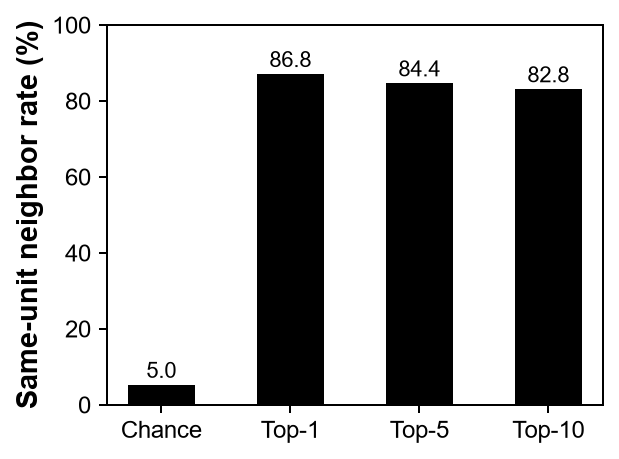

In [33]:
# ============================================================
# FIGURE 2 — GRAPH 1
# Hidden replicate signal
# ============================================================

labels = [
    "Chance",
    "Top-1",
    "Top-5",
    "Top-10"
]

values = [
    chance_same_group,
    top1_same_group,
    top5_group_purity,
    top10_group_purity
]

x = np.arange(len(labels))

fig, ax = plt.subplots(
    figsize=(4, 3)
)

bars = ax.bar(
    x,
    values,
    width=0.5,
    color="black",          # 막대 색 검정
    edgecolor="black",
    linewidth=0.9
)

ax.set_xticks(x)
ax.set_xticklabels(labels)

ax.set_ylabel(
    "Same-unit neighbor rate (%)"
)

ax.set_ylim(0, 100)
ax.set_yticks(np.arange(0, 101, 20))

# ------------------------------------------------------------
# Numeric labels: 조금 더 낮게
# ------------------------------------------------------------
for bar, value in zip(bars, values):

    ax.text(
        bar.get_x() + bar.get_width() / 2,
        value + 0.8,
        f"{value:.1f}",
        ha="center",
        va="bottom",
        fontsize=10,
        color="black"
    )

# ------------------------------------------------------------
# AUC annotation: 왼쪽 상단
# ------------------------------------------------------------

ax.tick_params(
    direction="out",
    width=0.9
)

for spine in [
    "top",
    "right",
    "bottom",
    "left"
]:
    ax.spines[spine].set_visible(True)
    ax.spines[spine].set_linewidth(0.9)

plt.tight_layout()
plt.show()

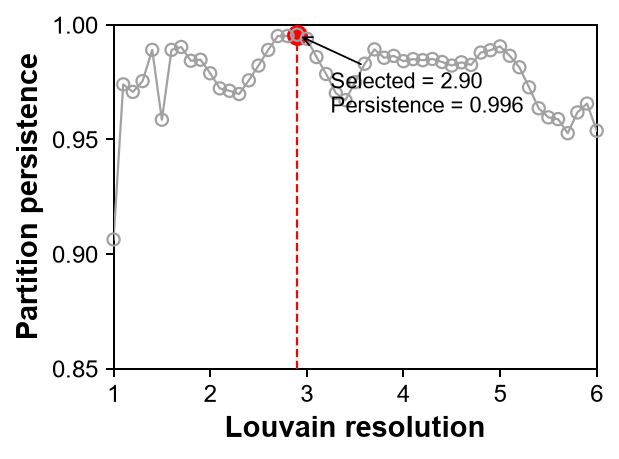

In [34]:
# ============================================================
# FIGURE 2 — GRAPH 2
# Label-free resolution selection by partition persistence
# ============================================================

fig, ax = plt.subplots(
    figsize=(4, 3)
)

# ------------------------------------------------------------
# 1) 선은 먼저 그림
# ------------------------------------------------------------
ax.plot(
    resolution_values,
    persistence_values,
    linewidth=1,
    color="#A1A1A1",
    zorder=2
)

# ------------------------------------------------------------
# 2) 일반 포인트: 채우기 없음
# ------------------------------------------------------------
ax.scatter(
    resolution_values,
    persistence_values,
    s=30,
    facecolors="none",      # 채우기 없음
    edgecolors="#A1A1A1",   # 테두리 색
    linewidths=1.0,
    zorder=5,
    clip_on=False
)

ax.axvline(
    selected_resolution_dev,
    linestyle="--",
    linewidth=1.0,
    color="red",
    zorder=1
)

# ------------------------------------------------------------
# 3) Selected point: 분홍색
# ------------------------------------------------------------
ax.scatter(
    selected_resolution_dev,
    selected_persistence,
    s=70,
    marker="o",
    facecolors="red",
    edgecolors="red",
    linewidths=1.0,
    zorder=3,
    clip_on=False
)

ax.annotate(
    (
        f"Selected = "
        f"{selected_resolution_dev:.2f}\n"
        f"Persistence = "
        f"{selected_persistence:.3f}"
    ),
    xy=(
        selected_resolution_dev,
        selected_persistence
    ),
    xytext=(
        15,
        -35
    ),
    textcoords="offset points",
    fontsize=10,
    zorder=7,
    arrowprops={
        "arrowstyle": "->",
        "linewidth": 0.8,
        "color": "black"
    }
)

ax.set_xlabel(
    "Louvain resolution"
)

ax.set_ylabel(
    "Partition persistence"
)

# x축은 딱 맞게 유지
ax.set_xlim(
    1.0,
    6.0
)

ax.set_xticks(
    np.arange(
        1,
        7,
        1
    )
)

ax.set_ylim(
    0.85,
    1.00
)

ax.set_yticks(
    np.arange(
        0.85,
        1.001,
        0.05
    )
)

ax.tick_params(
    direction="out",
    width=0.9
)

# ------------------------------------------------------------
# spine을 데이터보다 뒤로
# ------------------------------------------------------------
for spine in [
    "top",
    "right",
    "bottom",
    "left"
]:
    ax.spines[spine].set_visible(True)
    ax.spines[spine].set_linewidth(0.9)
    ax.spines[spine].set_zorder(0)

plt.tight_layout()
plt.show()

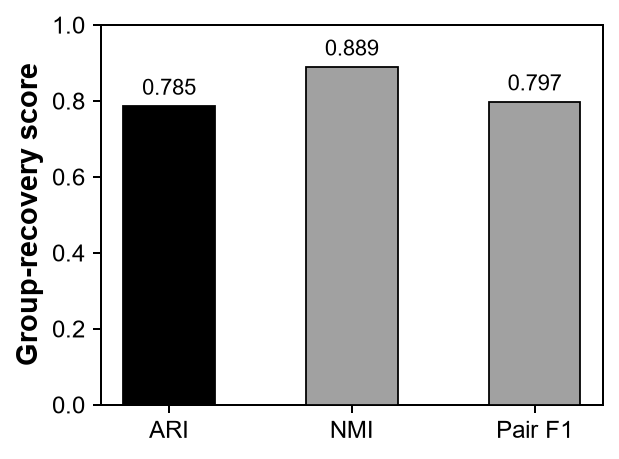

In [35]:
# ============================================================
# FIGURE 2 — GRAPH 3
# Recovery of experimental-unit structure
# ============================================================

labels = [
    "ARI",
    "NMI",
    "Pair F1"
]

values = [
    ari_dev,
    nmi_dev,
    pair_f1_dev
]

x = np.arange(
    len(labels)
)


fig, ax = plt.subplots(
    figsize=(4, 3)
)


# ------------------------------------------------------------
# Bars
# ARI = pink highlight
# NMI / Pair F1 = gray
# ------------------------------------------------------------

bar_colors = [
    "black",
    "#A1A1A1",
    "#A1A1A1"
]


bars = ax.bar(
    x,
    values,
    width=0.5,
    color=bar_colors,
    edgecolor="black",
    linewidth=0.8,
    zorder=3
)


# ------------------------------------------------------------
# X axis
# ------------------------------------------------------------

ax.set_xticks(
    x
)

ax.set_xticklabels(
    labels
)


# ------------------------------------------------------------
# Y axis
# ------------------------------------------------------------

ax.set_ylabel(
    "Group-recovery score"
)

ax.set_ylim(
    0,
    1.0
)

ax.set_yticks(
    np.arange(
        0,
        1.01,
        0.2
    )
)


# ------------------------------------------------------------
# Numeric labels
# ------------------------------------------------------------

for bar, value in zip(
    bars,
    values
):

    ax.text(
        bar.get_x()
        +
        bar.get_width() / 2,

        value + 0.018,

        f"{value:.3f}",

        ha="center",
        va="bottom",

        fontsize=10,
        color="black",
        zorder=5
    )

# ------------------------------------------------------------
# Tick style
# ------------------------------------------------------------

ax.tick_params(
    direction="out",
    width=0.9
)


# ------------------------------------------------------------
# Box spines
# ------------------------------------------------------------

for spine in [
    "top",
    "right",
    "bottom",
    "left"
]:

    ax.spines[spine].set_visible(True)
    ax.spines[spine].set_linewidth(0.9)
    ax.spines[spine].set_zorder(0)


plt.tight_layout()

plt.show()

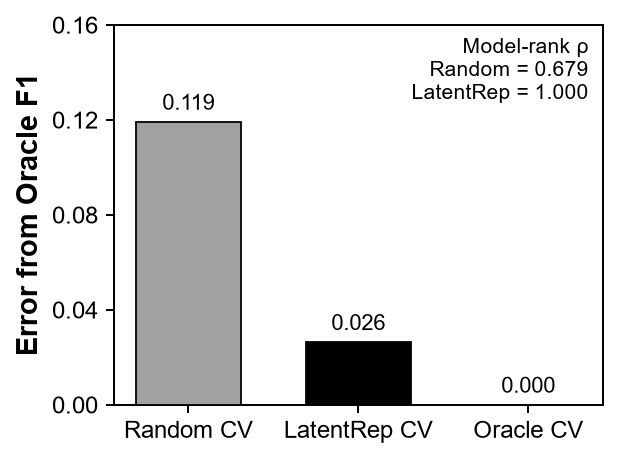

In [71]:
# ============================================================
# FIGURE 2 — GRAPH 4
# Recovery of Oracle validation performance
# ============================================================

labels = [
    "Random CV",
    "LatentRep CV",
    "Oracle CV"
]

values = [
    0.1192,
    0.0264,
    0.0000
]

x = np.arange(
    len(labels)
)


fig, ax = plt.subplots(
    figsize=(4, 3)
)


# ------------------------------------------------------------
# Colors
#
# Random CV    = gray
# LatentRep CV = pink
# Oracle CV    = white
# ------------------------------------------------------------

bar_colors = [
    "#A1A1A1",
    "black",
    "white"
]


bars = ax.bar(
    x,
    values,
    width=0.62,
    color=bar_colors,
    edgecolor="black",
    linewidth=0.8,
    zorder=3
)


# ------------------------------------------------------------
# X axis
# ------------------------------------------------------------

ax.set_xticks(
    x
)

ax.set_xticklabels(
    labels
)


# ------------------------------------------------------------
# Y axis
# ------------------------------------------------------------

ax.set_ylabel(
    "Error from Oracle F1"
)

ax.set_ylim(
    0,
    0.16
)

ax.set_yticks(
    np.arange(
        0,
        0.161,
        0.04
    )
)


# ------------------------------------------------------------
# Numeric labels
# ------------------------------------------------------------

for bar, value in zip(
    bars,
    values
):

    label_y = (
        value + 0.003
        if value > 0
        else 0.003
    )

    ax.text(
        bar.get_x()
        +
        bar.get_width() / 2,

        label_y,

        f"{value:.3f}",

        ha="center",
        va="bottom",

        fontsize=10,
        color="black",
        zorder=5
    )


# ------------------------------------------------------------
# Model-ranking agreement
# ------------------------------------------------------------

ax.text(
    0.97,
    0.97,

    (
        "Model-rank ρ\n"
        f"Random = {random_rank_dev:.3f}\n"
        f"LatentRep = {latent_rank_dev:.3f}"
    ),

    transform=ax.transAxes,

    ha="right",
    va="top",

    fontsize=9.5
)


# ------------------------------------------------------------
# Tick style
# ------------------------------------------------------------

ax.tick_params(
    direction="out",
    width=0.9
)


# ------------------------------------------------------------
# Box spines
# ------------------------------------------------------------

for spine in [
    "top",
    "right",
    "bottom",
    "left"
]:

    ax.spines[spine].set_visible(True)
    ax.spines[spine].set_linewidth(0.9)
    ax.spines[spine].set_zorder(0)


plt.tight_layout()

plt.show()

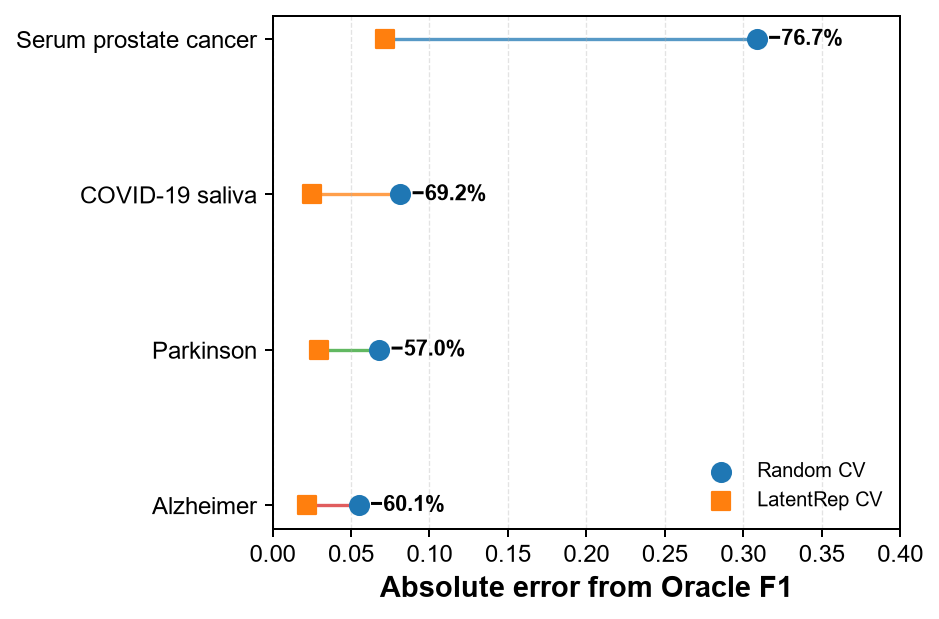

: 

In [ ]:
# ============================================================
# FIGURE 3
# EXTERNAL VALIDATION:
# RANDOM CV vs LATENTREP ORACLE-ESTIMATION ERROR
#
# Each horizontal pair shows:
#
#   Random CV error  ----->  LatentRep error
#
# Error =
# | estimated Macro-F1 - Oracle group-aware Macro-F1 |
#
# External datasets only.
# Development dataset (comfile_stroke) is reserved for Fig. 2.
#
# No file is saved.
# ============================================================


# ------------------------------------------------------------
# 0. Imports
# ------------------------------------------------------------

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


# ============================================================
# 1. Safety check
# ============================================================

if "table2_manuscript" not in globals():

    raise RuntimeError(
        "Run the manuscript-table cell first. "
        "`table2_manuscript` was not found."
    )


# ============================================================
# 2. Figure style
# ============================================================

plt.rcParams.update({

    "font.family":
        "Arial",

    "font.size":
        11,

    "axes.labelsize":
        13,

    "axes.labelweight":
        "bold",

    "xtick.labelsize":
        11,

    "ytick.labelsize":
        11,

    "legend.fontsize":
        9,

    "axes.linewidth":
        0.9,

    "xtick.major.width":
        0.9,

    "ytick.major.width":
        0.9,

    "xtick.direction":
        "out",

    "ytick.direction":
        "out",

    "figure.dpi":
        160
})


# ============================================================
# 3. External benchmark data
# ============================================================

fig3_df = (

    table2_manuscript[
        table2_manuscript[
            "Role"
        ]
        ==
        "External"
    ]

    .copy()

    .reset_index(
        drop=True
    )
)


# ------------------------------------------------------------
# Publication-friendly names
# ------------------------------------------------------------

display_names = {

    "covid19_salvia":
        "COVID-19 saliva",

    "parkinson":
        "Parkinson",

    "serum_prostate_cancer":
        "Serum prostate cancer",

    "alzheimer":
        "Alzheimer"

}


fig3_df[
    "Display_name"
] = (

    fig3_df[
        "Dataset"
    ]

    .map(
        display_names
    )
)


# ============================================================
# 4. Numerical arrays
# ============================================================

random_error = (

    fig3_df[
        "Random CV error"
    ]

    .astype(float)

    .to_numpy()
)


latent_error = (

    fig3_df[
        "LatentRep error"
    ]

    .astype(float)

    .to_numpy()
)


reduction = (

    fig3_df[
        "Error reduction (%)"
    ]

    .astype(float)

    .to_numpy()
)


labels = (

    fig3_df[
        "Display_name"
    ]

    .to_numpy()
)


# ============================================================
# 5. Plot order
#
# Put the largest Random-CV bias at top.
# ============================================================

order = np.argsort(
    random_error
)[::-1]


random_error = random_error[
    order
]


latent_error = latent_error[
    order
]


reduction = reduction[
    order
]


labels = labels[
    order
]


y = np.arange(
    len(labels)
)


# ============================================================
# 6. Create figure
# ============================================================

fig, ax = plt.subplots(

    figsize=(
        6,
        4
    )
)


# ============================================================
# 7. Connecting lines
# ============================================================

for i in range(
    len(labels)
):

    ax.plot(

        [
            latent_error[i],
            random_error[i]
        ],

        [
            y[i],
            y[i]
        ],

        linewidth=1.5,

        alpha=0.75,

        zorder=1
    )


# ============================================================
# 8. Points
# ============================================================

ax.scatter(

    random_error,

    y,

    s=72,

    marker="o",

    label="Random CV",

    zorder=3
)


ax.scatter(

    latent_error,

    y,

    s=72,

    marker="s",

    label="LatentRep CV",

    zorder=3
)


# ============================================================
# 9. Error-reduction annotations
# ============================================================

x_range = (

    max(
        random_error.max(),
        latent_error.max()
    )

    -
    min(
        random_error.min(),
        latent_error.min()
    )
)


annotation_offset = max(

    x_range * 0.025,

    0.004
)


for i in range(
    len(labels)
):


    x_text = (

        max(
            random_error[i],
            latent_error[i]
        )

        +
        annotation_offset
    )


    ax.text(

        x_text,

        y[i],

        f"−{reduction[i]:.1f}%",

        va="center",

        ha="left",

        fontsize=10,

        fontweight="bold"
    )


# ============================================================
# 10. Axes
# ============================================================

ax.set_yticks(
    y
)


ax.set_yticklabels(
    labels
)


ax.set_xlabel(
    "Absolute error from Oracle F1"
)


ax.set_ylabel(
    ""
)


# Largest-error dataset at top
ax.invert_yaxis()


# ============================================================
# X-axis range
# ============================================================

ax.set_xlim(
    0,
    0.40
)


# ============================================================
# 11. Grid
# ============================================================

ax.grid(

    axis="x",

    linestyle="--",

    linewidth=0.6,

    alpha=0.35,

    zorder=0
)


ax.grid(
    axis="y",
    visible=False
)


# ============================================================
# 12. Complete box spines
# ============================================================

for spine in [

    "top",
    "right",
    "bottom",
    "left"

]:

    ax.spines[
        spine
    ].set_visible(
        True
    )


    ax.spines[
        spine
    ].set_linewidth(
        0.9
    )


# ============================================================
# 13. Legend
# ============================================================

ax.legend(

    loc="lower right",

    frameon=False,

    ncol=1
)


# ============================================================
# 14. Layout
# ============================================================

plt.tight_layout()


plt.show()

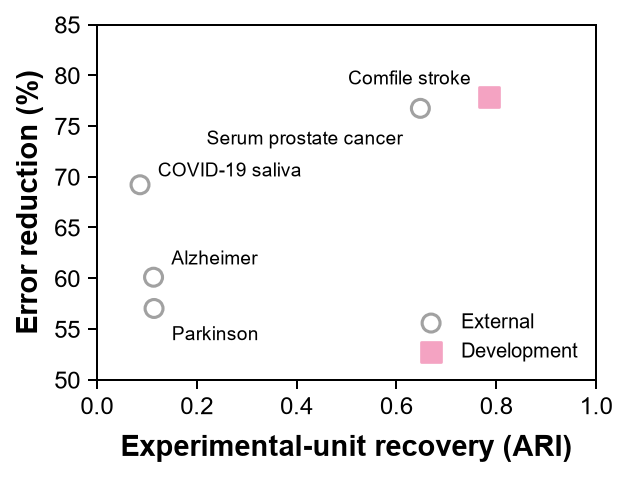

In [38]:
# ============================================================
# FIGURE 4
# GROUP RECOVERY vs VALIDATION UTILITY
#
# x-axis:
#   Experimental-unit recovery (ARI)
#
# y-axis:
#   Error reduction (%)
#
# Development dataset:
#   pink filled square
#
# External datasets:
#   gray hollow circles
#
# No regression line
# No reference line
# No file saving
# ============================================================


# ------------------------------------------------------------
# 0. Imports
# ------------------------------------------------------------

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


# ============================================================
# 1. Data
# ============================================================

fig4_df = pd.DataFrame({

    "Dataset": [
        "comfile_stroke",
        "covid19_salvia",
        "parkinson",
        "serum_prostate_cancer",
        "alzheimer"
    ],

    "Display_name": [
        "Comfile stroke",
        "COVID-19 saliva",
        "Parkinson",
        "Serum prostate cancer",
        "Alzheimer"
    ],

    "Role": [
        "Development",
        "External",
        "External",
        "External",
        "External"
    ],

    "ARI": [
        0.7852,
        0.0864,
        0.1145,
        0.6480,
        0.1135
    ],

    "Error_reduction": [
        77.84,
        69.21,
        57.02,
        76.74,
        60.10
    ]
})


# ============================================================
# 2. Separate development and external datasets
# ============================================================

development_df = (
    fig4_df[
        fig4_df["Role"] == "Development"
    ]
    .copy()
)


external_df = (
    fig4_df[
        fig4_df["Role"] == "External"
    ]
    .copy()
)


# ============================================================
# 3. Figure
#
# Slightly increased size to prevent clipping
# ============================================================

fig, ax = plt.subplots(
    figsize=(4, 3)
)


# ============================================================
# 4. External datasets
# ============================================================

ax.scatter(
    external_df["ARI"],
    external_df["Error_reduction"],

    s=65,

    marker="o",

    facecolors="none",

    edgecolors="#A1A1A1",

    linewidths=1.4,

    label="External",

    zorder=4,

    clip_on=False
)


# ============================================================
# 5. Development dataset
# ============================================================

ax.scatter(
    development_df["ARI"],
    development_df["Error_reduction"],

    s=75,

    marker="s",

    facecolors="#F4A3C2",

    edgecolors="#F4A3C2",

    linewidths=1.2,

    label="Development",

    zorder=5,

    clip_on=False
)


# ============================================================
# 6. Dataset-label positions
# ============================================================

label_offsets = {

    "Comfile stroke":
        (-8, 8),

    "COVID-19 saliva":
        (8, 6),

    "Parkinson":
        (8, -12),

    "Serum prostate cancer":
        (-8, -14),

    "Alzheimer":
        (8, 8)
}


label_alignment = {

    "Comfile stroke":
        "right",

    "COVID-19 saliva":
        "left",

    "Parkinson":
        "left",

    "Serum prostate cancer":
        "right",

    "Alzheimer":
        "left"
}


# ============================================================
# 7. Dataset labels
# ============================================================

for _, row in fig4_df.iterrows():

    name = row["Display_name"]

    dx, dy = label_offsets[
        name
    ]

    ax.annotate(
        name,

        xy=(
            row["ARI"],
            row["Error_reduction"]
        ),

        xytext=(
            dx,
            dy
        ),

        textcoords="offset points",

        ha=label_alignment[
            name
        ],

        va="center",

        fontsize=8.5,

        color="black",

        zorder=6
    )


# ============================================================
# 8. Axis labels
# ============================================================

ax.set_xlabel(
    "Experimental-unit recovery (ARI)",
    labelpad=7
)


ax.set_ylabel(
    "Error reduction (%)",
    labelpad=5
)


# ============================================================
# 9. X-axis
# ============================================================

ax.set_xlim(
    0.0,
    1.00
)

ax.set_xticks(
    np.arange(
        0.0,
        1.01,
        0.20
    )
)


# ============================================================
# 10. Y-axis
# ============================================================

ax.set_ylim(
    50,
    85
)


ax.set_yticks(
    np.arange(
        50,
        86,
        5
    )
)


# ============================================================
# 11. Legend
# ============================================================

ax.legend(
    frameon=False,

    loc="lower right",

    fontsize=9,

    handletextpad=0.5,

    borderaxespad=0.5
)


# ============================================================
# 12. Tick style
# ============================================================

ax.tick_params(
    axis="both",
    direction="out",
    width=0.9,
    length=4
)


# ============================================================
# 13. Complete box spines
# ============================================================

for spine in [
    "top",
    "right",
    "bottom",
    "left"
]:

    ax.spines[
        spine
    ].set_visible(
        True
    )

    ax.spines[
        spine
    ].set_linewidth(
        0.9
    )

    ax.spines[
        spine
    ].set_zorder(
        0
    )


# ============================================================
# 14. Explicit margins
#
# Prevent x-axis title / tick labels from being clipped
# ============================================================

fig.subplots_adjust(
    left=0.19,
    right=0.97,
    bottom=0.22,
    top=0.96
)


# ============================================================
# 15. Show
# ============================================================

plt.show()

In [39]:
# ============================================================
# STEP 26
# FINAL CONFIRMATORY NEGATIVE-CONTROL PERMUTATION TEST
#
# External datasets:
#   1. covid19_salvia
#   2. parkinson
#   3. serum_prostate_cancer
#   4. alzheimer
#
# Controls:
#   A. Global random pseudo-groups
#   B. Class-preserving pseudo-groups
#
# Confirmatory design:
#   - Logistic Regression
#   - 5-fold CV
#   - fixed CV seed
#   - 99 independent pseudo-group permutations
#
# Why one model?
# ------------------------------------------------------------
# The previous pilot/robustness analysis already tested
# 3 representative model families × 5 seeds.
#
# This final permutation layer is intended specifically to
# obtain a higher-resolution empirical null distribution
# without exploding computational cost.
#
# No LatentRep parameter is modified.
# ============================================================


# ------------------------------------------------------------
# 0. Imports
# ------------------------------------------------------------

import numpy as np
import pandas as pd

from raman_data import raman_data

from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

from sklearn.model_selection import (
    StratifiedKFold,
    StratifiedGroupKFold
)

from sklearn.metrics import f1_score
from sklearn.base import clone


# ============================================================
# 1. Safety check
# ============================================================

if "infer_latentrep_groups" not in globals():

    raise RuntimeError(
        "Frozen LatentRep function "
        "`infer_latentrep_groups` was not found."
    )


# ============================================================
# 2. Final permutation settings
# ============================================================

N_PERMUTATIONS = 99

N_SPLITS = 5

CV_SEED = 2026

MODEL_SEED = 42


DATASETS = [

    "covid19_salvia",

    "parkinson",

    "serum_prostate_cancer",

    "alzheimer"

]


# ============================================================
# 3. Model
# ============================================================

def get_confirmatory_model():

    return Pipeline(
        [
            (
                "scaler",
                StandardScaler()
            ),

            (
                "classifier",
                LogisticRegression(
                    max_iter=5000,
                    random_state=MODEL_SEED
                )
            )
        ]
    )


# ============================================================
# 4. Extract true group IDs
# ============================================================

def extract_true_groups_final(
    dataset
):

    # --------------------------------------------------------
    # Preferred direct attribute
    # --------------------------------------------------------

    if hasattr(
        dataset,
        "group_ids"
    ):

        groups = getattr(
            dataset,
            "group_ids"
        )

        if groups is not None:

            return np.asarray(
                groups
            ).astype(str)


    # --------------------------------------------------------
    # Fallback dataframe metadata
    # --------------------------------------------------------

    df = dataset.to_dataframe()


    candidate_columns = [

        "_group_id",

        "group_id",

        "group",

        "sample_id",

        "subject_id"

    ]


    for column in candidate_columns:

        if column in df.columns:

            return (
                df[column]
                .astype(str)
                .to_numpy()
            )


    raise RuntimeError(
        f"True experimental-unit IDs could not be found "
        f"for dataset: {dataset.name}"
    )


# ============================================================
# 5. Random spectrum-level CV
# ============================================================

def final_random_cv(
    model,
    X,
    y
):

    cv = StratifiedKFold(
        n_splits=N_SPLITS,
        shuffle=True,
        random_state=CV_SEED
    )


    pred = np.full(
        len(y),
        -1,
        dtype=int
    )


    for train_idx, test_idx in cv.split(
        X,
        y
    ):

        m = clone(
            model
        )


        m.fit(
            X[train_idx],
            y[train_idx]
        )


        pred[test_idx] = m.predict(
            X[test_idx]
        )


    return f1_score(
        y,
        pred,
        average="macro"
    )


# ============================================================
# 6. Group-aware CV
# ============================================================

def final_group_cv(
    model,
    X,
    y,
    groups
):

    cv = StratifiedGroupKFold(
        n_splits=N_SPLITS,
        shuffle=True,
        random_state=CV_SEED
    )


    pred = np.full(
        len(y),
        -1,
        dtype=int
    )


    for train_idx, test_idx in cv.split(
        X,
        y,
        groups=groups
    ):

        m = clone(
            model
        )


        m.fit(
            X[train_idx],
            y[train_idx]
        )


        pred[test_idx] = m.predict(
            X[test_idx]
        )


    if np.any(
        pred == -1
    ):

        raise RuntimeError(
            "Incomplete OOF predictions."
        )


    return f1_score(
        y,
        pred,
        average="macro"
    )


# ============================================================
# 7. Global random pseudo-groups
#
# Preserves:
#   - number of latent groups
#   - latent group-size distribution
#
# Destroys:
#   - X-derived membership
# ============================================================

def make_global_pseudo_groups_final(
    latent_groups,
    rng
):

    return rng.permutation(
        latent_groups
    )


# ============================================================
# 8. Class-preserving pseudo-groups
#
# Preserves:
#   - group labels within each target class
#   - group-size / class-composition structure
#
# Destroys:
#   - X-derived membership
# ============================================================

def make_class_preserving_pseudo_groups_final(
    latent_groups,
    y,
    rng
):

    pseudo_groups = (
        latent_groups.copy()
    )


    for class_value in np.unique(
        y
    ):

        idx = np.where(
            y == class_value
        )[0]


        pseudo_groups[idx] = rng.permutation(
            latent_groups[idx]
        )


    return pseudo_groups


# ============================================================
# 9. Run one dataset
# ============================================================

def run_final_negative_control(
    dataset_name
):

    print(
        "\n"
        +
        "=" * 110
    )

    print(
        f"FINAL NEGATIVE CONTROL — {dataset_name}"
    )

    print(
        "=" * 110
    )


    # --------------------------------------------------------
    # Load dataset
    # --------------------------------------------------------

    dataset = raman_data(
        dataset_name
    )


    X = np.asarray(
        dataset.spectra
    )


    y = np.asarray(
        dataset.targets,
        dtype=int
    )


    true_groups = (
        extract_true_groups_final(
            dataset
        )
    )


    print(
        "Spectra:",
        X.shape[0]
    )


    print(
        "Features:",
        X.shape[1]
    )


    print(
        "True groups:",
        len(
            np.unique(
                true_groups
            )
        )
    )


    # ========================================================
    # Frozen LatentRep
    #
    # X only
    # ========================================================

    (
        latent_groups,
        selected_resolution,
        selected_row,
        persistence_df

    ) = infer_latentrep_groups(
        X
    )


    latent_groups = np.asarray(
        latent_groups
    ).astype(str)


    print(
        "Latent groups:",
        len(
            np.unique(
                latent_groups
            )
        )
    )


    print(
        "Selected resolution:",
        f"{selected_resolution:.2f}"
    )


    # ========================================================
    # Fixed observed baselines
    # ========================================================

    model = get_confirmatory_model()


    print(
        "\nCalculating fixed Random / LatentRep / Oracle baselines..."
    )


    random_f1 = final_random_cv(
        model=model,
        X=X,
        y=y
    )


    latent_f1 = final_group_cv(
        model=model,
        X=X,
        y=y,
        groups=latent_groups
    )


    oracle_f1 = final_group_cv(
        model=model,
        X=X,
        y=y,
        groups=true_groups
    )


    random_error = abs(
        random_f1
        -
        oracle_f1
    )


    latent_error = abs(
        latent_f1
        -
        oracle_f1
    )


    print(
        f"Random F1      = {random_f1:.4f}"
    )


    print(
        f"LatentRep F1   = {latent_f1:.4f}"
    )


    print(
        f"Oracle F1      = {oracle_f1:.4f}"
    )


    print(
        f"Random error   = {random_error:.4f}"
    )


    print(
        f"LatentRep error= {latent_error:.4f}"
    )


    # ========================================================
    # Permutations
    # ========================================================

    permutation_rows = []


    for permutation_id in range(
        N_PERMUTATIONS
    ):


        if (
            permutation_id == 0
            or
            (permutation_id + 1) % 10 == 0
            or
            permutation_id + 1 == N_PERMUTATIONS
        ):

            print(
                f"{dataset_name}: "
                f"permutation "
                f"{permutation_id + 1}/"
                f"{N_PERMUTATIONS}"
            )


        # ----------------------------------------------------
        # Independent deterministic RNG streams
        # ----------------------------------------------------

        rng_global = np.random.default_rng(
            100000
            +
            permutation_id
        )


        rng_class = np.random.default_rng(
            200000
            +
            permutation_id
        )


        # ----------------------------------------------------
        # A. Global pseudo-group
        # ----------------------------------------------------

        global_groups = (
            make_global_pseudo_groups_final(
                latent_groups,
                rng_global
            )
        )


        global_f1 = final_group_cv(
            model=model,
            X=X,
            y=y,
            groups=global_groups
        )


        global_error = abs(
            global_f1
            -
            oracle_f1
        )


        permutation_rows.append(
            {

                "Dataset":
                    dataset_name,

                "Permutation":
                    permutation_id,

                "Control":
                    "Global pseudo-group",

                "Macro_F1":
                    global_f1,

                "Error":
                    global_error
            }
        )


        # ----------------------------------------------------
        # B. Class-preserving pseudo-group
        # ----------------------------------------------------

        class_groups = (
            make_class_preserving_pseudo_groups_final(
                latent_groups,
                y,
                rng_class
            )
        )


        class_f1 = final_group_cv(
            model=model,
            X=X,
            y=y,
            groups=class_groups
        )


        class_error = abs(
            class_f1
            -
            oracle_f1
        )


        permutation_rows.append(
            {

                "Dataset":
                    dataset_name,

                "Permutation":
                    permutation_id,

                "Control":
                    "Class-preserving pseudo-group",

                "Macro_F1":
                    class_f1,

                "Error":
                    class_error
            }
        )


    permutation_df = pd.DataFrame(
        permutation_rows
    )


    # ========================================================
    # Control distribution summaries
    # ========================================================

    control_summary = (

        permutation_df

        .groupby(
            "Control"
        )

        .agg(

            Mean_error=(
                "Error",
                "mean"
            ),

            SD_error=(
                "Error",
                "std"
            ),

            Median_error=(
                "Error",
                "median"
            ),

            Q025=(
                "Error",
                lambda x:
                    np.quantile(
                        x,
                        0.025
                    )
            ),

            Q975=(
                "Error",
                lambda x:
                    np.quantile(
                        x,
                        0.975
                    )
            ),

            Min_error=(
                "Error",
                "min"
            ),

            Max_error=(
                "Error",
                "max"
            )
        )

        .reset_index()
    )


    # ========================================================
    # Empirical p-values
    #
    # Lower estimation error = better.
    #
    # H0:
    # Random pseudo-grouping can perform at least as well as
    # the observed LatentRep partition.
    # ========================================================

    empirical_rows = []


    for control_name in [

        "Global pseudo-group",

        "Class-preserving pseudo-group"

    ]:


        errors = (

            permutation_df.loc[
                permutation_df[
                    "Control"
                ]
                ==
                control_name,
                "Error"
            ]

            .to_numpy()
        )


        n_as_good_or_better = int(

            np.sum(
                errors
                <=
                latent_error
            )
        )


        empirical_p = (

            1
            +
            n_as_good_or_better

        ) / (

            len(errors)
            +
            1
        )


        empirical_rows.append(
            {

                "Control":
                    control_name,

                "Pseudo_as_good_or_better":
                    n_as_good_or_better,

                "N_permutations":
                    len(errors),

                "Empirical_p":
                    empirical_p
            }
        )


    empirical_df = pd.DataFrame(
        empirical_rows
    )


    # ========================================================
    # Extract compact values
    # ========================================================

    global_mean_error = float(

        control_summary.loc[
            control_summary[
                "Control"
            ]
            ==
            "Global pseudo-group",
            "Mean_error"
        ]

        .iloc[0]
    )


    class_mean_error = float(

        control_summary.loc[
            control_summary[
                "Control"
            ]
            ==
            "Class-preserving pseudo-group",
            "Mean_error"
        ]

        .iloc[0]
    )


    global_p = float(

        empirical_df.loc[
            empirical_df[
                "Control"
            ]
            ==
            "Global pseudo-group",
            "Empirical_p"
        ]

        .iloc[0]
    )


    class_p = float(

        empirical_df.loc[
            empirical_df[
                "Control"
            ]
            ==
            "Class-preserving pseudo-group",
            "Empirical_p"
        ]

        .iloc[0]
    )


    # ========================================================
    # Final result
    # ========================================================

    print(
        "\n"
        +
        "-" * 110
    )


    print(
        f"FINAL SUMMARY — {dataset_name}"
    )


    print(
        "-" * 110
    )


    print(
        f"Random error                    = "
        f"{random_error:.4f}"
    )


    print(
        f"LatentRep error                 = "
        f"{latent_error:.4f}"
    )


    print(
        f"Global pseudo mean error        = "
        f"{global_mean_error:.4f}"
    )


    print(
        f"Class-preserving mean error     = "
        f"{class_mean_error:.4f}"
    )


    print(
        f"Global pseudo empirical p       = "
        f"{global_p:.4f}"
    )


    print(
        f"Class-preserving empirical p    = "
        f"{class_p:.4f}"
    )


    display(
        control_summary.round(
            4
        )
    )


    display(
        empirical_df.round(
            4
        )
    )


    return {

        "dataset":
            dataset_name,

        "X_shape":
            X.shape,

        "true_groups_n":
            len(
                np.unique(
                    true_groups
                )
            ),

        "latent_groups_n":
            len(
                np.unique(
                    latent_groups
                )
            ),

        "selected_resolution":
            float(
                selected_resolution
            ),

        "Random_F1":
            float(
                random_f1
            ),

        "LatentRep_F1":
            float(
                latent_f1
            ),

        "Oracle_F1":
            float(
                oracle_f1
            ),

        "Random_error":
            float(
                random_error
            ),

        "LatentRep_error":
            float(
                latent_error
            ),

        "Global_pseudo_mean_error":
            global_mean_error,

        "Class_pseudo_mean_error":
            class_mean_error,

        "Global_empirical_p":
            global_p,

        "Class_empirical_p":
            class_p,

        "permutation_df":
            permutation_df,

        "control_summary":
            control_summary,

        "empirical_df":
            empirical_df
    }


# ============================================================
# 10. Run all external datasets
# ============================================================

step26_results = {}


for dataset_name in DATASETS:

    result = run_final_negative_control(
        dataset_name
    )


    step26_results[
        dataset_name
    ] = result


# ============================================================
# 11. Combined permutation dataframe
#
# Used later for FINAL Figure 5.
# ============================================================

step26_permutation_df = pd.concat(

    [

        result[
            "permutation_df"
        ]

        for result in step26_results.values()

    ],

    ignore_index=True
)


# ============================================================
# 12. Final compact summary
# ============================================================

step26_summary_rows = []


for dataset_name in DATASETS:


    result = step26_results[
        dataset_name
    ]


    step26_summary_rows.append(
        {

            "Dataset":
                dataset_name,

            "Random_error":
                result[
                    "Random_error"
                ],

            "LatentRep_error":
                result[
                    "LatentRep_error"
                ],

            "Global_pseudo_error":
                result[
                    "Global_pseudo_mean_error"
                ],

            "Class_pseudo_error":
                result[
                    "Class_pseudo_mean_error"
                ],

            "Global_p":
                result[
                    "Global_empirical_p"
                ],

            "Class_p":
                result[
                    "Class_empirical_p"
                ]
        }
    )


step26_summary = pd.DataFrame(
    step26_summary_rows
)


print(
    "\n\n"
    +
    "=" * 120
)

print(
    "STEP 26 FINAL CONFIRMATORY NEGATIVE-CONTROL SUMMARY"
)

print(
    "=" * 120
)


display(
    step26_summary.round(
        4
    )
)


# ============================================================
# 13. Automatic final check
# ============================================================

all_latent_better_global = np.all(

    step26_summary[
        "LatentRep_error"
    ]

    <

    step26_summary[
        "Global_pseudo_error"
    ]
)


all_latent_better_class = np.all(

    step26_summary[
        "LatentRep_error"
    ]

    <

    step26_summary[
        "Class_pseudo_error"
    ]
)


print(
    "\nLatentRep better than Global pseudo "
    "in all datasets:",
    all_latent_better_global
)


print(
    "LatentRep better than Class-preserving pseudo "
    "in all datasets:",
    all_latent_better_class
)


print(
    "\nMinimum possible empirical p with "
    f"{N_PERMUTATIONS} permutations = "
    f"{1 / (N_PERMUTATIONS + 1):.4f}"
)

2026-11-03 10:06:33,779 INFO raman_data:raman_data:67: Loading dataset: covid19_salvia (cache_dir=None)



FINAL NEGATIVE CONTROL — covid19_salvia
Spectra: 2501
Features: 885
True groups: 101

LatentRep graph:
  Nodes      = 2501
  Edges      = 17395
  Components = 2
  Isolates   = 0
Latent groups: 60
Selected resolution: 5.80

Calculating fixed Random / LatentRep / Oracle baselines...
Random F1      = 0.7964
LatentRep F1   = 0.7689
Oracle F1      = 0.7056
Random error   = 0.0907
LatentRep error= 0.0632
covid19_salvia: permutation 1/99
covid19_salvia: permutation 10/99
covid19_salvia: permutation 20/99
covid19_salvia: permutation 30/99
covid19_salvia: permutation 40/99
covid19_salvia: permutation 50/99
covid19_salvia: permutation 60/99
covid19_salvia: permutation 70/99
covid19_salvia: permutation 80/99
covid19_salvia: permutation 90/99
covid19_salvia: permutation 99/99

--------------------------------------------------------------------------------------------------------------
FINAL SUMMARY — covid19_salvia
---------------------------------------------------------------------------------

,Control,Mean_error,SD_error,Median_error,Q025,Q975,Min_error,Max_error
0,Class-preserving pseudo-group,0.0898,0.0024,0.0896,0.0853,0.0940,0.0850,0.0947
1,Global pseudo-group,0.0902,0.0023,0.0903,0.0860,0.0941,0.0832,0.0950


,Control,Pseudo_as_good_or_better,N_permutations,Empirical_p
0,Global pseudo-group,0,99,0.01
1,Class-preserving pseudo-group,0,99,0.01


2026-11-03 10:26:27,143 INFO raman_data:raman_data:67: Loading dataset: parkinson (cache_dir=None)



FINAL NEGATIVE CONTROL — parkinson
Spectra: 1476
Features: 885
True groups: 60

LatentRep graph:
  Nodes      = 1476
  Edges      = 10181
  Components = 2
  Isolates   = 0
Latent groups: 36
Selected resolution: 3.90

Calculating fixed Random / LatentRep / Oracle baselines...
Random F1      = 0.7716
LatentRep F1   = 0.7293
Oracle F1      = 0.6885
Random error   = 0.0832
LatentRep error= 0.0408
parkinson: permutation 1/99
parkinson: permutation 10/99
parkinson: permutation 20/99
parkinson: permutation 30/99
parkinson: permutation 40/99
parkinson: permutation 50/99
parkinson: permutation 60/99
parkinson: permutation 70/99
parkinson: permutation 80/99
parkinson: permutation 90/99
parkinson: permutation 99/99

--------------------------------------------------------------------------------------------------------------
FINAL SUMMARY — parkinson
--------------------------------------------------------------------------------------------------------------
Random error                    = 0.

... (9 outputs left out)

,Control,Pseudo_as_good_or_better,N_permutations,Empirical_p
0,Global pseudo-group,0,99,0.01
1,Class-preserving pseudo-group,0,99,0.01




STEP 26 FINAL CONFIRMATORY NEGATIVE-CONTROL SUMMARY


,Dataset,Random_error,LatentRep_error,Global_pseudo_error,Class_pseudo_error,Global_p,Class_p
0,covid19_salvia,0.0907,0.0632,0.0902,0.0898,0.01,0.01
1,parkinson,0.0832,0.0408,0.0807,0.0808,0.01,0.01
2,serum_prostate_cancer,0.2410,0.0611,0.2405,0.2402,0.01,0.01
3,alzheimer,0.0366,0.0100,0.0373,0.0363,0.01,0.01



LatentRep better than Global pseudo in all datasets: True
LatentRep better than Class-preserving pseudo in all datasets: True

Minimum possible empirical p with 99 permutations = 0.0100


In [40]:
# ============================================================
# STEP 26B
# CORRECT PROSTATE NEGATIVE CONTROL USING THE FROZEN
# LATENTREP PARTITION FROM STEP 18
#
# IMPORTANT:
# ------------------------------------------------------------
# This cell DOES NOT re-run LatentRep inference.
#
# It reuses:
#   step18_result["latent_groups"]
#
# Therefore:
#   - frozen resolution = 6.00
#   - frozen latent groups = 68
#
# Only serum_prostate_cancer is re-evaluated.
#
# The corrected result automatically replaces the prostate
# row inside:
#
#   step26_results
#   step26_permutation_df
#   step26_summary
#
# ============================================================


# ------------------------------------------------------------
# 0. Imports
# ------------------------------------------------------------

import numpy as np
import pandas as pd


# ============================================================
# 1. Safety checks
# ============================================================

required_objects = [

    "step18_result",

    "step26_results",

    "get_confirmatory_model",

    "final_random_cv",

    "final_group_cv",

    "make_global_pseudo_groups_final",

    "make_class_preserving_pseudo_groups_final"

]


missing_objects = [

    name
    for name in required_objects
    if name not in globals()

]


if len(missing_objects) > 0:

    raise RuntimeError(

        "Required objects are missing:\n"
        +
        "\n".join(
            missing_objects
        )
        +
        "\n\nRun the previous LatentRep / Step 18 / Step 26 "
        "cells before this correction cell."
    )


# ============================================================
# 2. Fixed confirmatory settings
# ============================================================

PROSTATE_DATASET_NAME = (
    "serum_prostate_cancer"
)

PROSTATE_N_PERMUTATIONS = 99


# ============================================================
# 3. Load FROZEN data directly from Step 18
#
# NO LatentRep inference is performed here.
# ============================================================

X = np.asarray(
    step18_result[
        "X"
    ]
)


y = np.asarray(
    step18_result[
        "y"
    ],
    dtype=int
)


true_groups = (

    np.asarray(
        step18_result[
            "true_groups"
        ]
    )

    .astype(str)
)


frozen_latent_groups = (

    np.asarray(
        step18_result[
            "latent_groups"
        ]
    )

    .astype(str)
)


frozen_resolution = float(

    step18_result[
        "selected_resolution"
    ]
)


# ============================================================
# 4. Confirm frozen prostate partition
# ============================================================

n_true_groups = len(
    np.unique(
        true_groups
    )
)


n_latent_groups = len(
    np.unique(
        frozen_latent_groups
    )
)


print(
    "\n"
    +
    "=" * 110
)


print(
    "STEP 26B — FROZEN PROSTATE NEGATIVE CONTROL"
)


print(
    "=" * 110
)


print(
    "Dataset:",
    PROSTATE_DATASET_NAME
)


print(
    "Spectra:",
    X.shape[0]
)


print(
    "Features:",
    X.shape[1]
)


print(
    "True groups:",
    n_true_groups
)


print(
    "Frozen latent groups:",
    n_latent_groups
)


print(
    "Frozen selected resolution:",
    f"{frozen_resolution:.2f}"
)


# ------------------------------------------------------------
# Critical frozen-result check
# ------------------------------------------------------------

if not np.isclose(
    frozen_resolution,
    6.00
):

    raise RuntimeError(

        f"Unexpected frozen prostate resolution: "
        f"{frozen_resolution:.2f}\n"
        f"Expected Step 18 frozen value = 6.00."
    )


if n_latent_groups != 68:

    raise RuntimeError(

        f"Unexpected number of frozen latent groups: "
        f"{n_latent_groups}\n"
        f"Expected Step 18 value = 68."
    )


print(
    "\nFrozen Step 18 partition confirmed."
)


print(
    "No LatentRep re-inference will be performed."
)


# ============================================================
# 5. Confirmatory model
# ============================================================

model = get_confirmatory_model()


# ============================================================
# 6. Recalculate fixed baselines
#
# Same model / same CV design as Step 26.
# Only the frozen latent partition differs from the erroneous
# re-inferred prostate partition.
# ============================================================

print(
    "\nCalculating corrected fixed baselines..."
)


random_f1 = final_random_cv(

    model=model,

    X=X,

    y=y
)


latent_f1 = final_group_cv(

    model=model,

    X=X,

    y=y,

    groups=frozen_latent_groups
)


oracle_f1 = final_group_cv(

    model=model,

    X=X,

    y=y,

    groups=true_groups
)


random_error = abs(

    random_f1
    -
    oracle_f1
)


latent_error = abs(

    latent_f1
    -
    oracle_f1
)


print(
    f"\nRandom F1      = "
    f"{random_f1:.4f}"
)


print(
    f"LatentRep F1   = "
    f"{latent_f1:.4f}"
)


print(
    f"Oracle F1      = "
    f"{oracle_f1:.4f}"
)


print(
    f"Random error   = "
    f"{random_error:.4f}"
)


print(
    f"LatentRep error= "
    f"{latent_error:.4f}"
)


# ============================================================
# 7. Run 99 pseudo-group permutations
#
# IMPORTANT:
# pseudo-groups are generated from the FROZEN Step 18
# latent-group membership.
# ============================================================

permutation_rows = []


for permutation_id in range(
    PROSTATE_N_PERMUTATIONS
):


    if (

        permutation_id == 0

        or

        (
            permutation_id + 1
        )
        % 10
        == 0

        or

        permutation_id + 1
        ==
        PROSTATE_N_PERMUTATIONS

    ):

        print(

            f"Frozen prostate: "
            f"permutation "
            f"{permutation_id + 1}/"
            f"{PROSTATE_N_PERMUTATIONS}"
        )


    # ========================================================
    # Independent deterministic RNG streams
    # ========================================================

    rng_global = np.random.default_rng(

        100000
        +
        permutation_id
    )


    rng_class = np.random.default_rng(

        200000
        +
        permutation_id
    )


    # ========================================================
    # A. Global pseudo-groups
    # ========================================================

    global_groups = (

        make_global_pseudo_groups_final(

            frozen_latent_groups,

            rng_global
        )
    )


    global_f1 = final_group_cv(

        model=model,

        X=X,

        y=y,

        groups=global_groups
    )


    global_error = abs(

        global_f1
        -
        oracle_f1
    )


    permutation_rows.append(

        {

            "Dataset":
                PROSTATE_DATASET_NAME,

            "Permutation":
                permutation_id,

            "Control":
                "Global pseudo-group",

            "Macro_F1":
                global_f1,

            "Error":
                global_error
        }
    )


    # ========================================================
    # B. Class-preserving pseudo-groups
    # ========================================================

    class_groups = (

        make_class_preserving_pseudo_groups_final(

            frozen_latent_groups,

            y,

            rng_class
        )
    )


    class_f1 = final_group_cv(

        model=model,

        X=X,

        y=y,

        groups=class_groups
    )


    class_error = abs(

        class_f1
        -
        oracle_f1
    )


    permutation_rows.append(

        {

            "Dataset":
                PROSTATE_DATASET_NAME,

            "Permutation":
                permutation_id,

            "Control":
                "Class-preserving pseudo-group",

            "Macro_F1":
                class_f1,

            "Error":
                class_error
        }
    )


# ============================================================
# 8. Build corrected permutation dataframe
# ============================================================

prostate_frozen_permutation_df = pd.DataFrame(

    permutation_rows
)


# ============================================================
# 9. Distribution summary
# ============================================================

prostate_frozen_control_summary = (

    prostate_frozen_permutation_df

    .groupby(
        "Control"
    )

    .agg(

        Mean_error=(
            "Error",
            "mean"
        ),

        SD_error=(
            "Error",
            "std"
        ),

        Median_error=(
            "Error",
            "median"
        ),

        Q025=(
            "Error",

            lambda x:
                np.quantile(
                    x,
                    0.025
                )
        ),

        Q975=(
            "Error",

            lambda x:
                np.quantile(
                    x,
                    0.975
                )
        ),

        Min_error=(
            "Error",
            "min"
        ),

        Max_error=(
            "Error",
            "max"
        )
    )

    .reset_index()
)


# ============================================================
# 10. Empirical p-values
#
# Lower error = better.
#
# Count how many pseudo-group permutations perform as well as
# or better than the actual frozen LatentRep partition.
# ============================================================

empirical_rows = []


for control_name in [

    "Global pseudo-group",

    "Class-preserving pseudo-group"

]:

    control_errors = (

        prostate_frozen_permutation_df.loc[

            prostate_frozen_permutation_df[
                "Control"
            ]
            ==
            control_name,

            "Error"
        ]

        .to_numpy()
    )


    n_as_good_or_better = int(

        np.sum(

            control_errors

            <=

            latent_error
        )
    )


    empirical_p = (

        1
        +
        n_as_good_or_better

    ) / (

        len(
            control_errors
        )

        +
        1
    )


    empirical_rows.append(

        {

            "Control":
                control_name,

            "Pseudo_as_good_or_better":
                n_as_good_or_better,

            "N_permutations":
                len(
                    control_errors
                ),

            "Empirical_p":
                empirical_p
        }
    )


prostate_frozen_empirical_df = pd.DataFrame(

    empirical_rows
)


# ============================================================
# 11. Extract final corrected values
# ============================================================

global_mean_error = float(

    prostate_frozen_control_summary.loc[

        prostate_frozen_control_summary[
            "Control"
        ]
        ==
        "Global pseudo-group",

        "Mean_error"
    ]

    .iloc[0]
)


class_mean_error = float(

    prostate_frozen_control_summary.loc[

        prostate_frozen_control_summary[
            "Control"
        ]
        ==
        "Class-preserving pseudo-group",

        "Mean_error"
    ]

    .iloc[0]
)


global_p = float(

    prostate_frozen_empirical_df.loc[

        prostate_frozen_empirical_df[
            "Control"
        ]
        ==
        "Global pseudo-group",

        "Empirical_p"
    ]

    .iloc[0]
)


class_p = float(

    prostate_frozen_empirical_df.loc[

        prostate_frozen_empirical_df[
            "Control"
        ]
        ==
        "Class-preserving pseudo-group",

        "Empirical_p"
    ]

    .iloc[0]
)


# ============================================================
# 12. Corrected prostate result dictionary
# ============================================================

prostate_frozen_result = {

    "dataset":
        PROSTATE_DATASET_NAME,

    "X_shape":
        X.shape,

    "true_groups_n":
        n_true_groups,

    "latent_groups_n":
        n_latent_groups,

    "selected_resolution":
        frozen_resolution,

    "Random_F1":
        float(
            random_f1
        ),

    "LatentRep_F1":
        float(
            latent_f1
        ),

    "Oracle_F1":
        float(
            oracle_f1
        ),

    "Random_error":
        float(
            random_error
        ),

    "LatentRep_error":
        float(
            latent_error
        ),

    "Global_pseudo_mean_error":
        global_mean_error,

    "Class_pseudo_mean_error":
        class_mean_error,

    "Global_empirical_p":
        global_p,

    "Class_empirical_p":
        class_p,

    "permutation_df":
        prostate_frozen_permutation_df,

    "control_summary":
        prostate_frozen_control_summary,

    "empirical_df":
        prostate_frozen_empirical_df
}


# ============================================================
# 13. Print corrected prostate summary
# ============================================================

print(
    "\n"
    +
    "=" * 110
)


print(
    "CORRECTED FROZEN PROSTATE RESULT"
)


print(
    "=" * 110
)


print(
    f"Frozen resolution               = "
    f"{frozen_resolution:.2f}"
)


print(
    f"Frozen latent groups            = "
    f"{n_latent_groups}"
)


print(
    f"Random error                    = "
    f"{random_error:.4f}"
)


print(
    f"LatentRep error                 = "
    f"{latent_error:.4f}"
)


print(
    f"Global pseudo mean error        = "
    f"{global_mean_error:.4f}"
)


print(
    f"Class-preserving mean error     = "
    f"{class_mean_error:.4f}"
)


print(
    f"Global pseudo empirical p       = "
    f"{global_p:.4f}"
)


print(
    f"Class-preserving empirical p    = "
    f"{class_p:.4f}"
)


print(
    "\nPseudo-group distributions:"
)


display(

    prostate_frozen_control_summary.round(
        4
    )
)


print(
    "\nEmpirical permutation tests:"
)


display(

    prostate_frozen_empirical_df.round(
        4
    )
)


# ============================================================
# 14. Replace prostate result inside step26_results
# ============================================================

step26_results[
    PROSTATE_DATASET_NAME
] = prostate_frozen_result


# ============================================================
# 15. Rebuild combined Step 26 permutation dataframe
#
# This removes the old re-inferred prostate permutations and
# inserts the corrected frozen prostate permutations.
# ============================================================

step26_permutation_df = pd.concat(

    [

        result[
            "permutation_df"
        ]

        for result
        in step26_results.values()

    ],

    ignore_index=True
)


# ============================================================
# 16. Rebuild corrected Step 26 summary
# ============================================================

dataset_order = [

    "covid19_salvia",

    "parkinson",

    "serum_prostate_cancer",

    "alzheimer"

]


corrected_summary_rows = []


for dataset_name in dataset_order:


    result = step26_results[
        dataset_name
    ]


    corrected_summary_rows.append(

        {

            "Dataset":
                dataset_name,

            "Random_error":
                result[
                    "Random_error"
                ],

            "LatentRep_error":
                result[
                    "LatentRep_error"
                ],

            "Global_pseudo_error":
                result[
                    "Global_pseudo_mean_error"
                ],

            "Class_pseudo_error":
                result[
                    "Class_pseudo_mean_error"
                ],

            "Global_p":
                result[
                    "Global_empirical_p"
                ],

            "Class_p":
                result[
                    "Class_empirical_p"
                ]
        }
    )


step26_summary = pd.DataFrame(

    corrected_summary_rows
)


# ============================================================
# 17. Add error-reduction column for checking
#
# This is confirmatory Logistic Regression only.
# Do NOT mix with the main 7-model Table 2 results.
# ============================================================

step26_summary[
    "Error_reduction_pct"
] = (

    1

    -

    (
        step26_summary[
            "LatentRep_error"
        ]

        /

        step26_summary[
            "Random_error"
        ]
    )

) * 100


# ============================================================
# 18. Final automatic checks
# ============================================================

all_better_than_global = bool(

    np.all(

        step26_summary[
            "LatentRep_error"
        ]

        <

        step26_summary[
            "Global_pseudo_error"
        ]
    )
)


all_better_than_class = bool(

    np.all(

        step26_summary[
            "LatentRep_error"
        ]

        <

        step26_summary[
            "Class_pseudo_error"
        ]
    )
)


all_global_p_minimum = bool(

    np.allclose(

        step26_summary[
            "Global_p"
        ],

        0.01
    )
)


all_class_p_minimum = bool(

    np.allclose(

        step26_summary[
            "Class_p"
        ],

        0.01
    )
)


# ============================================================
# 19. FINAL CORRECTED SUMMARY
# ============================================================

print(
    "\n\n"
    +
    "=" * 120
)


print(
    "CORRECTED STEP 26 SUMMARY"
)


print(
    "=" * 120
)


display(

    step26_summary.round(
        4
    )
)


print(
    "\nFinal checks"
)


print(
    "LatentRep better than Global pseudo "
    "in all datasets:",
    all_better_than_global
)


print(
    "LatentRep better than Class-preserving pseudo "
    "in all datasets:",
    all_better_than_class
)


print(
    "Global pseudo p = 0.010 in all datasets:",
    all_global_p_minimum
)


print(
    "Class-preserving p = 0.010 in all datasets:",
    all_class_p_minimum
)


print(
    "\nProstate frozen resolution:",
    f"{step26_results[PROSTATE_DATASET_NAME]['selected_resolution']:.2f}"
)


print(
    "Prostate frozen latent groups:",
    step26_results[
        PROSTATE_DATASET_NAME
    ][
        "latent_groups_n"
    ]
)


print(
    "\nMinimum possible empirical p with "
    f"{PROSTATE_N_PERMUTATIONS} permutations = "
    f"{1 / (PROSTATE_N_PERMUTATIONS + 1):.4f}"
)


STEP 26B — FROZEN PROSTATE NEGATIVE CONTROL
Dataset: serum_prostate_cancer
Spectra: 12601
Features: 725
True groups: 62
Frozen latent groups: 68
Frozen selected resolution: 6.00

Frozen Step 18 partition confirmed.
No LatentRep re-inference will be performed.

Calculating corrected fixed baselines...

Random F1      = 0.8363
LatentRep F1   = 0.6347
Oracle F1      = 0.5953
Random error   = 0.2410
LatentRep error= 0.0394
Frozen prostate: permutation 1/99
Frozen prostate: permutation 10/99
Frozen prostate: permutation 20/99
Frozen prostate: permutation 30/99
Frozen prostate: permutation 40/99
Frozen prostate: permutation 50/99
Frozen prostate: permutation 60/99
Frozen prostate: permutation 70/99
Frozen prostate: permutation 80/99
Frozen prostate: permutation 90/99
Frozen prostate: permutation 99/99

CORRECTED FROZEN PROSTATE RESULT
Frozen resolution               = 6.00
Frozen latent groups            = 68
Random error                    = 0.2410
LatentRep error                 = 0.0394


,Control,Mean_error,SD_error,Median_error,Q025,Q975,Min_error,Max_error
0,Class-preserving pseudo-group,0.2403,0.0019,0.2402,0.2364,0.2434,0.2341,0.2449
1,Global pseudo-group,0.2404,0.0019,0.2405,0.2366,0.2434,0.2332,0.2444



Empirical permutation tests:


,Control,Pseudo_as_good_or_better,N_permutations,Empirical_p
0,Global pseudo-group,0,99,0.01
1,Class-preserving pseudo-group,0,99,0.01




CORRECTED STEP 26 SUMMARY


,Dataset,Random_error,LatentRep_error,Global_pseudo_error,Class_pseudo_error,Global_p,Class_p,Error_reduction_pct
0,covid19_salvia,0.0907,0.0632,0.0902,0.0898,0.01,0.01,30.3407
1,parkinson,0.0832,0.0408,0.0807,0.0808,0.01,0.01,50.9423
2,serum_prostate_cancer,0.2410,0.0394,0.2404,0.2403,0.01,0.01,83.6423
3,alzheimer,0.0366,0.0100,0.0373,0.0363,0.01,0.01,72.7488



Final checks
LatentRep better than Global pseudo in all datasets: True
LatentRep better than Class-preserving pseudo in all datasets: True
Global pseudo p = 0.010 in all datasets: True
Class-preserving p = 0.010 in all datasets: True

Prostate frozen resolution: 6.00
Prostate frozen latent groups: 68

Minimum possible empirical p with 99 permutations = 0.0100


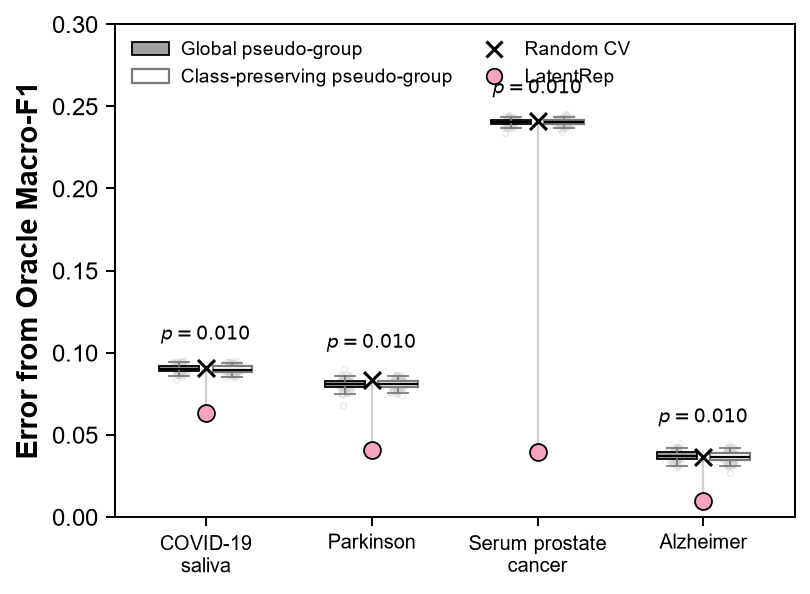

In [46]:
# ============================================================
# FIGURE 5
# NEGATIVE-CONTROL PERMUTATION ANALYSIS
#
# Uses FINAL corrected Step 26 objects:
#
#   step26_permutation_df
#   step26_summary
#
# Display:
#   Global pseudo-group distribution        = gray box
#   Class-preserving pseudo-group           = white box
#   Random CV error                         = black X
#   LatentRep error                         = pink circle
#
# 99 permutations per pseudo-group control.
# ============================================================


# ------------------------------------------------------------
# 0. Imports
# ------------------------------------------------------------

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from matplotlib.lines import Line2D
from matplotlib.patches import Patch


# ============================================================
# 1. Safety checks
# ============================================================

required_objects = [
    "step26_permutation_df",
    "step26_summary"
]


missing = [
    obj
    for obj in required_objects
    if obj not in globals()
]


if missing:

    raise RuntimeError(
        "Missing required objects:\n"
        +
        "\n".join(missing)
    )


# ============================================================
# 2. Dataset order and display names
# ============================================================

dataset_order = [
    "covid19_salvia",
    "parkinson",
    "serum_prostate_cancer",
    "alzheimer"
]


display_names = {
    "covid19_salvia":
        "COVID-19\nsaliva",

    "parkinson":
        "Parkinson",

    "serum_prostate_cancer":
        "Serum prostate\ncancer",

    "alzheimer":
        "Alzheimer"
}


# ============================================================
# 3. Ensure summary order
# ============================================================

summary_plot = (

    step26_summary

    .set_index(
        "Dataset"
    )

    .loc[
        dataset_order
    ]

    .reset_index()
)


# ============================================================
# 4. Colors
# ============================================================

GRAY_DARK = "#7A7A7A"

GRAY = "#A1A1A1"

GRAY_LIGHT = "#D0D0D0"

PINK = "#F4A3C2"


# ============================================================
# 5. Figure
# ============================================================

fig, ax = plt.subplots(
    figsize=(5, 4)
)


# ============================================================
# 6. X positions
# ============================================================

x = np.arange(
    len(
        dataset_order
    )
)


offset = 0.16


global_positions = (
    x
    -
    offset
)


class_positions = (
    x
    +
    offset
)


# ============================================================
# 7. Collect permutation distributions
# ============================================================

global_data = []

class_data = []


for dataset_name in dataset_order:


    global_errors = (

        step26_permutation_df.loc[

            (
                step26_permutation_df[
                    "Dataset"
                ]
                ==
                dataset_name
            )

            &

            (
                step26_permutation_df[
                    "Control"
                ]
                ==
                "Global pseudo-group"
            ),

            "Error"
        ]

        .to_numpy()
    )


    class_errors = (

        step26_permutation_df.loc[

            (
                step26_permutation_df[
                    "Dataset"
                ]
                ==
                dataset_name
            )

            &

            (
                step26_permutation_df[
                    "Control"
                ]
                ==
                "Class-preserving pseudo-group"
            ),

            "Error"
        ]

        .to_numpy()
    )


    global_data.append(
        global_errors
    )


    class_data.append(
        class_errors
    )


# ============================================================
# 8. Global pseudo-group boxplots
# ============================================================

bp_global = ax.boxplot(

    global_data,

    positions=global_positions,

    widths=0.24,

    patch_artist=True,

    showfliers=False,

    whis=(2.5, 97.5),

    medianprops=dict(
        color="black",
        linewidth=1.0
    ),

    boxprops=dict(
        facecolor=GRAY,
        edgecolor="black",
        linewidth=0.8
    ),

    whiskerprops=dict(
        color=GRAY_DARK,
        linewidth=0.8
    ),

    capprops=dict(
        color=GRAY_DARK,
        linewidth=0.8
    ),

    zorder=2
)


# ============================================================
# 9. Class-preserving pseudo-group boxplots
# ============================================================

bp_class = ax.boxplot(

    class_data,

    positions=class_positions,

    widths=0.24,

    patch_artist=True,

    showfliers=False,

    whis=(2.5, 97.5),

    medianprops=dict(
        color="black",
        linewidth=1.0
    ),

    boxprops=dict(
        facecolor="white",
        edgecolor=GRAY_DARK,
        linewidth=1.0
    ),

    whiskerprops=dict(
        color=GRAY_DARK,
        linewidth=0.8
    ),

    capprops=dict(
        color=GRAY_DARK,
        linewidth=0.8
    ),

    zorder=2
)


# ============================================================
# 10. Add faint individual permutation points
#
# Small horizontal jitter is deterministic.
# ============================================================

rng = np.random.default_rng(
    2026
)


for i, dataset_name in enumerate(
    dataset_order
):


    g = global_data[i]

    c = class_data[i]


    jitter_g = rng.normal(
        0,
        0.018,
        size=len(g)
    )


    jitter_c = rng.normal(
        0,
        0.018,
        size=len(c)
    )


    ax.scatter(

        np.full(
            len(g),
            global_positions[i]
        )
        +
        jitter_g,

        g,

        s=7,

        facecolors="none",

        edgecolors=GRAY_LIGHT,

        linewidths=0.45,

        alpha=0.55,

        zorder=1
    )


    ax.scatter(

        np.full(
            len(c),
            class_positions[i]
        )
        +
        jitter_c,

        c,

        s=7,

        facecolors="none",

        edgecolors=GRAY_LIGHT,

        linewidths=0.45,

        alpha=0.55,

        zorder=1
    )


# ============================================================
# 11. Random CV errors
# ============================================================

ax.scatter(

    x,

    summary_plot[
        "Random_error"
    ],

    marker="x",

    s=58,

    color="black",

    linewidths=1.4,

    label="Random CV",

    zorder=5
)


# ============================================================
# 12. LatentRep errors
# ============================================================

ax.scatter(

    x,

    summary_plot[
        "LatentRep_error"
    ],

    marker="o",

    s=58,

    facecolors=PINK,

    edgecolors="black",

    linewidths=0.8,

    label="LatentRep",

    zorder=6
)


# ============================================================
# 13. Optional connector
#
# Connect Random and LatentRep within each dataset.
# ============================================================

for i in range(
    len(
        dataset_order
    )
):

    ax.plot(

        [
            x[i],
            x[i]
        ],

        [
            summary_plot.loc[
                i,
                "LatentRep_error"
            ],

            summary_plot.loc[
                i,
                "Random_error"
            ]
        ],

        color=GRAY_LIGHT,

        linewidth=1.0,

        zorder=0
    )


# ============================================================
# 14. Empirical p-value annotation
#
# All controls:
# p = 0.010
# ============================================================

for i in range(
    len(
        dataset_order
    )
):

    max_control = max(

        np.max(
            global_data[i]
        ),

        np.max(
            class_data[i]
        ),

        summary_plot.loc[
            i,
            "Random_error"
        ]
    )


    ax.text(

        x[i],

        max_control
        +
        0.010,

        r"$p=0.010$",

        ha="center",

        va="bottom",

        fontsize=8.5
    )


# ============================================================
# 15. X axis
# ============================================================

ax.set_xticks(
    x
)


ax.set_xticklabels(

    [
        display_names[
            name
        ]

        for name
        in dataset_order
    ],

    fontsize=9
)


# ============================================================
# 16. Y axis
# ============================================================

ax.set_ylabel(
    "Error from Oracle Macro-F1"
)


ax.set_ylim(
    0,
    0.30
)


ax.set_yticks(

    np.arange(
        0,
        0.301,
        0.05
    )
)


# ============================================================
# 17. Legend
# ============================================================

legend_handles = [

    Patch(
        facecolor=GRAY,
        edgecolor="black",
        linewidth=0.8,
        label="Global pseudo-group"
    ),

    Patch(
        facecolor="white",
        edgecolor=GRAY_DARK,
        linewidth=1.0,
        label="Class-preserving pseudo-group"
    ),

    Line2D(
        [0],
        [0],

        marker="x",

        color="black",

        linestyle="None",

        markersize=7,

        markeredgewidth=1.4,

        label="Random CV"
    ),

    Line2D(
        [0],
        [0],

        marker="o",

        color="black",

        markerfacecolor=PINK,

        linestyle="None",

        markersize=7,

        markeredgewidth=0.8,

        label="LatentRep"
    )
]


ax.legend(

    handles=legend_handles,

    frameon=False,

    fontsize=8.5,

    ncol=2,

    loc="upper left",

    handletextpad=0.6,

    columnspacing=1.2
)


# ============================================================
# 18. Tick style
# ============================================================

ax.tick_params(

    axis="both",

    direction="out",

    width=0.9,

    length=4
)


# ============================================================
# 19. Complete box spines
# ============================================================

for spine in [

    "top",
    "right",
    "bottom",
    "left"

]:

    ax.spines[
        spine
    ].set_visible(
        True
    )

    ax.spines[
        spine
    ].set_linewidth(
        0.9
    )

    ax.spines[
        spine
    ].set_zorder(
        0
    )


# ============================================================
# 20. Margins
# ============================================================

ax.set_xlim(
    -0.55,
    len(
        dataset_order
    )
    -
    0.45
)


fig.subplots_adjust(

    left=0.13,

    right=0.98,

    bottom=0.20,

    top=0.97
)


# ============================================================
# 21. Show
# ============================================================

plt.show()

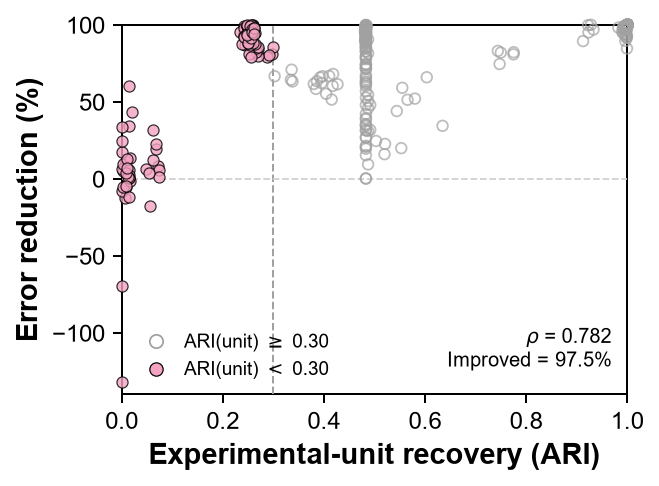

Scenarios: 405
Spearman rho = 0.7821
p = 8.189e-85
Improved = 97.53%
Low-unit-ARI scenarios: 104


In [52]:
# ============================================================
# FIGURE 6 — GRAPH 1
# EXPERIMENTAL-UNIT RECOVERY vs VALIDATION CORRECTION
#
# All 405 Monte Carlo scenarios
#
# Gray:
#   ARI(unit) >= 0.30
#
# Pink:
#   ARI(unit) < 0.30
#
# Updated:
#   - Legend = lower left
#   - Y-axis maximum = exactly 100
#   - Points remain above axis spines
# ============================================================

import numpy as np
import matplotlib.pyplot as plt

from scipy.stats import spearmanr
from matplotlib.lines import Line2D


# ============================================================
# 1. Safety check
# ============================================================

if "grid_results" not in globals():

    raise RuntimeError(
        "grid_results was not found. "
        "Please run Step 22 first."
    )


# ============================================================
# 2. Data
# ============================================================

plot_df = grid_results.copy()


x = plot_df[
    "ARI_vs_unit"
].to_numpy()


y = plot_df[
    "Error_reduction_percent"
].to_numpy()


low_mask = (
    x < 0.30
)


high_mask = (
    ~low_mask
)


# ============================================================
# 3. Statistics
# ============================================================

rho, p_value = spearmanr(
    x,
    y
)


improvement_rate = (

    np.mean(
        plot_df[
            "LatentRep_error"
        ]
        <
        plot_df[
            "Random_error"
        ]
    )

    * 100
)


# ============================================================
# 4. Figure
# ============================================================

fig, ax = plt.subplots(
    figsize=(4, 3)
)


# ============================================================
# 5. Reference lines
# ============================================================

ax.axvline(
    0.30,
    color="#A1A1A1",
    linestyle="--",
    linewidth=0.9,
    zorder=1
)


ax.axhline(
    0,
    color="#D0D0D0",
    linestyle="--",
    linewidth=0.8,
    zorder=1
)


# ============================================================
# 6. ARI(unit) >= 0.30
# ============================================================

ax.scatter(
    x[
        high_mask
    ],
    y[
        high_mask
    ],

    s=23,

    marker="o",

    facecolors="none",

    edgecolors="#A1A1A1",

    linewidths=0.8,

    alpha=0.70,

    zorder=5,

    clip_on=False
)


# ============================================================
# 7. ARI(unit) < 0.30
# ============================================================

ax.scatter(
    x[
        low_mask
    ],
    y[
        low_mask
    ],

    s=25,

    marker="o",

    facecolors="#F4A3C2",

    edgecolors="black",

    linewidths=0.55,

    alpha=0.80,

    zorder=6,

    clip_on=False
)


# ============================================================
# 8. Legend
# ============================================================

legend_handles = [

    Line2D(
        [0],
        [0],

        marker="o",

        linestyle="None",

        markerfacecolor="none",

        markeredgecolor="#A1A1A1",

        markeredgewidth=0.8,

        markersize=6,

        label=r"ARI(unit) $\geq$ 0.30"
    ),

    Line2D(
        [0],
        [0],

        marker="o",

        linestyle="None",

        markerfacecolor="#F4A3C2",

        markeredgecolor="black",

        markeredgewidth=0.55,

        markersize=6,

        label=r"ARI(unit) $<$ 0.30"
    )
]


ax.legend(
    handles=legend_handles,

    frameon=False,

    loc="lower left",

    fontsize=8.5,

    handletextpad=0.5,

    borderaxespad=0.4
)


# ============================================================
# 9. Statistical annotation
# ============================================================

ax.text(
    0.97,
    0.06,

    (
        rf"$\rho$ = {rho:.3f}"
        "\n"
        f"Improved = {improvement_rate:.1f}%"
    ),

    transform=ax.transAxes,

    ha="right",

    va="bottom",

    fontsize=9,

    zorder=7
)


# ============================================================
# 10. Axis labels
# ============================================================

ax.set_xlabel(
    "Experimental-unit recovery (ARI)",
    fontweight="bold"
)


ax.set_ylabel(
    "Error reduction (%)",
    fontweight="bold"
)


# ============================================================
# 11. X axis
# ============================================================

ax.set_xlim(
    0,
    1.0
)


ax.set_xticks(
    np.arange(
        0,
        1.01,
        0.20
    )
)


# ============================================================
# 12. Y axis
#
# Upper limit fixed EXACTLY at 100.
# ============================================================

observed_min = np.nanmin(
    y
)


y_min = min(
    -10,

    np.floor(
        observed_min / 10
    )
    * 10
)


ax.set_ylim(
    y_min,
    100
)


# Make sure the final tick is exactly 100
if y_min <= -100:

    ax.set_yticks(
        np.arange(
            -100,
            101,
            50
        )
    )

else:

    ax.set_yticks(
        np.arange(
            0,
            101,
            25
        )
    )


# ============================================================
# 13. Tick style
# ============================================================

ax.tick_params(
    axis="both",

    direction="out",

    width=0.9,

    length=4
)


# ============================================================
# 14. Complete box
# ============================================================

for spine in [
    "top",
    "right",
    "bottom",
    "left"
]:

    ax.spines[
        spine
    ].set_visible(
        True
    )

    ax.spines[
        spine
    ].set_linewidth(
        0.9
    )

    ax.spines[
        spine
    ].set_zorder(
        0
    )


# ============================================================
# 15. Axis below data
# ============================================================

ax.set_axisbelow(
    True
)


# ============================================================
# 16. Layout
# ============================================================

fig.subplots_adjust(
    left=0.18,
    right=0.97,
    bottom=0.19,
    top=0.96
)


# ============================================================
# 17. Show
# ============================================================

plt.show()


# ============================================================
# 18. Check
# ============================================================

print(
    "Scenarios:",
    len(plot_df)
)

print(
    f"Spearman rho = {rho:.4f}"
)

print(
    f"p = {p_value:.3e}"
)

print(
    f"Improved = {improvement_rate:.2f}%"
)

print(
    "Low-unit-ARI scenarios:",
    np.sum(low_mask)
)

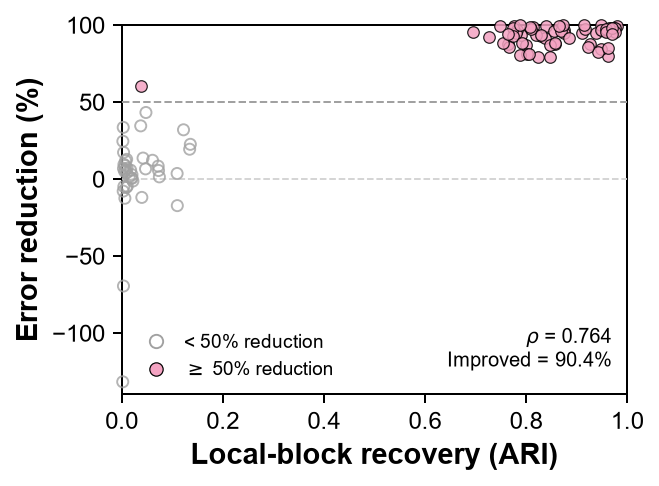

Low-unit-ARI scenarios: 104
Spearman rho = 0.7637
p = 4.198e-21
Improved = 90.38%
>=50% reduction = 62.50%


In [53]:
# ============================================================
# FIGURE 6 — GRAPH 2
# LOCAL BLOCK RECOVERY UNDER POOR UNIT RECOVERY
#
# Subset:
#   ARI(unit) < 0.30
#
# Gray hollow:
#   < 50% error reduction
#
# Pink:
#   >= 50% error reduction
#
# Updated:
#   - Legend = lower left
#   - Y-axis maximum = exactly 100
#   - Points remain above axis spines
# ============================================================

import numpy as np
import matplotlib.pyplot as plt

from scipy.stats import spearmanr
from matplotlib.lines import Line2D


# ============================================================
# 1. Safety check
# ============================================================

if "grid_results" not in globals():

    raise RuntimeError(
        "grid_results was not found. "
        "Please run Step 22 first."
    )


# ============================================================
# 2. Select low-unit-ARI scenarios
# ============================================================

low_ari_df_fig6 = (

    grid_results[
        grid_results[
            "ARI_vs_unit"
        ]
        <
        0.30
    ]

    .copy()
)


# ============================================================
# 3. X and Y
# ============================================================

x = low_ari_df_fig6[
    "ARI_vs_block"
].to_numpy()


y = low_ari_df_fig6[
    "Error_reduction_percent"
].to_numpy()


# ============================================================
# 4. Strong correction definition
# ============================================================

strong_mask = (
    y >= 50
)


other_mask = (
    ~strong_mask
)


# ============================================================
# 5. Statistics
# ============================================================

rho, p_value = spearmanr(
    x,
    y
)


improved_rate = (

    np.mean(
        low_ari_df_fig6[
            "LatentRep_error"
        ]
        <
        low_ari_df_fig6[
            "Random_error"
        ]
    )

    * 100
)


strong_rate = (

    np.mean(
        strong_mask
    )

    * 100
)


# ============================================================
# 6. Figure
# ============================================================

fig, ax = plt.subplots(
    figsize=(4, 3)
)


# ============================================================
# 7. Reference lines
# ============================================================

ax.axhline(
    50,

    color="#A1A1A1",

    linestyle="--",

    linewidth=0.9,

    zorder=1
)


ax.axhline(
    0,

    color="#D0D0D0",

    linestyle="--",

    linewidth=0.8,

    zorder=1
)


# ============================================================
# 8. < 50% reduction
# ============================================================

ax.scatter(
    x[
        other_mask
    ],

    y[
        other_mask
    ],

    s=25,

    marker="o",

    facecolors="none",

    edgecolors="#A1A1A1",

    linewidths=0.85,

    alpha=0.80,

    zorder=5,

    clip_on=False
)


# ============================================================
# 9. >= 50% reduction
# ============================================================

ax.scatter(
    x[
        strong_mask
    ],

    y[
        strong_mask
    ],

    s=27,

    marker="o",

    facecolors="#F4A3C2",

    edgecolors="black",

    linewidths=0.55,

    alpha=0.85,

    zorder=6,

    clip_on=False
)


# ============================================================
# 10. Legend
# ============================================================

legend_handles = [

    Line2D(
        [0],
        [0],

        marker="o",

        linestyle="None",

        markerfacecolor="none",

        markeredgecolor="#A1A1A1",

        markeredgewidth=0.85,

        markersize=6,

        label="< 50% reduction"
    ),

    Line2D(
        [0],
        [0],

        marker="o",

        linestyle="None",

        markerfacecolor="#F4A3C2",

        markeredgecolor="black",

        markeredgewidth=0.55,

        markersize=6,

        label=r"$\geq$ 50% reduction"
    )
]


ax.legend(
    handles=legend_handles,

    frameon=False,

    loc="lower left",

    fontsize=8.5,

    handletextpad=0.5,

    borderaxespad=0.4
)


# ============================================================
# 11. Statistical annotation
# ============================================================

ax.text(
    0.97,
    0.06,

    (
        rf"$\rho$ = {rho:.3f}"
        "\n"
        f"Improved = {improved_rate:.1f}%"
    ),

    transform=ax.transAxes,

    ha="right",

    va="bottom",

    fontsize=9,

    zorder=7
)


# ============================================================
# 12. Axis labels
# ============================================================

ax.set_xlabel(
    "Local-block recovery (ARI)",
    fontweight="bold"
)


ax.set_ylabel(
    "Error reduction (%)",
    fontweight="bold"
)


# ============================================================
# 13. X axis
# ============================================================

ax.set_xlim(
    0,
    1.0
)


ax.set_xticks(
    np.arange(
        0,
        1.01,
        0.20
    )
)


# ============================================================
# 14. Y axis
#
# Upper limit fixed EXACTLY at 100.
# ============================================================

observed_min = np.nanmin(
    y
)


y_min = min(
    -10,

    np.floor(
        observed_min / 10
    )
    * 10
)


ax.set_ylim(
    y_min,
    100
)


# Final y tick exactly at 100
if y_min <= -100:

    ax.set_yticks(
        np.arange(
            -100,
            101,
            50
        )
    )

else:

    ax.set_yticks(
        np.arange(
            0,
            101,
            25
        )
    )


# ============================================================
# 15. Tick style
# ============================================================

ax.tick_params(
    axis="both",

    direction="out",

    width=0.9,

    length=4
)


# ============================================================
# 16. Complete box
# ============================================================

for spine in [
    "top",
    "right",
    "bottom",
    "left"
]:

    ax.spines[
        spine
    ].set_visible(
        True
    )

    ax.spines[
        spine
    ].set_linewidth(
        0.9
    )

    ax.spines[
        spine
    ].set_zorder(
        0
    )


# ============================================================
# 17. Axis below data
# ============================================================

ax.set_axisbelow(
    True
)


# ============================================================
# 18. Layout
# ============================================================

fig.subplots_adjust(
    left=0.18,
    right=0.97,
    bottom=0.19,
    top=0.96
)


# ============================================================
# 19. Show
# ============================================================

plt.show()


# ============================================================
# 20. Check
# ============================================================

print(
    "Low-unit-ARI scenarios:",
    len(
        low_ari_df_fig6
    )
)


print(
    f"Spearman rho = {rho:.4f}"
)


print(
    f"p = {p_value:.3e}"
)


print(
    f"Improved = {improved_rate:.2f}%"
)


print(
    f">=50% reduction = {strong_rate:.2f}%"
)

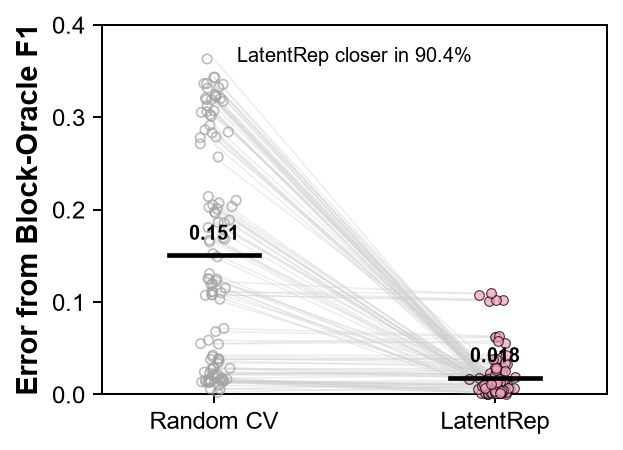

Low-unit-ARI scenarios: 104
Mean Random -> Block Oracle error = 0.1508
Mean LatentRep -> Block Oracle error = 0.0183
LatentRep closer = 90.38%


In [65]:
# ============================================================
# FIGURE 6 — GRAPH 3
# PROXIMITY TO LOCAL BLOCK ORACLE
#
# Subset:
#   ARI(unit) < 0.30
#
# IMPORTANT:
#   Same figure size AND same axes margins as Fig. 6-1 / 6-2
#
#   figsize = (4, 3)
#   left   = 0.18
#   right  = 0.97
#   bottom = 0.19
#   top    = 0.96
#
# Therefore, the plotting box has the same physical size
# as Graphs 1 and 2.
# ============================================================


# ------------------------------------------------------------
# 0. Imports
# ------------------------------------------------------------

import numpy as np
import matplotlib.pyplot as plt


# ============================================================
# 1. Safety check
# ============================================================

if "grid_results" not in globals():

    raise RuntimeError(
        "grid_results was not found. "
        "Please run Step 22 first."
    )


# ============================================================
# 2. Select low-unit-ARI scenarios
# ============================================================

paired_df = (

    grid_results[
        grid_results[
            "ARI_vs_unit"
        ]
        <
        0.30
    ]

    .copy()
)


# ============================================================
# 3. Error from Block Oracle
# ============================================================

paired_df[
    "Random_to_BlockOracle_error"
] = np.abs(

    paired_df[
        "Random_F1"
    ]

    -

    paired_df[
        "Block_Oracle_F1"
    ]
)


paired_df[
    "Latent_to_BlockOracle_error"
] = np.abs(

    paired_df[
        "LatentRep_F1"
    ]

    -

    paired_df[
        "Block_Oracle_F1"
    ]
)


random_error = paired_df[
    "Random_to_BlockOracle_error"
].to_numpy()


latent_error = paired_df[
    "Latent_to_BlockOracle_error"
].to_numpy()


# ============================================================
# 4. Summary statistics
# ============================================================

mean_random = np.mean(
    random_error
)


mean_latent = np.mean(
    latent_error
)


closer_fraction = (

    np.mean(
        latent_error
        <
        random_error
    )

    *
    100
)


# ============================================================
# 5. Figure
#
# EXACTLY SAME AS FIG. 6-1 / 6-2
# ============================================================

fig, ax = plt.subplots(
    figsize=(4, 3)
)


# ============================================================
# 6. Paired lines
# ============================================================

for r_err, l_err in zip(
    random_error,
    latent_error
):

    ax.plot(

        [0, 1],

        [
            r_err,
            l_err
        ],

        color="#D0D0D0",

        linewidth=0.65,

        alpha=0.40,

        zorder=1
    )


# ============================================================
# 7. Jitter
# ============================================================

rng = np.random.default_rng(
    2026
)


jitter_random = rng.normal(
    0,
    0.025,
    len(
        random_error
    )
)


jitter_latent = rng.normal(
    0,
    0.025,
    len(
        latent_error
    )
)


# ============================================================
# 8. Random CV
# ============================================================

ax.scatter(

    np.zeros(
        len(
            random_error
        )
    )
    +
    jitter_random,

    random_error,

    s=18,

    marker="o",

    facecolors="none",

    edgecolors="#A1A1A1",

    linewidths=0.75,

    alpha=0.70,

    zorder=4,

    clip_on=False
)


# ============================================================
# 9. LatentRep
# ============================================================

ax.scatter(

    np.ones(
        len(
            latent_error
        )
    )
    +
    jitter_latent,

    latent_error,

    s=19,

    marker="o",

    facecolors="#F4A3C2",

    edgecolors="black",

    linewidths=0.50,

    alpha=0.75,

    zorder=5,

    clip_on=False
)


# ============================================================
# 10. Mean horizontal bars
# ============================================================

ax.plot(

    [
        -0.16,
        0.16
    ],

    [
        mean_random,
        mean_random
    ],

    color="black",

    linewidth=2.1,

    zorder=6
)


ax.plot(

    [
        0.84,
        1.16
    ],

    [
        mean_latent,
        mean_latent
    ],

    color="black",

    linewidth=2.1,

    zorder=6
)


# ============================================================
# 11. Mean labels
# ============================================================

ax.text(

    0,

    mean_random
    +
    0.012,

    f"{mean_random:.3f}",

    ha="center",

    va="bottom",

    fontsize=9,

    fontweight="bold",

    zorder=7
)


ax.text(

    1,

    mean_latent
    +
    0.012,

    f"{mean_latent:.3f}",

    ha="center",

    va="bottom",

    fontsize=9,

    fontweight="bold",

    zorder=7
)


# ============================================================
# 12. Main annotation
# ============================================================

ax.text(

    0.50,

    0.94,

    f"LatentRep closer in {closer_fraction:.1f}%",

    transform=ax.transAxes,

    ha="center",

    va="top",

    fontsize=9,

    zorder=7
)


# ============================================================
# 13. X axis
# ============================================================

ax.set_xlim(
    -0.40,
    1.40
)


ax.set_xticks(
    [0, 1]
)


ax.set_xticklabels(
    [
        "Random CV",
        "LatentRep"
    ]
)


# ============================================================
# 14. Y axis
#
# Short label allows identical margins to Fig. 6-1 / 6-2
# ============================================================

ax.set_ylabel(
    "Error from Block-Oracle F1",
    fontweight="bold"
)


ax.set_ylim(
    0,
    0.40
)


ax.set_yticks(
    np.arange(
        0,
        0.401,
        0.10
    )
)


# ============================================================
# 15. Tick style
# ============================================================

ax.tick_params(

    axis="both",

    direction="out",

    width=0.9,

    length=4
)


# ============================================================
# 16. Complete box
# ============================================================

for spine in [

    "top",
    "right",
    "bottom",
    "left"

]:

    ax.spines[
        spine
    ].set_visible(
        True
    )

    ax.spines[
        spine
    ].set_linewidth(
        0.9
    )

    ax.spines[
        spine
    ].set_zorder(
        0
    )


# ============================================================
# 17. Axis below data
# ============================================================

ax.set_axisbelow(
    True
)


# ============================================================
# 18. Layout
#
# EXACTLY SAME AS FIG. 6-1 / 6-2
# ============================================================

fig.subplots_adjust(

    left=0.18,

    right=0.97,

    bottom=0.19,

    top=0.96
)


# ============================================================
# 19. Show
# ============================================================

plt.show()


# ============================================================
# 20. Check
# ============================================================

print(
    "Low-unit-ARI scenarios:",
    len(
        paired_df
    )
)


print(
    f"Mean Random -> Block Oracle error = "
    f"{mean_random:.4f}"
)


print(
    f"Mean LatentRep -> Block Oracle error = "
    f"{mean_latent:.4f}"
)


print(
    f"LatentRep closer = "
    f"{closer_fraction:.2f}%"
)

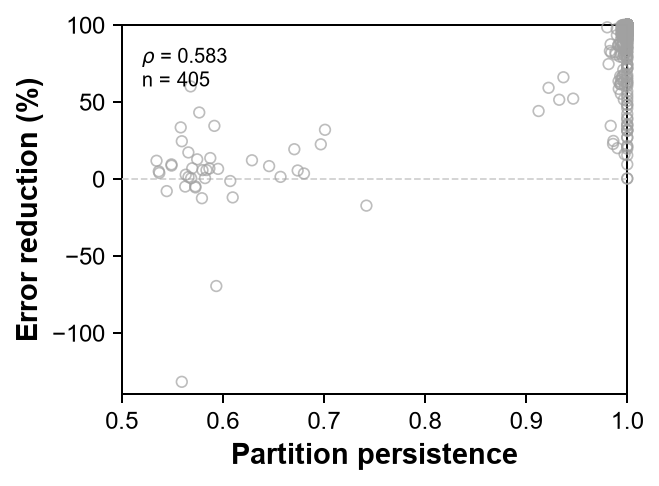

Scenarios: 405
Persistence vs error reduction rho = 0.5831
p = 2.931e-38


In [66]:
# ============================================================
# SUPPLEMENTARY FIGURE S1 — GRAPH 1
# PARTITION PERSISTENCE vs VALIDATION CORRECTION
#
# All 405 Monte Carlo scenarios
#
# x:
#   Partition persistence
#
# y:
#   Error reduction (%)
#
# Main message:
#   Higher persistence is associated with greater validation
#   correction, supporting persistence as a candidate
#   metadata-free internal diagnostic.
#
# IMPORTANT:
#   This does NOT define a universal persistence threshold.
# ============================================================


# ------------------------------------------------------------
# 0. Imports
# ------------------------------------------------------------

import numpy as np
import matplotlib.pyplot as plt

from scipy.stats import spearmanr


# ============================================================
# 1. Safety check
# ============================================================

if "grid_results" not in globals():

    raise RuntimeError(
        "grid_results was not found. "
        "Please run Step 22 first."
    )


# ============================================================
# 2. Data
# ============================================================

s1_df = grid_results.copy()


x = s1_df[
    "Persistence"
].to_numpy()


y = s1_df[
    "Error_reduction_percent"
].to_numpy()


# ============================================================
# 3. Statistics
# ============================================================

rho, p_value = spearmanr(
    x,
    y
)


# ============================================================
# 4. Figure
# ============================================================

fig, ax = plt.subplots(
    figsize=(4, 3)
)


# ============================================================
# 5. Zero correction reference
# ============================================================

ax.axhline(
    0,

    color="#D0D0D0",

    linestyle="--",

    linewidth=0.8,

    zorder=1
)


# ============================================================
# 6. Scatter
# ============================================================

ax.scatter(

    x,
    y,

    s=23,

    marker="o",

    facecolors="none",

    edgecolors="#A1A1A1",

    linewidths=0.75,

    alpha=0.70,

    zorder=5,

    clip_on=False
)


# ============================================================
# 7. Statistics annotation
# ============================================================

ax.text(

    0.04,

    0.94,

    (
        rf"$\rho$ = {rho:.3f}"
        "\n"
        f"n = {len(s1_df)}"
    ),

    transform=ax.transAxes,

    ha="left",

    va="top",

    fontsize=9,

    zorder=7
)


# ============================================================
# 8. Axis labels
# ============================================================

ax.set_xlabel(
    "Partition persistence",
    fontweight="bold"
)


ax.set_ylabel(
    "Error reduction (%)",
    fontweight="bold"
)


# ============================================================
# 9. X axis
# ============================================================

ax.set_xlim(
    0.50,
    1.00
)


ax.set_xticks(
    np.arange(
        0.50,
        1.01,
        0.10
    )
)


# ============================================================
# 10. Y axis
#
# Upper limit fixed exactly at 100.
# Lower limit determined from observed data.
# ============================================================

observed_min = np.nanmin(
    y
)


y_min = min(

    -10,

    np.floor(
        observed_min / 10
    )
    * 10
)


ax.set_ylim(
    y_min,
    100
)


# ============================================================
# 11. Tick style
# ============================================================

ax.tick_params(
    axis="both",
    direction="out",
    width=0.9,
    length=4
)


# ============================================================
# 12. Complete box
# ============================================================

for spine in [
    "top",
    "right",
    "bottom",
    "left"
]:

    ax.spines[
        spine
    ].set_visible(
        True
    )

    ax.spines[
        spine
    ].set_linewidth(
        0.9
    )

    ax.spines[
        spine
    ].set_zorder(
        0
    )


ax.set_axisbelow(
    True
)


# ============================================================
# 13. Layout
#
# Same geometry as Fig. 6-1 / 6-2
# ============================================================

fig.subplots_adjust(
    left=0.18,
    right=0.97,
    bottom=0.19,
    top=0.96
)


# ============================================================
# 14. Show
# ============================================================

plt.show()


# ============================================================
# 15. Check
# ============================================================

print(
    "Scenarios:",
    len(s1_df)
)


print(
    f"Persistence vs error reduction rho = "
    f"{rho:.4f}"
)


print(
    f"p = {p_value:.3e}"
)

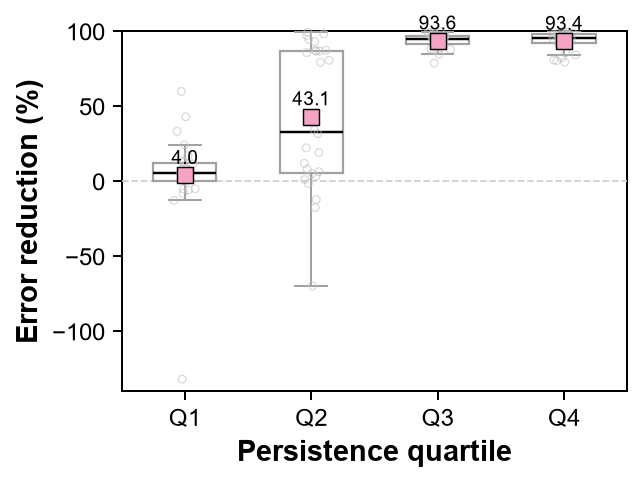

,Quartile,N,Mean_persistence,Mean_error_reduction
0,Q1,26,0.5650,3.9884
1,Q2,26,0.8067,43.1339
2,Q3,26,0.9955,93.6371
3,Q4,26,0.9980,93.3678


In [68]:
# ============================================================
# SUPPLEMENTARY FIGURE S1 — GRAPH 2
# PERSISTENCE QUARTILES UNDER POOR UNIT RECOVERY
#
# Subset:
#   ARI(unit) < 0.30
#
# Box:
#   Distribution of validation error reduction
#
# Pink square:
#   Mean error reduction within each persistence quartile
#
# Main message:
#   Higher persistence is associated with more reliable
#   correction even when experimental-unit recovery is poor.
#
# No universal threshold is implied.
# ============================================================


# ------------------------------------------------------------
# 0. Imports
# ------------------------------------------------------------

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


# ============================================================
# 1. Safety check
# ============================================================

if "grid_results" not in globals():

    raise RuntimeError(
        "grid_results was not found. "
        "Please run Step 22 first."
    )


# ============================================================
# 2. Low-unit-ARI subset
# ============================================================

s1_low = (

    grid_results[
        grid_results[
            "ARI_vs_unit"
        ]
        <
        0.30
    ]

    .copy()

    .reset_index(
        drop=True
    )
)


# ============================================================
# 3. Persistence quartiles
#
# Rank is used only to obtain four equally sized groups
# despite tied persistence values.
#
# Actual persistence values themselves are NOT modified.
# ============================================================

s1_low[
    "Persistence_quartile"
] = pd.qcut(

    s1_low[
        "Persistence"
    ]
    .rank(
        method="first"
    ),

    q=4,

    labels=[
        "Q1",
        "Q2",
        "Q3",
        "Q4"
    ]
)


# ============================================================
# 4. Data by quartile
# ============================================================

quartile_order = [
    "Q1",
    "Q2",
    "Q3",
    "Q4"
]


quartile_data = []


quartile_means = []


persistence_means = []


quartile_n = []


for q in quartile_order:

    subset = s1_low[
        s1_low[
            "Persistence_quartile"
        ]
        ==
        q
    ]


    quartile_data.append(

        subset[
            "Error_reduction_percent"
        ]
        .to_numpy()
    )


    quartile_means.append(

        subset[
            "Error_reduction_percent"
        ]
        .mean()
    )


    persistence_means.append(

        subset[
            "Persistence"
        ]
        .mean()
    )


    quartile_n.append(
        len(subset)
    )


quartile_means = np.asarray(
    quartile_means
)


# ============================================================
# 5. Figure
# ============================================================

fig, ax = plt.subplots(
    figsize=(4, 3)
)


# ============================================================
# 6. Box plots
# ============================================================

bp = ax.boxplot(

    quartile_data,

    positions=[
        1,
        2,
        3,
        4
    ],

    widths=0.50,

    patch_artist=True,

    showfliers=False,

    medianprops=dict(
        color="black",
        linewidth=1.1
    ),

    boxprops=dict(
        facecolor="white",
        edgecolor="#A1A1A1",
        linewidth=1.0
    ),

    whiskerprops=dict(
        color="#A1A1A1",
        linewidth=0.9
    ),

    capprops=dict(
        color="#A1A1A1",
        linewidth=0.9
    ),

    zorder=2
)


# ============================================================
# 7. Individual observations
# ============================================================

rng = np.random.default_rng(
    2026
)


for i, values in enumerate(
    quartile_data,
    start=1
):

    jitter = rng.normal(
        0,
        0.045,
        len(values)
    )


    ax.scatter(

        np.full(
            len(values),
            i
        )
        +
        jitter,

        values,

        s=12,

        facecolors="none",

        edgecolors="#C0C0C0",

        linewidths=0.55,

        alpha=0.60,

        zorder=3,

        clip_on=False
    )


# ============================================================
# 8. Quartile means
#
# Pink squares
# ============================================================

ax.scatter(

    [
        1,
        2,
        3,
        4
    ],

    quartile_means,

    s=48,

    marker="s",

    facecolors="#F4A3C2",

    edgecolors="black",

    linewidths=0.65,

    zorder=6
)


# ============================================================
# 9. Mean labels
# ============================================================

for i, mean_value in enumerate(
    quartile_means,
    start=1
):

    ax.text(

        i,

        mean_value + 5,

        f"{mean_value:.1f}",

        ha="center",

        va="bottom",

        fontsize=8.5,

        zorder=7
    )


# ============================================================
# 10. Zero correction reference
# ============================================================

ax.axhline(

    0,

    color="#D0D0D0",

    linestyle="--",

    linewidth=0.8,

    zorder=1
)


# ============================================================
# 11. X axis
# ============================================================

ax.set_xlim(
    0.50,
    4.50
)


ax.set_xticks(
    [
        1,
        2,
        3,
        4
    ]
)


ax.set_xticklabels(
    [
        "Q1",
        "Q2",
        "Q3",
        "Q4"
    ]
)


ax.set_xlabel(
    "Persistence quartile",
    fontweight="bold"
)


# ============================================================
# 12. Y axis
# ============================================================

ax.set_ylabel(
    "Error reduction (%)",
    fontweight="bold"
)


observed_min = np.nanmin(

    s1_low[
        "Error_reduction_percent"
    ]
)


y_min = min(

    -10,

    np.floor(
        observed_min / 10
    )
    * 10
)


ax.set_ylim(
    y_min,
    100
)


# ============================================================
# 13. Tick style
# ============================================================

ax.tick_params(
    axis="both",
    direction="out",
    width=0.9,
    length=4
)


# ============================================================
# 14. Complete box
# ============================================================

for spine in [
    "top",
    "right",
    "bottom",
    "left"
]:

    ax.spines[
        spine
    ].set_visible(
        True
    )

    ax.spines[
        spine
    ].set_linewidth(
        0.9
    )

    ax.spines[
        spine
    ].set_zorder(
        0
    )


ax.set_axisbelow(
    True
)


# ============================================================
# 15. Layout
# ============================================================

fig.subplots_adjust(
    left=0.18,
    right=0.97,
    bottom=0.21,
    top=0.96
)


# ============================================================
# 16. Show
# ============================================================

plt.show()


# ============================================================
# 17. Check
# ============================================================

summary_s1 = pd.DataFrame(
    {
        "Quartile":
            quartile_order,

        "N":
            quartile_n,

        "Mean_persistence":
            persistence_means,

        "Mean_error_reduction":
            quartile_means
    }
)


display(
    summary_s1.round(
        4
    )
)

In [70]:
# ============================================================
# FINAL MANUSCRIPT TABLES
#
# Generates ALL finalized tables:
#
#   Table 1  — Dataset characteristics
#   Table 2  — Main validation benchmark
#   Table S1 — Group recovery and strict leakage
#   Table S2 — Confirmatory negative controls
#   Table S3 — Monte Carlo simulation summary
#
# IMPORTANT:
#   - Main Table 2 uses the MAIN benchmark
#     (7 models × 10 repeated evaluations).
#
#   - Table S2 uses the separate CONFIRMATORY
#     Logistic Regression + 99-permutation analysis.
#
#   - Prostate values use the frozen LatentRep partition:
#       resolution = 6.00
#       latent groups = 68
# ============================================================


# ------------------------------------------------------------
# 0. Imports
# ------------------------------------------------------------

import numpy as np
import pandas as pd


# ============================================================
# TABLE 1
# Characteristics of datasets and inferred latent structures
# ============================================================

table1 = pd.DataFrame({

    "Dataset": [
        "Comfile stroke",
        "COVID-19 saliva",
        "Parkinson",
        "Serum prostate cancer",
        "Alzheimer"
    ],

    "Role": [
        "Development",
        "External",
        "External",
        "External",
        "External"
    ],

    "Spectra": [
        4020,
        2501,
        1476,
        12601,
        1151
    ],

    "Features": [
        724,
        885,
        885,
        725,
        885
    ],

    "Classes": [
        2,
        3,
        2,
        3,
        2
    ],

    "True units": [
        20,
        101,
        60,
        62,
        46
    ],

    "Median spectra/unit": [
        201,
        25,
        25,
        200,
        25
    ],

    "Latent groups": [
        19,
        60,
        36,
        68,
        31
    ],

    "Selected resolution": [
        2.90,
        5.80,
        3.90,
        6.00,
        3.30
    ],

    "Boundary selection": [
        "No",
        "No",
        "No",
        "Yes (upper)",
        "No"
    ]
})


# ============================================================
# TABLE 2
# Main benchmark:
# recovery of Oracle validation performance
#
# These are the MAIN multi-model benchmark values,
# NOT the Step 26 confirmatory Logistic Regression values.
# ============================================================

table2 = pd.DataFrame({

    "Dataset": [
        "Comfile stroke",
        "COVID-19 saliva",
        "Parkinson",
        "Serum prostate cancer",
        "Alzheimer"
    ],

    "Role": [
        "Development",
        "External",
        "External",
        "External",
        "External"
    ],

    "ARI": [
        0.7852,
        0.0864,
        0.1145,
        0.6480,
        0.1135
    ],

    "Random CV error": [
        0.1192,
        0.0815,
        0.0681,
        0.3087,
        0.0550
    ],

    "LatentRep error": [
        0.0264,
        0.0251,
        0.0293,
        0.0718,
        0.0220
    ],

    "Error reduction (%)": [
        77.84,
        69.21,
        57.02,
        76.74,
        60.10
    ],

    "Random vs Oracle rank rho": [
        0.6786,
        1.0000,
        0.9643,
        0.2500,
        0.9643
    ],

    "LatentRep vs Oracle rank rho": [
        1.0000,
        0.9643,
        0.9643,
        0.8571,
        0.9643
    ]
})


# ============================================================
# TABLE S1
# Group-recovery and strict leakage diagnostics
# ============================================================

tableS1 = pd.DataFrame({

    "Dataset": [
        "Comfile stroke",
        "COVID-19 saliva",
        "Parkinson",
        "Serum prostate cancer",
        "Alzheimer"
    ],

    "Role": [
        "Development",
        "External",
        "External",
        "External",
        "External"
    ],

    "ARI": [
        0.7852,
        0.0864,
        0.1145,
        0.6480,
        0.1135
    ],

    "NMI": [
        0.8885,
        0.4404,
        0.4280,
        0.8294,
        0.4095
    ],

    "Pair F1": [
        0.7967,
        0.0977,
        0.1332,
        0.6537,
        0.1371
    ],

    "Random leakage (%)": [
        100.00,
        100.00,
        100.00,
        100.00,
        100.00
    ],

    "LatentRep leakage (%)": [
        78.00,
        99.00,
        96.61,
        92.06,
        95.66
    ],

    "Oracle leakage (%)": [
        0.00,
        0.00,
        0.00,
        0.00,
        0.00
    ]
})


# ============================================================
# TABLE S2
# Final confirmatory negative-control permutation analysis
#
# Model:
#   Logistic Regression
#
# Permutations:
#   99 Global pseudo-group
#   99 Class-preserving pseudo-group
#
# Lower error = closer to Oracle.
#
# IMPORTANT:
# Prostate uses frozen resolution 6.00 / 68 latent groups.
# ============================================================

tableS2 = pd.DataFrame({

    "Dataset": [
        "COVID-19 saliva",
        "Parkinson",
        "Serum prostate cancer",
        "Alzheimer"
    ],

    "Random CV error": [
        0.0907,
        0.0832,
        0.2410,
        0.0366
    ],

    "LatentRep error": [
        0.0632,
        0.0408,
        0.0394,
        0.0100
    ],

    "Global pseudo-group error": [
        0.0902,
        0.0807,
        0.2404,
        0.0373
    ],

    "Class-preserving pseudo-group error": [
        0.0898,
        0.0808,
        0.2403,
        0.0363
    ],

    "Global empirical p": [
        0.010,
        0.010,
        0.010,
        0.010
    ],

    "Class-preserving empirical p": [
        0.010,
        0.010,
        0.010,
        0.010
    ]
})


# ------------------------------------------------------------
# Add confirmatory error reduction
# ------------------------------------------------------------

tableS2.insert(

    3,

    "Error reduction (%)",

    (
        1
        -
        (
            tableS2[
                "LatentRep error"
            ]
            /
            tableS2[
                "Random CV error"
            ]
        )
    )
    * 100
)


tableS2[
    "Error reduction (%)"
] = tableS2[
    "Error reduction (%)"
].round(2)


# ============================================================
# TABLE S3
# Monte Carlo simulation summary
#
# 405 total scenarios
# 104 low-unit-ARI scenarios
# ============================================================

tableS3 = pd.DataFrame({

    "Scope": [

        "All scenarios",
        "All scenarios",
        "All scenarios",
        "All scenarios",
        "All scenarios",

        "Low unit recovery",
        "Low unit recovery",
        "Low unit recovery",
        "Low unit recovery",
        "Low unit recovery",
        "Low unit recovery",
        "Low unit recovery",
        "Low unit recovery"
    ],

    "Metric": [

        "Number of scenarios",

        "LatentRep improved over Random CV (%)",

        "ARI(unit) vs error reduction, Spearman rho",

        "ARI(block) vs error reduction, Spearman rho",

        "Persistence vs error reduction, Spearman rho",


        "Number of scenarios with ARI(unit) < 0.30",

        "LatentRep improved over Random CV (%)",

        "Scenarios with >=50% error reduction (%)",

        "ARI(unit) vs error reduction, Spearman rho",

        "ARI(block) vs error reduction, Spearman rho",

        "Persistence vs error reduction, Spearman rho",

        "Mean Random-to-Block-Oracle error",

        "Mean LatentRep-to-Block-Oracle error"
    ],

    "Value": [

        405,

        97.53,

        0.7821,

        0.4557,

        0.5831,


        104,

        90.38,

        62.50,

        0.6588,

        0.7637,

        0.7527,

        0.1508,

        0.0183
    ]
})


# ------------------------------------------------------------
# Additional mechanistic result
# ------------------------------------------------------------

tableS3_extra = pd.DataFrame({

    "Scope": [
        "Low unit recovery"
    ],

    "Metric": [
        "LatentRep closer to Block Oracle (%)"
    ],

    "Value": [
        90.38
    ]
})


tableS3 = pd.concat(
    [
        tableS3,
        tableS3_extra
    ],

    ignore_index=True
)


# ============================================================
# FORMATTING / ROUNDING
# ============================================================

# Table 1
table1[
    "Selected resolution"
] = table1[
    "Selected resolution"
].round(2)


# Table 2
for col in [

    "ARI",

    "Random CV error",

    "LatentRep error",

    "Random vs Oracle rank rho",

    "LatentRep vs Oracle rank rho"

]:

    table2[
        col
    ] = table2[
        col
    ].round(4)


table2[
    "Error reduction (%)"
] = table2[
    "Error reduction (%)"
].round(2)


# Table S1
for col in [

    "ARI",

    "NMI",

    "Pair F1"

]:

    tableS1[
        col
    ] = tableS1[
        col
    ].round(4)


# Table S2
for col in [

    "Random CV error",

    "LatentRep error",

    "Global pseudo-group error",

    "Class-preserving pseudo-group error"

]:

    tableS2[
        col
    ] = tableS2[
        col
    ].round(4)


# ============================================================
# DISPLAY ALL TABLES
# ============================================================

print(
    "\n"
    +
    "=" * 140
)

print(
    "TABLE 1"
)

print(
    "Characteristics of the Raman/SERS datasets and "
    "latent dependence structures inferred by LatentRep"
)

print(
    "=" * 140
)

display(
    table1
)


print(
    "\n"
    +
    "=" * 140
)

print(
    "TABLE 2"
)

print(
    "Recovery of Oracle group-aware validation performance "
    "by LatentRep"
)

print(
    "=" * 140
)

display(
    table2
)


print(
    "\n"
    +
    "=" * 140
)

print(
    "TABLE S1"
)

print(
    "Group-recovery and strict experimental-unit leakage "
    "diagnostics"
)

print(
    "=" * 140
)

display(
    tableS1
)


print(
    "\n"
    +
    "=" * 140
)

print(
    "TABLE S2"
)

print(
    "Confirmatory negative-control permutation analysis"
)

print(
    "=" * 140
)

display(
    tableS2
)


print(
    "\n"
    +
    "=" * 140
)

print(
    "TABLE S3"
)

print(
    "Monte Carlo simulation summary"
)

print(
    "=" * 140
)

display(
    tableS3
)


# ============================================================
# FINAL AUDIT
# ============================================================

print(
    "\n"
    +
    "=" * 140
)

print(
    "FINAL TABLE AUDIT"
)

print(
    "=" * 140
)


print(
    f"Table 1 rows  : {len(table1)}"
)

print(
    f"Table 2 rows  : {len(table2)}"
)

print(
    f"Table S1 rows : {len(tableS1)}"
)

print(
    f"Table S2 rows : {len(tableS2)}"
)

print(
    f"Table S3 rows : {len(tableS3)}"
)


print(
    "\nMissing values:"
)


print(
    "Table 1 :",
    int(
        table1
        .isna()
        .sum()
        .sum()
    )
)


print(
    "Table 2 :",
    int(
        table2
        .isna()
        .sum()
        .sum()
    )
)


print(
    "Table S1:",
    int(
        tableS1
        .isna()
        .sum()
        .sum()
    )
)


print(
    "Table S2:",
    int(
        tableS2
        .isna()
        .sum()
        .sum()
    )
)


print(
    "Table S3:",
    int(
        tableS3
        .isna()
        .sum()
        .sum()
    )
)


print(
    "\nFrozen prostate checks:"
)


print(
    "Resolution:",
    table1.loc[
        table1[
            "Dataset"
        ]
        ==
        "Serum prostate cancer",
        "Selected resolution"
    ].iloc[0]
)


print(
    "Latent groups:",
    table1.loc[
        table1[
            "Dataset"
        ]
        ==
        "Serum prostate cancer",
        "Latent groups"
    ].iloc[0]
)


print(
    "Confirmatory LatentRep error:",
    tableS2.loc[
        tableS2[
            "Dataset"
        ]
        ==
        "Serum prostate cancer",
        "LatentRep error"
    ].iloc[0]
)


TABLE 1
Characteristics of the Raman/SERS datasets and latent dependence structures inferred by LatentRep


,Dataset,Role,Spectra,Features,Classes,True units,Median spectra/unit,Latent groups,Selected resolution,Boundary selection
0,Comfile stroke,Development,4020,724,2,20,201,19,2.9,No
1,COVID-19 saliva,External,2501,885,3,101,25,60,5.8,No
2,Parkinson,External,1476,885,2,60,25,36,3.9,No
3,Serum prostate cancer,External,12601,725,3,62,200,68,6.0,Yes (upper)
4,Alzheimer,External,1151,885,2,46,25,31,3.3,No



TABLE 2
Recovery of Oracle group-aware validation performance by LatentRep


,Dataset,Role,ARI,Random CV error,LatentRep error,Error reduction (%),Random vs Oracle rank rho,LatentRep vs Oracle rank rho
0,Comfile stroke,Development,0.7852,0.1192,0.0264,77.84,0.6786,1.0000
1,COVID-19 saliva,External,0.0864,0.0815,0.0251,69.21,1.0000,0.9643
2,Parkinson,External,0.1145,0.0681,0.0293,57.02,0.9643,0.9643
3,Serum prostate cancer,External,0.6480,0.3087,0.0718,76.74,0.2500,0.8571
4,Alzheimer,External,0.1135,0.0550,0.0220,60.10,0.9643,0.9643



TABLE S1
Group-recovery and strict experimental-unit leakage diagnostics


,Dataset,Role,ARI,NMI,Pair F1,Random leakage (%),LatentRep leakage (%),Oracle leakage (%)
0,Comfile stroke,Development,0.7852,0.8885,0.7967,100.0,78.00,0.0
1,COVID-19 saliva,External,0.0864,0.4404,0.0977,100.0,99.00,0.0
2,Parkinson,External,0.1145,0.4280,0.1332,100.0,96.61,0.0
3,Serum prostate cancer,External,0.6480,0.8294,0.6537,100.0,92.06,0.0
4,Alzheimer,External,0.1135,0.4095,0.1371,100.0,95.66,0.0



TABLE S2
Confirmatory negative-control permutation analysis


,Dataset,Random CV error,LatentRep error,Error reduction (%),Global pseudo-group error,Class-preserving pseudo-group error,Global empirical p,Class-preserving empirical p
0,COVID-19 saliva,0.0907,0.0632,30.32,0.0902,0.0898,0.01,0.01
1,Parkinson,0.0832,0.0408,50.96,0.0807,0.0808,0.01,0.01
2,Serum prostate cancer,0.2410,0.0394,83.65,0.2404,0.2403,0.01,0.01
3,Alzheimer,0.0366,0.0100,72.68,0.0373,0.0363,0.01,0.01



TABLE S3
Monte Carlo simulation summary


,Scope,Metric,Value
0,All scenarios,Number of scenarios,405.0000
1,All scenarios,LatentRep improved over Random CV (%),97.5300
2,All scenarios,"ARI(unit) vs error reduction, Spearman rho",0.7821
3,All scenarios,"ARI(block) vs error reduction, Spearman rho",0.4557
4,All scenarios,"Persistence vs error reduction, Spearman rho",0.5831
5,Low unit recovery,Number of scenarios with ARI(unit) < 0.30,104.0000
6,Low unit recovery,LatentRep improved over Random CV (%),90.3800
7,Low unit recovery,Scenarios with >=50% error reduction (%),62.5000
8,Low unit recovery,"ARI(unit) vs error reduction, Spearman rho",0.6588
9,Low unit recovery,"ARI(block) vs error reduction, Spearman rho",0.7637



FINAL TABLE AUDIT
Table 1 rows  : 5
Table 2 rows  : 5
Table S1 rows : 5
Table S2 rows : 4
Table S3 rows : 14

Missing values:
Table 1 : 0
Table 2 : 0
Table S1: 0
Table S2: 0
Table S3: 0

Frozen prostate checks:
Resolution: 6.0
Latent groups: 68
Confirmatory LatentRep error: 0.0394
